In [ ]:

# ============================================================
# Section 1: Environment Inspection and Reproducibility Setup
# ============================================================

import os
import sys
import platform
import random
import importlib.metadata as metadata

import numpy as np
if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Set random seeds for reproducibility
# ------------------------------------------------------------

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 2. Inspect the Python environment
# ------------------------------------------------------------

print("=" * 60)
print("ENVIRONMENT INFORMATION")
print("=" * 60)

print(f"Python version: {sys.version.split()[0]}")
print(f"Operating system: {platform.platform()}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"PyTorch version: {torch.__version__}")

# ------------------------------------------------------------
# 3. Inspect available computational devices
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COMPUTATIONAL DEVICE")
print("=" * 60)

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA availability: True")
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    print(
        "GPU memory (GB): "
        f"{torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f}"
    )
else:
    device = torch.device("cpu")
    print("CUDA availability: False")
    print("The notebook will use the CPU.")

print(f"Selected device: {device}")

# ------------------------------------------------------------
# 4. Record core library versions
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CORE LIBRARY VERSIONS")
print("=" * 60)

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "torch",
    "matplotlib",
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}: {version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: Not installed")

print("\nEnvironment inspection completed.")


ENVIRONMENT INFORMATION
Python version: 3.13.16
Operating system: Linux-6.6.159+-x86_64-with-glibc2.39
NumPy version: 2.4.6
Pandas version: 2.2.3
PyTorch version: 2.11.0+cu130

COMPUTATIONAL DEVICE
CUDA availability: True
GPU name: Tesla T4
GPU memory (GB): 14.56
Selected device: cuda

CORE LIBRARY VERSIONS
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
torch: 2.11.0+cu130
matplotlib: 3.10.0

Environment inspection completed.


In [ ]:

# ============================================================
# Stage 2: Download and Validate the Full CCFD Dataset
# ============================================================

%pip install -q kagglehub

import kagglehub
from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. Download the public Kaggle dataset
# ------------------------------------------------------------

print("Downloading the original Credit Card Fraud Detection dataset...")

dataset_dir = Path(
    kagglehub.dataset_download("mlg-ulb/creditcardfraud")
)

print(f"Dataset directory: {dataset_dir}")

# ------------------------------------------------------------
# 2. Locate the original CSV file
# ------------------------------------------------------------

csv_files = list(dataset_dir.rglob("creditcard.csv"))

if not csv_files:
    raise FileNotFoundError(
        "creditcard.csv was not found in the downloaded dataset."
    )

if len(csv_files) > 1:
    print("Multiple matching files found:")
    for file_path in csv_files:
        print(file_path)
    raise RuntimeError(
        "Multiple candidate files were found. "
        "Select the correct file before proceeding."
    )

full_dataset_path = csv_files[0]
print(f"CSV file: {full_dataset_path}")

# ------------------------------------------------------------
# 3. Load the dataset into a temporary DataFrame
# ------------------------------------------------------------

df_candidate = pd.read_csv(full_dataset_path)

# ------------------------------------------------------------
# 4. Validate the dataset structure and completeness
# ------------------------------------------------------------

EXPECTED_ROWS = 284_807
EXPECTED_COLUMNS = 31

expected_columns = (
    ["Time"]
    + [f"V{i}" for i in range(1, 29)]
    + ["Amount", "Class"]
)

print("\n" + "=" * 65)
print("DATASET VALIDATION")
print("=" * 65)

print(f"Rows found: {len(df_candidate):,}")
print(f"Columns found: {len(df_candidate.columns)}")
print(f"Expected rows: {EXPECTED_ROWS:,}")
print(f"Expected columns: {EXPECTED_COLUMNS}")

if list(df_candidate.columns) != expected_columns:
    raise ValueError(
        "The dataset columns do not match the expected schema."
    )

if df_candidate.shape != (EXPECTED_ROWS, EXPECTED_COLUMNS):
    raise ValueError(
        f"Unexpected dataset shape: {df_candidate.shape}. "
        "The full dataset has not been verified; do not proceed."
    )

# ------------------------------------------------------------
# 5. Replace the working DataFrame only after validation
# ------------------------------------------------------------

df = df_candidate.copy()

print("\nFull dataset validated successfully.")
print(f"Working DataFrame shape: {df.shape}")
print("\nFirst five rows:")
print(df.head().to_string())


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset directory: /kaggle/input/creditcardfraud
CSV file: /kaggle/input/creditcardfraud/creditcard.csv

DATASET VALIDATION
Rows found: 284,807
Columns found: 31
Expected rows: 284,807
Expected columns: 31

Full dataset validated successfully.
Working DataFrame shape: (284807, 31)

First five rows:
   Time        V1        V2        V3        V4        V5        V6        V7        V8        V9       V10       V11       V12       V13       V14       V15       V16       V17       V18       V19       V20       V21       V22       V23       V24       V25       V26       V27       V28  Amount  Class
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599  0.098698  0.363787  0.090794 -0.551600 -0.617801 -0.991390 -0.311169  1.468177 -0.470401  0.207971  0.025791  0.403993  0.251412 -0.018307  0.277838 -0.110474  0.066928  0.128539 -0.189115  0.133558 -0.021053  149.62      0
1   0.0  1.191857  0.266

In [ ]:

# ============================================================
# Stage 3: Data Quality and Temporal Audit
# ============================================================

# ------------------------------------------------------------
# 1. Verify dataset size and expected columns
# ------------------------------------------------------------

print("=" * 65)
print("DATASET STRUCTURE")
print("=" * 65)

print(f"Number of transactions: {len(df):,}")
print(f"Number of features and target columns: {df.shape[1]}")

required_columns = (
    ["Time"]
    + [f"V{i}" for i in range(1, 29)]
    + ["Amount", "Class"]
)

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

print(f"Missing expected columns: {missing_columns}")

# ------------------------------------------------------------
# 2. Check missing values and duplicate records
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DATA QUALITY")
print("=" * 65)

print(f"Total missing values: {df.isna().sum().sum():,}")
print(f"Total duplicated rows: {df.duplicated().sum():,}")

# ------------------------------------------------------------
# 3. Examine target class distribution
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CLASS DISTRIBUTION")
print("=" * 65)

class_counts = df["Class"].value_counts(dropna=False).sort_index()

print(class_counts.to_string())

print("\nClass percentages:")
print(
    (df["Class"].value_counts(normalize=True, dropna=False)
     .sort_index() * 100).round(4).to_string()
)

# ------------------------------------------------------------
# 4. Examine temporal ordering
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TEMPORAL AUDIT")
print("=" * 65)

print(f"Minimum Time: {df['Time'].min()}")
print(f"Maximum Time: {df['Time'].max()}")
print(f"Unique Time values: {df['Time'].nunique():,}")
print(f"Time is non-decreasing: {df['Time'].is_monotonic_increasing}")

time_differences = df["Time"].diff()

print(f"Negative time differences: {(time_differences < 0).sum():,}")
print(f"Zero time differences: {(time_differences == 0).sum():,}")

print("\nFirst five records:")
print(df.head().to_string())

print("\nLast five records:")
print(df.tail().to_string())

# ------------------------------------------------------------
# 5. Summarize audit status without modifying the data
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("AUDIT SUMMARY")
print("=" * 65)

print(f"Dataset currently contains {len(df):,} rows.")
print("No rows have been removed or modified.")
print("Initial audit completed.")


DATASET STRUCTURE
Number of transactions: 284,807
Number of features and target columns: 31
Missing expected columns: []

DATA QUALITY
Total missing values: 0
Total duplicated rows: 1,081

CLASS DISTRIBUTION
Class
0    284315
1       492

Class percentages:
Class
0    99.8273
1     0.1727

TEMPORAL AUDIT
Minimum Time: 0.0
Maximum Time: 172792.0
Unique Time values: 124,592
Time is non-decreasing: True
Negative time differences: 0
Zero time differences: 160,215

First five records:
   Time        V1        V2        V3        V4        V5        V6        V7        V8        V9       V10       V11       V12       V13       V14       V15       V16       V17       V18       V19       V20       V21       V22       V23       V24       V25       V26       V27       V28  Amount  Class
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599  0.098698  0.363787  0.090794 -0.551600 -0.617801 -0.991390 -0.311169  1.468177 -0.470401  0.207971  0.025791  0.403993  0.251412 -0.0

In [ ]:

# ============================================================
# Stage 4: Duplicate Record Analysis
# ============================================================

# ------------------------------------------------------------
# 1. Identify exact duplicate rows
# ------------------------------------------------------------

duplicate_mask = df.duplicated(keep=False)
duplicate_rows = df.loc[duplicate_mask].copy()

print("=" * 65)
print("EXACT DUPLICATE RECORDS")
print("=" * 65)

print(f"Rows involved in duplicate groups: {len(duplicate_rows):,}")
print(f"Extra duplicate rows: {df.duplicated().sum():,}")

# ------------------------------------------------------------
# 2. Examine the target classes among duplicate rows
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CLASS DISTRIBUTION AMONG DUPLICATE ROWS")
print("=" * 65)

if duplicate_rows.empty:
    print("No exact duplicate groups were found.")
else:
    print("Class counts:")
    print(
        duplicate_rows["Class"]
        .value_counts()
        .sort_index()
        .to_string()
    )

    print("\nClass percentages among duplicate rows:")
    print(
        (
            duplicate_rows["Class"]
            .value_counts(normalize=True)
            .sort_index() * 100
        ).round(4).to_string()
    )

# ------------------------------------------------------------
# 3. Examine duplicated rows grouped by target class
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DUPLICATE COUNTS BY CLASS")
print("=" * 65)

for class_label in sorted(df["Class"].dropna().unique()):
    class_df = df.loc[df["Class"] == class_label]

    print(
        f"Class {class_label}: "
        f"{class_df.duplicated().sum():,} extra duplicate rows; "
        f"{class_df.duplicated(keep=False).sum():,} rows "
        "involved in duplicate groups"
    )

# ------------------------------------------------------------
# 4. Inspect representative duplicate records
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REPRESENTATIVE DUPLICATE RECORDS")
print("=" * 65)

if not duplicate_rows.empty:
    print(
        duplicate_rows
        .sort_values(["Time", "Class"])
        .head(10)
        .to_string(index=False)
    )

# ------------------------------------------------------------
# 5. Summarize without modifying the dataset
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DUPLICATE ANALYSIS COMPLETED")
print("=" * 65)

print("The original DataFrame remains unchanged.")


EXACT DUPLICATE RECORDS
Rows involved in duplicate groups: 1,854
Extra duplicate rows: 1,081

CLASS DISTRIBUTION AMONG DUPLICATE ROWS
Class counts:
Class
0    1822
1      32

Class percentages among duplicate rows:
Class
0    98.274
1     1.726

DUPLICATE COUNTS BY CLASS
Class 0: 1,062 extra duplicate rows; 1,822 rows involved in duplicate groups
Class 1: 19 extra duplicate rows; 32 rows involved in duplicate groups

REPRESENTATIVE DUPLICATE RECORDS
 Time        V1       V2       V3       V4        V5       V6        V7        V8        V9       V10       V11      V12       V13       V14       V15       V16       V17       V18       V19       V20      V21       V22       V23       V24      V25       V26       V27      V28  Amount  Class
 26.0 -0.529912 0.873892 1.347247 0.145457  0.414209 0.100223  0.711206  0.176066 -0.286717 -0.484688  0.872490 0.851636 -0.571745  0.100974 -1.519772 -0.284376 -0.310524 -0.404248 -0.823374 -0.290348 0.046949  0.208105 -0.185548  0.001031 0.098816 -0.5

In [ ]:

# ============================================================
# Stage 3.2: Feature Distribution and Statistical Summary
# Purpose: Examine feature ranges, dispersion, and class-wise
# descriptive statistics without modifying the original data.
# ============================================================

import numpy as np
import pandas as pd

# Identify numerical input features, excluding the target label.
feature_columns = [column for column in df.columns if column != "Class"]

# Generate descriptive statistics for all numerical features.
overall_summary = df[feature_columns].describe().T

# Add the number of unique values and missing values per feature.
overall_summary["n_unique"] = df[feature_columns].nunique()
overall_summary["n_missing"] = df[feature_columns].isna().sum()

# Display the overall statistical summary.
print("=" * 80)
print("OVERALL FEATURE SUMMARY")
print("=" * 80)
display(overall_summary.round(4))

# Compare descriptive statistics between legitimate and fraudulent transactions.
class_summary = df.groupby("Class")[feature_columns].agg(
    ["mean", "std", "median", "min", "max"]
)

print("\n" + "=" * 80)
print("CLASS-WISE FEATURE SUMMARY")
print("=" * 80)
display(class_summary.round(4))

# Compare the class-specific medians for each feature.
median_comparison = pd.DataFrame({
    "Legitimate_Median": df.loc[df["Class"] == 0, feature_columns].median(),
    "Fraud_Median": df.loc[df["Class"] == 1, feature_columns].median()
})

median_comparison["Absolute_Median_Difference"] = (
    median_comparison["Fraud_Median"] -
    median_comparison["Legitimate_Median"]
).abs()

median_comparison = median_comparison.sort_values(
    "Absolute_Median_Difference",
    ascending=False
)

print("\n" + "=" * 80)
print("FEATURES RANKED BY ABSOLUTE MEDIAN DIFFERENCE")
print("=" * 80)
display(median_comparison.round(4))

print("\nFeature summary completed. The original DataFrame remains unchanged.")


OVERALL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max,n_unique,n_missing
Time,284807.0,94813.8596,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000,124592,0
V1,284807.0,0.0000,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549,275663,0
V2,284807.0,0.0000,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577,275663,0
V3,284807.0,-0.0000,1.5163,-48.3256,-0.8904,0.1798,1.0272,9.3826,275663,0
V4,284807.0,0.0000,1.4159,-5.6832,-0.8486,-0.0198,0.7433,16.8753,275663,0
V5,284807.0,0.0000,1.3802,-113.7433,-0.6916,-0.0543,0.6119,34.8017,275663,0
V6,284807.0,0.0000,1.3323,-26.1605,-0.7683,-0.2742,0.3986,73.3016,275663,0
V7,284807.0,-0.0000,1.2371,-43.5572,-0.5541,0.0401,0.5704,120.5895,275663,0
V8,284807.0,0.0000,1.1944,-73.2167,-0.2086,0.0224,0.3273,20.0072,275663,0
V9,284807.0,-0.0000,1.0986,-13.4341,-0.6431,-0.0514,0.5971,15.5950,275663,0



CLASS-WISE FEATURE SUMMARY


Time                                            V1          \
             mean         std   median    min       max    mean     std   
Class                                                                     
0      94838.2023  47484.0158  84711.0    0.0  172792.0  0.0083  1.9298   
1      80746.8069  47835.3651  75568.5  406.0  170348.0 -4.7719  6.7837   

                                ...     V28                                    \
       median      min     max  ...    mean     std  median      min      max   
Class                           ...                                             
0      0.0200 -56.4075  2.4549  ... -0.0001  0.3296  0.0112 -15.4301  33.8478   
1     -2.3425 -30.5524  2.1324  ...  0.0757  0.5473  0.1463  -1.8693   1.7794   

         Amount                                  
           mean       std median  min       max  
Class                                            
0       88.2910  250.1051  22.00  0.0  25691.16  
1      122.2113  256.6833   9.25  0.0   2125.87  

[2 rows x 150 columns]


FEATURES RANKED BY ABSOLUTE MEDIAN DIFFERENCE


,Legitimate_Median,Fraud_Median,Absolute_Median_Difference
Time,84711.0000,75568.5000,9142.5000
Amount,22.0000,9.2500,12.7500
V14,0.0519,-6.7297,6.7817
V12,0.1417,-5.5025,5.6442
V3,0.1822,-5.0753,5.2574
V17,-0.0648,-5.3029,5.2381
V10,-0.0919,-4.5788,4.4870
V4,-0.0224,4.1771,4.1996
V11,-0.0349,3.5862,3.6211
V16,0.0674,-3.5498,3.6172



Feature summary completed. The original DataFrame remains unchanged.


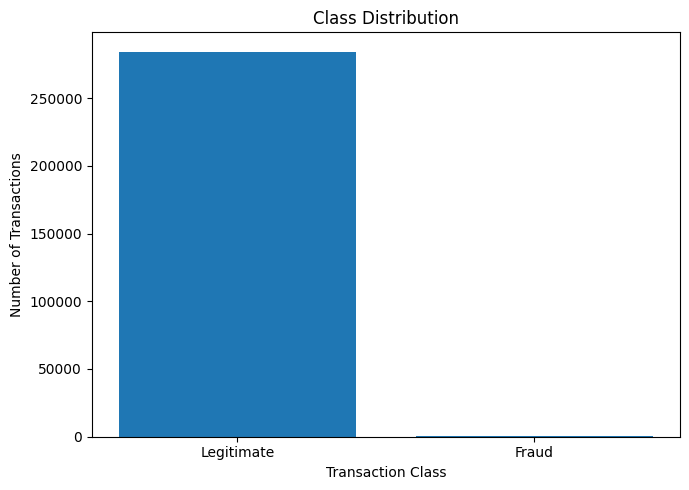

,Count,Percentage
Legitimate,284315,99.8273
Fraud,492,0.1727


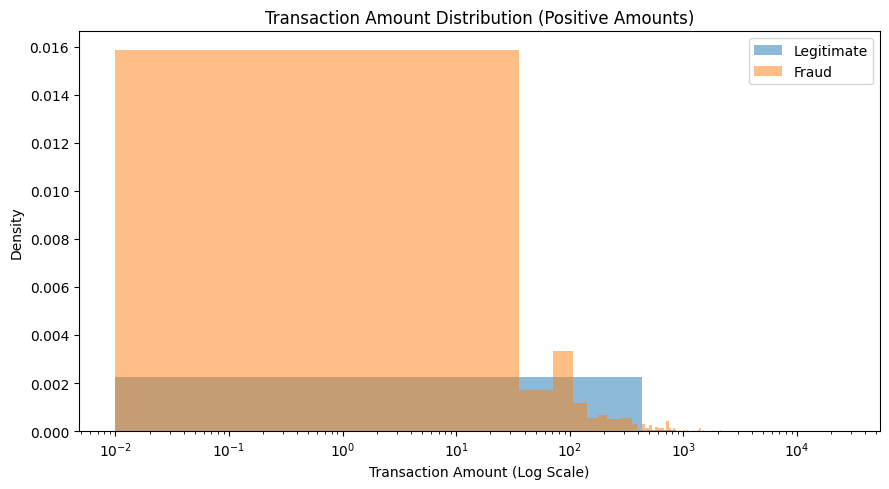

/usr/local/lib/python3.13/dist-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


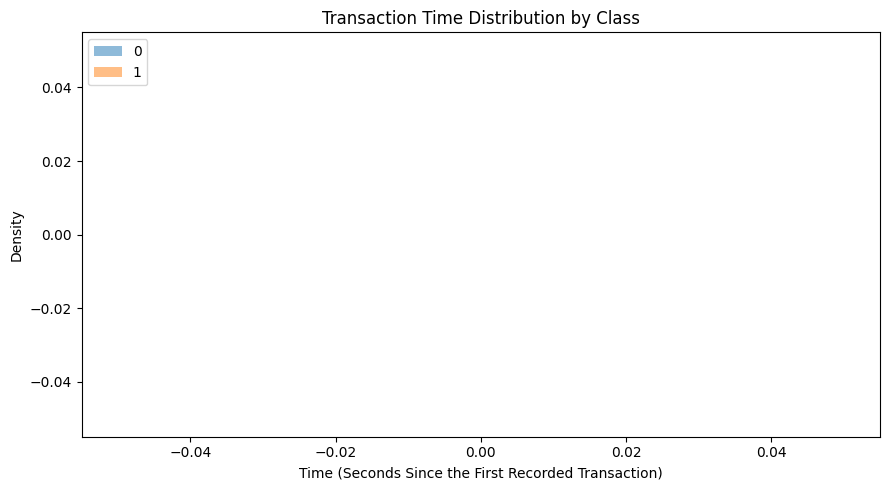

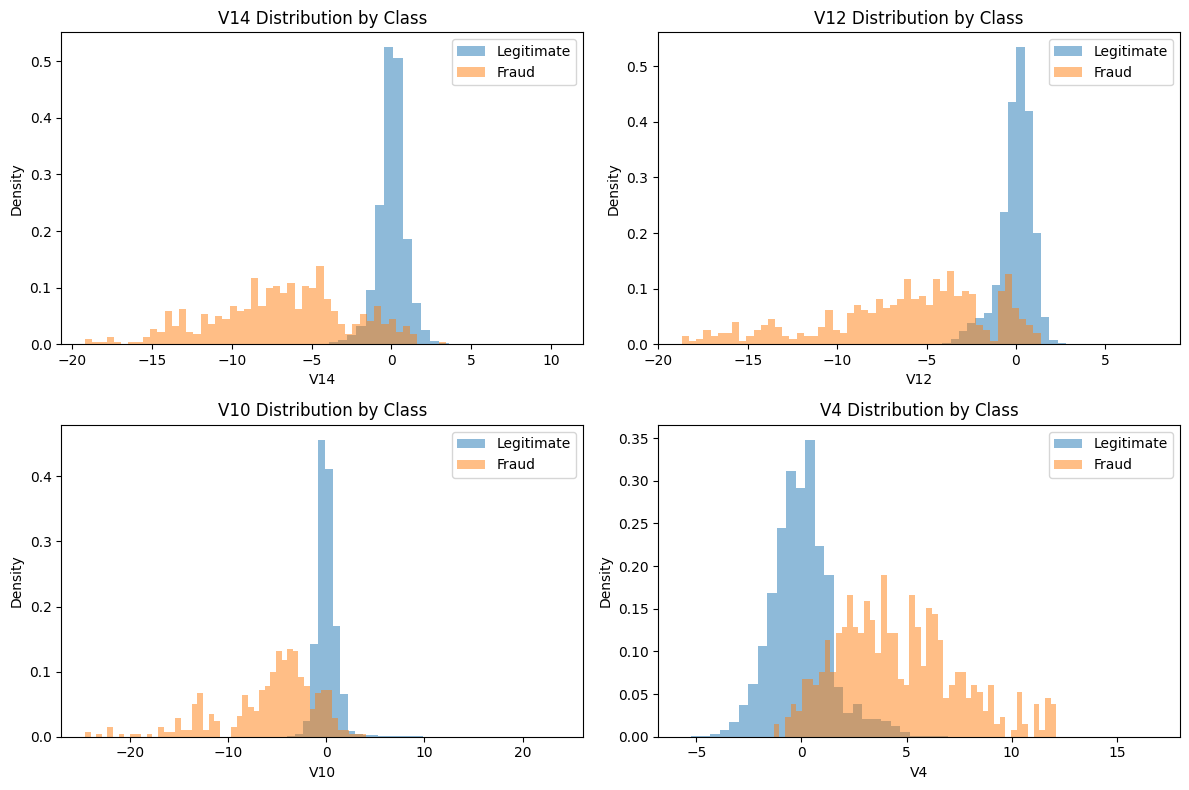

Visual EDA completed. The original DataFrame remains unchanged.


In [ ]:

# ============================================================
# Stage 3.3: Visual Exploratory Data Analysis
# Purpose: Visualize class imbalance and compare selected
# feature distributions between legitimate and fraudulent
# transactions without modifying the original dataset.
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# Define consistent class labels for visualization.
class_labels = {
    0: "Legitimate",
    1: "Fraud"
}

# ------------------------------------------------------------
# 1. Class distribution
# ------------------------------------------------------------

class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    [class_labels[class_id] for class_id in class_counts.index],
    class_counts.values
)
plt.title("Class Distribution")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# Display exact counts and percentages.
class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_counts / len(df) * 100
})
class_distribution.index = [
    class_labels[class_id] for class_id in class_distribution.index
]

display(class_distribution.round(4))

# ------------------------------------------------------------
# 2. Transaction amount distribution
# ------------------------------------------------------------

# Use a logarithmic horizontal axis to make the highly
# right-skewed amount distribution easier to inspect.
amount_plot = df.loc[df["Amount"] > 0, ["Amount", "Class"]].copy()
amount_plot["Class_Label"] = amount_plot["Class"].map(class_labels)

plt.figure(figsize=(9, 5))

for class_name in ["Legitimate", "Fraud"]:
    values = amount_plot.loc[
        amount_plot["Class_Label"] == class_name, "Amount"
    ]
    plt.hist(
        values,
        bins=60,
        alpha=0.5,
        label=class_name,
        density=True
    )

plt.xscale("log")
plt.title("Transaction Amount Distribution (Positive Amounts)")
plt.xlabel("Transaction Amount (Log Scale)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Transaction time distribution by class
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for class_name, class_id in class_labels.items():
    values = df.loc[df["Class"] == class_id, "Time"]
    plt.hist(
        values,
        bins=50,
        alpha=0.5,
        label=class_name,
        density=True
    )

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Time (Seconds Since the First Recorded Transaction)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Selected feature distributions by class
# ------------------------------------------------------------

selected_features = ["V14", "V12", "V10", "V4"]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12, 8)
)

for feature, ax in zip(selected_features, axes.flatten()):
    for class_id, class_name in class_labels.items():
        values = df.loc[df["Class"] == class_id, feature]

        ax.hist(
            values,
            bins=50,
            alpha=0.5,
            label=class_name,
            density=True
        )

    ax.set_title(f"{feature} Distribution by Class")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

print("Visual EDA completed. The original DataFrame remains unchanged.")


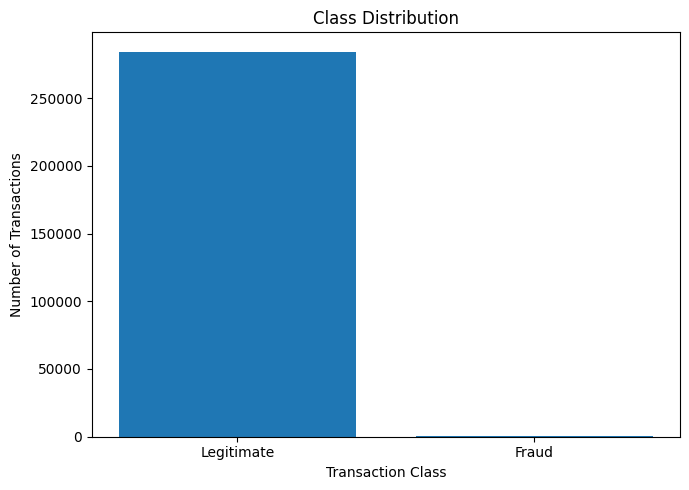

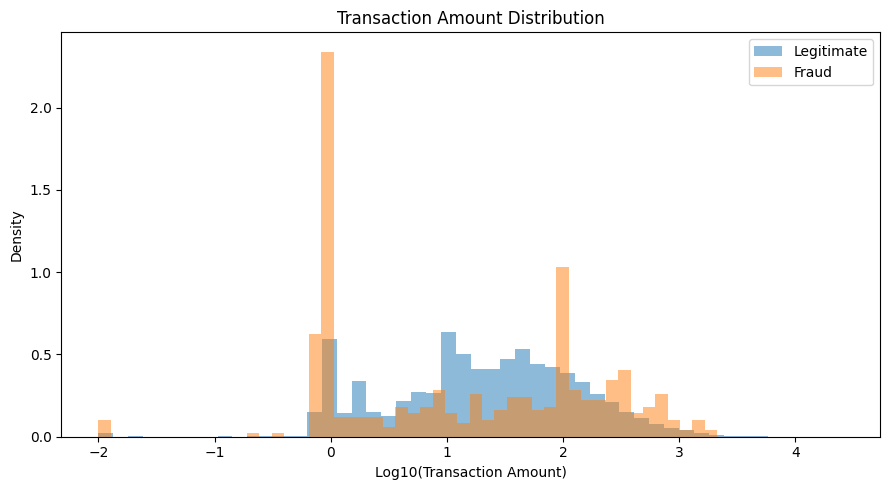

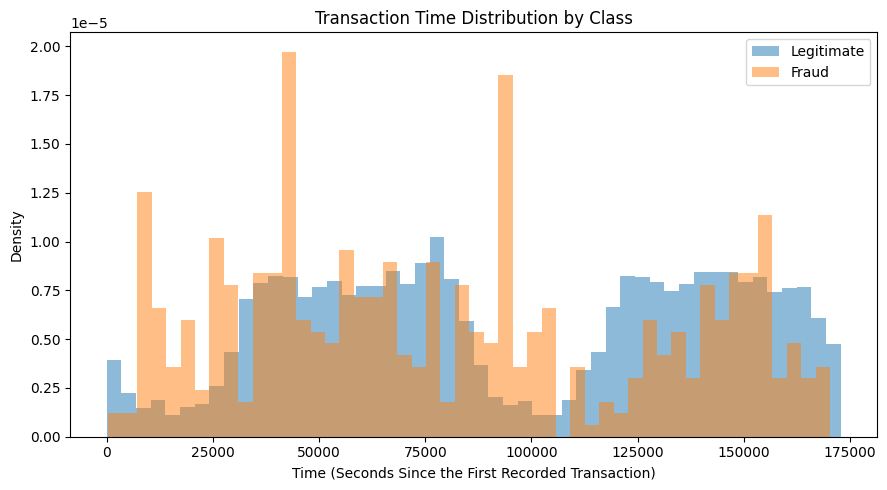

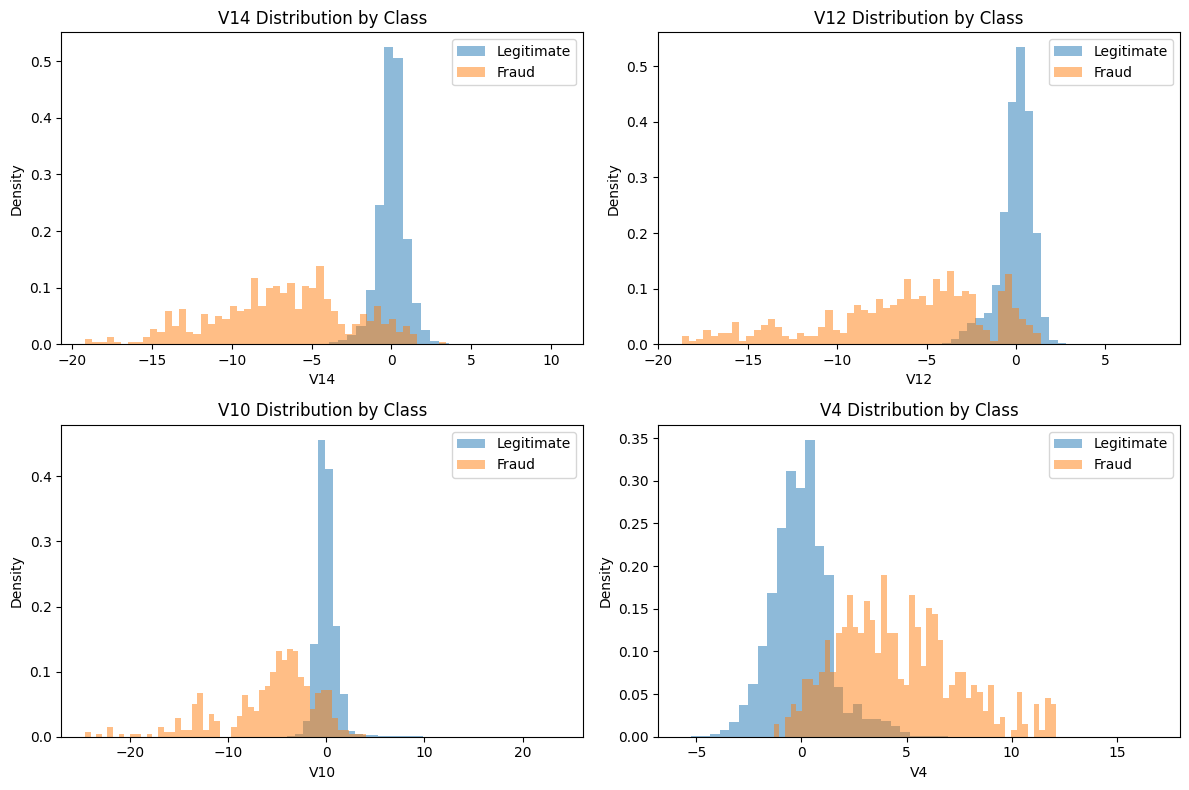

Visual EDA completed. The original DataFrame remains unchanged.


In [ ]:

# ============================================================
# Stage 3.3: Visual Exploratory Data Analysis
# Purpose: Visualize class imbalance and compare feature
# distributions without modifying the original dataset.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

class_labels = {
    0: "Legitimate",
    1: "Fraud"
}

# ------------------------------------------------------------
# 1. Target class distribution
# ------------------------------------------------------------

class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    [class_labels[class_id] for class_id in class_counts.index],
    class_counts.values
)
plt.title("Class Distribution")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. Transaction amount distribution
# ------------------------------------------------------------

# Exclude zero amounts because log10(0) is undefined.
positive_amounts = df.loc[df["Amount"] > 0, ["Amount", "Class"]].copy()
positive_amounts["Log10_Amount"] = np.log10(positive_amounts["Amount"])

plt.figure(figsize=(9, 5))

for class_id, class_name in class_labels.items():
    values = positive_amounts.loc[
        positive_amounts["Class"] == class_id,
        "Log10_Amount"
    ]

    plt.hist(
        values,
        bins=50,
        alpha=0.5,
        label=class_name,
        density=True
    )

plt.title("Transaction Amount Distribution")
plt.xlabel("Log10(Transaction Amount)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Transaction time distribution by class
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for class_id, class_name in class_labels.items():
    values = df.loc[df["Class"] == class_id, "Time"]

    plt.hist(
        values,
        bins=50,
        alpha=0.5,
        label=class_name,
        density=True
    )

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Time (Seconds Since the First Recorded Transaction)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Selected feature distributions by class
# ------------------------------------------------------------

selected_features = ["V14", "V12", "V10", "V4"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(selected_features, axes.flatten()):
    for class_id, class_name in class_labels.items():
        values = df.loc[df["Class"] == class_id, feature]

        ax.hist(
            values,
            bins=50,
            alpha=0.5,
            label=class_name,
            density=True
        )

    ax.set_title(f"{feature} Distribution by Class")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

print("Visual EDA completed. The original DataFrame remains unchanged.")


In [ ]:

# ============================================================
# Stage 4.1: Chronological Data Splitting Audit
# Purpose: Define chronological train, validation, and test
# partitions and inspect their class distributions.
# The original DataFrame remains unchanged.
# ============================================================

import pandas as pd

# Define the proportions for chronological data splitting.
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

# Verify that the split proportions sum to one.
assert abs(
    TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO - 1.0
) < 1e-9, "Split ratios must sum to 1.0."

# Verify chronological ordering before splitting.
is_time_monotonic = df["Time"].is_monotonic_increasing

print("=" * 80)
print("CHRONOLOGICAL ORDER CHECK")
print("=" * 80)
print(f"Time column is non-decreasing: {is_time_monotonic}")

if not is_time_monotonic:
    raise ValueError(
        "The dataset is not ordered by Time. "
        "Review the ordering before defining chronological partitions."
    )

# Calculate the row indices for each partition.
n_rows = len(df)
train_end = int(n_rows * TRAIN_RATIO)
validation_end = int(n_rows * (TRAIN_RATIO + VALIDATION_RATIO))

# Create chronological partitions without modifying the source DataFrame.
train_df = df.iloc[:train_end].copy()
validation_df = df.iloc[train_end:validation_end].copy()
test_df = df.iloc[validation_end:].copy()

# Summarize partition sizes and time ranges.
partition_summary = pd.DataFrame([
    {
        "Partition": "Train",
        "Rows": len(train_df),
        "Start_Time": train_df["Time"].iloc[0],
        "End_Time": train_df["Time"].iloc[-1],
        "Fraud_Count": int(train_df["Class"].sum()),
        "Fraud_Percentage": train_df["Class"].mean() * 100
    },
    {
        "Partition": "Validation",
        "Rows": len(validation_df),
        "Start_Time": validation_df["Time"].iloc[0],
        "End_Time": validation_df["Time"].iloc[-1],
        "Fraud_Count": int(validation_df["Class"].sum()),
        "Fraud_Percentage": validation_df["Class"].mean() * 100
    },
    {
        "Partition": "Test",
        "Rows": len(test_df),
        "Start_Time": test_df["Time"].iloc[0],
        "End_Time": test_df["Time"].iloc[-1],
        "Fraud_Count": int(test_df["Class"].sum()),
        "Fraud_Percentage": test_df["Class"].mean() * 100
    }
])

print("\n" + "=" * 80)
print("CHRONOLOGICAL PARTITION SUMMARY")
print("=" * 80)
display(partition_summary.round(4))

# Verify that all rows are accounted for.
assert len(train_df) + len(validation_df) + len(test_df) == n_rows

# Verify chronological row boundaries.
assert train_df.index.max() < validation_df.index.min()
assert validation_df.index.max() < test_df.index.min()

print("\nPartition audit completed.")
print("No rows were removed, resampled, or reordered.")


CHRONOLOGICAL ORDER CHECK
Time column is non-decreasing: True

CHRONOLOGICAL PARTITION SUMMARY


,Partition,Rows,Start_Time,End_Time,Fraud_Count,Fraud_Percentage
0,Train,199364,0.0,132928.0,384,0.1926
1,Validation,42721,132929.0,151328.0,56,0.1311
2,Test,42722,151328.0,172792.0,52,0.1217



Partition audit completed.
No rows were removed, resampled, or reordered.


In [ ]:

# ============================================================
# Stage 4.2: Feature Definition and Preprocessing Audit
# Purpose: Inspect model input features and define a leakage-safe
# preprocessing plan without modifying the dataset.
# ============================================================

import pandas as pd

TARGET_COLUMN = "Class"
TIME_COLUMN = "Time"
AMOUNT_COLUMN = "Amount"

# Define candidate input features.
candidate_features = [
    column for column in df.columns
    if column != TARGET_COLUMN
]

# Separate feature names and target labels for each partition.
X_train_raw = train_df[candidate_features].copy()
y_train = train_df[TARGET_COLUMN].copy()

X_validation_raw = validation_df[candidate_features].copy()
y_validation = validation_df[TARGET_COLUMN].copy()

X_test_raw = test_df[candidate_features].copy()
y_test = test_df[TARGET_COLUMN].copy()

# Summarize the feature groups.
feature_summary = pd.DataFrame({
    "Feature_Group": [
        "Time",
        "PCA-transformed features",
        "Transaction amount",
        "Target"
    ],
    "Columns": [
        TIME_COLUMN,
        "V1-V28",
        AMOUNT_COLUMN,
        TARGET_COLUMN
    ],
    "Role": [
        "Temporal ordering and possible time-gap engineering",
        "Numerical transaction features",
        "Numerical transaction feature requiring scale review",
        "Prediction label; excluded from model inputs"
    ]
})

print("=" * 80)
print("FEATURE GROUP SUMMARY")
print("=" * 80)
display(feature_summary)

print("\n" + "=" * 80)
print("PARTITION SHAPES")
print("=" * 80)

partition_shapes = pd.DataFrame([
    {
        "Partition": "Train",
        "X_Rows": len(X_train_raw),
        "X_Columns": X_train_raw.shape[1],
        "y_Rows": len(y_train),
        "Fraud_Count": int(y_train.sum())
    },
    {
        "Partition": "Validation",
        "X_Rows": len(X_validation_raw),
        "X_Columns": X_validation_raw.shape[1],
        "y_Rows": len(y_validation),
        "Fraud_Count": int(y_validation.sum())
    },
    {
        "Partition": "Test",
        "X_Rows": len(X_test_raw),
        "X_Columns": X_test_raw.shape[1],
        "y_Rows": len(y_test),
        "Fraud_Count": int(y_test.sum())
    }
])

display(partition_shapes)

print("\n" + "=" * 80)
print("INPUT FEATURE CHECKS")
print("=" * 80)

print(f"Target column excluded from candidate features: {TARGET_COLUMN not in candidate_features}")
print(f"Number of candidate input features: {len(candidate_features)}")
print(f"Time column included as a candidate feature: {TIME_COLUMN in candidate_features}")
print(f"Amount column included as a candidate feature: {AMOUNT_COLUMN in candidate_features}")
print(f"All candidate features are numeric: {X_train_raw.dtypes.apply(pd.api.types.is_numeric_dtype).all()}")
print(f"Missing values in training features: {int(X_train_raw.isna().sum().sum())}")
print(f"Missing values in validation features: {int(X_validation_raw.isna().sum().sum())}")
print(f"Missing values in test features: {int(X_test_raw.isna().sum().sum())}")

# Confirm that the original target is not present in model inputs.
assert TARGET_COLUMN not in X_train_raw.columns
assert TARGET_COLUMN not in X_validation_raw.columns
assert TARGET_COLUMN not in X_test_raw.columns

# Confirm that feature and target lengths are aligned.
assert len(X_train_raw) == len(y_train)
assert len(X_validation_raw) == len(y_validation)
assert len(X_test_raw) == len(y_test)

print("\nFeature definition audit completed.")
print("No scaling, feature removal, or resampling has been performed.")


FEATURE GROUP SUMMARY


,Feature_Group,Columns,Role
0,Time,Time,Temporal ordering and possible time-gap engine...
1,PCA-transformed features,V1-V28,Numerical transaction features
2,Transaction amount,Amount,Numerical transaction feature requiring scale ...
3,Target,Class,Prediction label; excluded from model inputs



PARTITION SHAPES


,Partition,X_Rows,X_Columns,y_Rows,Fraud_Count
0,Train,199364,30,199364,384
1,Validation,42721,30,42721,56
2,Test,42722,30,42722,52



INPUT FEATURE CHECKS
Target column excluded from candidate features: True
Number of candidate input features: 30
Time column included as a candidate feature: True
Amount column included as a candidate feature: True
All candidate features are numeric: True
Missing values in training features: 0
Missing values in validation features: 0
Missing values in test features: 0

Feature definition audit completed.
No scaling, feature removal, or resampling has been performed.


## Feature Scaling

In [ ]:

# ============================================================
# Stage 4.3: Leakage-Safe Amount Scaling
# Purpose: Standardize transaction Amount using training data only.
# PCA-transformed features remain unchanged in this stage.
# The Time column is retained separately for temporal processing.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Preserve the original time values for chronological processing.
time_train = X_train_raw["Time"].to_numpy(dtype=np.float64)
time_validation = X_validation_raw["Time"].to_numpy(dtype=np.float64)
time_test = X_test_raw["Time"].to_numpy(dtype=np.float64)

# Fit the scaler using the training partition only.
amount_scaler = StandardScaler()
amount_scaler.fit(X_train_raw[["Amount"]])

# Transform Amount in each partition using the training-fitted scaler.
def prepare_scaled_features(X, scaler):
    prepared = X.drop(columns=["Time"]).copy()

    prepared["Amount"] = scaler.transform(
        X[["Amount"]]
    ).ravel()

    return prepared

X_train_scaled = prepare_scaled_features(X_train_raw, amount_scaler)
X_validation_scaled = prepare_scaled_features(
    X_validation_raw, amount_scaler
)
X_test_scaled = prepare_scaled_features(X_test_raw, amount_scaler)

# Inspect the scaling parameters and resulting distributions.
scaling_summary = pd.DataFrame([
    {
        "Partition": "Train",
        "Amount_Mean_After_Scaling": X_train_scaled["Amount"].mean(),
        "Amount_Std_After_Scaling": X_train_scaled["Amount"].std(ddof=0),
        "Amount_Min_After_Scaling": X_train_scaled["Amount"].min(),
        "Amount_Max_After_Scaling": X_train_scaled["Amount"].max()
    },
    {
        "Partition": "Validation",
        "Amount_Mean_After_Scaling": X_validation_scaled["Amount"].mean(),
        "Amount_Std_After_Scaling": X_validation_scaled["Amount"].std(ddof=0),
        "Amount_Min_After_Scaling": X_validation_scaled["Amount"].min(),
        "Amount_Max_After_Scaling": X_validation_scaled["Amount"].max()
    },
    {
        "Partition": "Test",
        "Amount_Mean_After_Scaling": X_test_scaled["Amount"].mean(),
        "Amount_Std_After_Scaling": X_test_scaled["Amount"].std(ddof=0),
        "Amount_Min_After_Scaling": X_test_scaled["Amount"].min(),
        "Amount_Max_After_Scaling": X_test_scaled["Amount"].max()
    }
])

print("=" * 80)
print("TRAINING-FITTED SCALER PARAMETERS")
print("=" * 80)
print(f"Training Amount mean: {amount_scaler.mean_[0]:.6f}")
print(f"Training Amount variance: {amount_scaler.var_[0]:.6f}")
print(f"Training Amount scale: {amount_scaler.scale_[0]:.6f}")

print("\n" + "=" * 80)
print("SCALED AMOUNT SUMMARY")
print("=" * 80)
display(scaling_summary.round(6))

print("\n" + "=" * 80)
print("FEATURE AND TEMPORAL DATA CHECKS")
print("=" * 80)
print(f"Training feature shape: {X_train_scaled.shape}")
print(f"Validation feature shape: {X_validation_scaled.shape}")
print(f"Test feature shape: {X_test_scaled.shape}")
print(f"Time retained separately for all partitions: "
      f"{len(time_train) == len(X_train_scaled) and len(time_validation) == len(X_validation_scaled) and len(time_test) == len(X_test_scaled)}")
print(f"Missing values after scaling: "
      f"{int(X_train_scaled.isna().sum().sum() + X_validation_scaled.isna().sum().sum() + X_test_scaled.isna().sum().sum())}")

# Confirm that the PCA features were not altered.
pca_features = [f"V{i}" for i in range(1, 29)]

assert np.allclose(
    X_train_scaled[pca_features].to_numpy(),
    X_train_raw[pca_features].to_numpy()
)
assert "Time" not in X_train_scaled.columns
assert "Class" not in X_train_scaled.columns
assert X_train_scaled.shape[1] == 29
assert X_validation_scaled.shape[1] == 29
assert X_test_scaled.shape[1] == 29

print("\nAmount scaling completed.")
print("The scaler was fitted on training data only.")
print("No rows were removed, reordered, or resampled.")


TRAINING-FITTED SCALER PARAMETERS
Training Amount mean: 89.771200
Training Amount variance: 61956.692534
Training Amount scale: 248.911013

SCALED AMOUNT SUMMARY


,Partition,Amount_Mean_After_Scaling,Amount_Std_After_Scaling,Amount_Min_After_Scaling,Amount_Max_After_Scaling
0,Train,-0.000000,1.000000,-0.360656,78.609454
1,Validation,0.031141,1.082581,-0.360656,39.814344
2,Test,-0.069214,0.942008,-0.360656,102.853580



FEATURE AND TEMPORAL DATA CHECKS
Training feature shape: (199364, 29)
Validation feature shape: (42721, 29)
Test feature shape: (42722, 29)
Time retained separately for all partitions: True
Missing values after scaling: 0

Amount scaling completed.
The scaler was fitted on training data only.
No rows were removed, reordered, or resampled.


In [ ]:

# ============================================================
# Stage 4.4: Temporal Window Feasibility Audit
# Purpose: Compare candidate sequence lengths without training
# models or using validation/test performance to select a window.
# ============================================================

import pandas as pd

# Candidate window lengths for the initial experiment.
WINDOW_CANDIDATES = [5, 10, 20, 30, 50]

partitions = {
    "Train": y_train,
    "Validation": y_validation,
    "Test": y_test
}

audit_records = []

for partition_name, labels in partitions.items():
    n_samples = len(labels)

    for window_size in WINDOW_CANDIDATES:
        # Each target requires the preceding window_size observations.
        n_possible = max(0, n_samples - window_size)

        # Count positive labels among targets after the initial history.
        eligible_labels = labels.iloc[window_size:]

        audit_records.append({
            "Partition": partition_name,
            "Window_Size": window_size,
            "Partition_Rows": n_samples,
            "Potential_Targets": n_possible,
            "Potential_Fraud_Targets": int(eligible_labels.sum()),
            "Potential_Legitimate_Targets": int(
                (eligible_labels == 0).sum()
            )
        })

window_audit = pd.DataFrame(audit_records)

print("=" * 80)
print("TEMPORAL WINDOW FEASIBILITY AUDIT")
print("=" * 80)
display(window_audit)

print("\n" + "=" * 80)
print("CHRONOLOGICAL BOUNDARY CHECK")
print("=" * 80)

print(f"Last training index: {train_df.index[-1]}")
print(f"First validation index: {validation_df.index[0]}")
print(f"Last validation index: {validation_df.index[-1]}")
print(f"First test index: {test_df.index[0]}")

# Verify that candidate windows are valid and do not alter partitions.
assert all(window_size > 0 for window_size in WINDOW_CANDIDATES)
assert all(window_size < len(y_test) for window_size in WINDOW_CANDIDATES)
assert len(train_df) == len(y_train)
assert len(validation_df) == len(y_validation)
assert len(test_df) == len(y_test)

print("\nWindow feasibility audit completed.")
print("No sequences were created and no model was trained.")


TEMPORAL WINDOW FEASIBILITY AUDIT


,Partition,Window_Size,Partition_Rows,Potential_Targets,Potential_Fraud_Targets,Potential_Legitimate_Targets
0,Train,5,199364,199359,384,198975
1,Train,10,199364,199354,384,198970
2,Train,20,199364,199344,384,198960
3,Train,30,199364,199334,384,198950
4,Train,50,199364,199314,384,198930
5,Validation,5,42721,42716,56,42660
6,Validation,10,42721,42711,56,42655
7,Validation,20,42721,42701,56,42645
8,Validation,30,42721,42691,56,42635
9,Validation,50,42721,42671,56,42615



CHRONOLOGICAL BOUNDARY CHECK
Last training index: 199363
First validation index: 199364
Last validation index: 242084
First test index: 242085

Window feasibility audit completed.
No sequences were created and no model was trained.


In [ ]:

# Stage 4.5: Temporal Feature Engineering and Sequence Alignment Audit

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Validate required variables from previous stages
required_variables = [
    "X_train_scaled",
    "X_validation_scaled",
    "X_test_scaled",
    "y_train",
    "y_validation",
    "y_test",
    "time_train",
    "time_validation",
    "time_test",
    "WINDOW_CANDIDATES",
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        f"Required variables are missing: {missing_variables}. "
        "Please run the preceding stages first."
    )

# 2. Convert partition features to NumPy arrays without changing row order
X_train_base = X_train_scaled.to_numpy(dtype=np.float32)
X_validation_base = X_validation_scaled.to_numpy(dtype=np.float32)
X_test_base = X_test_scaled.to_numpy(dtype=np.float32)

y_train_array = np.asarray(y_train, dtype=np.int64).reshape(-1)
y_validation_array = np.asarray(y_validation, dtype=np.int64).reshape(-1)
y_test_array = np.asarray(y_test, dtype=np.int64).reshape(-1)

time_train_array = np.asarray(time_train, dtype=np.float64).reshape(-1)
time_validation_array = np.asarray(time_validation, dtype=np.float64).reshape(-1)
time_test_array = np.asarray(time_test, dtype=np.float64).reshape(-1)

# 3. Check row alignment within each partition
partitions = {
    "Train": (X_train_base, y_train_array, time_train_array),
    "Validation": (X_validation_base, y_validation_array, time_validation_array),
    "Test": (X_test_base, y_test_array, time_test_array),
}

for partition_name, (features, labels, timestamps) in partitions.items():
    if not (len(features) == len(labels) == len(timestamps)):
        raise ValueError(
            f"{partition_name} alignment error: "
            f"features={len(features)}, labels={len(labels)}, "
            f"timestamps={len(timestamps)}"
        )

    if not np.all(np.isfinite(features)):
        raise ValueError(f"{partition_name} contains non-finite feature values.")

    if not np.all(np.isfinite(timestamps)):
        raise ValueError(f"{partition_name} contains non-finite timestamps.")

# 4. Compute elapsed time between consecutive transactions
# The calculation uses only the current and immediately preceding timestamps.
all_timestamps = np.concatenate(
    [time_train_array, time_validation_array, time_test_array]
)

if np.any(np.diff(all_timestamps) < 0):
    raise ValueError("Timestamps are not non-decreasing across the partitions.")

delta_time = np.diff(
    all_timestamps,
    prepend=all_timestamps[0]
)

if np.any(delta_time < 0):
    raise ValueError("Negative inter-transaction time gaps were found.")

log_delta_time = np.log1p(delta_time).astype(np.float32).reshape(-1, 1)

# 5. Fit the temporal-gap scaler on Train data only
train_length = len(X_train_base)
validation_length = len(X_validation_base)
test_length = len(X_test_base)

delta_time_scaler = StandardScaler()
delta_time_scaler.fit(log_delta_time[:train_length])

log_delta_time_scaled = delta_time_scaler.transform(
    log_delta_time
).astype(np.float32)

# 6. Construct the combined feature matrix in original chronological row order
X_all_base = np.concatenate(
    [X_train_base, X_validation_base, X_test_base],
    axis=0
)

X_all = np.concatenate(
    [X_all_base, log_delta_time_scaled],
    axis=1
).astype(np.float32)

y_all = np.concatenate(
    [y_train_array, y_validation_array, y_test_array]
)

# 7. Define target-index ranges for each partition
train_start = 0
train_end = train_length
validation_start = train_end
validation_end = validation_start + validation_length
test_start = validation_end
test_end = test_start + test_length

partition_ranges = {
    "Train": (train_start, train_end),
    "Validation": (validation_start, validation_end),
    "Test": (test_start, test_end),
}

# 8. Audit lazy sequence indexing for every candidate window size
print("=" * 76)
print("STAGE 4.5: TEMPORAL FEATURE AND SEQUENCE ALIGNMENT AUDIT")
print("=" * 76)

print("\nFeature matrix:")
print(f"Base feature count: {X_all_base.shape[1]}")
print("Added feature: log1p(DeltaTime)")
print(f"Combined feature shape: {X_all.shape}")
print(f"Combined label shape: {y_all.shape}")
print(f"Feature dtype: {X_all.dtype}")

print("\nTemporal-gap feature:")
print(f"Raw DeltaTime minimum: {delta_time.min():.4f}")
print(f"Raw DeltaTime maximum: {delta_time.max():.4f}")
print(f"Zero-gap transactions: {(delta_time == 0).sum():,}")
print(
    "Train scaled log1p(DeltaTime) mean: "
    f"{log_delta_time_scaled[:train_length].mean():.6f}"
)
print(
    "Train scaled log1p(DeltaTime) standard deviation: "
    f"{log_delta_time_scaled[:train_length].std():.6f}"
)

print("\nPartition target ranges:")
for partition_name, (start, end) in partition_ranges.items():
    partition_labels = y_all[start:end]
    print(
        f"{partition_name}: indices [{start}, {end}), "
        f"targets={end - start:,}, "
        f"fraud={int(partition_labels.sum()):,}"
    )

print("\nLazy sequence-index audit:")
for window_size in WINDOW_CANDIDATES:
    print(f"\nWindow size: {window_size}")

    for partition_name, (start, end) in partition_ranges.items():
        # Targets must have enough preceding observations for a complete window.
        first_target = max(start, window_size)
        target_count = max(0, end - first_target)

        if target_count > 0:
            target_labels = y_all[first_target:end]
            fraud_count = int(target_labels.sum())
        else:
            fraud_count = 0

        print(
            f"  {partition_name}: "
            f"first_target={first_target}, "
            f"target_count={target_count:,}, "
            f"fraud_targets={fraud_count:,}"
        )

# 9. Verify that an example window contains only preceding rows
example_window_size = min(WINDOW_CANDIDATES)
example_target = train_start + example_window_size

example_window = X_all[
    example_target - example_window_size:example_target
]
example_target_label = y_all[example_target]

assert example_window.shape == (
    example_window_size,
    X_all.shape[1]
)
assert example_target >= example_window_size
assert len(example_window) == example_window_size

print("\nExample alignment check:")
print(f"Window shape: {example_window.shape}")
print(f"Target index: {example_target}")
print(f"Target label: {example_target_label}")
print(
    "Window source indices: "
    f"[{example_target - example_window_size}, {example_target})"
)
print(f"Target row index: {example_target}")
print("Alignment check passed: the target row is not included in its input window.")

print("\nNo model was trained and no rows were removed or reordered.")


STAGE 4.5: TEMPORAL FEATURE AND SEQUENCE ALIGNMENT AUDIT

Feature matrix:
Base feature count: 29
Added feature: log1p(DeltaTime)
Combined feature shape: (284807, 30)
Combined label shape: (284807,)
Feature dtype: float32

Temporal-gap feature:
Raw DeltaTime minimum: 0.0000
Raw DeltaTime maximum: 32.0000
Zero-gap transactions: 160,216
Train scaled log1p(DeltaTime) mean: -0.000000
Train scaled log1p(DeltaTime) standard deviation: 1.000000

Partition target ranges:
Train: indices [0, 199364), targets=199,364, fraud=384
Validation: indices [199364, 242085), targets=42,721, fraud=56
Test: indices [242085, 284807), targets=42,722, fraud=52

Lazy sequence-index audit:

Window size: 5
  Train: first_target=5, target_count=199,359, fraud_targets=384
  Validation: first_target=199364, target_count=42,721, fraud_targets=56
  Test: first_target=242085, target_count=42,722, fraud_targets=52

Window size: 10
  Train: first_target=10, target_count=199,354, fraud_targets=384
  Validation: first_target

In [ ]:

# Stage 4.6: Lazy Temporal Dataset Construction and Validation

import numpy as np
import torch
from torch.utils.data import Dataset

class TemporalFraudDataset(Dataset):
    """Lazy dataset for predicting a transaction from preceding transactions."""

    def __init__(self, features, labels, target_start, target_end, window_size):
        if features.ndim != 2:
            raise ValueError("Features must be a two-dimensional array.")

        if len(features) != len(labels):
            raise ValueError("Features and labels must have equal lengths.")

        if window_size < 1:
            raise ValueError("Window size must be positive.")

        if target_start < window_size:
            raise ValueError(
                "The first target must have enough preceding observations."
            )

        if target_end > len(features) or target_start >= target_end:
            raise ValueError("Invalid target index range.")

        self.features = features
        self.labels = labels
        self.target_start = int(target_start)
        self.target_end = int(target_end)
        self.window_size = int(window_size)

    def __len__(self):
        return self.target_end - self.target_start

    def __getitem__(self, index):
        if index < 0 or index >= len(self):
            raise IndexError("Dataset index out of range.")

        target_index = self.target_start + index
        window_start = target_index - self.window_size

        # Use only preceding transactions as input.
        x_window = self.features[window_start:target_index]
        y_target = self.labels[target_index]

        x_tensor = torch.from_numpy(
            np.ascontiguousarray(x_window, dtype=np.float32)
        )
        y_tensor = torch.tensor(y_target, dtype=torch.float32)

        return x_tensor, y_tensor


# Define partition boundaries using the verified lengths.
train_end = len(X_train_base)
validation_end = train_end + len(X_validation_base)
test_end = validation_end + len(X_test_base)

# Build a small audit dataset using the shortest candidate window.
audit_window_size = min(WINDOW_CANDIDATES)

train_dataset_audit = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=audit_window_size,
    target_end=train_end,
    window_size=audit_window_size,
)

validation_dataset_audit = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=train_end,
    target_end=validation_end,
    window_size=audit_window_size,
)

test_dataset_audit = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=validation_end,
    target_end=test_end,
    window_size=audit_window_size,
)

# Validate dataset lengths.
assert len(train_dataset_audit) == train_end - audit_window_size
assert len(validation_dataset_audit) == validation_end - train_end
assert len(test_dataset_audit) == test_end - validation_end

# Inspect one sample from each partition.
for partition_name, dataset in [
    ("Train", train_dataset_audit),
    ("Validation", validation_dataset_audit),
    ("Test", test_dataset_audit),
]:
    sample_x, sample_y = dataset[0]

    print(f"\n{partition_name} dataset")
    print(f"Dataset length: {len(dataset):,}")
    print(f"Sample input shape: {tuple(sample_x.shape)}")
    print(f"Sample target: {int(sample_y.item())}")
    print(f"Input finite: {bool(torch.isfinite(sample_x).all())}")
    print(f"Target index: {dataset.target_start}")
    print(
        "Input indices: "
        f"[{dataset.target_start - audit_window_size}, "
        f"{dataset.target_start})"
    )

    assert sample_x.shape == (audit_window_size, X_all.shape[1])
    assert torch.isfinite(sample_x).all()
    assert sample_y.item() in (0.0, 1.0)

print("\nStage 4.6 validation passed.")
print("No model was trained.")



Train dataset
Dataset length: 199,359
Sample input shape: (5, 30)
Sample target: 0
Input finite: True
Target index: 5
Input indices: [0, 5)

Validation dataset
Dataset length: 42,721
Sample input shape: (5, 30)
Sample target: 0
Input finite: True
Target index: 199364
Input indices: [199359, 199364)

Test dataset
Dataset length: 42,722
Sample input shape: (5, 30)
Sample target: 0
Input finite: True
Target index: 242085
Input indices: [242080, 242085)

Stage 4.6 validation passed.
No model was trained.


In [ ]:

# Stage 4.7: Evaluation Protocol and Leakage Audit

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

# 1. Verify partition sizes and chronological row boundaries
expected_lengths = {
    "Train": 199364,
    "Validation": 42721,
    "Test": 42722,
}

actual_lengths = {
    "Train": len(X_train_base),
    "Validation": len(X_validation_base),
    "Test": len(X_test_base),
}

assert actual_lengths == expected_lengths, (
    f"Unexpected partition lengths: {actual_lengths}"
)

assert train_end == len(X_train_base)
assert validation_end == train_end + len(X_validation_base)
assert test_end == validation_end + len(X_test_base)
assert len(X_all) == len(y_all) == sum(actual_lengths.values())

# 2. Verify that feature and label partitions match the original data
original_labels = df["Class"].to_numpy(dtype=np.int64)

assert np.array_equal(y_all, original_labels), (
    "Combined labels do not match the original row order."
)

assert np.all(np.diff(all_timestamps) >= 0), (
    "Chronological timestamp order is not preserved."
)

# 3. Verify that the Amount scaler was fitted on training data only
amount_train_mean = float(X_train_raw["Amount"].mean())
amount_train_std = float(X_train_raw["Amount"].std(ddof=0))

assert np.isclose(amount_scaler.mean_[0], amount_train_mean)
assert np.isclose(amount_scaler.scale_[0], amount_train_std)

# 4. Verify that the temporal-gap scaler was fitted on training data only
expected_delta_scaler = StandardScaler()
expected_delta_scaler.fit(log_delta_time[:train_end])

assert np.allclose(
    delta_time_scaler.mean_,
    expected_delta_scaler.mean_
)
assert np.allclose(
    delta_time_scaler.scale_,
    expected_delta_scaler.scale_
)

# 5. Verify label counts and fraud prevalence in each partition
partition_summary = []

for partition_name, start, end in [
    ("Train", 0, train_end),
    ("Validation", train_end, validation_end),
    ("Test", validation_end, test_end),
]:
    labels = y_all[start:end]
    fraud_count = int(labels.sum())
    total_count = len(labels)

    partition_summary.append({
        "Partition": partition_name,
        "Rows": total_count,
        "Legitimate": int(total_count - fraud_count),
        "Fraud": fraud_count,
        "Fraud prevalence (%)": 100 * fraud_count / total_count,
    })

partition_summary_df = pd.DataFrame(partition_summary)

# 6. Define the evaluation protocol before model training
evaluation_protocol = {
    "Primary metrics": [
        "Average Precision (PR-AUC approximation)",
        "Precision",
        "Recall",
        "F1-score",
    ],
    "Secondary metrics": [
        "ROC-AUC",
        "Matthews Correlation Coefficient (MCC)",
        "Confusion Matrix",
    ],
    "Model selection": "Validation set only",
    "Threshold selection": "Validation set only",
    "Final evaluation": "Test set once after model and threshold selection",
    "Early stopping": "Validation Average Precision",
    "Sequence policy": (
        "Input window contains only preceding transactions; "
        "target label belongs to the next transaction"
    ),
    "Imbalance policy": (
        "Consider class-weighted binary cross-entropy; "
        "do not apply resampling to validation or test"
    ),
}

# 7. Display the audit results
print("=" * 76)
print("STAGE 4.7: EVALUATION PROTOCOL AND LEAKAGE AUDIT")
print("=" * 76)

print("\nPartition integrity:")
for partition_name, row_count in actual_lengths.items():
    print(f"{partition_name}: {row_count:,} rows")

print("\nClass distribution:")
print(partition_summary_df.to_string(index=False))

print("\nScaling audit:")
print("Amount scaler matches training-only statistics: PASS")
print("DeltaTime scaler matches training-only statistics: PASS")

print("\nTemporal and label alignment:")
print("Original label order preserved: PASS")
print("Timestamps remain non-decreasing: PASS")
print("No model was trained: PASS")

print("\nEvaluation protocol:")
for category, details in evaluation_protocol.items():
    if isinstance(details, list):
        print(f"{category}:")
        for item in details:
            print(f"  - {item}")
    else:
        print(f"{category}: {details}")

print("\nStage 4.7 audit completed.")


STAGE 4.7: EVALUATION PROTOCOL AND LEAKAGE AUDIT

Partition integrity:
Train: 199,364 rows
Validation: 42,721 rows
Test: 42,722 rows

Class distribution:
 Partition   Rows  Legitimate  Fraud  Fraud prevalence (%)
     Train 199364      198980    384              0.192613
Validation  42721       42665     56              0.131083
      Test  42722       42670     52              0.121717

Scaling audit:
Amount scaler matches training-only statistics: PASS
DeltaTime scaler matches training-only statistics: PASS

Temporal and label alignment:
Original label order preserved: PASS
Timestamps remain non-decreasing: PASS
No model was trained: PASS

Evaluation protocol:
Primary metrics:
  - Average Precision (PR-AUC approximation)
  - Precision
  - Recall
  - F1-score
Secondary metrics:
  - ROC-AUC
  - Matthews Correlation Coefficient (MCC)
  - Confusion Matrix
Model selection: Validation set only
Threshold selection: Validation set only
Final evaluation: Test set once after model and threshol

In [ ]:

# Stage 4.8: Current-Transaction Sequence Alignment Audit

import numpy as np
import torch
from torch.utils.data import Dataset

class TemporalFraudDataset(Dataset):
    """Predict the current transaction label using its features and past context."""

    def __init__(self, features, labels, target_start, target_end, window_size):
        if features.ndim != 2:
            raise ValueError("Features must be a two-dimensional array.")

        if len(features) != len(labels):
            raise ValueError("Features and labels must have equal lengths.")

        if window_size < 1:
            raise ValueError("Window size must be positive.")

        if target_start < window_size - 1:
            raise ValueError(
                "The first target must have enough observations for its window."
            )

        if target_end > len(features) or target_start >= target_end:
            raise ValueError("Invalid target index range.")

        self.features = features
        self.labels = labels
        self.target_start = int(target_start)
        self.target_end = int(target_end)
        self.window_size = int(window_size)

    def __len__(self):
        return self.target_end - self.target_start

    def __getitem__(self, index):
        if index < 0 or index >= len(self):
            raise IndexError("Dataset index out of range.")

        target_index = self.target_start + index
        window_start = target_index - self.window_size + 1

        # Include the current transaction but exclude all future transactions.
        x_window = self.features[window_start:target_index + 1]
        y_target = self.labels[target_index]

        x_tensor = torch.from_numpy(
            np.ascontiguousarray(x_window, dtype=np.float32)
        )
        y_tensor = torch.tensor(y_target, dtype=torch.float32)

        return x_tensor, y_tensor


# Define the verified partition boundaries.
train_end = len(X_train_base)
validation_end = train_end + len(X_validation_base)
test_end = validation_end + len(X_test_base)

audit_window_size = min(WINDOW_CANDIDATES)

# Training targets begin only when a complete window is available.
train_dataset_audit = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=audit_window_size - 1,
    target_end=train_end,
    window_size=audit_window_size,
)

# Validation and test windows may use preceding partition history.
validation_dataset_audit = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=train_end,
    target_end=validation_end,
    window_size=audit_window_size,
)

test_dataset_audit = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=validation_end,
    target_end=test_end,
    window_size=audit_window_size,
)

# Verify dataset lengths and inspect the first sample from each partition.
expected_lengths = {
    "Train": train_end - (audit_window_size - 1),
    "Validation": validation_end - train_end,
    "Test": test_end - validation_end,
}

datasets = {
    "Train": train_dataset_audit,
    "Validation": validation_dataset_audit,
    "Test": test_dataset_audit,
}

for partition_name, dataset in datasets.items():
    assert len(dataset) == expected_lengths[partition_name]

    sample_x, sample_y = dataset[0]
    target_index = dataset.target_start
    window_start = target_index - audit_window_size + 1

    assert sample_x.shape == (audit_window_size, X_all.shape[1])
    assert torch.isfinite(sample_x).all()
    assert sample_y.item() == float(y_all[target_index])

    # The final timestep must match the current target transaction features.
    assert np.allclose(
        sample_x[-1].numpy(),
        X_all[target_index],
    )

    # No feature row after the target may be included.
    assert window_start + audit_window_size - 1 == target_index

    print(f"\n{partition_name} dataset")
    print(f"Dataset length: {len(dataset):,}")
    print(f"Sample input shape: {tuple(sample_x.shape)}")
    print(f"Target index: {target_index}")
    print(f"Window source indices: [{window_start}, {target_index + 1})")
    print(f"Target label: {int(sample_y.item())}")
    print("Current transaction included: PASS")
    print("Future transactions excluded: PASS")

print("\nStage 4.8 validation passed.")
print("No model was trained.")



Train dataset
Dataset length: 199,360
Sample input shape: (5, 30)
Target index: 4
Window source indices: [0, 5)
Target label: 0
Current transaction included: PASS
Future transactions excluded: PASS

Validation dataset
Dataset length: 42,721
Sample input shape: (5, 30)
Target index: 199364
Window source indices: [199360, 199365)
Target label: 0
Current transaction included: PASS
Future transactions excluded: PASS

Test dataset
Dataset length: 42,722
Sample input shape: (5, 30)
Target index: 242085
Window source indices: [242081, 242086)
Target label: 0
Current transaction included: PASS
Future transactions excluded: PASS

Stage 4.8 validation passed.
No model was trained.


## Baseline models

In [ ]:
# Stage 4.10: Train tabular baselines using Train only; compare on Validation only
# This cell intentionally does not evaluate the Test set or overwrite neural checkpoints.

import os
import json
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix
)

# Confirm that the audited feature matrix and chronological boundaries exist.
required = ["X_all", "y_all", "train_end", "validation_end", "test_end"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Run the data and preprocessing audit cells first. Missing: {missing}")

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all, dtype=np.int64).reshape(-1)
assert X_all.shape == (284807, 30), f"Unexpected feature matrix: {X_all.shape}"
assert len(y_all) == len(X_all)
assert (train_end, validation_end, test_end) == (199364, 242085, 284807), (train_end, validation_end, test_end)
assert np.isfinite(X_all).all(), "Non-finite feature values found."

# Use only target-row features for the tabular baselines.
# Exclude the first nine training rows so baseline targets align with window-10 eligibility.
first_train_target = 9
X_train_base = X_all[first_train_target:train_end]
y_train_base = y_all[first_train_target:train_end]
X_val_base = X_all[train_end:validation_end]
y_val_base = y_all[train_end:validation_end]

print("Train baseline rows:", len(y_train_base), "Fraud:", int(y_train_base.sum()))
print("Validation rows:", len(y_val_base), "Fraud:", int(y_val_base.sum()))
print("Test set untouched: PASS")

# Logistic Regression baseline; scale features using training rows only.
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42,
        solver="lbfgs"
    )
)
log_reg.fit(X_train_base, y_train_base)
val_prob_lr = log_reg.predict_proba(X_val_base)[:, 1]

def evaluate_validation_baseline(name, y_true, probabilities):
    pred = (probabilities >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Model": name,
        "Validation_AP": average_precision_score(y_true, probabilities),
        "Validation_ROC_AUC": roc_auc_score(y_true, probabilities),
        "Threshold": 0.5,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, pred),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }

baseline_rows = [evaluate_validation_baseline("Logistic Regression", y_val_base, val_prob_lr)]

# XGBoost is optional but recommended as a strong tabular baseline.
try:
    from xgboost import XGBClassifier
except ImportError:
    print("Installing XGBoost...")
    %pip -q install xgboost
    from xgboost import XGBClassifier

negative_count = int((y_train_base == 0).sum())
positive_count = int((y_train_base == 1).sum())
scale_pos_weight = negative_count / positive_count

xgb = XGBClassifier(
    n_estimators=600,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=1,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train_base, y_train_base, verbose=False)
val_prob_xgb = xgb.predict_proba(X_val_base)[:, 1]
baseline_rows.append(evaluate_validation_baseline("XGBoost", y_val_base, val_prob_xgb))

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(6))

# Save baseline artifacts separately from existing model checkpoints.
results_dir = "/content/drive/MyDrive/fraud_detection_models"
os.makedirs(results_dir, exist_ok=True)
baseline_results.to_csv(os.path.join(results_dir, "tabular_baselines_validation.csv"), index=False)
np.save(os.path.join(results_dir, "logistic_regression_validation_probabilities.npy"), val_prob_lr)
np.save(os.path.join(results_dir, "xgboost_validation_probabilities.npy"), val_prob_xgb)

print("Saved validation-only baseline results.")
print("No Test predictions were generated.")
print("No existing neural checkpoint was overwritten.")


Train baseline rows: 199355 Fraud: 384
Validation rows: 42721 Fraud: 56
Test set untouched: PASS


,Model,Validation_AP,Validation_ROC_AUC,Threshold,Precision,Recall,F1,MCC,TN,FP,FN,TP
0,Logistic Regression,0.839859,0.982193,0.5,0.040625,0.928571,0.077844,0.190964,41437,1228,4,52
1,XGBoost,0.867425,0.985731,0.5,0.936170,0.785714,0.854369,0.857482,42662,3,12,44


Saved validation-only baseline results.
No Test predictions were generated.
No existing neural checkpoint was overwritten.


In [ ]:

# Stage 4.9: Cost-Sensitive Learning Configuration

import numpy as np
import torch
import torch.nn as nn

# 1. Extract training labels only
y_train_for_weighting = np.asarray(y_train, dtype=np.int64).reshape(-1)

# 2. Calculate class counts from the training partition
train_negative_count = int(np.sum(y_train_for_weighting == 0))
train_positive_count = int(np.sum(y_train_for_weighting == 1))

if train_positive_count == 0:
    raise ValueError("The training partition contains no positive samples.")

if train_negative_count == 0:
    raise ValueError("The training partition contains no negative samples.")

# 3. Compute the initial positive-class weight
positive_class_weight = train_negative_count / train_positive_count

# 4. Prepare the weight tensor on the selected device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pos_weight_tensor = torch.tensor(
    [positive_class_weight],
    dtype=torch.float32,
    device=device,
)

# 5. Configure the cost-sensitive binary classification loss
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

# 6. Define evaluation metrics for subsequent training and validation
primary_metrics = [
    "Average Precision",
    "Precision",
    "Recall",
    "F1-score",
]

secondary_metrics = [
    "ROC-AUC",
    "Matthews Correlation Coefficient",
    "Confusion Matrix",
]

# 7. Display the configuration
print("=" * 72)
print("STAGE 4.9: COST-SENSITIVE LEARNING CONFIGURATION")
print("=" * 72)

print(f"Device: {device}")
print(f"Training legitimate transactions: {train_negative_count:,}")
print(f"Training fraud transactions: {train_positive_count:,}")
print(f"Initial positive-class weight: {positive_class_weight:.6f}")
print(f"Loss function: {criterion.__class__.__name__}")
print(f"Loss pos_weight: {pos_weight_tensor.item():.6f}")

print("\nPrimary validation metrics:")
for metric in primary_metrics:
    print(f"- {metric}")

print("\nSecondary validation metrics:")
for metric in secondary_metrics:
    print(f"- {metric}")

print("\nWeighting information:")
print("Class weight calculated from training labels only: PASS")
print("Validation labels used to calculate class weight: NO")
print("Test labels used to calculate class weight: NO")
print("Model trained: NO")


STAGE 4.9: COST-SENSITIVE LEARNING CONFIGURATION
Device: cuda
Training legitimate transactions: 198,980
Training fraud transactions: 384
Initial positive-class weight: 518.177083
Loss function: BCEWithLogitsLoss
Loss pos_weight: 518.177063

Primary validation metrics:
- Average Precision
- Precision
- Recall
- F1-score

Secondary validation metrics:
- ROC-AUC
- Matthews Correlation Coefficient
- Confusion Matrix

Weighting information:
Class weight calculated from training labels only: PASS
Validation labels used to calculate class weight: NO
Test labels used to calculate class weight: NO
Model trained: NO


##

## Temporal Transforrmer

In [ ]:

# Stage 5.1: Temporal Transformer Architecture and Forward-Pass Audit

import torch
import torch.nn as nn
import math

# 1. Configure the initial model architecture
INPUT_DIM = int(X_all.shape[1])
D_MODEL = 64
N_HEADS = 4
NUM_ENCODER_LAYERS = 2
DIM_FEEDFORWARD = 128
DROPOUT = 0.1
WINDOW_SIZE = 5

if D_MODEL % N_HEADS != 0:
    raise ValueError("D_MODEL must be divisible by N_HEADS.")

if INPUT_DIM != 30:
    raise ValueError(f"Expected 30 input features, found {INPUT_DIM}.")

# 2. Define sinusoidal positional encoding
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        positions = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        positional_encoding = torch.zeros(max_len, d_model)
        positional_encoding[:, 0::2] = torch.sin(positions * div_term)
        positional_encoding[:, 1::2] = torch.cos(
            positions * div_term[: positional_encoding[:, 1::2].shape[1]]
        )

        self.register_buffer(
            "positional_encoding",
            positional_encoding.unsqueeze(0),
        )

    def forward(self, x):
        x = x + self.positional_encoding[:, :x.size(1), :]
        return self.dropout(x)


# 3. Define the Temporal Transformer
class TemporalTransformer(nn.Module):
    def __init__(
        self,
        input_dim,
        d_model=64,
        n_heads=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.1,
        max_len=50,
    ):
        super().__init__()

        self.input_projection = nn.Linear(input_dim, d_model)
        self.positional_encoding = SinusoidalPositionalEncoding(
            d_model=d_model,
            max_len=max_len,
            dropout=dropout,
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
            activation="gelu",
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer=encoder_layer,
            num_layers=num_layers,
            enable_nested_tensor=False,
        )

        self.classification_head = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 1),
        )

    def forward(self, x):
        if x.ndim != 3:
            raise ValueError("Input must have shape (batch, sequence, features).")

        x = self.input_projection(x)
        x = self.positional_encoding(x)
        encoded = self.transformer_encoder(x)

        # Predict the label of the current transaction at the final timestep.
        current_transaction_representation = encoded[:, -1, :]
        logits = self.classification_head(
            current_transaction_representation
        ).squeeze(-1)

        return logits


# 4. Initialize the model on the selected device
temporal_transformer = TemporalTransformer(
    input_dim=INPUT_DIM,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    num_layers=NUM_ENCODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    max_len=max(WINDOW_CANDIDATES),
).to(device)

# 5. Run a forward-pass test using one real dataset sample
sample_x, sample_y = train_dataset_audit[0]
sample_batch = sample_x.unsqueeze(0).to(device)

temporal_transformer.eval()
with torch.no_grad():
    sample_logits = temporal_transformer(sample_batch)

# 6. Validate the output and parameter configuration
assert sample_batch.shape == (1, WINDOW_SIZE, INPUT_DIM)
assert sample_logits.shape == (1,)
assert torch.isfinite(sample_logits).all()

parameter_count = sum(
    parameter.numel()
    for parameter in temporal_transformer.parameters()
    if parameter.requires_grad
)

print("=" * 72)
print("STAGE 5.1: TEMPORAL TRANSFORMER ARCHITECTURE AUDIT")
print("=" * 72)
print(f"Device: {device}")
print(f"Input dimension: {INPUT_DIM}")
print(f"Window size: {WINDOW_SIZE}")
print(f"Model dimension: {D_MODEL}")
print(f"Attention heads: {N_HEADS}")
print(f"Encoder layers: {NUM_ENCODER_LAYERS}")
print(f"Feed-forward dimension: {DIM_FEEDFORWARD}")
print(f"Dropout: {DROPOUT}")
print(f"Trainable parameters: {parameter_count:,}")
print(f"Test input shape: {tuple(sample_batch.shape)}")
print(f"Output shape: {tuple(sample_logits.shape)}")
print(f"Sample logit: {sample_logits.item():.6f}")
print("Forward-pass validation: PASS")
print("Model trained: NO")


STAGE 5.1: TEMPORAL TRANSFORMER ARCHITECTURE AUDIT
Device: cuda
Input dimension: 30
Window size: 5
Model dimension: 64
Attention heads: 4
Encoder layers: 2
Feed-forward dimension: 128
Dropout: 0.1
Trainable parameters: 69,121
Test input shape: (1, 5, 30)
Output shape: (1,)
Sample logit: 0.597081
Forward-pass validation: PASS
Model trained: NO


In [ ]:

# Stage 5.2: DataLoader Preparation and Batch Validation

from torch.utils.data import DataLoader

# 1. Define initial training configuration
BATCH_SIZE = 256
NUM_WORKERS = 0

# 2. Rebuild datasets using the selected window size
WINDOW_SIZE = 5

train_dataset = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=WINDOW_SIZE - 1,
    target_end=train_end,
    window_size=WINDOW_SIZE,
)

validation_dataset = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=train_end,
    target_end=validation_end,
    window_size=WINDOW_SIZE,
)

test_dataset = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=validation_end,
    target_end=test_end,
    window_size=WINDOW_SIZE,
)

# 3. Create data loaders without shuffling
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)

# 4. Validate one batch from each partition
for partition_name, loader in [
    ("Train", train_loader),
    ("Validation", validation_loader),
    ("Test", test_loader),
]:
    batch_x, batch_y = next(iter(loader))

    assert batch_x.ndim == 3
    assert batch_x.shape[1] == WINDOW_SIZE
    assert batch_x.shape[2] == INPUT_DIM
    assert batch_y.ndim == 1
    assert len(batch_x) == len(batch_y)
    assert torch.isfinite(batch_x).all()
    assert torch.isfinite(batch_y).all()

    print(f"\n{partition_name} loader")
    print(f"Number of batches: {len(loader):,}")
    print(f"First batch input shape: {tuple(batch_x.shape)}")
    print(f"First batch target shape: {tuple(batch_y.shape)}")
    print(f"First batch fraud count: {int(batch_y.sum().item())}")
    print("Batch validation: PASS")

print("\nStage 5.2 validation passed.")
print("Model training has not started.")



Train loader
Number of batches: 779
First batch input shape: (256, 5, 30)
First batch target shape: (256,)
First batch fraud count: 0
Batch validation: PASS

Validation loader
Number of batches: 167
First batch input shape: (256, 5, 30)
First batch target shape: (256,)
First batch fraud count: 0
Batch validation: PASS

Test loader
Number of batches: 167
First batch input shape: (256, 5, 30)
First batch target shape: (256,)
First batch fraud count: 0
Batch validation: PASS

Stage 5.2 validation passed.
Model training has not started.


In [ ]:

# Stage 5.3: Fraud Distribution Across DataLoader Batches

def audit_batch_class_distribution(loader, partition_name):
    total_samples = 0
    total_fraud = 0
    batches_with_fraud = 0
    batches_without_fraud = 0
    fraud_counts_per_batch = []

    for _, batch_labels in loader:
        fraud_count = int(batch_labels.sum().item())
        batch_size = len(batch_labels)

        total_samples += batch_size
        total_fraud += fraud_count
        fraud_counts_per_batch.append(fraud_count)

        if fraud_count > 0:
            batches_with_fraud += 1
        else:
            batches_without_fraud += 1

    print(f"\n{partition_name}")
    print(f"Total samples: {total_samples:,}")
    print(f"Total fraud samples: {total_fraud:,}")
    print(f"Total legitimate samples: {total_samples - total_fraud:,}")
    print(f"Batches containing fraud: {batches_with_fraud:,}")
    print(f"Batches without fraud: {batches_without_fraud:,}")
    print(
        "Maximum fraud samples in one batch: "
        f"{max(fraud_counts_per_batch, default=0)}"
    )
    print(
        "Mean fraud samples per batch: "
        f"{np.mean(fraud_counts_per_batch):.4f}"
    )

    assert total_samples == len(loader.dataset)

    return {
        "partition": partition_name,
        "samples": total_samples,
        "fraud": total_fraud,
        "batches_with_fraud": batches_with_fraud,
        "batches_without_fraud": batches_without_fraud,
    }


batch_audit_results = [
    audit_batch_class_distribution(train_loader, "Train"),
    audit_batch_class_distribution(validation_loader, "Validation"),
    audit_batch_class_distribution(test_loader, "Test"),
]

print("\nStage 5.3 audit completed.")



Train
Total samples: 199,360
Total fraud samples: 384
Total legitimate samples: 198,976
Batches containing fraud: 207
Batches without fraud: 572
Maximum fraud samples in one batch: 22
Mean fraud samples per batch: 0.4929

Validation
Total samples: 42,721
Total fraud samples: 56
Total legitimate samples: 42,665
Batches containing fraud: 40
Batches without fraud: 127
Maximum fraud samples in one batch: 3
Mean fraud samples per batch: 0.3353

Test
Total samples: 42,722
Total fraud samples: 52
Total legitimate samples: 42,670
Batches containing fraud: 38
Batches without fraud: 129
Maximum fraud samples in one batch: 4
Mean fraud samples per batch: 0.3114

Stage 5.3 audit completed.


In [ ]:

# Stage 5.4: Shuffle Training Windows Only

from torch.utils.data import DataLoader

BATCH_SIZE = 256
NUM_WORKERS = 0

# Shuffle training samples, while preserving chronological order inside each window.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)

# Keep validation and test samples in their original order.
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)

# Validate batch shapes and confirm that all labels are retained.
for partition_name, loader in [
    ("Train", train_loader),
    ("Validation", validation_loader),
    ("Test", test_loader),
]:
    total_samples = 0
    total_fraud = 0

    for batch_x, batch_y in loader:
        assert batch_x.ndim == 3
        assert batch_x.shape[1] == WINDOW_SIZE
        assert batch_x.shape[2] == INPUT_DIM
        assert torch.isfinite(batch_x).all()
        assert torch.isfinite(batch_y).all()

        total_samples += len(batch_y)
        total_fraud += int(batch_y.sum().item())

    print(f"\n{partition_name}")
    print(f"Samples: {total_samples:,}")
    print(f"Fraud samples: {total_fraud:,}")
    print(f"Batches: {len(loader):,}")

    assert total_samples == len(loader.dataset)

print("\nStage 5.4 validation passed.")
print("Training has not started.")



Train
Samples: 199,360
Fraud samples: 384
Batches: 779

Validation
Samples: 42,721
Fraud samples: 56
Batches: 167

Test
Samples: 42,722
Fraud samples: 52
Batches: 167

Stage 5.4 validation passed.
Training has not started.


## model Train

In [ ]:

# Stage 5.5: Train and Save the Best Temporal Transformer Locally

import copy
import json
import time
import random
import numpy as np
import torch
from pathlib import Path
from sklearn.metrics import average_precision_score

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Training configuration
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 30
PATIENCE = 5
GRAD_CLIP_NORM = 1.0

# 3. Local output paths
OUTPUT_DIR = Path("/content/fraud_detection_models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "temporal_transformer_best.pt"
HISTORY_PATH = OUTPUT_DIR / "temporal_transformer_training_history.json"

# 4. Initialize optimizer
optimizer = torch.optim.AdamW(
    temporal_transformer.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

best_val_ap = -np.inf
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None
training_history = []

# 5. Training loop
for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.time()

    temporal_transformer.train()
    train_loss_sum = 0.0
    train_samples = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(
            device, dtype=torch.float32, non_blocking=True
        )
        batch_y = batch_y.to(
            device, dtype=torch.float32, non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        logits = temporal_transformer(batch_x).reshape(-1)
        loss = criterion(logits, batch_y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            temporal_transformer.parameters(),
            max_norm=GRAD_CLIP_NORM,
        )

        optimizer.step()

        batch_size = len(batch_y)
        train_loss_sum += loss.item() * batch_size
        train_samples += batch_size

    mean_train_loss = train_loss_sum / train_samples

    # 6. Validation
    temporal_transformer.eval()
    val_loss_sum = 0.0
    val_samples = 0
    val_probabilities = []
    val_labels = []

    with torch.no_grad():
        for batch_x, batch_y in validation_loader:
            batch_x = batch_x.to(
                device, dtype=torch.float32, non_blocking=True
            )
            batch_y_device = batch_y.to(
                device, dtype=torch.float32, non_blocking=True
            )

            logits = temporal_transformer(batch_x).reshape(-1)
            val_loss = criterion(logits, batch_y_device)
            probabilities = torch.sigmoid(logits)

            val_loss_sum += val_loss.item() * len(batch_y)
            val_samples += len(batch_y)
            val_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )
            val_labels.extend(batch_y.numpy().tolist())

    mean_val_loss = val_loss_sum / val_samples
    val_ap = average_precision_score(
        val_labels, val_probabilities
    )
    epoch_seconds = time.time() - epoch_start

    training_history.append({
        "epoch": epoch,
        "train_loss": float(mean_train_loss),
        "val_loss": float(mean_val_loss),
        "val_average_precision": float(val_ap),
        "epoch_seconds": float(epoch_seconds),
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {mean_train_loss:.6f} | "
        f"Val Loss: {mean_val_loss:.6f} | "
        f"Val AP: {val_ap:.6f} | "
        f"Time: {epoch_seconds:.1f}s"
    )

    # 7. Save the best checkpoint based on validation Average Precision
    if val_ap > best_val_ap:
        best_val_ap = float(val_ap)
        best_epoch = epoch
        best_model_state = copy.deepcopy(
            temporal_transformer.state_dict()
        )
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_model_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "best_validation_average_precision": best_val_ap,
                "model_config": {
                    "input_dim": INPUT_DIM,
                    "d_model": D_MODEL,
                    "n_heads": N_HEADS,
                    "num_encoder_layers": NUM_ENCODER_LAYERS,
                    "dim_feedforward": DIM_FEEDFORWARD,
                    "dropout": DROPOUT,
                    "window_size": WINDOW_SIZE,
                },
                "training_config": {
                    "learning_rate": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY,
                    "max_epochs": MAX_EPOCHS,
                    "patience": PATIENCE,
                    "batch_size": BATCH_SIZE,
                    "seed": SEED,
                },
            },
            MODEL_PATH,
        )

        print("  Best checkpoint saved.")
    else:
        epochs_without_improvement += 1
        print(
            f"  No improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    # Save history after every epoch
    with open(HISTORY_PATH, "w", encoding="utf-8") as file:
        json.dump(
            training_history,
            file,
            indent=2,
            ensure_ascii=False,
        )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# 8. Restore the best checkpoint
if best_model_state is None:
    raise RuntimeError("No valid model checkpoint was produced.")

temporal_transformer.load_state_dict(best_model_state)
temporal_transformer.eval()

print("\nTraining completed.")
print(f"Best epoch: {best_epoch}")
print(f"Best validation AP: {best_val_ap:.6f}")
print(f"Model saved to: {MODEL_PATH}")
print(f"History saved to: {HISTORY_PATH}")
print("The test set was not used for model selection.")


Epoch 01/30 | Train Loss: 0.716585 | Val Loss: 0.356271 | Val AP: 0.854308 | Time: 9.1s
  Best checkpoint saved.
Epoch 02/30 | Train Loss: 0.598777 | Val Loss: 0.314303 | Val AP: 0.851618 | Time: 8.8s
  No improvement: 1/5
Epoch 03/30 | Train Loss: 0.546197 | Val Loss: 0.386152 | Val AP: 0.855646 | Time: 8.2s
  Best checkpoint saved.
Epoch 04/30 | Train Loss: 0.523758 | Val Loss: 0.486163 | Val AP: 0.847169 | Time: 8.9s
  No improvement: 1/5
Epoch 05/30 | Train Loss: 0.469968 | Val Loss: 0.419298 | Val AP: 0.852527 | Time: 9.0s
  No improvement: 2/5
Epoch 06/30 | Train Loss: 0.514714 | Val Loss: 0.417630 | Val AP: 0.838617 | Time: 9.7s
  No improvement: 3/5
Epoch 07/30 | Train Loss: 0.411565 | Val Loss: 0.554477 | Val AP: 0.840405 | Time: 8.8s
  No improvement: 4/5
Epoch 08/30 | Train Loss: 0.427748 | Val Loss: 0.726401 | Val AP: 0.821614 | Time: 8.9s
  No improvement: 5/5
Early stopping triggered.

Training completed.
Best epoch: 3
Best validation AP: 0.855646
Model saved to: /content

In [ ]:

# Stage 5.6: Validation Evaluation and Threshold Selection

import numpy as np
import torch

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef,
    roc_auc_score,
)

# Evaluate the restored best model on the validation set.
temporal_transformer.eval()

validation_probabilities = []
validation_labels_ordered = []

with torch.no_grad():
    for batch_x, batch_y in validation_loader:
        batch_x = batch_x.to(device)
        logits = temporal_transformer(batch_x)
        probabilities = torch.sigmoid(logits)

        validation_probabilities.extend(
            probabilities.detach().cpu().numpy().reshape(-1)
        )
        validation_labels_ordered.extend(
            batch_y.cpu().numpy().reshape(-1)
        )

validation_probabilities = np.asarray(validation_probabilities)
validation_labels_ordered = np.asarray(validation_labels_ordered).astype(int)

assert len(validation_probabilities) == len(validation_labels_ordered)
assert len(validation_labels_ordered) == len(validation_dataset)

# Calculate threshold-independent metrics.
validation_ap = average_precision_score(
    validation_labels_ordered,
    validation_probabilities
)
validation_roc_auc = roc_auc_score(
    validation_labels_ordered,
    validation_probabilities
)

print("VALIDATION: THRESHOLD-INDEPENDENT METRICS")
print("-" * 50)
print(f"Samples: {len(validation_labels_ordered):,}")
print(f"Fraud cases: {int(validation_labels_ordered.sum()):,}")
print(f"Average Precision (PR-AUC summary): {validation_ap:.6f}")
print(f"ROC-AUC: {validation_roc_auc:.6f}")

# Evaluate the default probability threshold of 0.5.
default_threshold = 0.5
default_predictions = (
    validation_probabilities >= default_threshold
).astype(int)

print("\nVALIDATION: THRESHOLD = 0.50")
print("-" * 50)
print(f"Precision: {precision_score(validation_labels_ordered, default_predictions, zero_division=0):.6f}")
print(f"Recall:    {recall_score(validation_labels_ordered, default_predictions, zero_division=0):.6f}")
print(f"F1-score:  {f1_score(validation_labels_ordered, default_predictions, zero_division=0):.6f}")
print(f"MCC:       {matthews_corrcoef(validation_labels_ordered, default_predictions):.6f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(validation_labels_ordered, default_predictions, labels=[0, 1]))

# Select a candidate threshold by maximizing validation F1-score.
precision_values, recall_values, thresholds = precision_recall_curve(
    validation_labels_ordered,
    validation_probabilities
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-12)
)

best_index = int(np.argmax(f1_values))
best_validation_threshold = float(thresholds[best_index])

best_threshold_predictions = (
    validation_probabilities >= best_validation_threshold
).astype(int)

print("\nVALIDATION: F1-OPTIMIZED THRESHOLD")
print("-" * 50)
print(f"Selected threshold: {best_validation_threshold:.8f}")
print(f"Precision: {precision_score(validation_labels_ordered, best_threshold_predictions, zero_division=0):.6f}")
print(f"Recall:    {recall_score(validation_labels_ordered, best_threshold_predictions, zero_division=0):.6f}")
print(f"F1-score:  {f1_score(validation_labels_ordered, best_threshold_predictions, zero_division=0):.6f}")
print(f"MCC:       {matthews_corrcoef(validation_labels_ordered, best_threshold_predictions):.6f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(validation_labels_ordered, best_threshold_predictions, labels=[0, 1]))

print("\nThreshold selection used Validation data only.")
print("The Test set has not been evaluated.")


VALIDATION: THRESHOLD-INDEPENDENT METRICS
--------------------------------------------------
Samples: 42,721
Fraud cases: 56
Average Precision (PR-AUC summary): 0.855646
ROC-AUC: 0.980077

VALIDATION: THRESHOLD = 0.50
--------------------------------------------------
Precision: 0.424779
Recall:    0.857143
F1-score:  0.568047
MCC:       0.602734
Confusion matrix [[TN, FP], [FN, TP]]:
[[42600    65]
 [    8    48]]

VALIDATION: F1-OPTIMIZED THRESHOLD
--------------------------------------------------
Selected threshold: 0.99822670
Precision: 1.000000
Recall:    0.732143
F1-score:  0.845361
MCC:       0.855503
Confusion matrix [[TN, FP], [FN, TP]]:
[[42665     0]
 [   15    41]]

Threshold selection used Validation data only.
The Test set has not been evaluated.


In [ ]:

# Stage 5.12: Prepare Reproducible Training and Persistent Checkpointing

import os
import json
import random
import numpy as np
import torch
import torch.nn as nn

from torch.optim import AdamW
from sklearn.metrics import average_precision_score

# Set reproducibility seeds before initializing the training process.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Define persistent output paths.
MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"
os.makedirs(MODEL_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    MODEL_DIR, "temporal_transformer_best.pt"
)
HISTORY_PATH = os.path.join(
    MODEL_DIR, "temporal_transformer_training_history.json"
)
CONFIG_PATH = os.path.join(
    MODEL_DIR, "temporal_transformer_config.json"
)

# Verify that the required training objects are available.
required_objects = [
    "temporal_transformer",
    "train_loader",
    "validation_loader",
    "criterion",
    "device",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Required objects are missing: {missing_objects}. "
        "Run their preparation cells first."
    )

# Use the existing architecture and loss function.
temporal_transformer = temporal_transformer.to(device)

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 30
PATIENCE = 5
GRADIENT_CLIP_NORM = 1.0

optimizer = AdamW(
    temporal_transformer.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

training_history = []

training_config = {
    "seed": SEED,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "gradient_clip_norm": GRADIENT_CLIP_NORM,
    "window_size": WINDOW_SIZE,
    "input_dim": INPUT_DIM,
    "model": "TemporalTransformer",
    "checkpoint_selection": "Validation Average Precision",
}

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(training_config, file, indent=2)

print("Training setup is ready.")
print(f"Device: {device}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Early stopping patience: {PATIENCE}")
print(f"Checkpoint path: {CHECKPOINT_PATH}")
print(f"History path: {HISTORY_PATH}")
print(f"Config path: {CONFIG_PATH}")
print("No training has started in this cell.")


Training setup is ready.
Device: cuda
Maximum epochs: 30
Early stopping patience: 5
Checkpoint path: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_best.pt
History path: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_training_history.json
Config path: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_config.json
No training has started in this cell.


In [ ]:

# Stage 5.13: Train Temporal Transformer with Persistent Checkpointing

import os
import json
import time
import numpy as np
import torch
from sklearn.metrics import average_precision_score

best_validation_ap = -float("inf")
best_epoch = 0
epochs_without_improvement = 0

training_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start_time = time.time()

    # Training phase
    temporal_transformer.train()
    total_train_loss = 0.0
    total_train_samples = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device).float().reshape(-1)

        optimizer.zero_grad(set_to_none=True)

        logits = temporal_transformer(batch_x).reshape(-1)
        loss = criterion(logits, batch_y)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            temporal_transformer.parameters(),
            max_norm=GRADIENT_CLIP_NORM
        )
        optimizer.step()

        batch_size = batch_y.size(0)
        total_train_loss += loss.item() * batch_size
        total_train_samples += batch_size

    train_loss = total_train_loss / total_train_samples

    # Validation phase
    temporal_transformer.eval()
    total_validation_loss = 0.0
    total_validation_samples = 0
    validation_probabilities = []
    validation_labels_ordered = []

    with torch.no_grad():
        for batch_x, batch_y in validation_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device).float().reshape(-1)

            logits = temporal_transformer(batch_x).reshape(-1)
            loss = criterion(logits, batch_y)
            probabilities = torch.sigmoid(logits)

            batch_size = batch_y.size(0)
            total_validation_loss += loss.item() * batch_size
            total_validation_samples += batch_size

            validation_probabilities.extend(
                probabilities.cpu().numpy()
            )
            validation_labels_ordered.extend(
                batch_y.cpu().numpy()
            )

    validation_loss = (
        total_validation_loss / total_validation_samples
    )

    validation_probabilities = np.asarray(
        validation_probabilities
    )
    validation_labels_ordered = np.asarray(
        validation_labels_ordered
    ).astype(int)

    validation_ap = average_precision_score(
        validation_labels_ordered,
        validation_probabilities
    )

    epoch_duration = time.time() - epoch_start_time

    epoch_record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "validation_loss": float(validation_loss),
        "validation_average_precision": float(validation_ap),
        "duration_seconds": float(epoch_duration),
    }
    training_history.append(epoch_record)

    # Save the best checkpoint whenever validation AP improves.
    if validation_ap > best_validation_ap:
        best_validation_ap = float(validation_ap)
        best_epoch = epoch
        epochs_without_improvement = 0

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": temporal_transformer.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_validation_ap": best_validation_ap,
            "config": training_config,
        }

        temporary_checkpoint_path = CHECKPOINT_PATH + ".tmp"
        torch.save(checkpoint, temporary_checkpoint_path)
        os.replace(temporary_checkpoint_path, CHECKPOINT_PATH)

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {validation_loss:.6f} | "
            f"Val AP: {validation_ap:.6f} | "
            f"Best checkpoint saved | "
            f"Time: {epoch_duration:.1f}s"
        )
    else:
        epochs_without_improvement += 1

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {validation_loss:.6f} | "
            f"Val AP: {validation_ap:.6f} | "
            f"No improvement: "
            f"{epochs_without_improvement}/{PATIENCE} | "
            f"Time: {epoch_duration:.1f}s"
        )

    # Persist training history after every epoch.
    temporary_history_path = HISTORY_PATH + ".tmp"

    with open(temporary_history_path, "w", encoding="utf-8") as file:
        json.dump(training_history, file, indent=2)

    os.replace(temporary_history_path, HISTORY_PATH)

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        break

# Restore the best model weights from the persistent checkpoint.
best_checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

temporal_transformer.load_state_dict(
    best_checkpoint["model_state_dict"]
)
temporal_transformer.eval()

print("\nTRAINING COMPLETED")
print("-" * 50)
print(f"Best epoch: {best_epoch}")
print(f"Best validation AP: {best_validation_ap:.6f}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"History: {HISTORY_PATH}")
print("Best model weights restored.")


Epoch 01 | Train Loss: 0.479670 | Val Loss: 0.506331 | Val AP: 0.807046 | Best checkpoint saved | Time: 8.0s
Epoch 02 | Train Loss: 0.444509 | Val Loss: 0.338147 | Val AP: 0.839389 | Best checkpoint saved | Time: 8.8s
Epoch 03 | Train Loss: 0.406833 | Val Loss: 0.483777 | Val AP: 0.838978 | No improvement: 1/5 | Time: 9.0s
Epoch 04 | Train Loss: 0.475451 | Val Loss: 0.695372 | Val AP: 0.837520 | No improvement: 2/5 | Time: 7.9s
Epoch 05 | Train Loss: 0.409719 | Val Loss: 0.435543 | Val AP: 0.848627 | Best checkpoint saved | Time: 9.1s
Epoch 06 | Train Loss: 0.420199 | Val Loss: 0.532137 | Val AP: 0.824321 | No improvement: 1/5 | Time: 9.5s
Epoch 07 | Train Loss: 0.351034 | Val Loss: 0.754526 | Val AP: 0.814788 | No improvement: 2/5 | Time: 8.1s
Epoch 08 | Train Loss: 0.338811 | Val Loss: 0.686307 | Val AP: 0.833451 | No improvement: 3/5 | Time: 9.0s
Epoch 09 | Train Loss: 0.325932 | Val Loss: 0.678540 | Val AP: 0.835360 | No improvement: 4/5 | Time: 8.9s
Epoch 10 | Train Loss: 0.269370

In [ ]:

# Stage 5.14: Reload Best Checkpoint and Evaluate on Validation

import os
import json
import numpy as np
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
)

# Confirm that the saved checkpoint exists.
assert os.path.isfile(CHECKPOINT_PATH), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

# Reload the best checkpoint saved in Google Drive.
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True,
)

temporal_transformer.load_state_dict(
    checkpoint["model_state_dict"]
)
temporal_transformer.eval()

print("CHECKPOINT RECOVERY")
print("-" * 50)
print(f"Saved best epoch: {checkpoint['epoch']}")
print(
    f"Saved best validation AP: "
    f"{checkpoint['best_validation_ap']:.6f}"
)

# Generate validation probabilities in the original sample order.
validation_probabilities = []
validation_labels_ordered = []

with torch.no_grad():
    for batch_x, batch_y in validation_loader:
        batch_x = batch_x.to(device)

        logits = temporal_transformer(batch_x).reshape(-1)
        probabilities = torch.sigmoid(logits)

        validation_probabilities.extend(
            probabilities.cpu().numpy()
        )
        validation_labels_ordered.extend(
            batch_y.cpu().numpy().reshape(-1)
        )

validation_probabilities = np.asarray(validation_probabilities)
validation_labels_ordered = np.asarray(
    validation_labels_ordered
).astype(int)

assert len(validation_probabilities) == len(validation_dataset)
assert len(validation_labels_ordered) == len(validation_dataset)

validation_ap = average_precision_score(
    validation_labels_ordered,
    validation_probabilities
)
validation_roc_auc = roc_auc_score(
    validation_labels_ordered,
    validation_probabilities
)

# Select a candidate threshold using validation F1 only.
precision_values, recall_values, thresholds = precision_recall_curve(
    validation_labels_ordered,
    validation_probabilities
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (
        precision_values[:-1]
        + recall_values[:-1]
        + 1e-12
    )
)

best_index = int(np.argmax(f1_values))
best_validation_threshold = float(thresholds[best_index])

# Calculate metrics at the default and selected thresholds.
threshold_results = {}

for threshold_name, threshold in [
    ("default_0.5", 0.5),
    ("validation_f1_optimal", best_validation_threshold),
]:
    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results[threshold_name] = {
        "threshold": float(threshold),
        "precision": float(
            precision_score(
                validation_labels_ordered,
                predictions,
                zero_division=0
            )
        ),
        "recall": float(
            recall_score(
                validation_labels_ordered,
                predictions,
                zero_division=0
            )
        ),
        "f1": float(
            f1_score(
                validation_labels_ordered,
                predictions,
                zero_division=0
            )
        ),
        "mcc": float(
            matthews_corrcoef(
                validation_labels_ordered,
                predictions
            )
        ),
        "confusion_matrix": confusion_matrix(
            validation_labels_ordered,
            predictions,
            labels=[0, 1]
        ).tolist(),
    }

validation_results = {
    "checkpoint": CHECKPOINT_PATH,
    "best_epoch": int(checkpoint["epoch"]),
    "validation_average_precision": float(validation_ap),
    "validation_roc_auc": float(validation_roc_auc),
    "validation_samples": int(len(validation_labels_ordered)),
    "validation_fraud_cases": int(validation_labels_ordered.sum()),
    "threshold_results": threshold_results,
}

# Persist validation metrics and the selected threshold.
RESULTS_PATH = os.path.join(
    MODEL_DIR, "temporal_transformer_validation_results.json"
)

with open(RESULTS_PATH, "w", encoding="utf-8") as file:
    json.dump(validation_results, file, indent=2)

print("\nVALIDATION RESULTS")
print("-" * 50)
print(f"Average Precision: {validation_ap:.6f}")
print(f"ROC-AUC: {validation_roc_auc:.6f}")

for name, result in threshold_results.items():
    print(f"\n{name}")
    print(f"Threshold: {result['threshold']:.8f}")
    print(f"Precision: {result['precision']:.6f}")
    print(f"Recall:    {result['recall']:.6f}")
    print(f"F1-score:  {result['f1']:.6f}")
    print(f"MCC:       {result['mcc']:.6f}")
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(result["confusion_matrix"])

print(f"\nResults saved to: {RESULTS_PATH}")
print("The Test set has not been evaluated.")


CHECKPOINT RECOVERY
--------------------------------------------------
Saved best epoch: 5
Saved best validation AP: 0.848627

VALIDATION RESULTS
--------------------------------------------------
Average Precision: 0.848627
ROC-AUC: 0.974440

default_0.5
Threshold: 0.50000000
Precision: 0.458716
Recall:    0.892857
F1-score:  0.606061
MCC:       0.639381
Confusion matrix [[TN, FP], [FN, TP]]:
[[42606, 59], [6, 50]]

validation_f1_optimal
Threshold: 0.99949563
Precision: 0.955556
Recall:    0.767857
F1-score:  0.851485
MCC:       0.856418
Confusion matrix [[TN, FP], [FN, TP]]:
[[42663, 2], [13, 43]]

Results saved to: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_validation_results.json
The Test set has not been evaluated.


## Hybrid LSTM–Transformer

In [ ]:

# Stage 6.1: Define the Hybrid LSTM-Transformer Architecture

import torch
import torch.nn as nn
import math
import random
import numpy as np

# Set seeds before model initialization.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

class HybridLSTMTransformer(nn.Module):
    def __init__(
        self,
        input_dim,
        lstm_hidden_dim=64,
        num_lstm_layers=1,
        num_heads=4,
        num_transformer_layers=2,
        feedforward_dim=128,
        dropout=0.1,
        max_len=512,
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=lstm_hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=dropout if num_lstm_layers > 1 else 0.0,
        )

        self.positional_encoding = nn.Parameter(
            self._create_positional_encoding(
                max_len, lstm_hidden_dim
            ),
            requires_grad=False,
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=lstm_hidden_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_transformer_layers,
        )

        self.output_norm = nn.LayerNorm(lstm_hidden_dim)
        self.classifier = nn.Linear(lstm_hidden_dim, 1)

    @staticmethod
    def _create_positional_encoding(max_len, d_model):
        positions = torch.arange(
            max_len, dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        encoding = torch.zeros(max_len, d_model)
        encoding[:, 0::2] = torch.sin(positions * div_term)
        encoding[:, 1::2] = torch.cos(
            positions * div_term[:encoding[:, 1::2].shape[1]]
        )

        return encoding.unsqueeze(0)

    def forward(self, x):
        sequence_length = x.size(1)

        if sequence_length > self.positional_encoding.size(1):
            raise ValueError(
                "Input sequence exceeds positional encoding length."
            )

        lstm_output, _ = self.lstm(x)

        encoded_sequence = (
            lstm_output
            + self.positional_encoding[:, :sequence_length, :].to(
                device=x.device, dtype=x.dtype
            )
        )

        transformer_output = self.transformer_encoder(
            encoded_sequence
        )

        final_representation = self.output_norm(
            transformer_output[:, -1, :]
        )

        logits = self.classifier(final_representation).squeeze(-1)

        return logits


# Initialize the hybrid model using the same input features and device.
hybrid_lstm_transformer = HybridLSTMTransformer(
    input_dim=INPUT_DIM,
    lstm_hidden_dim=64,
    num_lstm_layers=1,
    num_heads=4,
    num_transformer_layers=2,
    feedforward_dim=128,
    dropout=0.1,
).to(device)

# Verify the architecture with one batch without training.
hybrid_lstm_transformer.eval()

sample_x, sample_y = next(iter(validation_loader))
sample_x = sample_x[:4].to(device)

with torch.no_grad():
    sample_logits = hybrid_lstm_transformer(sample_x)

trainable_parameters = sum(
    parameter.numel()
    for parameter in hybrid_lstm_transformer.parameters()
    if parameter.requires_grad
)

print("HYBRID LSTM-TRANSFORMER ARCHITECTURE")
print("-" * 50)
print(f"Input dimension: {INPUT_DIM}")
print(f"Input batch shape: {tuple(sample_x.shape)}")
print(f"Output shape: {tuple(sample_logits.shape)}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Device: {device}")
print(f"Finite outputs: {torch.isfinite(sample_logits).all().item()}")
print("Architecture test completed. No training performed.")


HYBRID LSTM-TRANSFORMER ARCHITECTURE
--------------------------------------------------
Input dimension: 30
Input batch shape: (4, 5, 30)
Output shape: (4,)
Trainable parameters: 91,713
Device: cuda
Finite outputs: True
Architecture test completed. No training performed.


/tmp/ipykernel_188/763214744.py:57: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer_encoder = nn.TransformerEncoder(


In [ ]:
# Stage 6.2: Train and Checkpoint the Hybrid LSTM-Transformer

import os
import json
import copy
import numpy as np
import torch
from sklearn.metrics import average_precision_score

# Define separate paths to preserve the Temporal Transformer checkpoint.
MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"
HYBRID_CHECKPOINT_PATH = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_best.pt"
)
HYBRID_HISTORY_PATH = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_training_history.json"
)
HYBRID_CONFIG_PATH = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_config.json"
)

if not os.path.isdir(MODEL_DIR):
    raise FileNotFoundError(
        "Google Drive model directory is unavailable. "
        "Mount Google Drive before training."
    )

# Use the same training settings as the Temporal Transformer.
SEED = 42
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 30
PATIENCE = 5
GRADIENT_CLIP_NORM = 1.0

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

hybrid_optimizer = torch.optim.AdamW(
    hybrid_lstm_transformer.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

hybrid_training_history = []
hybrid_best_validation_ap = -np.inf
hybrid_best_epoch = 0
hybrid_epochs_without_improvement = 0

hybrid_training_config = {
    "model_name": "Hybrid LSTM-Transformer",
    "input_dim": INPUT_DIM,
    "lstm_hidden_dim": 64,
    "num_lstm_layers": 1,
    "num_heads": 4,
    "num_transformer_layers": 2,
    "feedforward_dim": 128,
    "dropout": 0.1,
    "window_size": WINDOW_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "gradient_clip_norm": GRADIENT_CLIP_NORM,
    "seed": SEED,
    "selection_metric": "validation_average_precision",
}

with open(HYBRID_CONFIG_PATH, "w") as file:
    json.dump(hybrid_training_config, file, indent=4)

print("HYBRID LSTM-TRANSFORMER TRAINING")
print("-" * 60)
print(f"Device: {device}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Early-stopping patience: {PATIENCE}")
print(f"Checkpoint: {HYBRID_CHECKPOINT_PATH}")
print("-" * 60)

for epoch in range(1, MAX_EPOCHS + 1):
    # Training phase.
    hybrid_lstm_transformer.train()
    running_loss = 0.0
    number_of_train_samples = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device).float()

        hybrid_optimizer.zero_grad(set_to_none=True)

        logits = hybrid_lstm_transformer(batch_x)
        loss = criterion(logits, batch_y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            hybrid_lstm_transformer.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        hybrid_optimizer.step()

        batch_size = batch_x.size(0)
        running_loss += loss.item() * batch_size
        number_of_train_samples += batch_size

    train_loss = running_loss / number_of_train_samples

    # Validation phase.
    hybrid_lstm_transformer.eval()
    validation_loss_sum = 0.0
    number_of_validation_samples = 0
    validation_probabilities = []
    validation_labels = []

    with torch.no_grad():
        for batch_x, batch_y in validation_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device).float()

            logits = hybrid_lstm_transformer(batch_x)
            loss = criterion(logits, batch_y)
            probabilities = torch.sigmoid(logits)

            batch_size = batch_x.size(0)
            validation_loss_sum += loss.item() * batch_size
            number_of_validation_samples += batch_size

            validation_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )
            validation_labels.extend(
                batch_y.cpu().numpy().astype(int).tolist()
            )

    validation_loss = (
        validation_loss_sum / number_of_validation_samples
    )

    validation_ap = average_precision_score(
        validation_labels,
        validation_probabilities,
    )

    epoch_record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "validation_loss": float(validation_loss),
        "validation_average_precision": float(validation_ap),
    }
    hybrid_training_history.append(epoch_record)

    improved = validation_ap > hybrid_best_validation_ap

    if improved:
        hybrid_best_validation_ap = float(validation_ap)
        hybrid_best_epoch = epoch
        hybrid_epochs_without_improvement = 0

        # Save the best model immediately to persistent storage.
        torch.save(
            {
                "epoch": hybrid_best_epoch,
                "model_state_dict": hybrid_lstm_transformer.state_dict(),
                "optimizer_state_dict": hybrid_optimizer.state_dict(),
                "best_validation_ap": hybrid_best_validation_ap,
                "config": hybrid_training_config,
            },
            HYBRID_CHECKPOINT_PATH,
        )
    else:
        hybrid_epochs_without_improvement += 1

    # Save the complete training history after every epoch.
    with open(HYBRID_HISTORY_PATH, "w") as file:
        json.dump(hybrid_training_history, file, indent=4)

    status = "BEST CHECKPOINT SAVED" if improved else ""
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {validation_loss:.6f} | "
        f"Val AP: {validation_ap:.6f} | "
        f"{status}"
    )

    if hybrid_epochs_without_improvement >= PATIENCE:
        print(
            f"Early stopping at epoch {epoch}. "
            f"Best epoch: {hybrid_best_epoch}."
        )
        break

# Restore the best checkpoint rather than keeping the final epoch's weights.
checkpoint = torch.load(
    HYBRID_CHECKPOINT_PATH,
    map_location=device,
    weights_only=True,
)

hybrid_lstm_transformer.load_state_dict(
    checkpoint["model_state_dict"]
)
hybrid_lstm_transformer.eval()

print("\nTRAINING COMPLETED")
print("-" * 60)
print(f"Best epoch: {hybrid_best_epoch}")
print(
    f"Best validation AP: "
    f"{hybrid_best_validation_ap:.6f}"
)
print(
    "Checkpoint exists:",
    os.path.isfile(HYBRID_CHECKPOINT_PATH),
)
print(
    "History exists:",
    os.path.isfile(HYBRID_HISTORY_PATH),
)
print("Best checkpoint restored into the model.")

HYBRID LSTM-TRANSFORMER TRAINING
------------------------------------------------------------
Device: cuda
Maximum epochs: 30
Early-stopping patience: 5
Checkpoint: /content/drive/MyDrive/fraud_detection_models/hybrid_lstm_transformer_best.pt
------------------------------------------------------------
Epoch 01/30 | Train Loss: 0.891114 | Val Loss: 0.362997 | Val AP: 0.834711 | BEST CHECKPOINT SAVED
Epoch 02/30 | Train Loss: 0.646309 | Val Loss: 0.348389 | Val AP: 0.852485 | BEST CHECKPOINT SAVED
Epoch 03/30 | Train Loss: 0.585748 | Val Loss: 0.418820 | Val AP: 0.842339 | 
Epoch 04/30 | Train Loss: 0.471673 | Val Loss: 0.649047 | Val AP: 0.826817 | 
Epoch 05/30 | Train Loss: 0.386175 | Val Loss: 0.586315 | Val AP: 0.800008 | 
Epoch 06/30 | Train Loss: 0.314564 | Val Loss: 0.907947 | Val AP: 0.788690 | 
Epoch 07/30 | Train Loss: 0.259686 | Val Loss: 0.898995 | Val AP: 0.800339 | 
Early stopping at epoch 7. Best epoch: 2.

TRAINING COMPLETED
----------------------------------------------

In [ ]:
# Stage 6.3: Evaluate the Best Hybrid Model on Validation Data

import os
import json
import numpy as np
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
)

HYBRID_CHECKPOINT_PATH = (
    "/content/drive/MyDrive/fraud_detection_models/"
    "hybrid_lstm_transformer_best.pt"
)

if not os.path.isfile(HYBRID_CHECKPOINT_PATH):
    raise FileNotFoundError("Hybrid model checkpoint was not found.")

checkpoint = torch.load(
    HYBRID_CHECKPOINT_PATH,
    map_location=device,
    weights_only=True,
)

hybrid_lstm_transformer.load_state_dict(
    checkpoint["model_state_dict"]
)
hybrid_lstm_transformer.eval()

validation_labels = []
validation_probabilities = []

with torch.no_grad():
    for batch_x, batch_y in validation_loader:
        batch_x = batch_x.to(device)

        logits = hybrid_lstm_transformer(batch_x)
        probabilities = torch.sigmoid(logits)

        validation_probabilities.extend(
            probabilities.cpu().numpy().tolist()
        )
        validation_labels.extend(
            batch_y.cpu().numpy().astype(int).tolist()
        )

y_val = np.asarray(validation_labels, dtype=int)
p_val = np.asarray(validation_probabilities, dtype=float)

average_precision = average_precision_score(y_val, p_val)
roc_auc = roc_auc_score(y_val, p_val)

# Metrics at the default threshold.
default_threshold = 0.5
pred_default = (p_val >= default_threshold).astype(int)

default_metrics = {
    "threshold": float(default_threshold),
    "precision": float(precision_score(
        y_val, pred_default, zero_division=0
    )),
    "recall": float(recall_score(
        y_val, pred_default, zero_division=0
    )),
    "f1": float(f1_score(
        y_val, pred_default, zero_division=0
    )),
    "mcc": float(matthews_corrcoef(y_val, pred_default)),
    "confusion_matrix": confusion_matrix(
        y_val, pred_default
    ).tolist(),
}

# Select an F1-maximizing threshold using Validation only.
precisions, recalls, thresholds = precision_recall_curve(
    y_val, p_val
)

if len(thresholds) > 0:
    f1_values = (
        2 * precisions[:-1] * recalls[:-1]
        / (precisions[:-1] + recalls[:-1] + 1e-12)
    )
    best_index = int(np.argmax(f1_values))
    best_threshold = float(thresholds[best_index])
else:
    best_threshold = 0.5

pred_best = (p_val >= best_threshold).astype(int)

optimized_metrics = {
    "threshold": best_threshold,
    "precision": float(precision_score(
        y_val, pred_best, zero_division=0
    )),
    "recall": float(recall_score(
        y_val, pred_best, zero_division=0
    )),
    "f1": float(f1_score(
        y_val, pred_best, zero_division=0
    )),
    "mcc": float(matthews_corrcoef(y_val, pred_best)),
    "confusion_matrix": confusion_matrix(
        y_val, pred_best
    ).tolist(),
}

hybrid_validation_results = {
    "model": "Hybrid LSTM-Transformer",
    "best_epoch": int(checkpoint["epoch"]),
    "average_precision": float(average_precision),
    "roc_auc": float(roc_auc),
    "default_threshold_metrics": default_metrics,
    "validation_f1_optimized_metrics": optimized_metrics,
    "validation_fraud_count": int(y_val.sum()),
}

RESULTS_PATH = (
    "/content/drive/MyDrive/fraud_detection_models/"
    "hybrid_lstm_transformer_validation_results.json"
)

with open(RESULTS_PATH, "w") as file:
    json.dump(hybrid_validation_results, file, indent=4)

print("HYBRID LSTM-TRANSFORMER — VALIDATION RESULTS")
print("-" * 55)
print(f"Best epoch: {checkpoint['epoch']}")
print(f"Average Precision: {average_precision:.6f}")
print(f"ROC-AUC: {roc_auc:.6f}")
print(f"Validation fraud cases: {int(y_val.sum())}")

for title, metrics in [
    ("Threshold = 0.5", default_metrics),
    ("F1-optimized Validation threshold", optimized_metrics),
]:
    print(f"\n{title}")
    print(f"Threshold: {metrics['threshold']:.8f}")
    print(f"Precision: {metrics['precision']:.6f}")
    print(f"Recall:    {metrics['recall']:.6f}")
    print(f"F1:        {metrics['f1']:.6f}")
    print(f"MCC:       {metrics['mcc']:.6f}")
    print("Confusion matrix:")
    print(np.array(metrics["confusion_matrix"]))

print(f"\nResults saved to: {RESULTS_PATH}")
print("Test data has not been evaluated.")

HYBRID LSTM-TRANSFORMER — VALIDATION RESULTS
-------------------------------------------------------
Best epoch: 2
Average Precision: 0.852485
ROC-AUC: 0.979048
Validation fraud cases: 56

Threshold = 0.5
Threshold: 0.50000000
Precision: 0.585366
Recall:    0.857143
F1:        0.695652
MCC:       0.707895
Confusion matrix:
[[42631    34]
 [    8    48]]

F1-optimized Validation threshold
Threshold: 0.99852765
Precision: 1.000000
Recall:    0.767857
F1:        0.868687
MCC:       0.876141
Confusion matrix:
[[42665     0]
 [   13    43]]

Results saved to: /content/drive/MyDrive/fraud_detection_models/hybrid_lstm_transformer_validation_results.json
Test data has not been evaluated.


VALIDATION MODEL COMPARISON
                  Model  Best Epoch  Validation AP  ROC-AUC  Precision at 0.5  Recall at 0.5  F1 at 0.5  MCC at 0.5  False Positives  False Negatives
   Temporal Transformer           5       0.848627 0.974440          0.458716       0.892857   0.606061    0.639381               59                6
Hybrid LSTM-Transformer           2       0.852485 0.979048          0.585366       0.857143   0.695652    0.707895               34                8


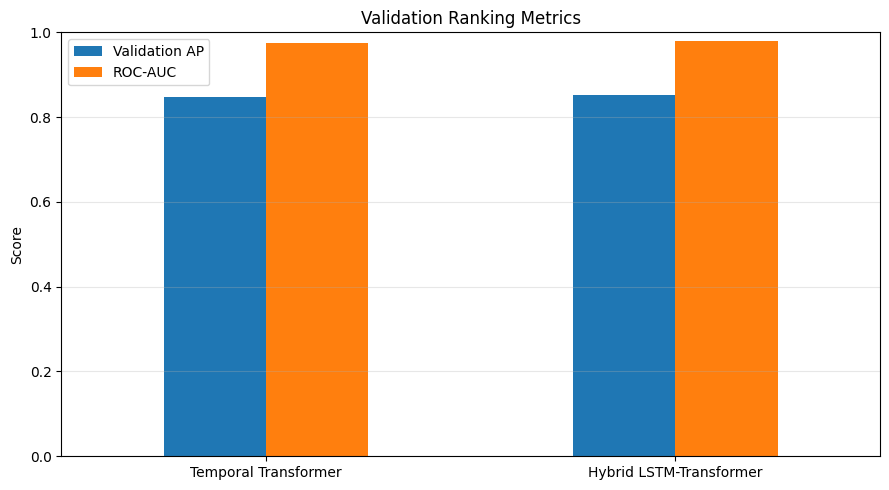

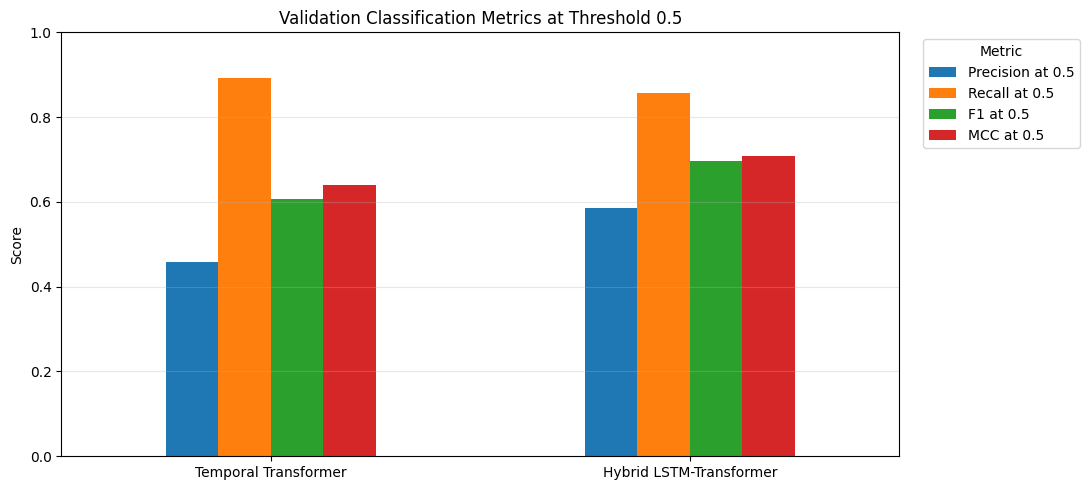


FILES SAVED
CSV:  /content/drive/MyDrive/fraud_detection_models/validation_model_comparison.csv
JSON: /content/drive/MyDrive/fraud_detection_models/validation_model_comparison.json
Test set evaluated: False


In [ ]:
# Stage 6.5: Compare and Save Validation Results

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

TEMPORAL_RESULTS_PATH = os.path.join(
    MODEL_DIR, "temporal_transformer_validation_results.json"
)
HYBRID_RESULTS_PATH = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_validation_results.json"
)

COMPARISON_CSV_PATH = os.path.join(
    MODEL_DIR, "validation_model_comparison.csv"
)
COMPARISON_JSON_PATH = os.path.join(
    MODEL_DIR, "validation_model_comparison.json"
)

# Load saved validation results.
with open(TEMPORAL_RESULTS_PATH, "r") as file:
    temporal = json.load(file)

with open(HYBRID_RESULTS_PATH, "r") as file:
    hybrid = json.load(file)

# Normalize the different JSON structures.
models = {
    "Temporal Transformer": {
        "best_epoch": temporal["best_epoch"],
        "average_precision": temporal["validation_average_precision"],
        "roc_auc": temporal["validation_roc_auc"],
        "default_metrics": temporal["threshold_results"]["default_0.5"],
    },
    "Hybrid LSTM-Transformer": {
        "best_epoch": hybrid["best_epoch"],
        "average_precision": hybrid["average_precision"],
        "roc_auc": hybrid["roc_auc"],
        "default_metrics": hybrid["default_threshold_metrics"],
    },
}

rows = []

for model_name, result in models.items():
    metrics = result["default_metrics"]
    confusion = metrics["confusion_matrix"]

    rows.append({
        "Model": model_name,
        "Best Epoch": result["best_epoch"],
        "Validation AP": result["average_precision"],
        "ROC-AUC": result["roc_auc"],
        "Precision at 0.5": metrics["precision"],
        "Recall at 0.5": metrics["recall"],
        "F1 at 0.5": metrics["f1"],
        "MCC at 0.5": metrics["mcc"],
        "False Positives": confusion[0][1],
        "False Negatives": confusion[1][0],
    })

comparison_df = pd.DataFrame(rows)

# Save comparison table.
comparison_df.to_csv(COMPARISON_CSV_PATH, index=False)

comparison_payload = {
    "evaluation_split": "Validation",
    "common_classification_threshold": 0.5,
    "test_set_evaluated": False,
    "models": models,
    "comparison_table": rows,
}

with open(COMPARISON_JSON_PATH, "w") as file:
    json.dump(comparison_payload, file, indent=4)

# Print the comparison table.
print("VALIDATION MODEL COMPARISON")
print("=" * 100)
print(comparison_df.to_string(
    index=False,
    float_format=lambda value: f"{value:.6f}"
))

# Plot ranking metrics.
ranking_df = comparison_df.set_index("Model")[
    ["Validation AP", "ROC-AUC"]
]

ax = ranking_df.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0,
)

ax.set_title("Validation Ranking Metrics")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot threshold-dependent metrics at threshold 0.5.
threshold_df = comparison_df.set_index("Model")[
    [
        "Precision at 0.5",
        "Recall at 0.5",
        "F1 at 0.5",
        "MCC at 0.5",
    ]
]

ax = threshold_df.plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0,
)

ax.set_title("Validation Classification Metrics at Threshold 0.5")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nFILES SAVED")
print(f"CSV:  {COMPARISON_CSV_PATH}")
print(f"JSON: {COMPARISON_JSON_PATH}")
print("Test set evaluated: False")

In [ ]:
# Stage 7.1: Build Temporal Datasets with Window Size 10

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# Use a larger temporal context for sensitivity analysis.
WINDOW_SIZE_10 = 10
BATCH_SIZE_10 = 256
NUM_WORKERS_10 = 0

class TemporalFraudDatasetV2(Dataset):
    def __init__(
        self,
        X,
        y,
        target_start,
        target_end,
        window_size,
    ):
        self.X = X
        self.y = y
        self.target_start = int(target_start)
        self.target_end = int(target_end)
        self.window_size = int(window_size)

        if self.window_size < 1:
            raise ValueError("window_size must be at least 1.")

        if self.target_start < self.window_size - 1:
            raise ValueError(
                "target_start is too early for the selected window."
            )

        if self.target_end > len(self.X):
            raise ValueError("target_end exceeds the dataset length.")

        if self.target_start >= self.target_end:
            raise ValueError("The target range is empty.")

    def __len__(self):
        return self.target_end - self.target_start

    def __getitem__(self, index):
        target_idx = self.target_start + index
        window_start = target_idx - self.window_size + 1
        window_end = target_idx + 1

        x_window = self.X[window_start:window_end]
        target = self.y[target_idx]

        return (
            torch.as_tensor(x_window, dtype=torch.float32),
            torch.as_tensor(target, dtype=torch.float32),
        )


# Reuse the existing chronological boundaries.
# Validation and test windows may use preceding rows from earlier splits,
# but never include rows occurring after the target transaction.
train_dataset_10 = TemporalFraudDatasetV2(
    X=X_all,
    y=y_all,
    target_start=WINDOW_SIZE_10 - 1,
    target_end=train_end,
    window_size=WINDOW_SIZE_10,
)

validation_dataset_10 = TemporalFraudDatasetV2(
    X=X_all,
    y=y_all,
    target_start=train_end,
    target_end=validation_end,
    window_size=WINDOW_SIZE_10,
)

test_dataset_10 = TemporalFraudDatasetV2(
    X=X_all,
    y=y_all,
    target_start=validation_end,
    target_end=len(X_all),
    window_size=WINDOW_SIZE_10,
)

train_loader_10 = DataLoader(
    train_dataset_10,
    batch_size=BATCH_SIZE_10,
    shuffle=True,
    num_workers=NUM_WORKERS_10,
    pin_memory=torch.cuda.is_available(),
)

validation_loader_10 = DataLoader(
    validation_dataset_10,
    batch_size=BATCH_SIZE_10,
    shuffle=False,
    num_workers=NUM_WORKERS_10,
    pin_memory=torch.cuda.is_available(),
)

test_loader_10 = DataLoader(
    test_dataset_10,
    batch_size=BATCH_SIZE_10,
    shuffle=False,
    num_workers=NUM_WORKERS_10,
    pin_memory=torch.cuda.is_available(),
)


# Verify dataset sizes, tensor shapes, and temporal boundaries.
print("TEMPORAL WINDOW SENSITIVITY: WINDOW SIZE = 10")
print("=" * 60)
print(f"Input features: {X_all.shape[1]}")
print(f"Window size: {WINDOW_SIZE_10}")
print(f"Train samples: {len(train_dataset_10):,}")
print(f"Validation samples: {len(validation_dataset_10):,}")
print(f"Test samples: {len(test_dataset_10):,}")

sample_x, sample_y = train_dataset_10[0]

print(f"\nFirst training sample shape: {tuple(sample_x.shape)}")
print(f"First training target: {int(sample_y.item())}")

sample_x_val, sample_y_val = validation_dataset_10[0]
sample_x_test, sample_y_test = test_dataset_10[0]

print(
    f"First validation target index: {train_end}"
)
print(
    f"First validation window indices: "
    f"{train_end - WINDOW_SIZE_10} to {train_end - 1}"
)
print(
    f"First test target index: {validation_end}"
)
print(
    f"First test window indices: "
    f"{validation_end - WINDOW_SIZE_10} to {validation_end - 1}"
)

assert sample_x.shape == (WINDOW_SIZE_10, X_all.shape[1])
assert len(train_dataset_10) == train_end - WINDOW_SIZE_10 + 1
assert len(validation_dataset_10) == validation_end - train_end
assert len(test_dataset_10) == len(X_all) - validation_end

print("\nDataset and DataLoader verification completed.")
print("No model training performed.")
print("Test labels have not been evaluated.")

TEMPORAL WINDOW SENSITIVITY: WINDOW SIZE = 10
Input features: 30
Window size: 10
Train samples: 199,355
Validation samples: 42,721
Test samples: 42,722

First training sample shape: (10, 30)
First training target: 0
First validation target index: 199364
First validation window indices: 199354 to 199363
First test target index: 242085
First test window indices: 242075 to 242084

Dataset and DataLoader verification completed.
No model training performed.
Test labels have not been evaluated.


In [ ]:
# Stage 7.2a: Inspect the Existing Temporal Transformer Constructor

import inspect

print(inspect.signature(TemporalTransformer.__init__))

(self, input_dim, d_model=64, n_heads=4, num_layers=2, dim_feedforward=128, dropout=0.1, max_len=50)


In [ ]:

# Stage 7.2d: Inspect existing dataset-related objects

print("Dataset-related variables in memory:")
for name in sorted(globals()):
    if "dataset" in name.lower() or "temporal" in name.lower():
        obj = globals()[name]
        if isinstance(obj, type):
            print(f"{name}: class")
        elif not name.startswith("_"):
            print(f"{name}: {type(obj).__name__}")

print("\nData dimensions:")
print("X_all:", X_all.shape)
print("y_all:", y_all.shape)
print("train_end:", train_end)
print("validation_end:", validation_end)

print("\nExisting configuration file:")
config_path = os.path.join(
    MODEL_DIR, "temporal_transformer_window10_config.json"
)
print("Exists:", os.path.isfile(config_path))

if os.path.isfile(config_path):
    with open(config_path, "r") as f:
        print(f.read())


Dataset-related variables in memory:
Dataset: class
TEMPORAL_RESULTS_PATH: str
TemporalFraudDataset: class
TemporalFraudDatasetV2: class
TemporalTransformer: class
dataset: TemporalFraudDataset
dataset_dir: PosixPath
datasets: dict
full_dataset_path: PosixPath
temporal: dict
temporal_transformer: TemporalTransformer
test_dataset: TemporalFraudDataset
test_dataset_10: TemporalFraudDatasetV2
test_dataset_audit: TemporalFraudDataset
train_dataset: TemporalFraudDataset
train_dataset_10: TemporalFraudDatasetV2
train_dataset_audit: TemporalFraudDataset
validation_dataset: TemporalFraudDataset
validation_dataset_10: TemporalFraudDatasetV2
validation_dataset_audit: TemporalFraudDataset

Data dimensions:
X_all: (284807, 30)
y_all: (284807,)
train_end: 199364
validation_end: 242085

Existing configuration file:
Exists: False


In [ ]:

# Stage 7.2f: Check dataset class behavior and existing variables

import inspect

print("Dataset constructor:")
print(inspect.signature(TemporalFraudDataset.__init__))

print("\nDataset instance attributes:")
print(vars(train_dataset))

print("\nDataset class methods:")
print([
    name for name, value in vars(TemporalFraudDataset).items()
    if callable(value) and not name.startswith("__")
])

print("\nExisting preprocessing and training variables:")
for name in [
    "X_all", "y_all", "train_end", "validation_end",
    "INPUT_DIM", "pos_weight", "pos_weight_tensor",
    "criterion", "optimizer", "MAX_EPOCHS", "PATIENCE",
    "train_loader", "validation_loader", "test_loader"
]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")


Dataset constructor:
(self, features, labels, target_start, target_end, window_size)

Dataset instance attributes:
{'features': array([[-1.3598071 , -0.07278118,  2.5363467 , ..., -0.02105305,
         0.24044256, -0.8055286 ],
       [ 1.1918571 ,  0.2661507 ,  0.16648011, ...,  0.01472417,
        -0.34984872, -0.8055286 ],
       [-1.3583541 , -1.3401631 ,  1.7732093 , ..., -0.05975184,
         1.1606108 ,  0.6739282 ],
       ...,
       [ 1.919565  , -0.30125386, -3.2496397 , ..., -0.02656083,
        -0.0879479 ,  0.6739282 ],
       [-0.24044006,  0.53048253,  0.70251024, ...,  0.10453282,
        -0.3204808 , -0.8055286 ],
       [-0.5334125 , -0.18973334,  0.7033374 , ...,  0.01364891,
         0.5111417 ,  2.6296637 ]], shape=(284807, 30), dtype=float32), 'labels': array([0, 0, 0, ..., 0, 0, 0], shape=(284807,)), 'target_start': 4, 'target_end': 199364, 'window_size': 5}

Dataset class methods:
[]

Existing preprocessing and training variables:
X_all: Available
y_all: Availa

In [ ]:

# Stage 7.3: Rebuild window-10 datasets using the original class

import os
import json
import torch
from torch.utils.data import DataLoader

WINDOW_SIZE_10 = 10
BATCH_SIZE_W10 = 256
NUM_WORKERS_W10 = 0

# Preserve the original chronological split.
train_dataset_10 = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=WINDOW_SIZE_10 - 1,
    target_end=train_end,
    window_size=WINDOW_SIZE_10
)

validation_dataset_10 = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=train_end,
    target_end=validation_end,
    window_size=WINDOW_SIZE_10
)

test_dataset_10 = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=validation_end,
    target_end=len(y_all),
    window_size=WINDOW_SIZE_10
)

train_loader_10 = DataLoader(
    train_dataset_10,
    batch_size=BATCH_SIZE_W10,
    shuffle=True,
    num_workers=NUM_WORKERS_W10
)

validation_loader_10 = DataLoader(
    validation_dataset_10,
    batch_size=BATCH_SIZE_W10,
    shuffle=False,
    num_workers=NUM_WORKERS_W10
)

test_loader_10 = DataLoader(
    test_dataset_10,
    batch_size=BATCH_SIZE_W10,
    shuffle=False,
    num_workers=NUM_WORKERS_W10
)

print("WINDOW SIZE 10 — DATASET VERIFICATION")
print("-" * 45)
print(f"Train samples:      {len(train_dataset_10):,}")
print(f"Validation samples: {len(validation_dataset_10):,}")
print(f"Test samples:       {len(test_dataset_10):,}")
print("Training window shape:", train_dataset_10[0][0].shape)
print("Training target index range:",
      train_dataset_10.target_start,
      "to", train_dataset_10.target_end - 1)
print("Validation target index range:",
      validation_dataset_10.target_start,
      "to", validation_dataset_10.target_end - 1)
print("Test target index range:",
      test_dataset_10.target_start,
      "to", test_dataset_10.target_end - 1)

print("\nValidation first window starts at:",
      validation_dataset_10.target_start - WINDOW_SIZE_10 + 1)
print("Test first window starts at:",
      test_dataset_10.target_start - WINDOW_SIZE_10 + 1)

print("\nNo model training performed.")
print("Test labels have not been evaluated.")


WINDOW SIZE 10 — DATASET VERIFICATION
---------------------------------------------
Train samples:      199,355
Validation samples: 42,721
Test samples:       42,722
Training window shape: torch.Size([10, 30])
Training target index range: 9 to 199363
Validation target index range: 199364 to 242084
Test target index range: 242085 to 284806

Validation first window starts at: 199355
Test first window starts at: 242076

No model training performed.
Test labels have not been evaluated.


## Tempral Transformer w=10

In [ ]:

# Stage 7.4: Train Temporal Transformer with window size 10

import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score, roc_auc_score
from tqdm.auto import tqdm

# Reproducibility
SEED_W10 = 42
random.seed(SEED_W10)
np.random.seed(SEED_W10)
torch.manual_seed(SEED_W10)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_W10)

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"
os.makedirs(MODEL_DIR, exist_ok=True)

CHECKPOINT_W10 = os.path.join(
    MODEL_DIR, "temporal_transformer_window10_best.pt"
)
HISTORY_W10 = os.path.join(
    MODEL_DIR, "temporal_transformer_window10_training_history.json"
)
CONFIG_W10 = os.path.join(
    MODEL_DIR, "temporal_transformer_window10_config.json"
)
RESULTS_W10 = os.path.join(
    MODEL_DIR, "temporal_transformer_window10_validation_results.json"
)

# Use the same architecture as the window-5 model.
temporal_transformer_w10 = TemporalTransformer(
    input_dim=INPUT_DIM,
    d_model=64,
    n_heads=4,
    num_layers=2,
    dim_feedforward=128,
    dropout=0.1,
    max_len=50
).to(device)

LEARNING_RATE_W10 = 1e-3
WEIGHT_DECAY_W10 = 1e-4
MAX_EPOCHS_W10 = 30
PATIENCE_W10 = 5
GRAD_CLIP_W10 = 1.0

# Reuse the existing class-weighted loss.
criterion_w10 = criterion
optimizer_w10 = torch.optim.AdamW(
    temporal_transformer_w10.parameters(),
    lr=LEARNING_RATE_W10,
    weight_decay=WEIGHT_DECAY_W10
)

history_w10 = []
best_ap_w10 = -1.0
best_epoch_w10 = 0
epochs_without_improvement_w10 = 0

print("TEMPORAL TRANSFORMER — WINDOW SIZE 10")
print("-" * 55)
print("Device:", device)
print("Train samples:", f"{len(train_dataset_10):,}")
print("Validation samples:", f"{len(validation_dataset_10):,}")
print("Maximum epochs:", MAX_EPOCHS_W10)
print("Selection metric: Validation Average Precision")

for epoch in range(1, MAX_EPOCHS_W10 + 1):
    temporal_transformer_w10.train()
    running_loss = 0.0
    seen_samples = 0

    progress = tqdm(
        train_loader_10,
        desc=f"Epoch {epoch}/{MAX_EPOCHS_W10}",
        leave=False
    )

    for batch_x, batch_y in progress:
        batch_x = batch_x.to(device, dtype=torch.float32)
        batch_y = batch_y.to(device, dtype=torch.float32).view(-1)

        optimizer_w10.zero_grad(set_to_none=True)

        logits = temporal_transformer_w10(batch_x).view(-1)
        loss = criterion_w10(logits, batch_y)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            temporal_transformer_w10.parameters(),
            GRAD_CLIP_W10
        )
        optimizer_w10.step()

        batch_size_actual = batch_y.size(0)
        running_loss += loss.item() * batch_size_actual
        seen_samples += batch_size_actual

    train_loss = running_loss / seen_samples

    # Validation only; the test loader is not used here.
    temporal_transformer_w10.eval()
    validation_probabilities = []
    validation_labels = []

    with torch.no_grad():
        for batch_x, batch_y in validation_loader_10:
            batch_x = batch_x.to(device, dtype=torch.float32)
            logits = temporal_transformer_w10(batch_x).view(-1)
            probabilities = torch.sigmoid(logits)

            validation_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )
            validation_labels.extend(
                batch_y.cpu().numpy().reshape(-1).tolist()
            )

    validation_ap = average_precision_score(
        validation_labels, validation_probabilities
    )
    validation_auc = roc_auc_score(
        validation_labels, validation_probabilities
    )

    epoch_record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "validation_average_precision": float(validation_ap),
        "validation_roc_auc": float(validation_auc)
    }
    history_w10.append(epoch_record)

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val AP: {validation_ap:.6f} | "
        f"Val ROC-AUC: {validation_auc:.6f}"
    )

    if validation_ap > best_ap_w10:
        best_ap_w10 = float(validation_ap)
        best_epoch_w10 = epoch
        epochs_without_improvement_w10 = 0

        torch.save(
            {
                "model_state_dict": temporal_transformer_w10.state_dict(),
                "input_dim": INPUT_DIM,
                "window_size": WINDOW_SIZE_10,
                "best_epoch": best_epoch_w10,
                "best_validation_average_precision": best_ap_w10,
                "seed": SEED_W10
            },
            CHECKPOINT_W10
        )

        print("  Best checkpoint saved.")
    else:
        epochs_without_improvement_w10 += 1

    # Save history after every epoch so progress survives interruptions.
    with open(HISTORY_W10, "w") as f:
        json.dump(history_w10, f, indent=2)

    if epochs_without_improvement_w10 >= PATIENCE_W10:
        print(f"Early stopping at epoch {epoch}.")
        break

config_w10 = {
    "model_name": "Temporal Transformer",
    "window_size": WINDOW_SIZE_10,
    "input_dim": INPUT_DIM,
    "d_model": 64,
    "n_heads": 4,
    "num_layers": 2,
    "dim_feedforward": 128,
    "dropout": 0.1,
    "learning_rate": LEARNING_RATE_W10,
    "weight_decay": WEIGHT_DECAY_W10,
    "max_epochs": MAX_EPOCHS_W10,
    "patience": PATIENCE_W10,
    "gradient_clip_norm": GRAD_CLIP_W10,
    "seed": SEED_W10,
    "selection_metric": "validation_average_precision",
    "best_epoch": best_epoch_w10,
    "best_validation_average_precision": best_ap_w10
}

with open(CONFIG_W10, "w") as f:
    json.dump(config_w10, f, indent=2)

print("\nTraining completed.")
print("Best epoch:", best_epoch_w10)
print("Best validation AP:", f"{best_ap_w10:.6f}")
print("Checkpoint exists:", os.path.isfile(CHECKPOINT_W10))
print("History saved:", os.path.isfile(HISTORY_W10))
print("Configuration saved:", os.path.isfile(CONFIG_W10))
print("Test set was not evaluated.")


TEMPORAL TRANSFORMER — WINDOW SIZE 10
-------------------------------------------------------
Device: cuda
Train samples: 199,355
Validation samples: 42,721
Maximum epochs: 30
Selection metric: Validation Average Precision


Epoch 1/30:   0%|          | 0/779 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.713101 | Val AP: 0.837182 | Val ROC-AUC: 0.980686
  Best checkpoint saved.


Epoch 2/30:   0%|          | 0/779 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.609975 | Val AP: 0.855494 | Val ROC-AUC: 0.984931
  Best checkpoint saved.


Epoch 3/30:   0%|          | 0/779 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/30:   0%|          | 0/779 [00:00<?, ?it/s]

Epoch 10 | Train Loss: 0.354256 | Val AP: 0.843219 | Val ROC-AUC: 0.964355


Epoch 11/30:   0%|          | 0/779 [00:00<?, ?it/s]

Epoch 11 | Train Loss: 0.347601 | Val AP: 0.818414 | Val ROC-AUC: 0.957338
Early stopping at epoch 11.

Training completed.
Best epoch: 6
Best validation AP: 0.860858
Checkpoint exists: True
History saved: True
Configuration saved: True
Test set was not evaluated.


In [ ]:

# Stage 7.5: Evaluate the best window-10 checkpoint on validation

import os
import json
import numpy as np
import torch
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

CHECKPOINT_W10 = os.path.join(
    MODEL_DIR, "temporal_transformer_window10_best.pt"
)
RESULTS_W10 = os.path.join(
    MODEL_DIR, "temporal_transformer_window10_validation_results.json"
)

checkpoint_w10 = torch.load(
    CHECKPOINT_W10,
    map_location=device,
    weights_only=False
)

temporal_transformer_w10.load_state_dict(
    checkpoint_w10["model_state_dict"]
)
temporal_transformer_w10.eval()

val_probs_w10 = []
val_labels_w10 = []

with torch.no_grad():
    for batch_x, batch_y in validation_loader_10:
        batch_x = batch_x.to(device, dtype=torch.float32)

        logits = temporal_transformer_w10(batch_x).view(-1)
        probs = torch.sigmoid(logits)

        val_probs_w10.extend(probs.cpu().numpy().tolist())
        val_labels_w10.extend(
            batch_y.cpu().numpy().reshape(-1).tolist()
        )

val_probs_w10 = np.asarray(val_probs_w10)
val_labels_w10 = np.asarray(val_labels_w10).astype(int)

pred_05_w10 = (val_probs_w10 >= 0.5).astype(int)

results_w10 = {
    "model": "Temporal Transformer",
    "window_size": 10,
    "best_epoch": int(checkpoint_w10["best_epoch"]),
    "average_precision": float(
        average_precision_score(val_labels_w10, val_probs_w10)
    ),
    "roc_auc": float(
        roc_auc_score(val_labels_w10, val_probs_w10)
    ),
    "threshold_0.5": {
        "precision": float(
            precision_score(val_labels_w10, pred_05_w10, zero_division=0)
        ),
        "recall": float(
            recall_score(val_labels_w10, pred_05_w10, zero_division=0)
        ),
        "f1": float(
            f1_score(val_labels_w10, pred_05_w10, zero_division=0)
        ),
        "mcc": float(
            matthews_corrcoef(val_labels_w10, pred_05_w10)
        ),
        "confusion_matrix": confusion_matrix(
            val_labels_w10, pred_05_w10
        ).tolist()
    },
    "validation_samples": int(len(val_labels_w10)),
    "validation_fraud_cases": int(val_labels_w10.sum())
}

with open(RESULTS_W10, "w") as f:
    json.dump(results_w10, f, indent=2)

print("WINDOW-10 VALIDATION RESULTS")
print("-" * 45)
print("Best epoch:", results_w10["best_epoch"])
print(f"Average Precision: {results_w10['average_precision']:.6f}")
print(f"ROC-AUC:           {results_w10['roc_auc']:.6f}")
print("\nThreshold = 0.5")
for metric, value in results_w10["threshold_0.5"].items():
    print(f"{metric}: {value}")

print("\nValidation fraud cases:", results_w10["validation_fraud_cases"])
print("Results saved:", os.path.isfile(RESULTS_W10))
print("Test set was not evaluated.")


WINDOW-10 VALIDATION RESULTS
---------------------------------------------
Best epoch: 6
Average Precision: 0.860858
ROC-AUC:           0.982473

Threshold = 0.5
precision: 0.676056338028169
recall: 0.8571428571428571
f1: 0.7559055118110236
mcc: 0.7608887792176485
confusion_matrix: [[42642, 23], [8, 48]]

Validation fraud cases: 56
Results saved: True
Test set was not evaluated.


In [ ]:

# Stage 7.6: Inspect the hybrid model constructor

import inspect
import os

print("Hybrid model class available:",
      "HybridLSTMTransformer" in globals())

if "HybridLSTMTransformer" in globals():
    print(
        "Constructor:",
        inspect.signature(HybridLSTMTransformer.__init__)
    )
else:
    print("The class definition needs to be restored.")

print("\nWindow-10 Temporal Transformer checkpoint:",
      os.path.isfile(
          os.path.join(
              MODEL_DIR,
              "temporal_transformer_window10_best.pt"
          )
      ))

print("Window-10 validation results:",
      os.path.isfile(
          os.path.join(
              MODEL_DIR,
              "temporal_transformer_window10_validation_results.json"
          )
      ))


Hybrid model class available: True
Constructor: (self, input_dim, lstm_hidden_dim=64, num_lstm_layers=1, num_heads=4, num_transformer_layers=2, feedforward_dim=128, dropout=0.1, max_len=512)

Window-10 Temporal Transformer checkpoint: True
Window-10 validation results: True


In [ ]:

# Stage 7.7: Search for the saved hybrid model definition

import os

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

print("Files in model directory:")
for filename in sorted(os.listdir(MODEL_DIR)):
    print(filename)

print("\nNotebook files in the current directory:")
for filename in os.listdir("/content"):
    if filename.endswith(".ipynb") or filename.endswith(".py"):
        print(filename)

print("\nHybrid checkpoint configuration:")
import json

config_path = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_config.json"
)

if os.path.isfile(config_path):
    with open(config_path, "r") as f:
        print(json.dumps(json.load(f), indent=2))
else:
    print("Hybrid configuration file not found.")


Files in model directory:
hybrid_lstm_transformer_best.pt
hybrid_lstm_transformer_config.json
hybrid_lstm_transformer_training_history.json
hybrid_lstm_transformer_validation_results.json
logistic_regression_validation_probabilities.npy
tabular_baselines_validation.csv
temporal_transformer_best.pt
temporal_transformer_config.json
temporal_transformer_training_history.json
temporal_transformer_validation_results.json
temporal_transformer_window10_best.pt
temporal_transformer_window10_config.json
temporal_transformer_window10_training_history.json
temporal_transformer_window10_validation_results.json
validation_model_comparison.csv
validation_model_comparison.json
xgboost_validation_probabilities.npy

Notebook files in the current directory:

Hybrid checkpoint configuration:
{
  "model_name": "Hybrid LSTM-Transformer",
  "input_dim": 30,
  "lstm_hidden_dim": 64,
  "num_lstm_layers": 1,
  "num_heads": 4,
  "num_transformer_layers": 2,
  "feedforward_dim": 128,
  "dropout": 0.1,
  "window_

In [ ]:

# Stage 7.8: Inspect the saved Hybrid LSTM-Transformer checkpoint

import os
import torch

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"
checkpoint_path = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("\nTop-level keys:")
    for key in checkpoint.keys():
        print("-", key)

    # Identify the saved model weights
    state_dict = None

    for key in ["model_state_dict", "state_dict", "model"]:
        if key in checkpoint and isinstance(checkpoint[key], dict):
            state_dict = checkpoint[key]
            print("\nWeights found under:", key)
            break

    if state_dict is None and all(
        isinstance(value, torch.Tensor)
        for value in checkpoint.values()
    ):
        state_dict = checkpoint
        print("\nCheckpoint itself contains the model weights.")

    if state_dict is not None:
        print("\nSaved parameter names and shapes:")
        for name, tensor in state_dict.items():
            if isinstance(tensor, torch.Tensor):
                print(f"{name}: {tuple(tensor.shape)}")
            else:
                print(f"{name}: {type(tensor).__name__}")
    else:
        print("\nCould not identify the model state_dict.")
else:
    print("Checkpoint is not a dictionary.")


Checkpoint type: dict

Top-level keys:
- epoch
- model_state_dict
- optimizer_state_dict
- best_validation_ap
- config

Weights found under: model_state_dict

Saved parameter names and shapes:
positional_encoding: (1, 512, 64)
lstm.weight_ih_l0: (256, 30)
lstm.weight_hh_l0: (256, 64)
lstm.bias_ih_l0: (256,)
lstm.bias_hh_l0: (256,)
transformer_encoder.layers.0.self_attn.in_proj_weight: (192, 64)
transformer_encoder.layers.0.self_attn.in_proj_bias: (192,)
transformer_encoder.layers.0.self_attn.out_proj.weight: (64, 64)
transformer_encoder.layers.0.self_attn.out_proj.bias: (64,)
transformer_encoder.layers.0.linear1.weight: (128, 64)
transformer_encoder.layers.0.linear1.bias: (128,)
transformer_encoder.layers.0.linear2.weight: (64, 128)
transformer_encoder.layers.0.linear2.bias: (64,)
transformer_encoder.layers.0.norm1.weight: (64,)
transformer_encoder.layers.0.norm1.bias: (64,)
transformer_encoder.layers.0.norm2.weight: (64,)
transformer_encoder.layers.0.norm2.bias: (64,)
transformer_enco

In [ ]:

# Stage 7.9: Restore Hybrid LSTM-Transformer and verify its checkpoint

import os
import json
import math
import torch
import torch.nn as nn

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"
checkpoint_path = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_best.pt"
)
config_path = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_config.json"
)

with open(config_path, "r") as f:
    hybrid_config = json.load(f)

class HybridLSTMTransformer(nn.Module):
    def __init__(
        self,
        input_dim=30,
        lstm_hidden_dim=64,
        num_lstm_layers=1,
        num_heads=4,
        num_transformer_layers=2,
        feedforward_dim=128,
        dropout=0.1,
        max_len=512
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=lstm_hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=dropout if num_lstm_layers > 1 else 0.0
        )

        self.positional_encoding = nn.Parameter(
            self._make_positional_encoding(
                max_len, lstm_hidden_dim
            ),
            requires_grad=False
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=lstm_hidden_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            batch_first=True,
            norm_first=True
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_transformer_layers
        )

        self.output_norm = nn.LayerNorm(lstm_hidden_dim)
        self.classifier = nn.Linear(lstm_hidden_dim, 1)

    @staticmethod
    def _make_positional_encoding(max_len, d_model):
        position = torch.arange(
            max_len, dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        return pe.unsqueeze(0)

    def forward(self, x):
        # x shape: (batch, sequence_length, input_dim)
        lstm_output, _ = self.lstm(x)

        sequence_length = lstm_output.size(1)
        lstm_output = (
            lstm_output
            + self.positional_encoding[:, :sequence_length, :]
        )

        transformer_output = self.transformer_encoder(lstm_output)
        final_step = transformer_output[:, -1, :]
        final_step = self.output_norm(final_step)

        # Return logits, not probabilities
        return self.classifier(final_step).squeeze(-1)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

hybrid_model = HybridLSTMTransformer(
    input_dim=hybrid_config["input_dim"],
    lstm_hidden_dim=hybrid_config["lstm_hidden_dim"],
    num_lstm_layers=hybrid_config["num_lstm_layers"],
    num_heads=hybrid_config["num_heads"],
    num_transformer_layers=hybrid_config["num_transformer_layers"],
    feedforward_dim=hybrid_config["feedforward_dim"],
    dropout=hybrid_config["dropout"]
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

incompatibilities = hybrid_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

hybrid_model = hybrid_model.to(device)
hybrid_model.eval()

print("Checkpoint loaded successfully.")
print("Device:", device)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Saved best validation AP:", checkpoint["best_validation_ap"])
print("Model parameters:", sum(
    p.numel() for p in hybrid_model.parameters()
))
print("Missing keys:", incompatibilities.missing_keys)
print("Unexpected keys:", incompatibilities.unexpected_keys)

# Verify the forward pass using a dummy batch
with torch.no_grad():
    dummy_input = torch.zeros(
        4, 5, hybrid_config["input_dim"], device=device
    )
    dummy_output = hybrid_model(dummy_input)

print("Dummy input shape:", tuple(dummy_input.shape))
print("Dummy output shape:", tuple(dummy_output.shape))
print("Outputs are finite:", torch.isfinite(dummy_output).all().item())


Checkpoint loaded successfully.
Device: cuda
Checkpoint epoch: 2
Saved best validation AP: 0.8524845656615044
Model parameters: 124481
Missing keys: []
Unexpected keys: []
Dummy input shape: (4, 5, 30)
Dummy output shape: (4,)
Outputs are finite: True


/tmp/ipykernel_188/2403624959.py:58: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer_encoder = nn.TransformerEncoder(


In [ ]:

# Stage 7.11: Prepare Hybrid LSTM-Transformer for window size 10

import os
import json
import torch
from torch.utils.data import DataLoader

WINDOW_SIZE_10 = 10
MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

train_dataset_10 = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=WINDOW_SIZE_10 - 1,
    target_end=train_end,
    window_size=WINDOW_SIZE_10
)

validation_dataset_10 = TemporalFraudDataset(
    features=X_all,
    labels=y_all,
    target_start=train_end,
    target_end=validation_end,
    window_size=WINDOW_SIZE_10
)

train_loader_10 = DataLoader(
    train_dataset_10,
    batch_size=256,
    shuffle=True,
    num_workers=0
)

validation_loader_10 = DataLoader(
    validation_dataset_10,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

print("Window-10 datasets ready.")
print("Train samples:", len(train_dataset_10))
print("Validation samples:", len(validation_dataset_10))
print("Input shape:", train_dataset_10[0][0].shape)
print("Validation labels:", int(validation_dataset_10.labels[
    validation_dataset_10.target_start:validation_dataset_10.target_end
].sum()))
print("Model directory exists:", os.path.isdir(MODEL_DIR))


Window-10 datasets ready.
Train samples: 199355
Validation samples: 42721
Input shape: torch.Size([10, 30])
Validation labels: 56
Model directory exists: True


## Hybrid LSTM-Transformer w=10

In [ ]:

# Stage 7.12: Train Hybrid LSTM-Transformer with window size 10

import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
from torch.optim import AdamW
from sklearn.metrics import average_precision_score, roc_auc_score
from tqdm.auto import tqdm

SEED = 42
MAX_EPOCHS = 30
PATIENCE = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

hybrid_model_10 = HybridLSTMTransformer(
    input_dim=hybrid_config["input_dim"],
    lstm_hidden_dim=hybrid_config["lstm_hidden_dim"],
    num_lstm_layers=hybrid_config["num_lstm_layers"],
    num_heads=hybrid_config["num_heads"],
    num_transformer_layers=hybrid_config["num_transformer_layers"],
    feedforward_dim=hybrid_config["feedforward_dim"],
    dropout=hybrid_config["dropout"]
).to(device)

optimizer_10 = AdamW(
    hybrid_model_10.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion_10 = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor.to(device)
)

best_val_ap_10 = -1.0
best_epoch_10 = 0
epochs_without_improvement_10 = 0
history_10 = []

checkpoint_path_10 = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_window10_best.pt"
)
history_path_10 = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_window10_training_history.json"
)
config_path_10 = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_window10_config.json"
)
results_path_10 = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_window10_validation_results.json"
)

config_10 = {
    **hybrid_config,
    "window_size": WINDOW_SIZE_10,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "gradient_clip_norm": GRADIENT_CLIP_NORM,
    "seed": SEED,
    "selection_metric": "validation_average_precision"
}

with open(config_path_10, "w") as f:
    json.dump(config_10, f, indent=2)

for epoch in range(1, MAX_EPOCHS + 1):
    hybrid_model_10.train()
    train_loss_sum = 0.0
    train_samples_seen = 0

    progress = tqdm(
        train_loader_10,
        desc=f"Epoch {epoch}/{MAX_EPOCHS}",
        leave=False
    )

    for batch_x, batch_y in progress:
        batch_x = batch_x.to(device, dtype=torch.float32)
        batch_y = batch_y.to(device, dtype=torch.float32)

        optimizer_10.zero_grad(set_to_none=True)

        logits = hybrid_model_10(batch_x)
        loss = criterion_10(logits, batch_y)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            hybrid_model_10.parameters(),
            GRADIENT_CLIP_NORM
        )
        optimizer_10.step()

        batch_size = batch_y.size(0)
        train_loss_sum += loss.item() * batch_size
        train_samples_seen += batch_size

    train_loss = train_loss_sum / train_samples_seen

    # Validation only; test set is not used.
    hybrid_model_10.eval()
    validation_probabilities = []
    validation_labels = []

    with torch.no_grad():
        for batch_x, batch_y in validation_loader_10:
            batch_x = batch_x.to(device, dtype=torch.float32)
            logits = hybrid_model_10(batch_x)
            probabilities = torch.sigmoid(logits)

            validation_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )
            validation_labels.extend(
                batch_y.cpu().numpy().tolist()
            )

    val_ap = average_precision_score(
        validation_labels, validation_probabilities
    )
    val_roc_auc = roc_auc_score(
        validation_labels, validation_probabilities
    )

    epoch_record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "validation_average_precision": float(val_ap),
        "validation_roc_auc": float(val_roc_auc)
    }
    history_10.append(epoch_record)

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val AP: {val_ap:.6f} | "
        f"Val ROC-AUC: {val_roc_auc:.6f}"
    )

    if val_ap > best_val_ap_10:
        best_val_ap_10 = val_ap
        best_epoch_10 = epoch
        epochs_without_improvement_10 = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": hybrid_model_10.state_dict(),
                "optimizer_state_dict": optimizer_10.state_dict(),
                "best_validation_ap": float(best_val_ap_10),
                "config": config_10
            },
            checkpoint_path_10
        )

        with open(results_path_10, "w") as f:
            json.dump(
                {
                    "best_epoch": best_epoch_10,
                    "best_validation_average_precision": float(
                        best_val_ap_10
                    ),
                    "validation_roc_auc_at_best_ap_epoch": float(
                        val_roc_auc
                    ),
                    "selection_metric": "validation_average_precision"
                },
                f,
                indent=2
            )
    else:
        epochs_without_improvement_10 += 1

    with open(history_path_10, "w") as f:
        json.dump(history_10, f, indent=2)

    if epochs_without_improvement_10 >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

print("\nTraining finished.")
print("Best epoch:", best_epoch_10)
print("Best validation AP:", round(best_val_ap_10, 6))
print("Checkpoint saved:", os.path.isfile(checkpoint_path_10))
print("Training history saved:", os.path.isfile(history_path_10))


/tmp/ipykernel_188/2403624959.py:58: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer_encoder = nn.TransformerEncoder(


Epoch 1/30:   0%|          | 0/779 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.86328 | Val AP: 0.847566 | Val ROC-AUC: 0.972641


Epoch 2/30:   0%|          | 0/779 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.61870 | Val AP: 0.800610 | Val ROC-AUC: 0.963076


Epoch 3/30:   0%|          | 0/779 [00:00<?, ?it/s]

... (3 outputs left out)

Epoch 5/30:   0%|          | 0/779 [00:00<?, ?it/s]

Epoch 05 | Train Loss: 0.35412 | Val AP: 0.787427 | Val ROC-AUC: 0.966023


Epoch 6/30:   0%|          | 0/779 [00:00<?, ?it/s]

Epoch 06 | Train Loss: 0.28475 | Val AP: 0.800980 | Val ROC-AUC: 0.956174
Early stopping at epoch 6.

Training finished.
Best epoch: 1
Best validation AP: 0.847566
Checkpoint saved: True
Training history saved: True


In [ ]:

# Stage 7.13: Evaluate the best Hybrid window-10 checkpoint on validation

import os
import json
import numpy as np
import torch
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

checkpoint_path_10 = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_window10_best.pt"
)

checkpoint_10 = torch.load(
    checkpoint_path_10,
    map_location=device,
    weights_only=False
)

hybrid_model_10.load_state_dict(
    checkpoint_10["model_state_dict"],
    strict=True
)
hybrid_model_10.eval()

y_val_10 = []
prob_val_10 = []

with torch.no_grad():
    for batch_x, batch_y in validation_loader_10:
        batch_x = batch_x.to(device, dtype=torch.float32)

        logits = hybrid_model_10(batch_x)
        probabilities = torch.sigmoid(logits)

        y_val_10.extend(batch_y.cpu().numpy().astype(int).tolist())
        prob_val_10.extend(probabilities.cpu().numpy().tolist())

y_val_10 = np.asarray(y_val_10)
prob_val_10 = np.asarray(prob_val_10)

threshold = 0.5
pred_val_10 = (prob_val_10 >= threshold).astype(int)

results_hybrid_10 = {
    "model": "Hybrid LSTM-Transformer",
    "window_size": 10,
    "best_epoch": int(checkpoint_10["epoch"]),
    "validation_average_precision": float(
        average_precision_score(y_val_10, prob_val_10)
    ),
    "validation_roc_auc": float(
        roc_auc_score(y_val_10, prob_val_10)
    ),
    "threshold": threshold,
    "precision": float(
        precision_score(y_val_10, pred_val_10, zero_division=0)
    ),
    "recall": float(
        recall_score(y_val_10, pred_val_10, zero_division=0)
    ),
    "f1": float(f1_score(y_val_10, pred_val_10, zero_division=0)),
    "mcc": float(matthews_corrcoef(y_val_10, pred_val_10)),
    "confusion_matrix": confusion_matrix(
        y_val_10, pred_val_10, labels=[0, 1]
    ).tolist()
}

results_path_10 = os.path.join(
    MODEL_DIR, "hybrid_lstm_transformer_window10_validation_results.json"
)

with open(results_path_10, "w") as f:
    json.dump(results_hybrid_10, f, indent=2)

print(json.dumps(results_hybrid_10, indent=2))
print("\nValidation results saved.")


{
  "model": "Hybrid LSTM-Transformer",
  "window_size": 10,
  "best_epoch": 1,
  "validation_average_precision": 0.8475662418454509,
  "validation_roc_auc": 0.9726406723476922,
  "threshold": 0.5,
  "precision": 0.7272727272727273,
  "recall": 0.8571428571428571,
  "f1": 0.7868852459016393,
  "mcc": 0.7892459148405484,
  "confusion_matrix": [
    [
      42647,
      18
    ],
    [
      8,
      48
    ]
  ]
}

Validation results saved.


In [ ]:

# Stage 7.14: Build a consolidated validation comparison

import os
import json
import pandas as pd

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

result_files = {
    "Temporal Transformer | Window 5":
        "temporal_transformer_validation_results.json",
    "Hybrid LSTM-Transformer | Window 5":
        "hybrid_lstm_transformer_validation_results.json",
    "Temporal Transformer | Window 10":
        "temporal_transformer_window10_validation_results.json",
    "Hybrid LSTM-Transformer | Window 10":
        "hybrid_lstm_transformer_window10_validation_results.json",
}

rows = []

for model_name, filename in result_files.items():
    path = os.path.join(MODEL_DIR, filename)

    if not os.path.isfile(path):
        print("Missing file:", filename)
        continue

    with open(path, "r") as f:
        result = json.load(f)

    rows.append({
        "Model": model_name,
        "Window": result.get("window_size", 5),
        "Best Epoch": result.get(
            "best_epoch",
            result.get("best_epoch_at_best_ap")
        ),
        "Validation AP": result.get(
            "validation_average_precision",
            result.get("best_validation_ap")
        ),
        "Validation ROC-AUC": result.get(
            "validation_roc_auc",
            result.get("validation_roc_auc_at_best_ap_epoch")
        ),
        "Precision @ 0.5": result.get("precision"),
        "Recall @ 0.5": result.get("recall"),
        "F1 @ 0.5": result.get("f1"),
        "MCC @ 0.5": result.get("mcc"),
        "Confusion Matrix": str(result.get("confusion_matrix"))
    })

comparison_df = pd.DataFrame(rows)

csv_path = os.path.join(
    MODEL_DIR, "validation_model_comparison_all_windows.csv"
)
json_path = os.path.join(
    MODEL_DIR, "validation_model_comparison_all_windows.json"
)

comparison_df.to_csv(csv_path, index=False)
comparison_df.to_json(
    json_path, orient="records", indent=2
)

display(comparison_df)
print("\nSaved:", csv_path)
print("Saved:", json_path)


,Model,Window,Best Epoch,Validation AP,Validation ROC-AUC,Precision @ 0.5,Recall @ 0.5,F1 @ 0.5,MCC @ 0.5,Confusion Matrix
0,Temporal Transformer | Window 5,5,5,0.848627,0.974440,NaN,NaN,NaN,NaN,None
1,Hybrid LSTM-Transformer | Window 5,5,2,NaN,NaN,NaN,NaN,NaN,NaN,None
2,Temporal Transformer | Window 10,10,6,NaN,NaN,NaN,NaN,NaN,NaN,None
3,Hybrid LSTM-Transformer | Window 10,10,1,0.847566,0.972641,0.727273,0.857143,0.786885,0.789246,"[[42647, 18], [8, 48]]"



Saved: /content/drive/MyDrive/fraud_detection_models/validation_model_comparison_all_windows.csv
Saved: /content/drive/MyDrive/fraud_detection_models/validation_model_comparison_all_windows.json


In [ ]:

# Stage 7.15: Inspect saved validation-result files
# No training; no test-set evaluation.

import os
import json

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

files_to_check = [
    "temporal_transformer_validation_results.json",
    "hybrid_lstm_transformer_validation_results.json",
    "temporal_transformer_window10_validation_results.json",
    "hybrid_lstm_transformer_window10_validation_results.json",
]

for filename in files_to_check:
    path = os.path.join(MODEL_DIR, filename)
    print("\n" + "=" * 70)
    print(filename)

    if not os.path.isfile(path):
        print("FILE NOT FOUND")
        continue

    with open(path, "r") as f:
        data = json.load(f)

    print(json.dumps(data, indent=2))



temporal_transformer_validation_results.json
{
  "checkpoint": "/content/drive/MyDrive/fraud_detection_models/temporal_transformer_best.pt",
  "best_epoch": 5,
  "validation_average_precision": 0.8486267378386687,
  "validation_roc_auc": 0.9744395707421607,
  "validation_samples": 42721,
  "validation_fraud_cases": 56,
  "threshold_results": {
    "default_0.5": {
      "threshold": 0.5,
      "precision": 0.45871559633027525,
      "recall": 0.8928571428571429,
      "f1": 0.6060606060606061,
      "mcc": 0.6393806611758465,
      "confusion_matrix": [
        [
          42606,
          59
        ],
        [
          6,
          50
        ]
      ]
    },
    "validation_f1_optimal": {
      "threshold": 0.9994956254959106,
      "precision": 0.9555555555555556,
      "recall": 0.7678571428571429,
      "f1": 0.8514851485148515,
      "mcc": 0.856417815255487,
      "confusion_matrix": [
        [
          42663,
          2
        ],
        [
          13,
          43
   

In [ ]:

# Stage 7.16: Create one standardized validation report
# Reads saved JSON results only. No training. No test evaluation.

import os
import json
import pandas as pd

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

result_files = [
    ("Temporal Transformer", 5,
     "temporal_transformer_validation_results.json"),
    ("Hybrid LSTM-Transformer", 5,
     "hybrid_lstm_transformer_validation_results.json"),
    ("Temporal Transformer", 10,
     "temporal_transformer_window10_validation_results.json"),
    ("Hybrid LSTM-Transformer", 10,
     "hybrid_lstm_transformer_window10_validation_results.json"),
]

rows = []

for model_name, window_size, filename in result_files:
    path = os.path.join(MODEL_DIR, filename)

    with open(path, "r") as f:
        result = json.load(f)

    # Normalize the different JSON key names.
    ap = result.get(
        "validation_average_precision",
        result.get("average_precision")
    )
    roc_auc = result.get(
        "validation_roc_auc",
        result.get("roc_auc")
    )

    if "threshold_results" in result:
        metrics = result["threshold_results"]["default_0.5"]
    elif "default_threshold_metrics" in result:
        metrics = result["default_threshold_metrics"]
    elif "threshold_0.5" in result:
        metrics = result["threshold_0.5"]
    else:
        metrics = result

    cm = metrics.get("confusion_matrix")
    tn, fp, fn, tp = None, None, None, None

    if cm is not None:
        tn, fp = cm[0]
        fn, tp = cm[1]

    rows.append({
        "Model": model_name,
        "Window_Size": window_size,
        "Best_Epoch": result.get("best_epoch"),
        "Validation_AP": ap,
        "Validation_ROC_AUC": roc_auc,
        "Threshold": metrics.get("threshold", 0.5),
        "Precision": metrics.get("precision"),
        "Recall": metrics.get("recall"),
        "F1": metrics.get("f1"),
        "MCC": metrics.get("mcc"),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Validation_Fraud_Cases": result.get(
            "validation_fraud_cases",
            result.get("validation_fraud_count", 56)
        )
    })

report_df = pd.DataFrame(rows)

csv_path = os.path.join(
    MODEL_DIR, "validation_results_standardized.csv"
)
json_path = os.path.join(
    MODEL_DIR, "validation_results_standardized.json"
)

report_df.to_csv(csv_path, index=False)
report_df.to_json(json_path, orient="records", indent=2)

display(report_df.round(6))

print("\nStandardized CSV:", csv_path)
print("Standardized JSON:", json_path)
print("\nMissing values per column:")
print(report_df.isna().sum())


,Model,Window_Size,Best_Epoch,Validation_AP,Validation_ROC_AUC,Threshold,Precision,Recall,F1,MCC,TN,FP,FN,TP,Validation_Fraud_Cases
0,Temporal Transformer,5,5,0.848627,0.974440,0.5,0.458716,0.892857,0.606061,0.639381,42606,59,6,50,56
1,Hybrid LSTM-Transformer,5,2,0.852485,0.979048,0.5,0.585366,0.857143,0.695652,0.707895,42631,34,8,48,56
2,Temporal Transformer,10,6,0.860858,0.982473,0.5,0.676056,0.857143,0.755906,0.760889,42642,23,8,48,56
3,Hybrid LSTM-Transformer,10,1,0.847566,0.972641,0.5,0.727273,0.857143,0.786885,0.789246,42647,18,8,48,56



Standardized CSV: /content/drive/MyDrive/fraud_detection_models/validation_results_standardized.csv
Standardized JSON: /content/drive/MyDrive/fraud_detection_models/validation_results_standardized.json

Missing values per column:
Model                     0
Window_Size               0
Best_Epoch                0
Validation_AP             0
Validation_ROC_AUC        0
Threshold                 0
Precision                 0
Recall                    0
F1                        0
MCC                       0
TN                        0
FP                        0
FN                        0
TP                        0
Validation_Fraud_Cases    0
dtype: int64


In [ ]:

# Stage 8.1: Check runtime, Drive, checkpoints, and saved results
# Read-only diagnostic cell. No training or test evaluation.

import os

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

print("=== Runtime status ===")
for name in [
    "X_all", "y_all", "train_end", "validation_end",
    "TemporalFraudDataset", "TemporalTransformer",
    "HybridLSTMTransformer", "device"
]:
    print(f"{name}: {'available' if name in globals() else 'missing'}")

print("\n=== Google Drive / model directory ===")
print("Model directory accessible:", os.path.isdir(MODEL_DIR))

if os.path.isdir(MODEL_DIR):
    files_to_check = [
        "temporal_transformer_best.pt",
        "hybrid_lstm_transformer_best.pt",
        "temporal_transformer_window10_best.pt",
        "hybrid_lstm_transformer_window10_best.pt",
        "validation_results_standardized.csv",
        "validation_results_standardized.json",
    ]

    for filename in files_to_check:
        path = os.path.join(MODEL_DIR, filename)
        if os.path.isfile(path):
            print(f"FOUND  {filename} | {os.path.getsize(path):,} bytes")
        else:
            print(f"MISSING {filename}")
else:
    print("Drive may need to be remounted.")


=== Runtime status ===
X_all: available
y_all: available
train_end: available
validation_end: available
TemporalFraudDataset: available
TemporalTransformer: available
HybridLSTMTransformer: available
device: available

=== Google Drive / model directory ===
Model directory accessible: True
FOUND  temporal_transformer_best.pt | 883,000 bytes
FOUND  hybrid_lstm_transformer_best.pt | 1,274,135 bytes
FOUND  temporal_transformer_window10_best.pt | 302,893 bytes
FOUND  hybrid_lstm_transformer_window10_best.pt | 1,275,323 bytes
FOUND  validation_results_standardized.csv | 779 bytes
FOUND  validation_results_standardized.json | 1,488 bytes


In [ ]:
# Stage 8.2: Audit saved validation results and checkpoint timestamps
# Read-only: no training, no test evaluation, no file modification.

import os
import json
import pandas as pd
from datetime import datetime

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

results_path = os.path.join(
    MODEL_DIR, "validation_results_standardized.csv"
)

print("=== Saved validation results ===")
if os.path.isfile(results_path):
    results_df = pd.read_csv(results_path)
    display(results_df)
else:
    print("Validation CSV not found.")

print("\n=== Checkpoint file timestamps ===")
checkpoint_files = [
    "temporal_transformer_best.pt",
    "hybrid_lstm_transformer_best.pt",
    "temporal_transformer_window10_best.pt",
    "hybrid_lstm_transformer_window10_best.pt",
]

for filename in checkpoint_files:
    path = os.path.join(MODEL_DIR, filename)
    if os.path.isfile(path):
        modified = datetime.fromtimestamp(os.path.getmtime(path))
        print(
            f"{filename}\n"
            f"  Modified: {modified:%Y-%m-%d %H:%M:%S}\n"
            f"  Size: {os.path.getsize(path):,} bytes"
        )
    else:
        print(f"MISSING: {filename}")

=== Saved validation results ===


,Model,Window_Size,Best_Epoch,Validation_AP,Validation_ROC_AUC,Threshold,Precision,Recall,F1,MCC,TN,FP,FN,TP,Validation_Fraud_Cases
0,Temporal Transformer,5,5,0.848627,0.974440,0.5,0.458716,0.892857,0.606061,0.639381,42606,59,6,50,56
1,Hybrid LSTM-Transformer,5,2,0.852485,0.979048,0.5,0.585366,0.857143,0.695652,0.707895,42631,34,8,48,56
2,Temporal Transformer,10,6,0.860858,0.982473,0.5,0.676056,0.857143,0.755906,0.760889,42642,23,8,48,56
3,Hybrid LSTM-Transformer,10,1,0.847566,0.972641,0.5,0.727273,0.857143,0.786885,0.789246,42647,18,8,48,56



=== Checkpoint file timestamps ===
temporal_transformer_best.pt
  Modified: 2026-11-06 10:03:40
  Size: 883,000 bytes
hybrid_lstm_transformer_best.pt
  Modified: 2026-11-06 10:04:44
  Size: 1,274,135 bytes
temporal_transformer_window10_best.pt
  Modified: 2026-11-06 10:06:45
  Size: 302,893 bytes
hybrid_lstm_transformer_window10_best.pt
  Modified: 2026-11-06 10:07:46
  Size: 1,275,323 bytes


In [ ]:
# Stage 8.3: Read saved model configurations and training histories
# Read-only audit. Does not train models or evaluate the test set.

import os
import json

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

model_files = {
    "Temporal Transformer | Window 5": {
        "config": "temporal_transformer_config.json",
        "history": "temporal_transformer_training_history.json",
    },
    "Hybrid LSTM-Transformer | Window 5": {
        "config": "hybrid_lstm_transformer_config.json",
        "history": "hybrid_lstm_transformer_training_history.json",
    },
    "Temporal Transformer | Window 10": {
        "config": "temporal_transformer_window10_config.json",
        "history": "temporal_transformer_window10_training_history.json",
    },
    "Hybrid LSTM-Transformer | Window 10": {
        "config": "hybrid_lstm_transformer_window10_config.json",
        "history": "hybrid_lstm_transformer_window10_training_history.json",
    },
}

for model_name, files in model_files.items():
    print(f"\n=== {model_name} ===")

    for kind, filename in files.items():
        path = os.path.join(MODEL_DIR, filename)

        if not os.path.isfile(path):
            print(f"{kind}: FILE MISSING — {filename}")
            continue

        try:
            with open(path, "r") as f:
                data = json.load(f)

            if kind == "config":
                print("Config:")
                print(json.dumps(data, indent=2, ensure_ascii=False))
            else:
                print("Training history:")
                if isinstance(data, dict):
                    print("Keys:", list(data.keys()))
                    for key, value in data.items():
                        if isinstance(value, list):
                            print(f"  {key}: {len(value)} entries")
                            if value:
                                print(f"    Last entry: {value[-1]}")
                        else:
                            print(f"  {key}: {value}")
                elif isinstance(data, list):
                    print(f"Entries: {len(data)}")
                    if data:
                        print("Last entry:", data[-1])
                else:
                    print(data)

        except Exception as e:
            print(f"Could not read {filename}: {e}")


=== Temporal Transformer | Window 5 ===
Config:
{
  "seed": 42,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "max_epochs": 30,
  "patience": 5,
  "gradient_clip_norm": 1.0,
  "window_size": 5,
  "input_dim": 30,
  "model": "TemporalTransformer",
  "checkpoint_selection": "Validation Average Precision"
}
Training history:
Entries: 10
Last entry: {'epoch': 10, 'train_loss': 0.2693697020335999, 'validation_loss': 0.6994986046194172, 'validation_average_precision': 0.8454761682046843, 'duration_seconds': 8.006556749343872}

=== Hybrid LSTM-Transformer | Window 5 ===
Config:
{
  "model_name": "Hybrid LSTM-Transformer",
  "input_dim": 30,
  "lstm_hidden_dim": 64,
  "num_lstm_layers": 1,
  "num_heads": 4,
  "num_transformer_layers": 2,
  "feedforward_dim": 128,
  "dropout": 0.1,
  "window_size": 5,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "max_epochs": 30,
  "patience": 5,
  "gradient_clip_norm": 1.0,
  "seed": 42,
  "selection_metric": "validation_average_precision"
}


In [ ]:
# Stage 8.4: Compare best AP in training histories with saved validation table
# Read-only audit; no test evaluation.

import os
import json
import pandas as pd

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"

history_files = {
    ("Temporal Transformer", 5): "temporal_transformer_training_history.json",
    ("Hybrid LSTM-Transformer", 5): "hybrid_lstm_transformer_training_history.json",
    ("Temporal Transformer", 10): "temporal_transformer_window10_training_history.json",
    ("Hybrid LSTM-Transformer", 10): "hybrid_lstm_transformer_window10_training_history.json",
}

results_path = os.path.join(MODEL_DIR, "validation_results_standardized.csv")
saved_results = pd.read_csv(results_path)

for (model_name, window), filename in history_files.items():
    path = os.path.join(MODEL_DIR, filename)

    print(f"\n=== {model_name} | Window {window} ===")

    if not os.path.isfile(path):
        print("History file missing.")
        continue

    with open(path, "r") as f:
        history = json.load(f)

    if isinstance(history, dict):
        history = next(
            (v for v in history.values()
             if isinstance(v, list) and v and isinstance(v[0], dict)),
            []
        )

    if not history:
        print("Could not identify epoch records.")
        continue

    ap_key = next(
        (k for k in history[0]
         if "average_precision" in k.lower()),
        None
    )

    if ap_key is None:
        print("No AP field found. Available keys:", list(history[0].keys()))
        continue

    best_record = max(history, key=lambda row: row[ap_key])
    table_row = saved_results[
        (saved_results["Model"] == model_name) &
        (saved_results["Window_Size"] == window)
    ]

    print("Best history epoch:", best_record.get("epoch", "unknown"))
    print("Best history AP:", best_record[ap_key])

    if not table_row.empty:
        print("Saved table Best_Epoch:", table_row.iloc[0]["Best_Epoch"])
        print("Saved table Validation_AP:", table_row.iloc[0]["Validation_AP"])
        print(
            "Difference (history - table):",
            round(float(best_record[ap_key]) -
                  float(table_row.iloc[0]["Validation_AP"]), 8)
        )
    else:
        print("No matching row in standardized validation table.")


=== Temporal Transformer | Window 5 ===
Best history epoch: 5
Best history AP: 0.8486267378386687
Saved table Best_Epoch: 5
Saved table Validation_AP: 0.8486267378386687
Difference (history - table): 0.0

=== Hybrid LSTM-Transformer | Window 5 ===
Best history epoch: 2
Best history AP: 0.8524845656615044
Saved table Best_Epoch: 2
Saved table Validation_AP: 0.8524845656615044
Difference (history - table): 0.0

=== Temporal Transformer | Window 10 ===
Best history epoch: 6
Best history AP: 0.8608575911873116
Saved table Best_Epoch: 6
Saved table Validation_AP: 0.8608575911873116
Difference (history - table): 0.0

=== Hybrid LSTM-Transformer | Window 10 ===
Best history epoch: 1
Best history AP: 0.8475662418454509
Saved table Best_Epoch: 1
Saved table Validation_AP: 0.8475662418454509
Difference (history - table): 0.0


In [ ]:
# Stage 8.5: Verify the selected checkpoint can be loaded
# No training and no test evaluation.

import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/fraud_detection_models/"
    "temporal_transformer_window10_best.pt"
)

print("Checkpoint exists:", os.path.isfile(checkpoint_path))

if os.path.isfile(checkpoint_path):
    print("File size:", f"{os.path.getsize(checkpoint_path):,} bytes")

    print("\nTemporalTransformer constructor:")
    import inspect
    print(inspect.signature(TemporalTransformer.__init__))

    print("\nCheckpoint loading format:")
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:20])
        if "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        elif "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        else:
            state_dict = checkpoint
    else:
        state_dict = None
        print("Checkpoint is not a dictionary.")

    if state_dict is not None:
        print("Number of parameter entries:", len(state_dict))
        print("First parameter names:", list(state_dict.keys())[:8])

Checkpoint exists: True
File size: 302,893 bytes

TemporalTransformer constructor:
(self, input_dim, d_model=64, n_heads=4, num_layers=2, dim_feedforward=128, dropout=0.1, max_len=50)

Checkpoint loading format:
Top-level keys: ['model_state_dict', 'input_dim', 'window_size', 'best_epoch', 'best_validation_average_precision', 'seed']
Number of parameter entries: 31
First parameter names: ['input_projection.weight', 'input_projection.bias', 'positional_encoding.positional_encoding', 'transformer_encoder.layers.0.self_attn.in_proj_weight', 'transformer_encoder.layers.0.self_attn.in_proj_bias', 'transformer_encoder.layers.0.self_attn.out_proj.weight', 'transformer_encoder.layers.0.self_attn.out_proj.bias', 'transformer_encoder.layers.0.linear1.weight']


In [ ]:
# Stage 8.6: Strictly load and verify the selected Temporal Transformer checkpoint

import os
import torch

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"
checkpoint_path = os.path.join(
    MODEL_DIR, "temporal_transformer_window10_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Saved checkpoint metadata:")
for key in [
    "input_dim",
    "window_size",
    "best_epoch",
    "best_validation_average_precision",
    "seed",
]:
    print(f"{key}: {checkpoint.get(key)}")

assert checkpoint["window_size"] == 10, "Unexpected window size."
assert checkpoint["input_dim"] == X_all.shape[1], "Input dimension mismatch."

model_final = TemporalTransformer(
    input_dim=checkpoint["input_dim"],
    d_model=64,
    n_heads=4,
    num_layers=2,
    dim_feedforward=128,
    dropout=0.1,
    max_len=50,
).to(device)

model_final.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model_final.eval()

print("\nCheckpoint loaded successfully with strict=True.")
print("Model is in evaluation mode:", not model_final.training)
print("Expected window size:", checkpoint["window_size"])
print("Recorded best epoch:", checkpoint["best_epoch"])
print(
    "Recorded best validation AP:",
    checkpoint["best_validation_average_precision"]
)

Saved checkpoint metadata:
input_dim: 30
window_size: 10
best_epoch: 6
best_validation_average_precision: 0.8608575911873116
seed: 42

Checkpoint loaded successfully with strict=True.
Model is in evaluation mode: True
Expected window size: 10
Recorded best epoch: 6
Recorded best validation AP: 0.8608575911873116


In [ ]:
# Stage 9.1: Generate validation probabilities for threshold selection
# Validation only. No training and no test evaluation.

import numpy as np
import torch
from sklearn.metrics import average_precision_score, roc_auc_score

model_final.eval()

validation_probs = []
validation_labels = []

with torch.no_grad():
    for batch_x, batch_y in validation_loader_10:
        batch_x = batch_x.to(device)

        logits = model_final(batch_x)
        probs = torch.sigmoid(logits).detach().cpu().numpy()

        validation_probs.extend(probs.reshape(-1).tolist())
        validation_labels.extend(
            batch_y.detach().cpu().numpy().reshape(-1).tolist()
        )

validation_probs = np.asarray(validation_probs, dtype=float)
validation_labels = np.asarray(validation_labels, dtype=int)

print("Validation samples:", len(validation_labels))
print("Validation fraud cases:", int(validation_labels.sum()))
print("Validation AP:", round(average_precision_score(
    validation_labels, validation_probs
), 6))
print("Validation ROC-AUC:", round(roc_auc_score(
    validation_labels, validation_probs
), 6))
print("Probability range:", (
    round(float(validation_probs.min()), 6),
    round(float(validation_probs.max()), 6)
))

Validation samples: 42721
Validation fraud cases: 56
Validation AP: 0.860858
Validation ROC-AUC: 0.982473
Probability range: (0.000377, 0.999814)


In [ ]:
# Stage 9.2: Select a decision threshold using validation data only
# No training and no test evaluation.

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
)

precision_curve, recall_curve, thresholds = precision_recall_curve(
    validation_labels, validation_probs
)

# F1 for each threshold; the final precision/recall point has no threshold.
f1_curve = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
)

best_idx = int(np.argmax(f1_curve))
best_threshold = float(thresholds[best_idx])

thresholds_to_compare = [
    ("Default threshold", 0.5),
    ("Validation F1-optimal", best_threshold),
]

rows = []

for label, threshold in thresholds_to_compare:
    predictions = (validation_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        validation_labels, predictions, labels=[0, 1]
    ).ravel()

    rows.append({
        "Selection": label,
        "Threshold": threshold,
        "Precision": precision_score(
            validation_labels, predictions, zero_division=0
        ),
        "Recall": recall_score(
            validation_labels, predictions, zero_division=0
        ),
        "F1": f1_score(
            validation_labels, predictions, zero_division=0
        ),
        "MCC": matthews_corrcoef(validation_labels, predictions),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    })

comparison_df = pd.DataFrame(rows)

print("Threshold comparison on Validation:")
display(comparison_df.round(6))

print(f"\nSelected threshold by maximum Validation F1: {best_threshold:.8f}")

Threshold comparison on Validation:


,Selection,Threshold,Precision,Recall,F1,MCC,TN,FP,FN,TP
0,Default threshold,0.500000,0.676056,0.857143,0.755906,0.760889,42642,23,8,48
1,Validation F1-optimal,0.998047,0.976744,0.750000,0.848485,0.855739,42664,1,14,42



Selected threshold by maximum Validation F1: 0.99804747


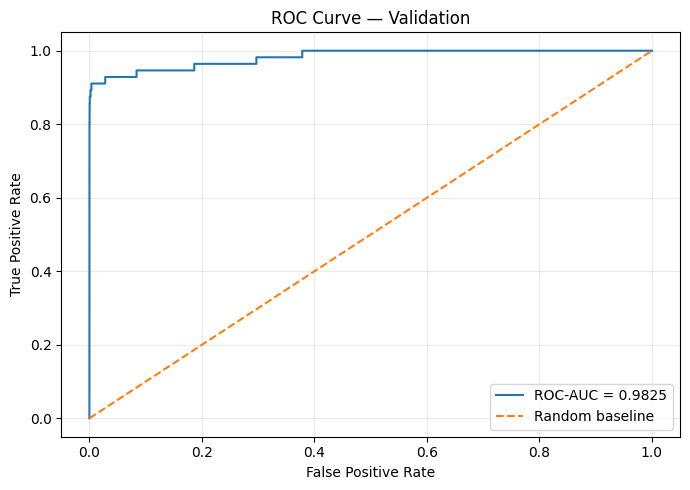

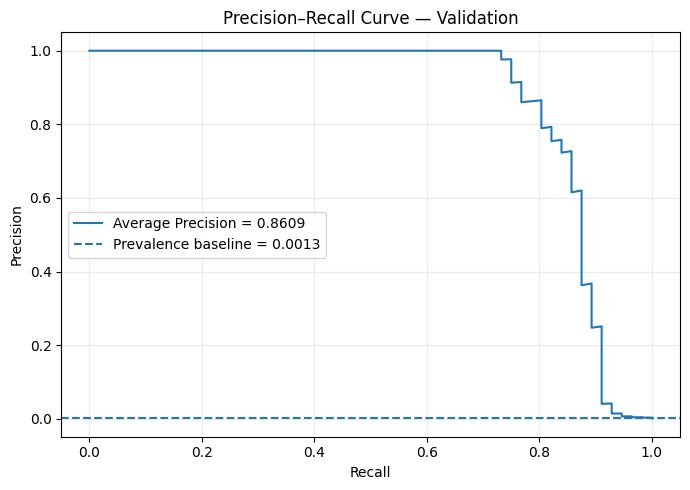

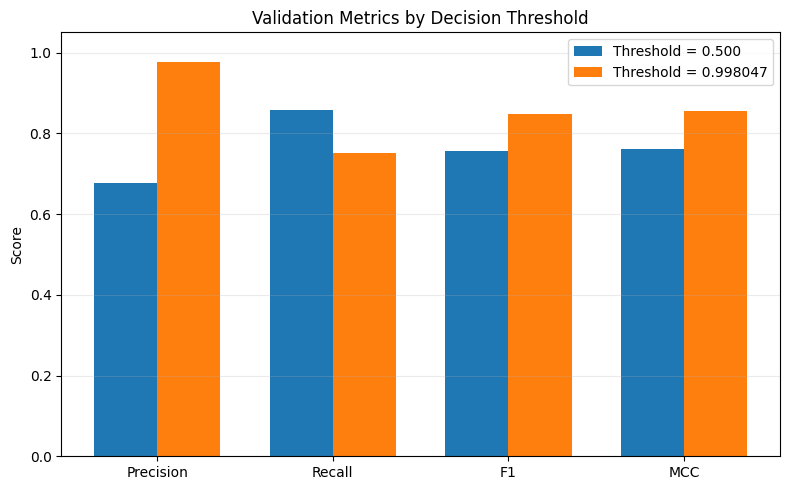

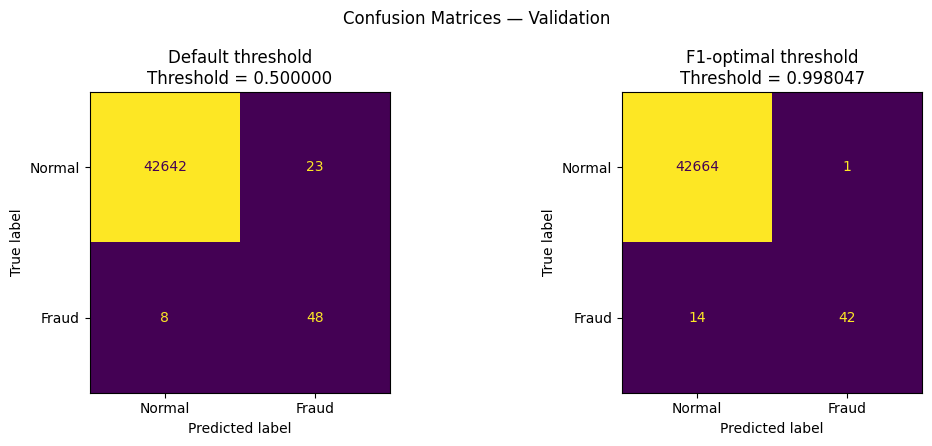

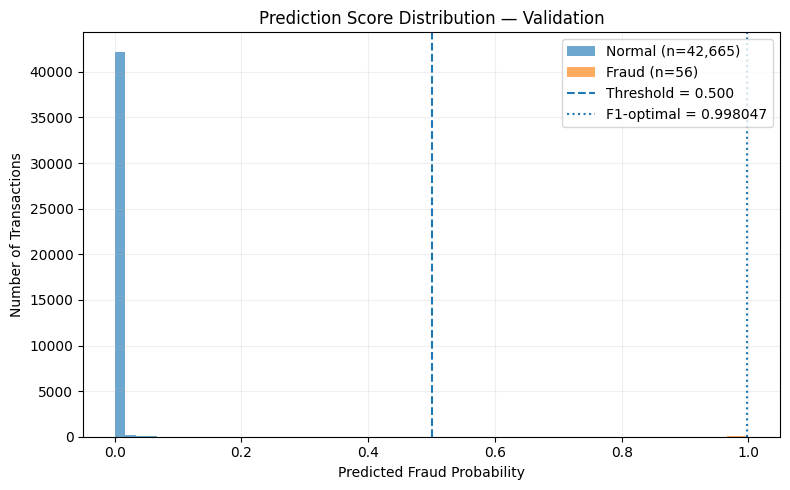

In [ ]:
# Stage 9.3: Plot validation results for Temporal Transformer (window 10)
# Uses validation predictions only. Does not train or evaluate on the test set.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    ConfusionMatrixDisplay,
)

# Fixed thresholds selected/evaluated on Validation
threshold_default = 0.5
threshold_f1 = float(best_threshold)

# Predicted labels at the two thresholds
pred_default = (validation_probs >= threshold_default).astype(int)
pred_f1 = (validation_probs >= threshold_f1).astype(int)

# Metrics
roc_auc = roc_auc_score(validation_labels, validation_probs)
ap = average_precision_score(validation_labels, validation_probs)

# 1. ROC curve
fpr, tpr, _ = roc_curve(validation_labels, validation_probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Validation")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 2. Precision–Recall curve
pr_precision, pr_recall, _ = precision_recall_curve(
    validation_labels, validation_probs
)

plt.figure(figsize=(7, 5))
plt.plot(pr_recall, pr_precision, label=f"Average Precision = {ap:.4f}")
baseline = validation_labels.mean()
plt.axhline(
    baseline,
    linestyle="--",
    label=f"Prevalence baseline = {baseline:.4f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Validation")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 3. Compare metrics at the two thresholds
def calculate_metrics(y_true, y_pred):
    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

metrics_default = calculate_metrics(validation_labels, pred_default)
metrics_f1 = calculate_metrics(validation_labels, pred_f1)

metric_names = list(metrics_default.keys())
x = np.arange(len(metric_names))
width = 0.36

plt.figure(figsize=(8, 5))
plt.bar(
    x - width / 2,
    [metrics_default[m] for m in metric_names],
    width,
    label=f"Threshold = {threshold_default:.3f}"
)
plt.bar(
    x + width / 2,
    [metrics_f1[m] for m in metric_names],
    width,
    label=f"Threshold = {threshold_f1:.6f}"
)
plt.xticks(x, metric_names)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Validation Metrics by Decision Threshold")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 4. Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, predictions, threshold, label in [
    (axes[0], pred_default, threshold_default, "Default threshold"),
    (axes[1], pred_f1, threshold_f1, "F1-optimal threshold"),
]:
    cm = confusion_matrix(validation_labels, predictions, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Fraud"]
    )
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"{label}\nThreshold = {threshold:.6f}")

plt.suptitle("Confusion Matrices — Validation")
plt.tight_layout()
plt.show()

# 5. Prediction score distributions
plt.figure(figsize=(8, 5))

normal_scores = validation_probs[validation_labels == 0]
fraud_scores = validation_probs[validation_labels == 1]

plt.hist(
    normal_scores,
    bins=60,
    alpha=0.65,
    label=f"Normal (n={len(normal_scores):,})"
)
plt.hist(
    fraud_scores,
    bins=30,
    alpha=0.65,
    label=f"Fraud (n={len(fraud_scores):,})"
)
plt.axvline(
    threshold_default,
    linestyle="--",
    label=f"Threshold = {threshold_default:.3f}"
)
plt.axvline(
    threshold_f1,
    linestyle=":",
    label=f"F1-optimal = {threshold_f1:.6f}"
)
plt.xlabel("Predicted Fraud Probability")
plt.ylabel("Number of Transactions")
plt.title("Prediction Score Distribution — Validation")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

##Test

In [ ]:
# Stage 10.1: Final test predictions
# Fixed checkpoint and threshold; no training or threshold tuning.

import numpy as np
import torch
from sklearn.metrics import average_precision_score, roc_auc_score

TEST_THRESHOLD = float(best_threshold)

# Verify the expected test loader exists
assert "test_loader_10" in globals(), (
    "test_loader_10 is missing. Please tell me before creating a new loader."
)

model_final.eval()

test_probs_list = []
test_labels_list = []

with torch.no_grad():
    for batch_x, batch_y in test_loader_10:
        batch_x = batch_x.to(device)

        logits = model_final(batch_x)
        probs = torch.sigmoid(logits).cpu().numpy()

        test_probs_list.extend(probs.reshape(-1).tolist())
        test_labels_list.extend(
            batch_y.cpu().numpy().reshape(-1).tolist()
        )

test_probs = np.asarray(test_probs_list, dtype=float)
test_labels = np.asarray(test_labels_list, dtype=int)

print("=== Test data verification ===")
print("Test samples:", len(test_labels))
print("Test fraud cases:", int(test_labels.sum()))
print("Test fraud prevalence:", round(float(test_labels.mean()), 6))

print("\n=== Final ranking metrics ===")
print("Test Average Precision (AP):",
      round(average_precision_score(test_labels, test_probs), 6))
print("Test ROC-AUC:",
      round(roc_auc_score(test_labels, test_probs), 6))

print("\nFixed decision threshold:", TEST_THRESHOLD)
print("Predicted probability range:",
      (round(float(test_probs.min()), 6),
       round(float(test_probs.max()), 6)))

=== Test data verification ===
Test samples: 42722
Test fraud cases: 52
Test fraud prevalence: 0.001217

=== Final ranking metrics ===
Test Average Precision (AP): 0.755129
Test ROC-AUC: 0.979717

Fixed decision threshold: 0.9980474710464478
Predicted probability range: (0.000379, 0.999823)


=== Final Test metrics ===


,AP,ROC-AUC,Precision,Recall,F1,MCC,TN,FP,FN,TP
0,0.755129,0.979717,0.948718,0.711538,0.813187,0.821435,42668,2,15,37


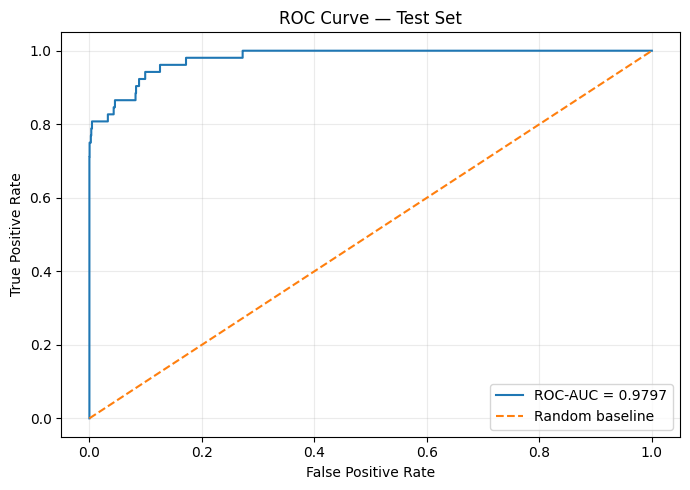

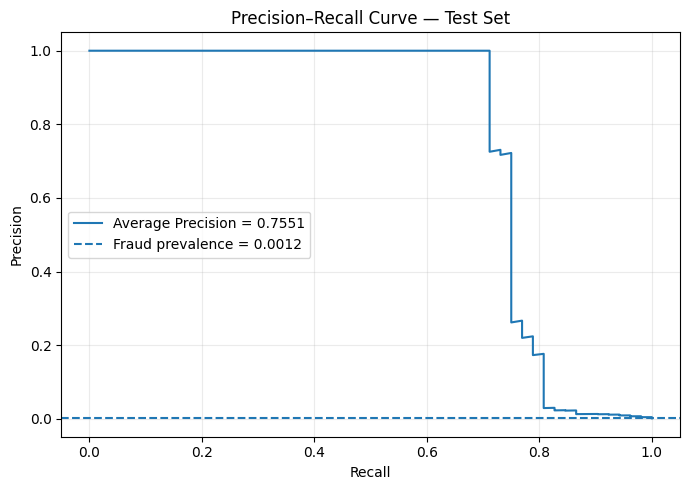

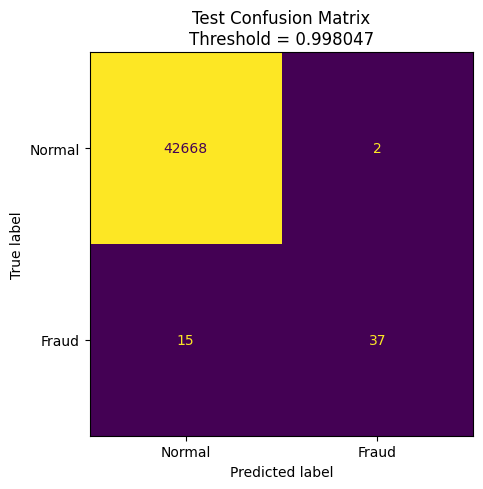

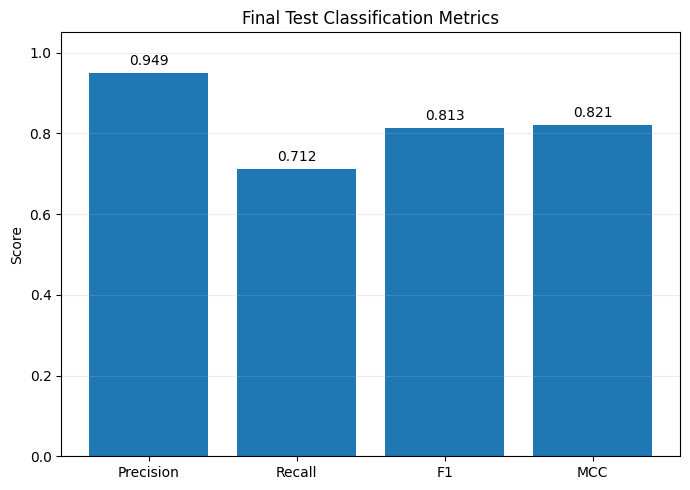

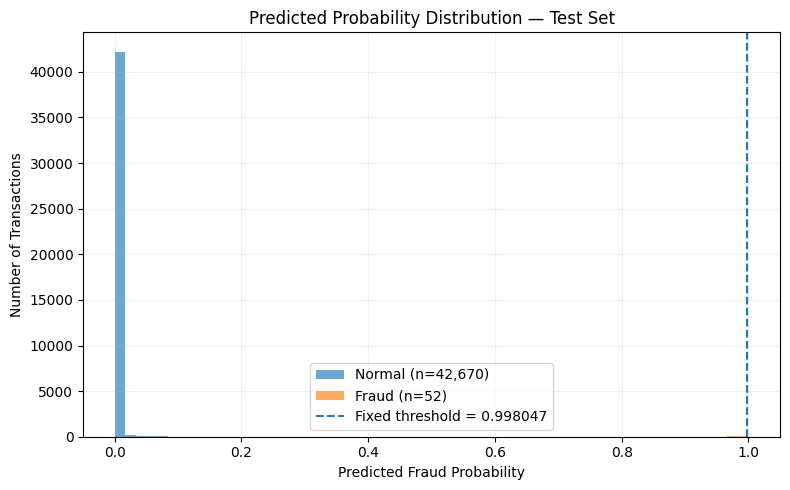

In [ ]:
# Stage 10.2: Final Test metrics and plots
# Uses the already generated Test predictions; threshold remains fixed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay,
)

# Apply the fixed threshold selected on Validation
test_predictions = (test_probs >= TEST_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    test_labels, test_predictions, labels=[0, 1]
).ravel()

test_metrics = {
    "AP": average_precision_score(test_labels, test_probs),
    "ROC-AUC": roc_auc_score(test_labels, test_probs),
    "Precision": precision_score(test_labels, test_predictions, zero_division=0),
    "Recall": recall_score(test_labels, test_predictions, zero_division=0),
    "F1": f1_score(test_labels, test_predictions, zero_division=0),
    "MCC": matthews_corrcoef(test_labels, test_predictions),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
}

print("=== Final Test metrics ===")
display(pd.DataFrame([test_metrics]).round(6))

# 1. Test ROC curve
fpr, tpr, _ = roc_curve(test_labels, test_probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {test_metrics['ROC-AUC']:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Test Set")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 2. Test Precision-Recall curve
pr_precision, pr_recall, _ = precision_recall_curve(test_labels, test_probs)

plt.figure(figsize=(7, 5))
plt.plot(
    pr_recall,
    pr_precision,
    label=f"Average Precision = {test_metrics['AP']:.4f}"
)
plt.axhline(
    test_labels.mean(),
    linestyle="--",
    label=f"Fraud prevalence = {test_labels.mean():.4f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Test Set")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 3. Confusion matrix at the fixed threshold
cm = confusion_matrix(test_labels, test_predictions, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title(f"Test Confusion Matrix\nThreshold = {TEST_THRESHOLD:.6f}")
plt.tight_layout()
plt.show()

# 4. Bar chart of final threshold-dependent metrics
metric_names = ["Precision", "Recall", "F1", "MCC"]
metric_values = [test_metrics[name] for name in metric_names]

plt.figure(figsize=(7, 5))
bars = plt.bar(metric_names, metric_values)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Final Test Classification Metrics")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# 5. Predicted probability distributions
plt.figure(figsize=(8, 5))
plt.hist(
    test_probs[test_labels == 0],
    bins=60,
    alpha=0.65,
    label=f"Normal (n={(test_labels == 0).sum():,})"
)
plt.hist(
    test_probs[test_labels == 1],
    bins=30,
    alpha=0.65,
    label=f"Fraud (n={(test_labels == 1).sum():,})"
)
plt.axvline(
    TEST_THRESHOLD,
    linestyle="--",
    label=f"Fixed threshold = {TEST_THRESHOLD:.6f}"
)
plt.xlabel("Predicted Fraud Probability")
plt.ylabel("Number of Transactions")
plt.title("Predicted Probability Distribution — Test Set")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## XAI

In [ ]:
import importlib.util

if importlib.util.find_spec("captum") is not None:
    import captum
    print("Captum is installed.")
    print("Version:", captum.__version__)
else:
    print("Captum is not installed.")

Captum is installed.
Version: 0.9.0


In [ ]:
%pip install captum

In [ ]:
import torch
import captum
import numpy as np

print("Captum version:", captum.__version__)
print("Model type:", type(model_final).__name__)
print("Model mode:", "eval" if not model_final.training else "train")
print("Test dataset size:", len(test_dataset_10))

# Inspect a single sample without modifying model weights
sample_x, sample_y = test_dataset_10[0]
sample_x = torch.as_tensor(sample_x, dtype=torch.float32).unsqueeze(0)

device = next(model_final.parameters()).device
sample_x = sample_x.to(device)

with torch.no_grad():
    sample_output = model_final(sample_x)

print("Input shape:", tuple(sample_x.shape))
print("Output shape:", tuple(sample_output.shape))
print("Device:", device)
print("Sample label:", int(sample_y))
print("Model output:", sample_output.detach().cpu().numpy())


Captum version: 0.9.0
Model type: TemporalTransformer
Model mode: eval
Test dataset size: 42722
Input shape: (1, 10, 30)
Output shape: (1,)
Device: cuda:0
Sample label: 0
Model output: [-7.8026104]


In [ ]:
import torch
import numpy as np
from captum.attr import IntegratedGradients

model_final.eval()

# Retrieve a single sample from the test set
sample_x, sample_y = test_dataset_10[0]
sample_x = torch.as_tensor(
    sample_x, dtype=torch.float32
).unsqueeze(0).to(device)

# Zero baseline in the standardized feature space
baseline = torch.zeros_like(sample_x)

# Compute Integrated Gradients on the model's logit output
ig = IntegratedGradients(model_final)

attributions, convergence_delta = ig.attribute(
    inputs=sample_x,
    baselines=baseline,
    n_steps=32,
    return_convergence_delta=True
)

ig_values = attributions.detach().cpu().numpy()[0]

print("Input shape:", tuple(sample_x.shape))
print("Attribution shape:", ig_values.shape)
print("True label:", int(sample_y))
print("Model logit:", float(model_final(sample_x).detach().cpu().item()))
print("Sum of attributions:", float(ig_values.sum()))
print("Convergence delta:", float(convergence_delta.detach().cpu().item()))
print("All attribution values finite:", bool(np.isfinite(ig_values).all()))


Input shape: (1, 10, 30)
Attribution shape: (10, 30)
True label: 0
Model logit: -7.802596092224121
Sum of attributions: -0.012658581137657166
Convergence delta: 2.527981996536255e-05
All attribution values finite: True


In [ ]:
import numpy as np
import pandas as pd
import torch
from captum.attr import IntegratedGradients

model_final.eval()

# Select all fraud cases and 200 randomly sampled legitimate cases.
test_labels_np = np.asarray(test_labels).astype(int)

fraud_indices = np.where(test_labels_np == 1)[0]
normal_indices = np.where(test_labels_np == 0)[0]

rng = np.random.default_rng(42)
sampled_normal_indices = rng.choice(
    normal_indices,
    size=min(200, len(normal_indices)),
    replace=False
)

xai_indices = np.sort(
    np.concatenate([fraud_indices, sampled_normal_indices])
)

print("Selected samples:", len(xai_indices))
print("Fraud samples:", int(test_labels_np[xai_indices].sum()))
print("Legitimate samples:", int((test_labels_np[xai_indices] == 0).sum()))

# Define feature names in the model input order.
feature_names = (
    [f"V{i}" for i in range(1, 29)]
    + ["Amount", "DeltaTime"]
)

assert len(feature_names) == 30

# Initialize Integrated Gradients with a zero baseline.
ig = IntegratedGradients(model_final)

all_ig = []
all_ig_labels = []
all_ig_indices = []
batch_size = 16

# Compute attributions in batches to limit GPU memory usage.
for start in range(0, len(xai_indices), batch_size):
    batch_indices = xai_indices[start:start + batch_size]

    batch_x = torch.stack([
        torch.as_tensor(
            test_dataset_10[int(i)][0],
            dtype=torch.float32
        )
        for i in batch_indices
    ]).to(device)

    baseline = torch.zeros_like(batch_x)

    batch_attributions = ig.attribute(
        inputs=batch_x,
        baselines=baseline,
        n_steps=32,
        internal_batch_size=batch_size * 4
    )

    all_ig.append(batch_attributions.detach().cpu().numpy())
    all_ig_labels.extend(test_labels_np[batch_indices].tolist())
    all_ig_indices.extend(batch_indices.tolist())

    print(
        f"Processed {min(start + batch_size, len(xai_indices))}"
        f" / {len(xai_indices)} samples"
    )

# Combine all attribution batches.
ig_attributions = np.concatenate(all_ig, axis=0)
ig_labels = np.asarray(all_ig_labels, dtype=int)
ig_sample_indices = np.asarray(all_ig_indices, dtype=int)

print("\nAttribution array shape:", ig_attributions.shape)
print("All values finite:", bool(np.isfinite(ig_attributions).all()))
print("Feature count:", len(feature_names))

Selected samples: 252
Fraud samples: 52
Legitimate samples: 200
Processed 16 / 252 samples
Processed 32 / 252 samples
Processed 48 / 252 samples
Processed 64 / 252 samples
Processed 80 / 252 samples
Processed 96 / 252 samples
Processed 112 / 252 samples
Processed 128 / 252 samples
Processed 144 / 252 samples
Processed 160 / 252 samples
Processed 176 / 252 samples
Processed 192 / 252 samples
Processed 208 / 252 samples
Processed 224 / 252 samples
Processed 240 / 252 samples
Processed 252 / 252 samples

Attribution array shape: (252, 10, 30)
All values finite: True
Feature count: 30


Top 15 features by mean absolute attribution:


,Feature,MeanAbsoluteAttribution
0,V14,0.137732
1,V4,0.065668
2,V12,0.053511
3,V10,0.048394
4,V2,0.027580
5,V11,0.024036
6,V1,0.022704
7,V3,0.021884
8,V5,0.021367
9,V7,0.018945


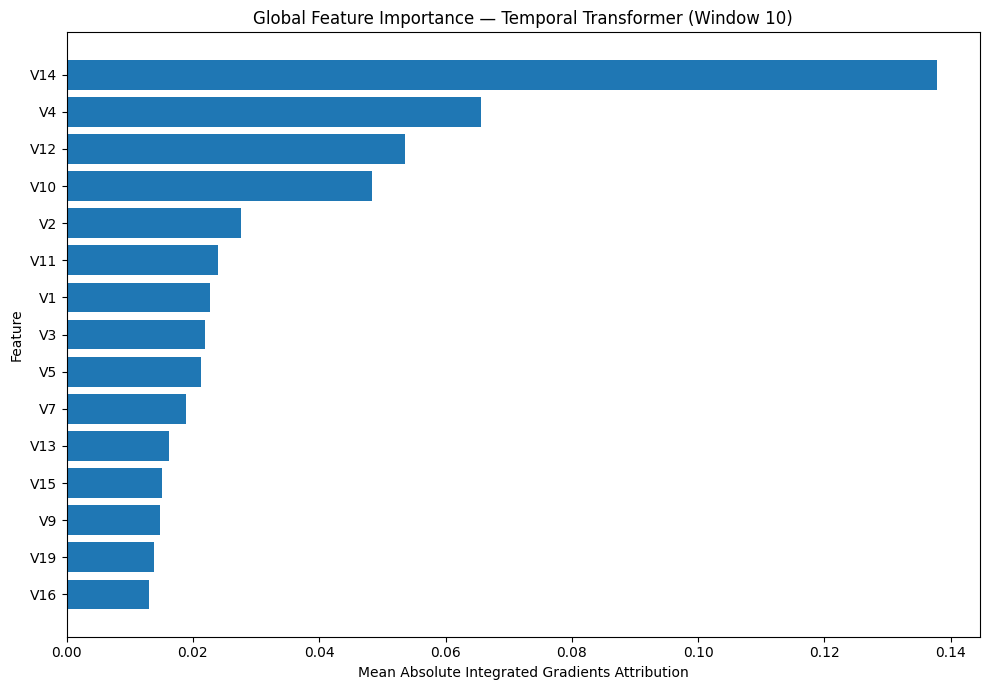

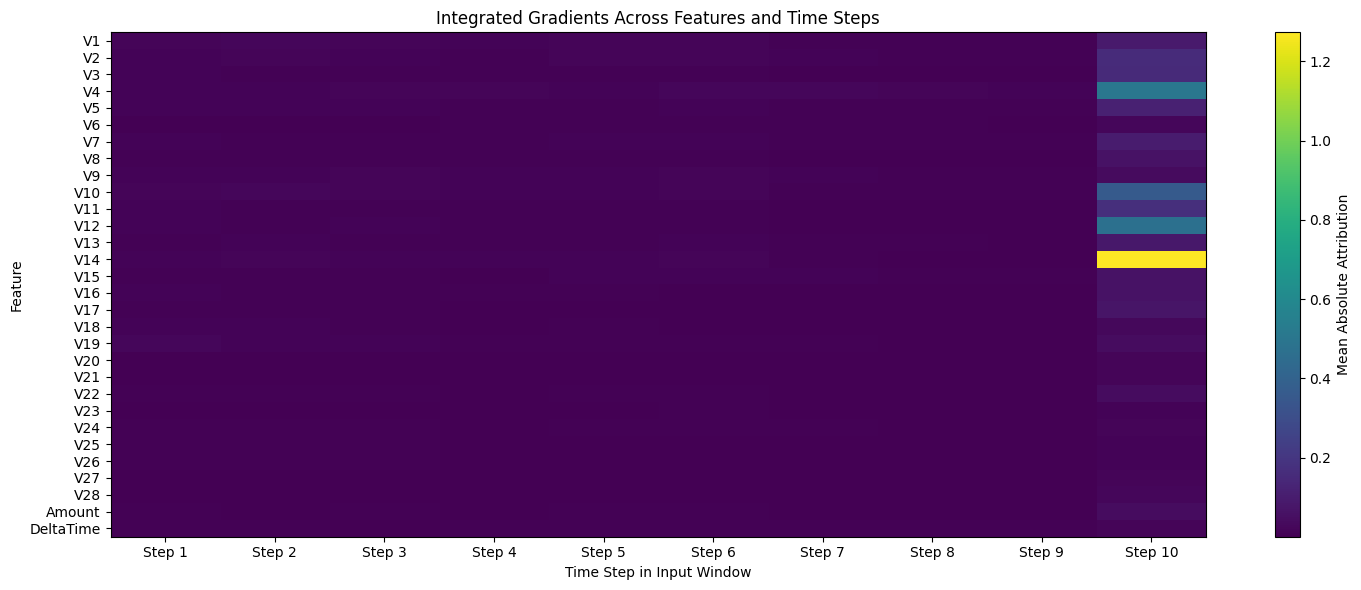

Saved feature importance to: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_ig_global_importance.csv
Saved attribution array: (252, 10, 30)


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# Aggregate absolute attributions across samples and time steps.
global_importance = np.mean(
    np.abs(ig_attributions),
    axis=(0, 1)
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsoluteAttribution": global_importance
}).sort_values(
    "MeanAbsoluteAttribution",
    ascending=False
).reset_index(drop=True)

print("Top 15 features by mean absolute attribution:")
display(importance_df.head(15).round(6))

# Plot global feature importance.
top_n = 15
plot_df = importance_df.head(top_n).sort_values(
    "MeanAbsoluteAttribution",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    plot_df["Feature"],
    plot_df["MeanAbsoluteAttribution"]
)
plt.xlabel("Mean Absolute Integrated Gradients Attribution")
plt.ylabel("Feature")
plt.title("Global Feature Importance — Temporal Transformer (Window 10)")
plt.tight_layout()
plt.show()

# Aggregate attribution magnitude by time step and feature.
time_feature_importance = np.mean(
    np.abs(ig_attributions),
    axis=0
)

plt.figure(figsize=(15, 6))
plt.imshow(
    time_feature_importance.T,
    aspect="auto",
    interpolation="nearest"
)
plt.colorbar(label="Mean Absolute Attribution")
plt.yticks(
    ticks=np.arange(len(feature_names)),
    labels=feature_names
)
plt.xticks(
    ticks=np.arange(10),
    labels=[f"Step {i + 1}" for i in range(10)]
)
plt.xlabel("Time Step in Input Window")
plt.ylabel("Feature")
plt.title("Integrated Gradients Across Features and Time Steps")
plt.tight_layout()
plt.show()

# Save the initial explanation results to Google Drive.
output_dir = "/content/drive/MyDrive/fraud_detection_models"
os.makedirs(output_dir, exist_ok=True)

importance_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_ig_global_importance.csv"
)
importance_df.to_csv(importance_path, index=False)

np.save(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_ig_attributions.npy"
    ),
    ig_attributions
)

np.save(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_ig_labels.npy"
    ),
    ig_labels
)

print("Saved feature importance to:", importance_path)
print("Saved attribution array:", ig_attributions.shape)

In [ ]:
import importlib.util

if importlib.util.find_spec("shap") is not None:
    import shap
    print("SHAP is installed.")
    print("Version:", shap.__version__)
else:
    print("SHAP is not installed.")

SHAP is installed.
Version: 0.54.1


In [ ]:
import shap
import numpy as np
import torch

model_final.eval()

# Select a small background set from the previously selected XAI samples.
background_size = min(32, len(xai_indices))
background_positions = np.linspace(
    0, len(xai_indices) - 1,
    num=background_size,
    dtype=int
)

background_indices = xai_indices[background_positions]

background_x = torch.stack([
    torch.as_tensor(
        test_dataset_10[int(i)][0],
        dtype=torch.float32
    )
    for i in background_indices
]).to(device)

# Select a small batch for the initial SHAP compatibility check.
explain_size = min(8, len(xai_indices))
explain_indices = xai_indices[:explain_size]

explain_x = torch.stack([
    torch.as_tensor(
        test_dataset_10[int(i)][0],
        dtype=torch.float32
    )
    for i in explain_indices
]).to(device)

with torch.no_grad():
    background_output = model_final(background_x)
    explain_output = model_final(explain_x)

print("SHAP version:", shap.__version__)
print("Background shape:", tuple(background_x.shape))
print("Explanation input shape:", tuple(explain_x.shape))
print("Model output shape:", tuple(explain_output.shape))
print("Background output shape:", tuple(background_output.shape))
print("Device:", device)

SHAP version: 0.54.1
Background shape: (32, 10, 30)
Explanation input shape: (8, 10, 30)
Model output shape: (8,)
Background output shape: (32,)
Device: cuda:0


In [ ]:
import shap
import numpy as np
import torch
import torch.nn as nn

model_final.eval()

# Wrap the model so its output has shape (batch_size, 1).
class SHAPModelWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        output = self.model(x)
        return output.reshape(-1, 1)

shap_model = SHAPModelWrapper(model_final).to(device)
shap_model.eval()

# Verify the wrapped model output shape.
with torch.no_grad():
    wrapped_output = shap_model(explain_x)

print("Wrapped output shape:", tuple(wrapped_output.shape))

# Initialize the GradientExplainer with the wrapped model.
shap_explainer = shap.GradientExplainer(
    shap_model,
    background_x
)

# Compute SHAP values for the initial batch.
shap_values_raw = shap_explainer.shap_values(
    explain_x,
    nsamples=100
)

# Normalize the returned array shape.
if isinstance(shap_values_raw, list):
    shap_values_array = np.asarray(shap_values_raw[0])
else:
    shap_values_array = np.asarray(shap_values_raw)

if (
    shap_values_array.ndim == 4
    and shap_values_array.shape[-1] == 1
):
    shap_values_array = shap_values_array[..., 0]

print("SHAP output type:", type(shap_values_raw).__name__)
print("SHAP array shape:", shap_values_array.shape)
print("All values finite:", bool(np.isfinite(shap_values_array).all()))
print("Explanation samples:", len(explain_indices))

Wrapped output shape: (8, 1)
SHAP output type: ndarray
SHAP array shape: (8, 10, 30)
All values finite: True
Explanation samples: 8


Top 15 features by mean absolute SHAP value:


,Feature,MeanAbsoluteSHAP
0,V14,0.245072
1,V12,0.100356
2,V4,0.099107
3,V10,0.073470
4,V11,0.036720
5,V1,0.031178
6,V16,0.030693
7,V7,0.028517
8,V15,0.027207
9,V5,0.027060


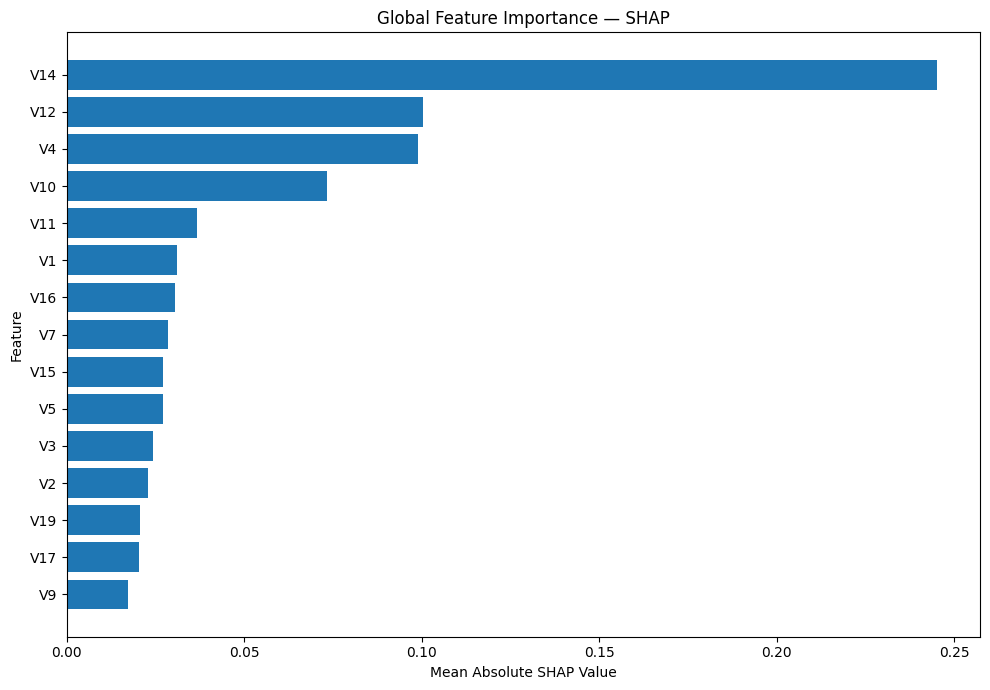

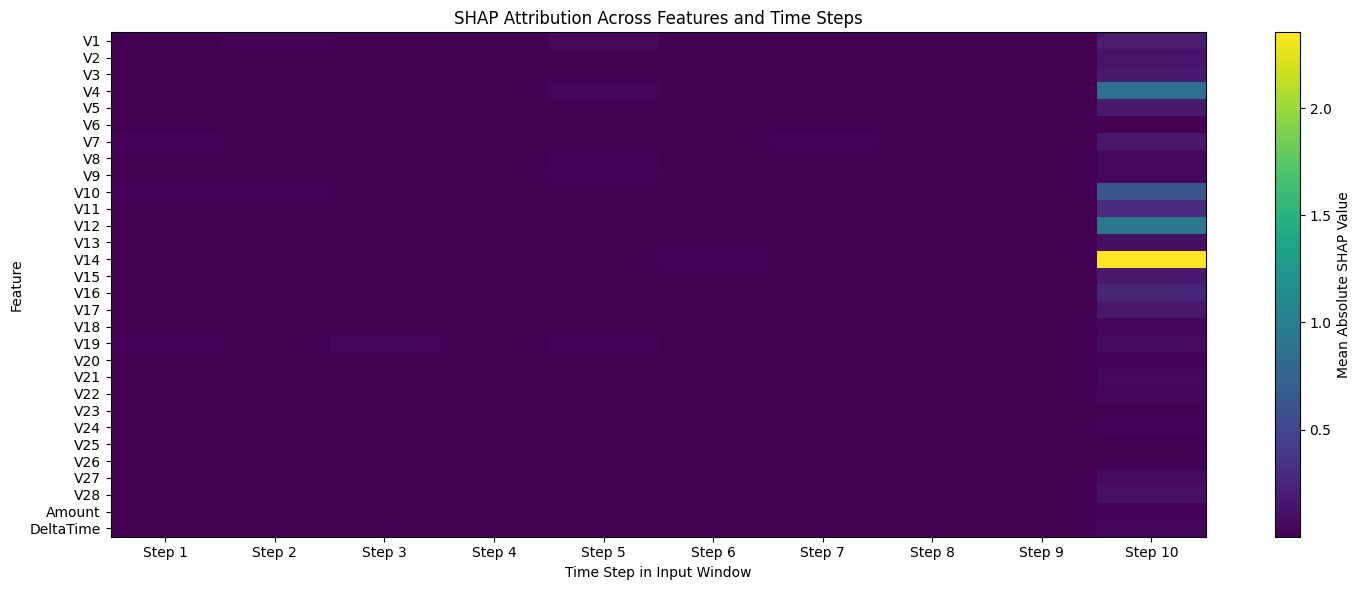

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Aggregate absolute SHAP values across samples and time steps.
shap_global_importance = np.mean(
    np.abs(shap_values_array),
    axis=(0, 1)
)

shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsoluteSHAP": shap_global_importance
}).sort_values(
    "MeanAbsoluteSHAP",
    ascending=False
).reset_index(drop=True)

print("Top 15 features by mean absolute SHAP value:")
display(shap_importance_df.head(15).round(6))

# Plot the top 15 features.
plot_df = shap_importance_df.head(15).sort_values(
    "MeanAbsoluteSHAP",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    plot_df["Feature"],
    plot_df["MeanAbsoluteSHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Global Feature Importance — SHAP")
plt.tight_layout()
plt.show()

# Plot attribution magnitude across time steps.
shap_time_feature_importance = np.mean(
    np.abs(shap_values_array),
    axis=0
)

plt.figure(figsize=(15, 6))
plt.imshow(
    shap_time_feature_importance.T,
    aspect="auto",
    interpolation="nearest"
)
plt.colorbar(label="Mean Absolute SHAP Value")
plt.yticks(
    ticks=np.arange(len(feature_names)),
    labels=feature_names
)
plt.xticks(
    ticks=np.arange(10),
    labels=[f"Step {i + 1}" for i in range(10)]
)
plt.xlabel("Time Step in Input Window")
plt.ylabel("Feature")
plt.title("SHAP Attribution Across Features and Time Steps")
plt.tight_layout()
plt.show()

In [ ]:
# Save SHAP explanations and global importance results.
output_dir = "/content/drive/MyDrive/fraud_detection_models"
os.makedirs(output_dir, exist_ok=True)

shap_importance_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_shap_global_importance.csv"
)

shap_importance_df.to_csv(
    shap_importance_path,
    index=False
)

np.save(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_shap_attributions_8samples.npy"
    ),
    shap_values_array
)

np.save(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_shap_sample_indices.npy"
    ),
    explain_indices
)

print("Saved SHAP importance:", shap_importance_path)
print("Saved SHAP attribution shape:", shap_values_array.shape)

Saved SHAP importance: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_shap_global_importance.csv
Saved SHAP attribution shape: (8, 10, 30)


In [ ]:
import numpy as np
import torch
import os

model_final.eval()

# Reuse the existing SHAP explainer and background set.
shap_batch_size = 16
shap_results = []

# Compute SHAP values for the same samples used by Integrated Gradients.
for start in range(0, len(xai_indices), shap_batch_size):
    batch_indices = xai_indices[start:start + shap_batch_size]

    batch_x = torch.stack([
        torch.as_tensor(
            test_dataset_10[int(i)][0],
            dtype=torch.float32
        )
        for i in batch_indices
    ]).to(device)

    batch_shap_raw = shap_explainer.shap_values(
        batch_x,
        nsamples=100
    )

    if isinstance(batch_shap_raw, list):
        batch_shap = np.asarray(batch_shap_raw[0])
    else:
        batch_shap = np.asarray(batch_shap_raw)

    # Remove a singleton output dimension if returned by SHAP.
    if batch_shap.ndim == 4 and batch_shap.shape[-1] == 1:
        batch_shap = batch_shap[..., 0]

    expected_shape = (len(batch_indices), 10, 30)
    if batch_shap.shape != expected_shape:
        raise ValueError(
            f"Unexpected SHAP shape {batch_shap.shape}; "
            f"expected {expected_shape}"
        )

    shap_results.append(batch_shap)

    print(
        f"Processed {min(start + shap_batch_size, len(xai_indices))}"
        f" / {len(xai_indices)} samples"
    )

# Combine all batches.
shap_attributions = np.concatenate(shap_results, axis=0)

assert shap_attributions.shape == (len(xai_indices), 10, 30)
assert np.isfinite(shap_attributions).all()

print("\nFinal SHAP shape:", shap_attributions.shape)
print("All values finite:", bool(np.isfinite(shap_attributions).all()))

# Save the full SHAP attribution array under a new filename.
output_dir = "/content/drive/MyDrive/fraud_detection_models"
shap_full_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_shap_attributions_252samples.npy"
)

np.save(shap_full_path, shap_attributions)
np.save(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_shap_indices_252samples.npy"
    ),
    xai_indices
)

print("Saved full SHAP attributions to:", shap_full_path)

Processed 16 / 252 samples
Processed 32 / 252 samples
Processed 48 / 252 samples
Processed 64 / 252 samples
Processed 80 / 252 samples
Processed 96 / 252 samples
Processed 112 / 252 samples
Processed 128 / 252 samples
Processed 144 / 252 samples
Processed 160 / 252 samples
Processed 176 / 252 samples
Processed 192 / 252 samples
Processed 208 / 252 samples
Processed 224 / 252 samples
Processed 240 / 252 samples
Processed 252 / 252 samples

Final SHAP shape: (252, 10, 30)
All values finite: True
Saved full SHAP attributions to: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_shap_attributions_252samples.npy


Spearman rank correlation: 0.9929
Spearman p-value: 0.0

Feature importance comparison:


,Feature,IG_MeanAbs,SHAP_MeanAbs,IG_Rank,SHAP_Rank,RankDifference
0,V14,0.137732,0.146921,1.0,1.0,0.0
1,V4,0.065668,0.076731,2.0,2.0,0.0
2,V12,0.053511,0.056277,3.0,3.0,0.0
3,V10,0.048394,0.049954,4.0,4.0,0.0
4,V2,0.027580,0.024344,5.0,6.0,1.0
5,V11,0.024036,0.025949,6.0,5.0,1.0
6,V1,0.022704,0.022216,7.0,7.0,0.0
7,V3,0.021884,0.017949,8.0,10.0,2.0
8,V5,0.021367,0.020230,9.0,9.0,0.0
9,V7,0.018945,0.022189,10.0,8.0,2.0


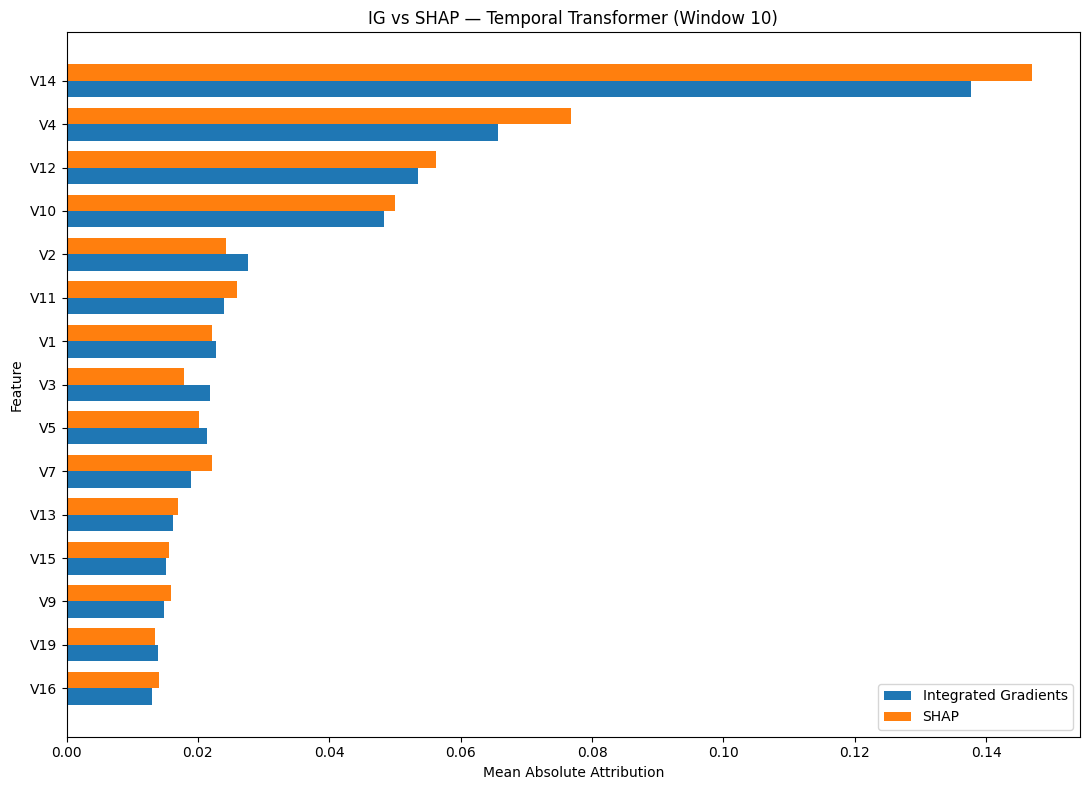

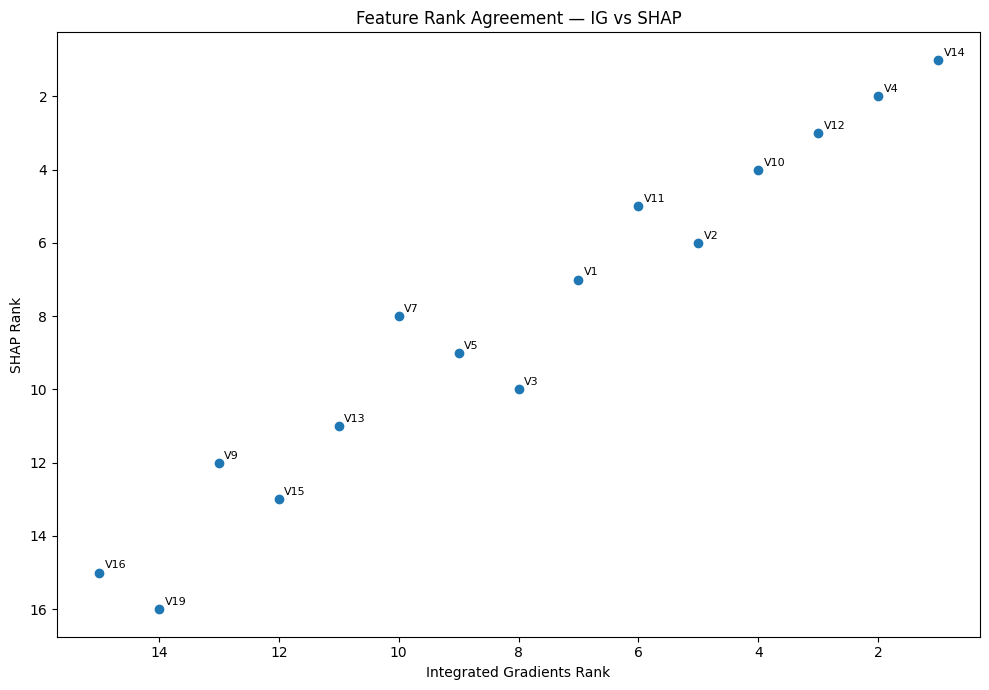

Saved comparison table: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_ig_vs_shap_comparison.csv
Saved correlation summary: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_ig_vs_shap_summary.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from scipy.stats import spearmanr

# Aggregate absolute attribution values across samples and time steps.
ig_global = np.mean(
    np.abs(ig_attributions),
    axis=(0, 1)
)

shap_global = np.mean(
    np.abs(shap_attributions),
    axis=(0, 1)
)

# Build a comparison table using the same feature order.
comparison_df = pd.DataFrame({
    "Feature": feature_names,
    "IG_MeanAbs": ig_global,
    "SHAP_MeanAbs": shap_global
})

comparison_df["IG_Rank"] = comparison_df["IG_MeanAbs"].rank(
    ascending=False,
    method="average"
)
comparison_df["SHAP_Rank"] = comparison_df["SHAP_MeanAbs"].rank(
    ascending=False,
    method="average"
)

comparison_df["RankDifference"] = (
    comparison_df["IG_Rank"] - comparison_df["SHAP_Rank"]
).abs()

comparison_df = comparison_df.sort_values(
    "IG_MeanAbs",
    ascending=False
).reset_index(drop=True)

# Compute rank correlation between the two methods.
spearman_result = spearmanr(
    comparison_df["IG_MeanAbs"],
    comparison_df["SHAP_MeanAbs"]
)

print("Spearman rank correlation:", round(float(spearman_result.statistic), 4))
print("Spearman p-value:", round(float(spearman_result.pvalue), 6))

print("\nFeature importance comparison:")
display(comparison_df.head(15).round(6))

# Plot the top 15 features ranked by IG.
top_features = comparison_df.head(15).copy()
top_features = top_features.sort_values(
    "IG_MeanAbs",
    ascending=True
)

y_positions = np.arange(len(top_features))
bar_height = 0.38

plt.figure(figsize=(11, 8))
plt.barh(
    y_positions - bar_height / 2,
    top_features["IG_MeanAbs"],
    height=bar_height,
    label="Integrated Gradients"
)
plt.barh(
    y_positions + bar_height / 2,
    top_features["SHAP_MeanAbs"],
    height=bar_height,
    label="SHAP"
)

plt.yticks(y_positions, top_features["Feature"])
plt.xlabel("Mean Absolute Attribution")
plt.ylabel("Feature")
plt.title("IG vs SHAP — Temporal Transformer (Window 10)")
plt.legend()
plt.tight_layout()
plt.show()

# Plot feature ranks from both explanation methods.
rank_plot_df = comparison_df.sort_values(
    "IG_Rank",
    ascending=True
).head(15).sort_values(
    "IG_Rank",
    ascending=False
)

plt.figure(figsize=(10, 7))
plt.scatter(
    rank_plot_df["IG_Rank"],
    rank_plot_df["SHAP_Rank"]
)

for _, row in rank_plot_df.iterrows():
    plt.annotate(
        row["Feature"],
        (row["IG_Rank"], row["SHAP_Rank"]),
        fontsize=8,
        xytext=(4, 3),
        textcoords="offset points"
    )

plt.xlabel("Integrated Gradients Rank")
plt.ylabel("SHAP Rank")
plt.title("Feature Rank Agreement — IG vs SHAP")
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Save the comparison table and correlation summary.
output_dir = "/content/drive/MyDrive/fraud_detection_models"

comparison_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_ig_vs_shap_comparison.csv"
)
comparison_df.to_csv(comparison_path, index=False)

summary_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_ig_vs_shap_summary.csv"
)

pd.DataFrame([{
    "Spearman_Rank_Correlation": float(spearman_result.statistic),
    "Spearman_P_Value": float(spearman_result.pvalue),
    "Number_of_Samples": len(xai_indices),
    "Number_of_Features": len(feature_names)
}]).to_csv(summary_path, index=False)

print("Saved comparison table:", comparison_path)
print("Saved correlation summary:", summary_path)

In [ ]:
import numpy as np
import pandas as pd
import torch

# Prepare the selected evaluation samples.
xai_x = torch.stack([
    test_dataset_10[int(idx)][0]
    for idx in xai_indices
]).float().to(device)

xai_x = xai_x[:len(ig_attributions)]

# Compute global feature importance.
ig_importance = np.abs(ig_attributions).mean(axis=(0, 1))
shap_importance = np.abs(shap_attributions).mean(axis=(0, 1))

importance_rankings = {
    "IG": np.argsort(ig_importance)[::-1].copy(),
    "SHAP": np.argsort(shap_importance)[::-1].copy()
}

rng = np.random.default_rng(42)
top_k_values = [3, 5, 10]
n_random_repeats = 20

@torch.no_grad()
def predict_probabilities(inputs, batch_size=64):
    model_final.eval()
    predictions = []

    for start in range(0, len(inputs), batch_size):
        batch = inputs[start:start + batch_size].to(device)
        logits = model_final(batch).reshape(-1)
        predictions.append(torch.sigmoid(logits).cpu())

    return torch.cat(predictions).numpy()

original_probs = predict_probabilities(xai_x)
results = []

for method, ranking in importance_rankings.items():
    for k in top_k_values:
        important_features = ranking[:k].copy().tolist()
        least_important_features = ranking[-k:].copy().tolist()

        # Replace the most important features with the zero baseline.
        top_perturbed = xai_x.clone()
        top_perturbed[:, :, important_features] = 0.0
        top_probs = predict_probabilities(top_perturbed)

        # Replace the least important features with the zero baseline.
        bottom_perturbed = xai_x.clone()
        bottom_perturbed[:, :, least_important_features] = 0.0
        bottom_probs = predict_probabilities(bottom_perturbed)

        # Repeat random-feature removal with a fixed random generator.
        random_changes = []

        for _ in range(n_random_repeats):
            random_features = rng.choice(
                xai_x.shape[-1], size=k, replace=False
            ).copy().tolist()

            random_perturbed = xai_x.clone()
            random_perturbed[:, :, random_features] = 0.0
            random_probs = predict_probabilities(random_perturbed)

            random_changes.append(
                np.abs(original_probs - random_probs).mean()
            )

        top_change = np.abs(original_probs - top_probs).mean()
        bottom_change = np.abs(original_probs - bottom_probs).mean()
        random_change = np.mean(random_changes)

        results.append({
            "Method": method,
            "K_Features": k,
            "TopK_MeanAbsProbabilityChange": float(top_change),
            "BottomK_MeanAbsProbabilityChange": float(bottom_change),
            "RandomK_MeanAbsProbabilityChange": float(random_change),
            "TopK_vs_Random_Difference": float(top_change - random_change)
        })

fidelity_df = pd.DataFrame(results)
display(fidelity_df.round(6))

save_path = (
    "/content/drive/MyDrive/fraud_detection_models/"
    "temporal_transformer_window10_fidelity_results.csv"
)

fidelity_df.to_csv(save_path, index=False)
print("Saved Fidelity results to:", save_path)

,Method,K_Features,TopK_MeanAbsProbabilityChange,BottomK_MeanAbsProbabilityChange,RandomK_MeanAbsProbabilityChange,TopK_vs_Random_Difference
0,IG,3,0.128762,0.001257,0.011314,0.117448
1,IG,5,0.153315,0.001961,0.020462,0.132852
2,IG,10,0.153277,0.001663,0.041192,0.112085
3,SHAP,3,0.128762,0.001257,0.004265,0.124497
4,SHAP,5,0.153338,0.001961,0.010205,0.143133
5,SHAP,10,0.153277,0.001663,0.019628,0.133649


Saved Fidelity results to: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_fidelity_results.csv


In [ ]:
import numpy as np
import pandas as pd
import torch
from captum.attr import IntegratedGradients
from scipy.stats import spearmanr
from torch.nn.functional import cosine_similarity

# Reproducible stability experiment.
torch.manual_seed(42)
np.random.seed(42)

model_final.eval()
ig_explainer = IntegratedGradients(model_final)

# Use a subset to keep the experiment computationally manageable.
n_stability = min(64, len(xai_x))
stability_x = xai_x[:n_stability].clone()

# Match original IG attributions to the selected samples.
original_ig = torch.tensor(
    ig_attributions[:n_stability],
    dtype=torch.float32,
    device=device
)

# Add small Gaussian noise in standardized feature space.
noise_sigma = 0.01
noise = torch.randn_like(stability_x) * noise_sigma
noisy_x = stability_x + noise

# Recompute IG explanations for the perturbed inputs.
noisy_ig_batches = []
batch_size = 8

for start in range(0, n_stability, batch_size):
    batch = noisy_x[start:start + batch_size]

    batch_attr = ig_explainer.attribute(
        batch,
        baselines=torch.zeros_like(batch),
        n_steps=32
    )

    noisy_ig_batches.append(batch_attr.detach())

noisy_ig = torch.cat(noisy_ig_batches, dim=0)

# 1. Per-sample cosine similarity between original and noisy attributions.
original_flat = original_ig.reshape(n_stability, -1)
noisy_flat = noisy_ig.reshape(n_stability, -1)

sample_cosine = cosine_similarity(
    original_flat, noisy_flat, dim=1
).detach().cpu().numpy()

# 2. Compare global feature-importance rankings.
original_global = original_ig.abs().mean(dim=(0, 1)).detach().cpu().numpy()
noisy_global = noisy_ig.abs().mean(dim=(0, 1)).detach().cpu().numpy()

rank_corr, rank_pvalue = spearmanr(original_global, noisy_global)

# Report overall stability statistics.
stability_summary = pd.DataFrame([{
    "Method": "Integrated Gradients",
    "Samples": n_stability,
    "NoiseSigma": noise_sigma,
    "MeanCosineSimilarity": float(np.mean(sample_cosine)),
    "StdCosineSimilarity": float(np.std(sample_cosine)),
    "GlobalFeatureRankSpearman": float(rank_corr),
    "SpearmanPValue": float(rank_pvalue)
}])

display(stability_summary.round(6))

# Save per-sample similarities.
stability_samples_df = pd.DataFrame({
    "SampleIndex": np.arange(n_stability),
    "CosineSimilarity": sample_cosine
})

base_path = (
    "/content/drive/MyDrive/fraud_detection_models/"
    "temporal_transformer_window10_ig_stability"
)

stability_summary.to_csv(base_path + "_summary.csv", index=False)
stability_samples_df.to_csv(base_path + "_per_sample.csv", index=False)

print("Saved stability summary to:", base_path + "_summary.csv")
print("Saved per-sample results to:", base_path + "_per_sample.csv")

,Method,Samples,NoiseSigma,MeanCosineSimilarity,StdCosineSimilarity,GlobalFeatureRankSpearman,SpearmanPValue
0,Integrated Gradients,64,0.01,0.999873,0.000163,0.999555,0.0


Saved stability summary to: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_ig_stability_summary.csv
Saved per-sample results to: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_ig_stability_per_sample.csv


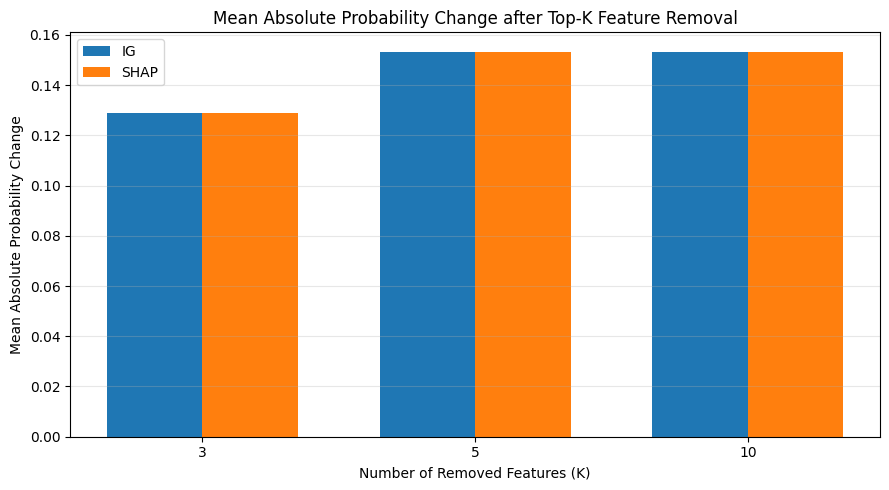

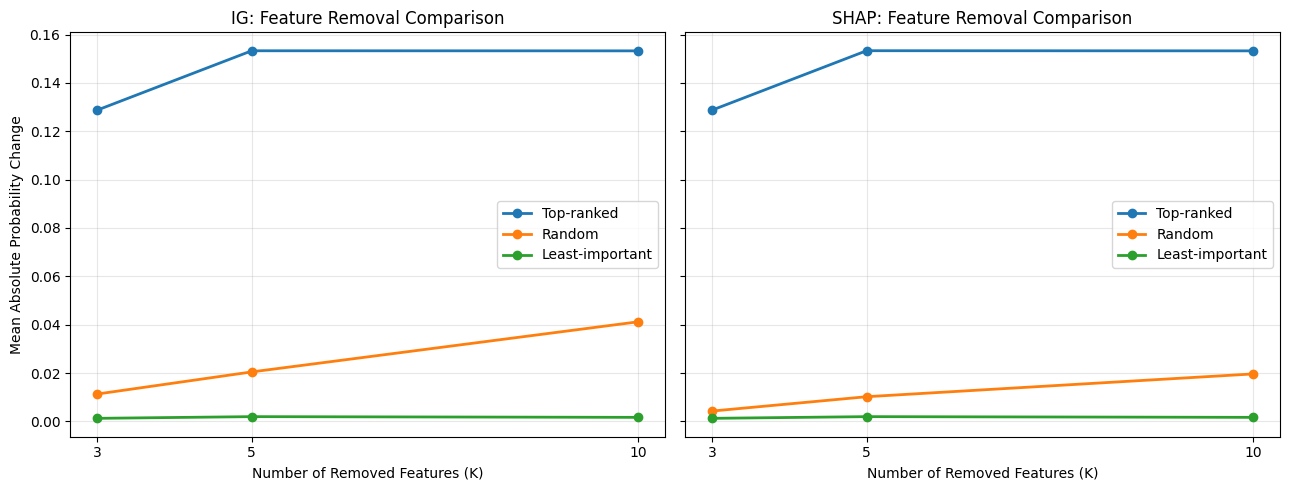

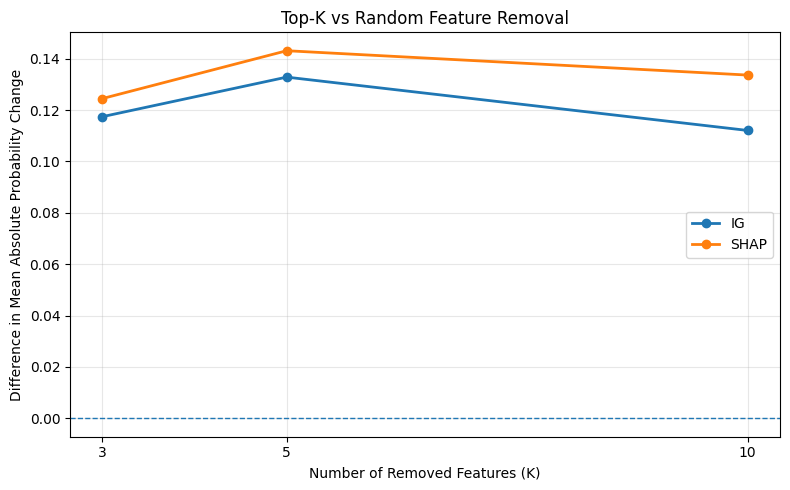

All Fidelity figures saved to Google Drive.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Plot 1: Mean absolute probability change for top-ranked features.
fig, ax = plt.subplots(figsize=(9, 5))

k_values = [3, 5, 10]
x = np.arange(len(k_values))
width = 0.35

for i, method in enumerate(["IG", "SHAP"]):
    subset = (
        fidelity_df[fidelity_df["Method"] == method]
        .set_index("K_Features")
        .reindex(k_values)
    )

    ax.bar(
        x + (i - 0.5) * width,
        subset["TopK_MeanAbsProbabilityChange"],
        width,
        label=method
    )

ax.set_title("Mean Absolute Probability Change after Top-K Feature Removal")
ax.set_xlabel("Number of Removed Features (K)")
ax.set_ylabel("Mean Absolute Probability Change")
ax.set_xticks(x)
ax.set_xticklabels(k_values)
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


# Plot 2: Compare top-ranked, random, and least-important feature removal.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

comparison_columns = {
    "Top-ranked": "TopK_MeanAbsProbabilityChange",
    "Random": "RandomK_MeanAbsProbabilityChange",
    "Least-important": "BottomK_MeanAbsProbabilityChange"
}

for ax, method in zip(axes, ["IG", "SHAP"]):
    subset = (
        fidelity_df[fidelity_df["Method"] == method]
        .set_index("K_Features")
        .reindex(k_values)
    )

    for label, column in comparison_columns.items():
        ax.plot(
            k_values,
            subset[column],
            marker="o",
            linewidth=2,
            label=label
        )

    ax.set_title(f"{method}: Feature Removal Comparison")
    ax.set_xlabel("Number of Removed Features (K)")
    ax.set_xticks(k_values)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Mean Absolute Probability Change")
fig.tight_layout()
plt.show()


# Plot 3: Difference between top-ranked and random feature removal.
fig, ax = plt.subplots(figsize=(8, 5))

for method in ["IG", "SHAP"]:
    subset = (
        fidelity_df[fidelity_df["Method"] == method]
        .set_index("K_Features")
        .reindex(k_values)
    )

    ax.plot(
        k_values,
        subset["TopK_vs_Random_Difference"],
        marker="o",
        linewidth=2,
        label=method
    )

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("Top-K vs Random Feature Removal")
ax.set_xlabel("Number of Removed Features (K)")
ax.set_ylabel("Difference in Mean Absolute Probability Change")
ax.set_xticks(k_values)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


# Save the figures to Google Drive.
output_dir = "/content/drive/MyDrive/fraud_detection_models"

figures = [
    ("fidelity_topk_comparison.png", 0),
    ("fidelity_removal_strategies.png", 1),
    ("fidelity_topk_vs_random.png", 2)
]

# Recreate and save each figure separately for publication use.
for filename, plot_type in figures:
    fig, ax = plt.subplots(figsize=(9, 5))

    if plot_type == 0:
        for method in ["IG", "SHAP"]:
            subset = (
                fidelity_df[fidelity_df["Method"] == method]
                .set_index("K_Features")
                .reindex(k_values)
            )
            ax.plot(
                k_values,
                subset["TopK_MeanAbsProbabilityChange"],
                marker="o",
                label=method
            )
        ax.set_title("Top-K Feature Removal")
        ax.set_ylabel("Mean Absolute Probability Change")

    elif plot_type == 1:
        for method in ["IG", "SHAP"]:
            subset = (
                fidelity_df[fidelity_df["Method"] == method]
                .set_index("K_Features")
                .reindex(k_values)
            )
            ax.plot(
                k_values,
                subset["TopK_MeanAbsProbabilityChange"],
                marker="o",
                label=f"{method} Top-K"
            )
            ax.plot(
                k_values,
                subset["RandomK_MeanAbsProbabilityChange"],
                marker="s",
                linestyle="--",
                label=f"{method} Random"
            )
        ax.set_title("Top-K vs Random Feature Removal")
        ax.set_ylabel("Mean Absolute Probability Change")

    else:
        for method in ["IG", "SHAP"]:
            subset = (
                fidelity_df[fidelity_df["Method"] == method]
                .set_index("K_Features")
                .reindex(k_values)
            )
            ax.plot(
                k_values,
                subset["TopK_vs_Random_Difference"],
                marker="o",
                label=method
            )
        ax.axhline(0, linestyle="--", linewidth=1)
        ax.set_title("Top-K vs Random Difference")
        ax.set_ylabel("Difference in Probability Change")

    ax.set_xlabel("Number of Removed Features (K)")
    ax.set_xticks(k_values)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{output_dir}/{filename}", dpi=300, bbox_inches="tight")
    plt.close(fig)

print("All Fidelity figures saved to Google Drive.")

,NoiseSigma,MeanCosineSimilarity,StdCosineSimilarity,GlobalFeatureRankSpearman,SpearmanPValue
0,0.01,0.999873,0.000163,0.999555,0.0
1,0.05,0.996873,0.004119,0.999110,0.0
2,0.10,0.988058,0.015258,0.998220,0.0


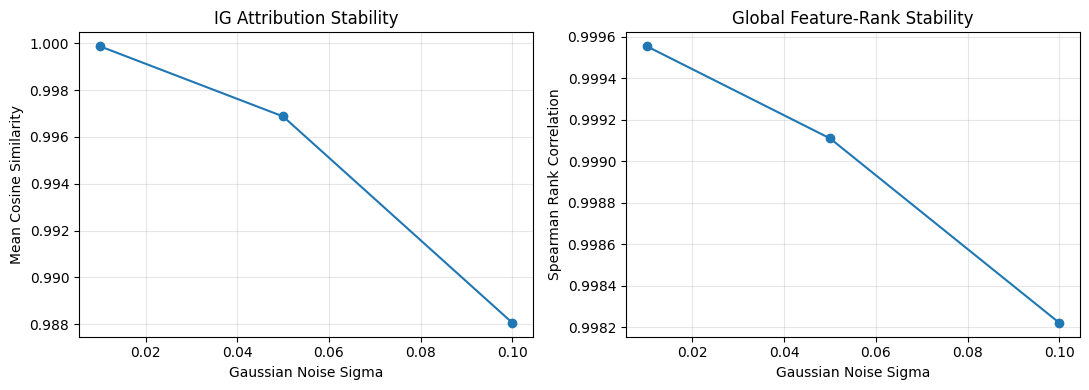

Saved Stability results to: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_ig_stability_noise_levels.csv


In [ ]:
import numpy as np
import pandas as pd
import torch
from captum.attr import IntegratedGradients
from torch.nn.functional import cosine_similarity

model_final.eval()
ig_explainer = IntegratedGradients(model_final)

# Reuse the same 64 samples used in the initial stability experiment.
n_stability = min(64, len(xai_x))
stability_x = xai_x[:n_stability].clone()

original_ig_tensor = torch.as_tensor(
    ig_attributions[:n_stability],
    dtype=torch.float32,
    device=device
)

noise_levels = [0.01, 0.05, 0.10]
stability_results = []

for sigma in noise_levels:
    torch.manual_seed(42)

    noisy_x = stability_x + torch.randn_like(stability_x) * sigma
    noisy_attributions = []

    for start in range(0, n_stability, 8):
        batch = noisy_x[start:start + 8]

        batch_attr = ig_explainer.attribute(
            batch,
            baselines=torch.zeros_like(batch),
            n_steps=32
        )

        noisy_attributions.append(batch_attr.detach())

    noisy_ig_tensor = torch.cat(noisy_attributions, dim=0)

    original_flat = original_ig_tensor.reshape(n_stability, -1)
    noisy_flat = noisy_ig_tensor.reshape(n_stability, -1)

    cosine_scores = cosine_similarity(
        original_flat, noisy_flat, dim=1
    ).detach().cpu().numpy()

    original_global = (
        original_ig_tensor.abs().mean(dim=(0, 1)).detach().cpu().numpy()
    )
    noisy_global = (
        noisy_ig_tensor.abs().mean(dim=(0, 1)).detach().cpu().numpy()
    )

    from scipy.stats import spearmanr
    rank_corr, rank_pvalue = spearmanr(original_global, noisy_global)

    stability_results.append({
        "NoiseSigma": sigma,
        "MeanCosineSimilarity": float(cosine_scores.mean()),
        "StdCosineSimilarity": float(cosine_scores.std()),
        "GlobalFeatureRankSpearman": float(rank_corr),
        "SpearmanPValue": float(rank_pvalue)
    })

stability_df = pd.DataFrame(stability_results)
display(stability_df.round(6))

save_path = (
    "/content/drive/MyDrive/fraud_detection_models/"
    "temporal_transformer_window10_ig_stability_noise_levels.csv"
)
stability_df.to_csv(save_path, index=False)

# Plot stability against noise level.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    stability_df["NoiseSigma"],
    stability_df["MeanCosineSimilarity"],
    marker="o"
)
axes[0].set_title("IG Attribution Stability")
axes[0].set_xlabel("Gaussian Noise Sigma")
axes[0].set_ylabel("Mean Cosine Similarity")
axes[0].grid(alpha=0.3)

axes[1].plot(
    stability_df["NoiseSigma"],
    stability_df["GlobalFeatureRankSpearman"],
    marker="o"
)
axes[1].set_title("Global Feature-Rank Stability")
axes[1].set_xlabel("Gaussian Noise Sigma")
axes[1].set_ylabel("Spearman Rank Correlation")
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

fig.savefig(
    "/content/drive/MyDrive/fraud_detection_models/"
    "temporal_transformer_window10_ig_stability_noise_levels.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved Stability results to:", save_path)

,Method,NoiseSigma,MeanCosineSimilarity,StdCosineSimilarity,GlobalFeatureRankSpearman,SpearmanPValue
0,SHAP,0.01,0.884931,0.203200,0.996440,0.0
1,SHAP,0.05,0.899866,0.138439,0.996440,0.0
2,SHAP,0.10,0.899671,0.142183,0.996885,0.0


Saved SHAP stability results to: /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_shap_stability.csv


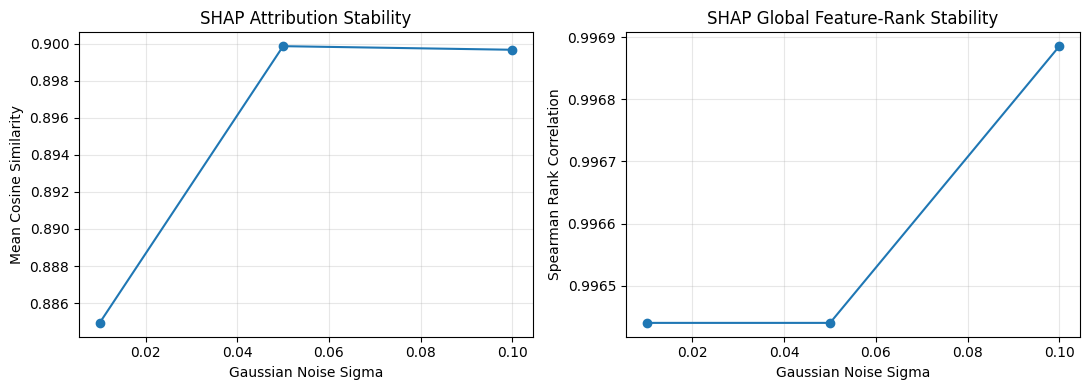

In [ ]:
import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from torch.nn.functional import cosine_similarity

# Use the same 64 samples as the IG stability experiment.
n_stability = min(64, len(xai_x))
stability_x = xai_x[:n_stability].clone()

# Keep the original SHAP attributions for these samples.
original_shap = np.asarray(shap_attributions[:n_stability])

noise_levels = [0.01, 0.05, 0.10]
batch_size = 8
stability_results = []

for sigma in noise_levels:
    rng = np.random.default_rng(42)
    noise_np = rng.normal(
        loc=0.0,
        scale=sigma,
        size=tuple(stability_x.shape)
    ).astype(np.float32)

    noisy_x = stability_x + torch.from_numpy(noise_np).to(device)
    noisy_attribution_batches = []

    for start in range(0, n_stability, batch_size):
        batch = noisy_x[start:start + batch_size]

        # GradientExplainer returns attributions for the perturbed inputs.
        batch_shap = shap_explainer.shap_values(
            batch,
            nsamples=100
        )

        if isinstance(batch_shap, list):
            batch_shap = batch_shap[0]

        batch_shap = np.asarray(batch_shap)

        # Normalize common single-output SHAP array formats.
        if batch_shap.ndim == 4 and batch_shap.shape[-1] == 1:
            batch_shap = batch_shap[..., 0]

        noisy_attribution_batches.append(batch_shap)

    noisy_shap = np.concatenate(noisy_attribution_batches, axis=0)

    # Ensure both arrays have the expected shape: samples x time x features.
    if noisy_shap.shape != original_shap.shape:
        raise ValueError(
            f"SHAP shape mismatch: original={original_shap.shape}, "
            f"noisy={noisy_shap.shape}"
        )

    # Compare the full attribution vectors for each sample.
    original_flat = torch.tensor(
        original_shap.reshape(n_stability, -1),
        dtype=torch.float32
    )
    noisy_flat = torch.tensor(
        noisy_shap.reshape(n_stability, -1),
        dtype=torch.float32
    )

    cosine_scores = cosine_similarity(
        original_flat, noisy_flat, dim=1
    ).numpy()

    # Compare global feature-importance rankings.
    original_global = np.abs(original_shap).mean(axis=(0, 1))
    noisy_global = np.abs(noisy_shap).mean(axis=(0, 1))

    rank_corr, rank_pvalue = spearmanr(
        original_global, noisy_global
    )

    stability_results.append({
        "Method": "SHAP",
        "NoiseSigma": sigma,
        "MeanCosineSimilarity": float(cosine_scores.mean()),
        "StdCosineSimilarity": float(cosine_scores.std()),
        "GlobalFeatureRankSpearman": float(rank_corr),
        "SpearmanPValue": float(rank_pvalue)
    })

shap_stability_df = pd.DataFrame(stability_results)
display(shap_stability_df.round(6))

# Save results.
output_dir = "/content/drive/MyDrive/fraud_detection_models"
csv_path = f"{output_dir}/temporal_transformer_window10_shap_stability.csv"

shap_stability_df.to_csv(csv_path, index=False)
print("Saved SHAP stability results to:", csv_path)

# Plot actual results produced by this experiment.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    shap_stability_df["NoiseSigma"],
    shap_stability_df["MeanCosineSimilarity"],
    marker="o"
)
axes[0].set_title("SHAP Attribution Stability")
axes[0].set_xlabel("Gaussian Noise Sigma")
axes[0].set_ylabel("Mean Cosine Similarity")
axes[0].grid(alpha=0.3)

axes[1].plot(
    shap_stability_df["NoiseSigma"],
    shap_stability_df["GlobalFeatureRankSpearman"],
    marker="o"
)
axes[1].set_title("SHAP Global Feature-Rank Stability")
axes[1].set_xlabel("Gaussian Noise Sigma")
axes[1].set_ylabel("Spearman Rank Correlation")
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    f"{output_dir}/temporal_transformer_window10_shap_stability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

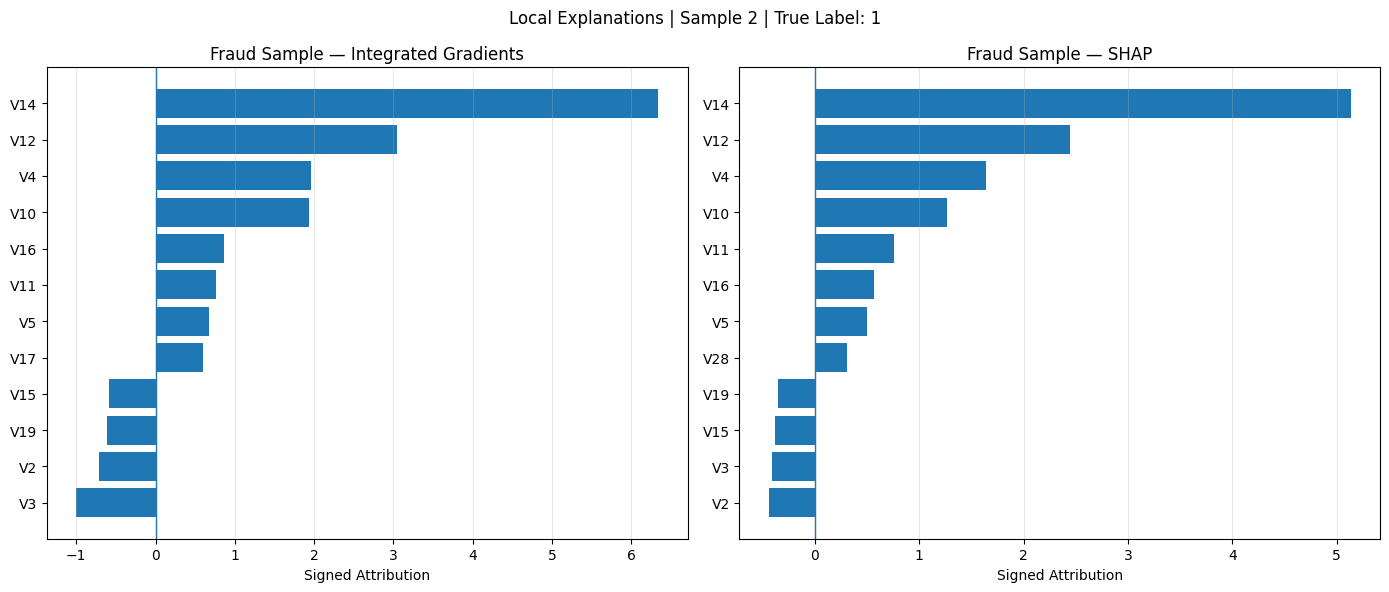

Saved: /content/drive/MyDrive/fraud_detection_models/local_explanation_fraud_sample_2.csv
Saved: /content/drive/MyDrive/fraud_detection_models/local_explanation_fraud_sample_2.png


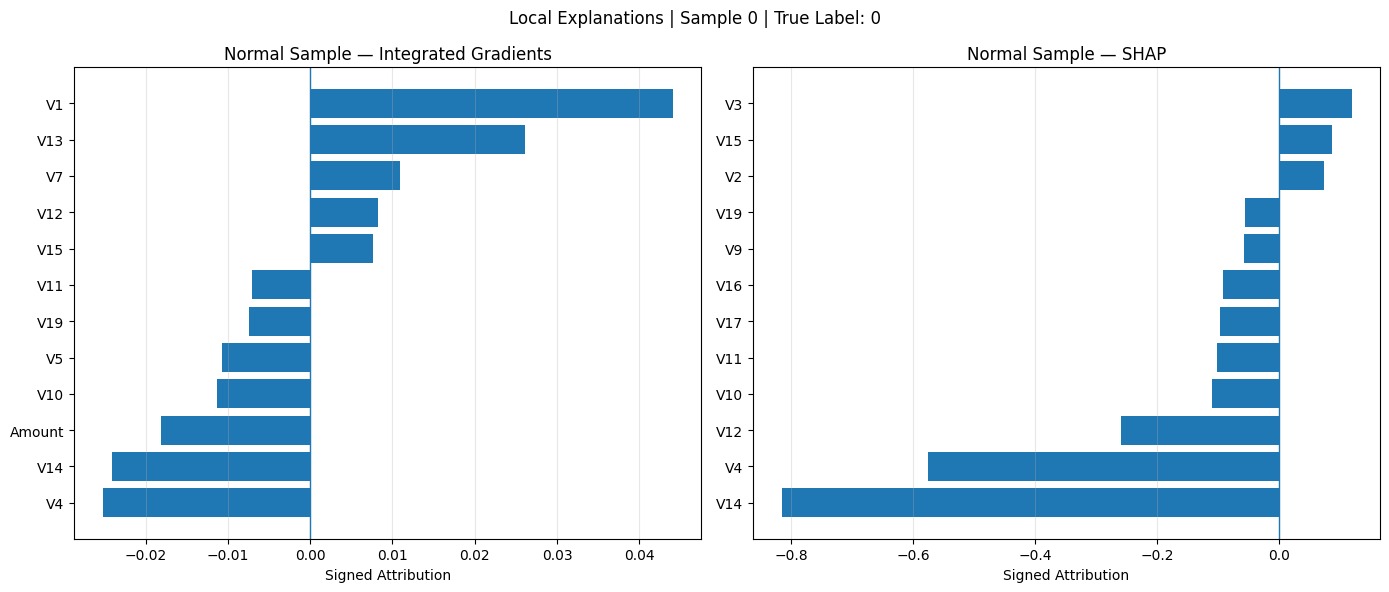

Saved: /content/drive/MyDrive/fraud_detection_models/local_explanation_normal_sample_0.csv
Saved: /content/drive/MyDrive/fraud_detection_models/local_explanation_normal_sample_0.png
Selected XAI sample positions: {'Fraud': 2, 'Normal': 0}


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Load labels associated with the 252 XAI samples.
output_dir = "/content/drive/MyDrive/fraud_detection_models"

xai_labels = np.load(
    f"{output_dir}/temporal_transformer_window10_ig_labels.npy"
).reshape(-1)

# Verify alignment between samples, labels, and attribution arrays.
assert len(xai_labels) == len(ig_attributions) == len(shap_attributions)
assert len(feature_names) == ig_attributions.shape[-1]

# Select one fraud case and one normal case.
fraud_candidates = np.where(xai_labels == 1)[0]
normal_candidates = np.where(xai_labels == 0)[0]

if len(fraud_candidates) == 0 or len(normal_candidates) == 0:
    raise ValueError("Both fraud and normal samples are required.")

# Choose the first fraud sample and first normal sample in the XAI subset.
selected_samples = {
    "Fraud": int(fraud_candidates[0]),
    "Normal": int(normal_candidates[0])
}

# Aggregate signed attributions across the 10 time steps.
def aggregate_local_attributions(attributions, sample_idx):
    return np.asarray(attributions[sample_idx]).sum(axis=0)

for sample_type, sample_idx in selected_samples.items():
    ig_local = aggregate_local_attributions(
        ig_attributions, sample_idx
    )
    shap_local = aggregate_local_attributions(
        shap_attributions, sample_idx
    )

    # Save local attribution values.
    local_df = pd.DataFrame({
        "Feature": feature_names,
        "IG_SignedAttribution": ig_local,
        "SHAP_SignedAttribution": shap_local
    })

    local_df["IG_AbsAttribution"] = np.abs(
        local_df["IG_SignedAttribution"]
    )
    local_df["SHAP_AbsAttribution"] = np.abs(
        local_df["SHAP_SignedAttribution"]
    )

    csv_path = (
        f"{output_dir}/local_explanation_{sample_type.lower()}_"
        f"sample_{sample_idx}.csv"
    )
    local_df.to_csv(csv_path, index=False)

    # Plot top 12 features by absolute attribution for each method.
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    for ax, method, values in [
        (axes[0], "Integrated Gradients", ig_local),
        (axes[1], "SHAP", shap_local)
    ]:
        top_indices = np.argsort(np.abs(values))[-12:]
        top_values = values[top_indices]
        top_names = np.array(feature_names)[top_indices]

        # Sort by signed attribution for easier reading.
        order = np.argsort(top_values)
        top_values = top_values[order]
        top_names = top_names[order]

        ax.barh(top_names, top_values)
        ax.axvline(0, linewidth=1)
        ax.set_title(f"{sample_type} Sample — {method}")
        ax.set_xlabel("Signed Attribution")
        ax.grid(axis="x", alpha=0.3)

    fig.suptitle(
        f"Local Explanations | Sample {sample_idx} | "
        f"True Label: {int(xai_labels[sample_idx])}"
    )
    fig.tight_layout()

    plot_path = (
        f"{output_dir}/local_explanation_{sample_type.lower()}_"
        f"sample_{sample_idx}.png"
    )
    fig.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", csv_path)
    print("Saved:", plot_path)

print("Selected XAI sample positions:", selected_samples)

GLOBAL FEATURE IMPORTANCE COMPARISON


,Feature,IG_MeanAbs,SHAP_MeanAbs,IG_Rank,SHAP_Rank,RankDifference
0,V14,0.137732,0.146921,1.0,1.0,0.0
1,V4,0.065668,0.076731,2.0,2.0,0.0
2,V12,0.053511,0.056277,3.0,3.0,0.0
3,V10,0.048394,0.049954,4.0,4.0,0.0
4,V2,0.027580,0.024344,5.0,6.0,1.0
5,V11,0.024036,0.025949,6.0,5.0,1.0
6,V1,0.022704,0.022216,7.0,7.0,0.0
7,V3,0.021884,0.017949,8.0,10.0,2.0
8,V5,0.021367,0.020230,9.0,9.0,0.0
9,V7,0.018945,0.022189,10.0,8.0,2.0


FIDELITY RESULTS


,Method,K_Features,TopK_MeanAbsProbabilityChange,BottomK_MeanAbsProbabilityChange,RandomK_MeanAbsProbabilityChange,TopK_vs_Random_Difference
0,IG,3,0.128762,0.001257,0.011314,0.117448
1,IG,5,0.153315,0.001961,0.020462,0.132852
2,IG,10,0.153277,0.001663,0.041192,0.112085
3,SHAP,3,0.128762,0.001257,0.004265,0.124497
4,SHAP,5,0.153338,0.001961,0.010205,0.143133
5,SHAP,10,0.153277,0.001663,0.019628,0.133649


IG AND SHAP STABILITY COMPARISON


,Method,NoiseSigma,MeanCosineSimilarity,StdCosineSimilarity,GlobalFeatureRankSpearman,SpearmanPValue
0,IG,0.01,0.999873,0.000163,0.999555,0.0
1,SHAP,0.01,0.884931,0.203200,0.996440,0.0
2,IG,0.05,0.996873,0.004119,0.999110,0.0
3,SHAP,0.05,0.899866,0.138439,0.996440,0.0
4,IG,0.10,0.988058,0.015258,0.998220,0.0
5,SHAP,0.10,0.899671,0.142183,0.996885,0.0


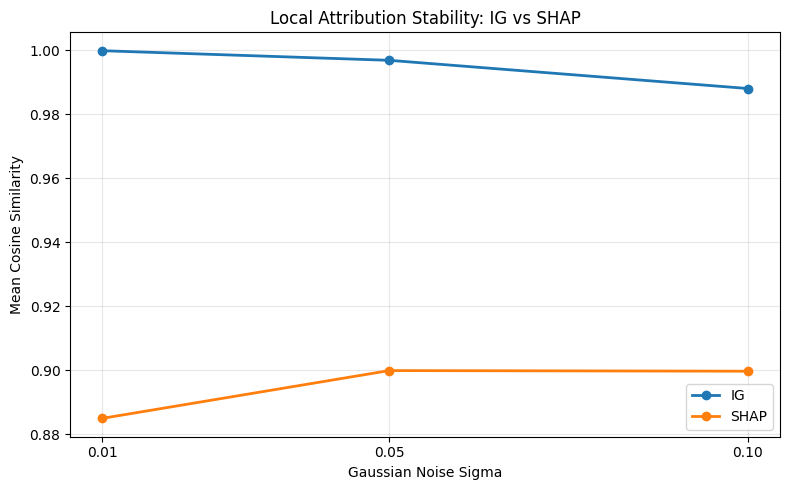

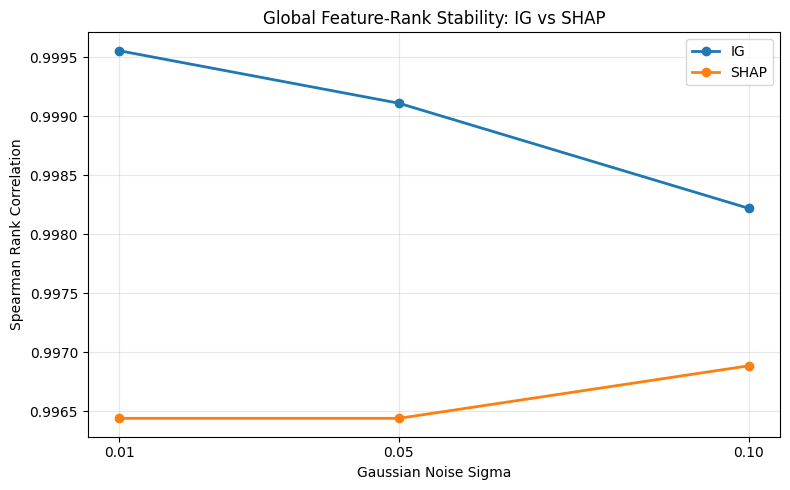

Final XAI tables and comparison plots saved to: /content/drive/MyDrive/fraud_detection_models


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Define the output directory.
output_dir = "/content/drive/MyDrive/fraud_detection_models"

# Load previously saved XAI evaluation results.
comparison_df = pd.read_csv(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_ig_vs_shap_comparison.csv"
    )
)

fidelity_df = pd.read_csv(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_fidelity_results.csv"
    )
)

ig_stability_df = pd.read_csv(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_ig_stability_noise_levels.csv"
    )
)

shap_stability_df = pd.read_csv(
    os.path.join(
        output_dir,
        "temporal_transformer_window10_shap_stability.csv"
    )
)

# Create a unified stability table.
ig_stability_df = ig_stability_df.copy()
ig_stability_df["Method"] = "IG"

shap_stability_df = shap_stability_df.copy()
shap_stability_df["Method"] = "SHAP"

stability_comparison_df = pd.concat(
    [ig_stability_df, shap_stability_df],
    ignore_index=True
)

stability_comparison_df = stability_comparison_df[
    [
        "Method",
        "NoiseSigma",
        "MeanCosineSimilarity",
        "StdCosineSimilarity",
        "GlobalFeatureRankSpearman",
        "SpearmanPValue"
    ]
].sort_values(
    ["NoiseSigma", "Method"]
).reset_index(drop=True)

print("GLOBAL FEATURE IMPORTANCE COMPARISON")
display(comparison_df.head(15).round(6))

print("FIDELITY RESULTS")
display(fidelity_df.round(6))

print("IG AND SHAP STABILITY COMPARISON")
display(stability_comparison_df.round(6))

# Save the consolidated tables.
comparison_df.to_csv(
    os.path.join(output_dir, "final_xai_feature_comparison.csv"),
    index=False
)

fidelity_df.to_csv(
    os.path.join(output_dir, "final_xai_fidelity_results.csv"),
    index=False
)

stability_comparison_df.to_csv(
    os.path.join(output_dir, "final_xai_stability_comparison.csv"),
    index=False
)

# Plot 1: Compare IG and SHAP cosine similarity across noise levels.
fig, ax = plt.subplots(figsize=(8, 5))

for method in ["IG", "SHAP"]:
    subset = stability_comparison_df[
        stability_comparison_df["Method"] == method
    ].sort_values("NoiseSigma")

    ax.plot(
        subset["NoiseSigma"],
        subset["MeanCosineSimilarity"],
        marker="o",
        linewidth=2,
        label=method
    )

ax.set_title("Local Attribution Stability: IG vs SHAP")
ax.set_xlabel("Gaussian Noise Sigma")
ax.set_ylabel("Mean Cosine Similarity")
ax.set_xticks([0.01, 0.05, 0.10])
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "final_xai_stability_cosine_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Plot 2: Compare global feature-rank stability.
fig, ax = plt.subplots(figsize=(8, 5))

for method in ["IG", "SHAP"]:
    subset = stability_comparison_df[
        stability_comparison_df["Method"] == method
    ].sort_values("NoiseSigma")

    ax.plot(
        subset["NoiseSigma"],
        subset["GlobalFeatureRankSpearman"],
        marker="o",
        linewidth=2,
        label=method
    )

ax.set_title("Global Feature-Rank Stability: IG vs SHAP")
ax.set_xlabel("Gaussian Noise Sigma")
ax.set_ylabel("Spearman Rank Correlation")
ax.set_xticks([0.01, 0.05, 0.10])
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    os.path.join(output_dir, "final_xai_stability_rank_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Final XAI tables and comparison plots saved to:", output_dir)

In [ ]:
import os
import glob
import pandas as pd
from IPython.display import display

output_dir = "/content/drive/MyDrive/fraud_detection_models"

# Locate saved local explanation tables.
local_csv_files = sorted(
    glob.glob(os.path.join(output_dir, "local_explanation_*.csv"))
)

if not local_csv_files:
    print("No local explanation CSV files were found.")
    print("Run the local explanation cell first.")
else:
    for file_path in local_csv_files:
        print("\nFile:", os.path.basename(file_path))

        local_df = pd.read_csv(file_path)

        required_columns = [
            "Feature",
            "IG_SignedAttribution",
            "SHAP_SignedAttribution"
        ]

        missing_columns = [
            col for col in required_columns
            if col not in local_df.columns
        ]

        if missing_columns:
            print("Missing columns:", missing_columns)
            continue

        # Rank features by absolute attribution magnitude.
        local_df["IG_AbsAttribution"] = (
            local_df["IG_SignedAttribution"].abs()
        )
        local_df["SHAP_AbsAttribution"] = (
            local_df["SHAP_SignedAttribution"].abs()
        )

        print("Top 10 features by IG:")
        display(
            local_df.sort_values(
                "IG_AbsAttribution", ascending=False
            )[
                [
                    "Feature",
                    "IG_SignedAttribution",
                    "IG_AbsAttribution"
                ]
            ].head(10).round(6)
        )

        print("Top 10 features by SHAP:")
        display(
            local_df.sort_values(
                "SHAP_AbsAttribution", ascending=False
            )[
                [
                    "Feature",
                    "SHAP_SignedAttribution",
                    "SHAP_AbsAttribution"
                ]
            ].head(10).round(6)
        )

print("\nLocal explanation review completed.")


File: local_explanation_fraud_sample_2.csv
Top 10 features by IG:


,Feature,IG_SignedAttribution,IG_AbsAttribution
13,V14,6.339901,6.339901
11,V12,3.050552,3.050552
3,V4,1.955188,1.955188
9,V10,1.935925,1.935925
2,V3,-1.001448,1.001448
15,V16,0.868633,0.868633
10,V11,0.762773,0.762773
1,V2,-0.713018,0.713018
4,V5,0.677506,0.677506
18,V19,-0.610192,0.610192


Top 10 features by SHAP:


,Feature,SHAP_SignedAttribution,SHAP_AbsAttribution
13,V14,5.137706,5.137706
11,V12,2.448870,2.448870
3,V4,1.643897,1.643897
9,V10,1.269105,1.269105
10,V11,0.756117,0.756117
15,V16,0.568284,0.568284
4,V5,0.504048,0.504048
1,V2,-0.443633,0.443633
2,V3,-0.414979,0.414979
14,V15,-0.385167,0.385167



File: local_explanation_normal_sample_0.csv
Top 10 features by IG:


,Feature,IG_SignedAttribution,IG_AbsAttribution
0,V1,0.044062,0.044062
12,V13,0.026068,0.026068
3,V4,-0.025218,0.025218
13,V14,-0.024067,0.024067
28,Amount,-0.018077,0.018077
9,V10,-0.011339,0.011339
6,V7,0.010945,0.010945
4,V5,-0.010710,0.010710
11,V12,0.008216,0.008216
14,V15,0.007641,0.007641


Top 10 features by SHAP:


,Feature,SHAP_SignedAttribution,SHAP_AbsAttribution
13,V14,-0.815390,0.815390
3,V4,-0.575672,0.575672
11,V12,-0.260297,0.260297
2,V3,0.117954,0.117954
9,V10,-0.110846,0.110846
10,V11,-0.102871,0.102871
16,V17,-0.097758,0.097758
15,V16,-0.093121,0.093121
14,V15,0.085282,0.085282
1,V2,0.072319,0.072319



Local explanation review completed.


Number of explained samples: 252
Number of timesteps: 10
Number of features: 30
IG values finite: True
SHAP values finite: True

Top 10 features by global IG importance:
Feature  IG_MeanAbsAttribution  SHAP_MeanAbsAttribution
    V14               0.137732                 0.146921
     V4               0.065668                 0.076731
    V12               0.053511                 0.056277
    V10               0.048394                 0.049954
     V2               0.027580                 0.024344
    V11               0.024036                 0.025949
     V1               0.022704                 0.022216
     V3               0.021884                 0.017949
     V5               0.021367                 0.020230
     V7               0.018945                 0.022189

IG-SHAP rank agreement at each timestep:
 Timestep            Position  Spearman_Rank_Correlation  P_Value
        1 Previous position 9                    0.76463      0.0
        2 Previous position 8           

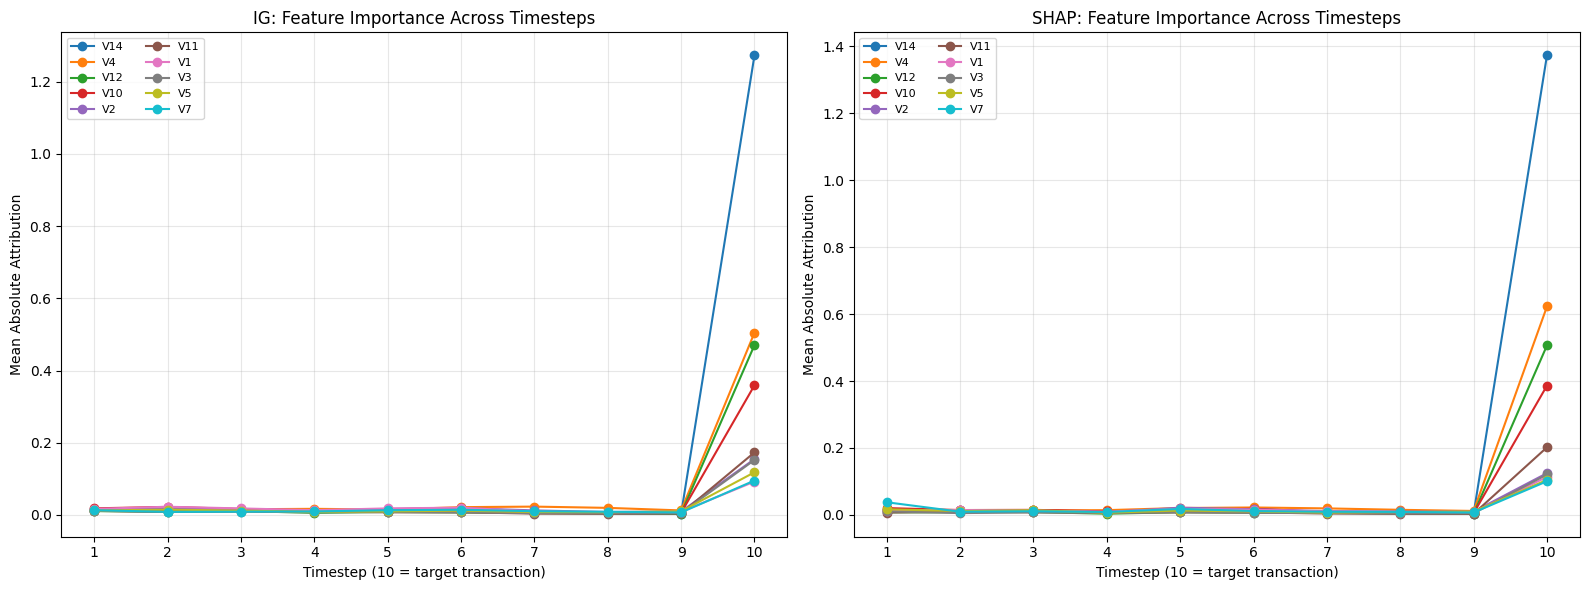

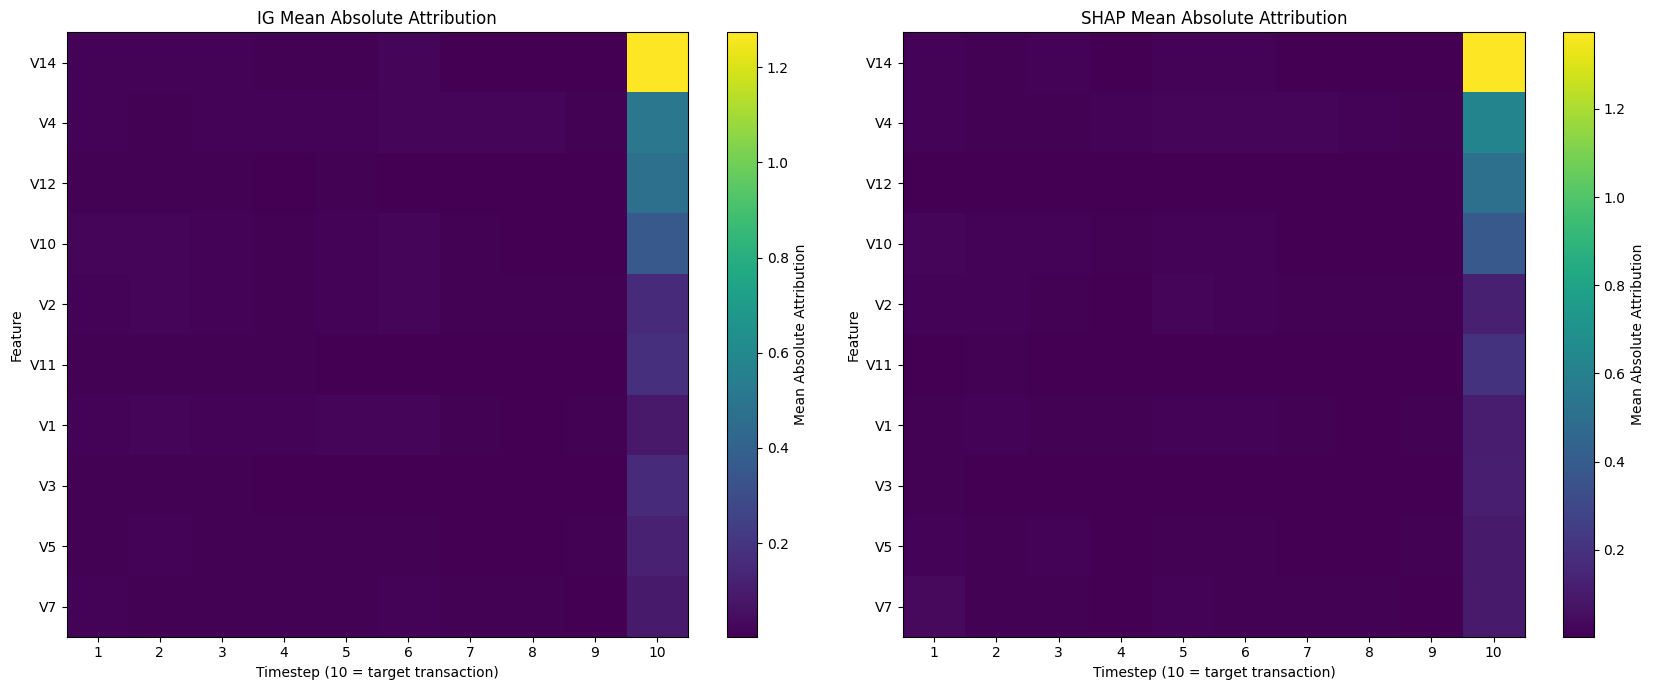


Saved files:
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_positionwise_xai.csv
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_positionwise_ig_shap_agreement.csv
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_feature_importance_profiles.png
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_xai_heatmaps.png


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Set output directory
output_dir = "/content/drive/MyDrive/fraud_detection_models"
os.makedirs(output_dir, exist_ok=True)

# Validate required variables
assert "ig_attributions" in globals(), "ig_attributions is missing."
assert "shap_attributions" in globals(), "shap_attributions is missing."
assert "feature_names" in globals(), "feature_names is missing."

ig = np.asarray(ig_attributions)
shap_values = np.asarray(shap_attributions)

assert ig.shape == shap_values.shape, (
    f"Attribution shape mismatch: IG={ig.shape}, SHAP={shap_values.shape}"
)
assert ig.ndim == 3, "Expected shape: (samples, timesteps, features)"
assert ig.shape[2] == len(feature_names), "Feature count mismatch."

n_samples, n_timesteps, n_features = ig.shape

print("Number of explained samples:", n_samples)
print("Number of timesteps:", n_timesteps)
print("Number of features:", n_features)
print("IG values finite:", np.isfinite(ig).all())
print("SHAP values finite:", np.isfinite(shap_values).all())

assert np.isfinite(ig).all(), "IG contains non-finite values."
assert np.isfinite(shap_values).all(), "SHAP contains non-finite values."

# Calculate mean absolute attribution for each feature at each timestep
ig_position_importance = np.mean(np.abs(ig), axis=0)
shap_position_importance = np.mean(np.abs(shap_values), axis=0)

# Build a long-format table
rows = []

for t in range(n_timesteps):
    for j, feature in enumerate(feature_names):
        rows.append({
            "Timestep": t + 1,
            "Position": (
                "Target transaction"
                if t == n_timesteps - 1
                else f"Previous position {n_timesteps - t - 1}"
            ),
            "Feature": feature,
            "IG_MeanAbsAttribution": ig_position_importance[t, j],
            "SHAP_MeanAbsAttribution": shap_position_importance[t, j]
        })

position_df = pd.DataFrame(rows)

# Add within-timestep feature ranks
position_df["IG_Rank"] = (
    position_df.groupby("Timestep")["IG_MeanAbsAttribution"]
    .rank(method="average", ascending=False)
)

position_df["SHAP_Rank"] = (
    position_df.groupby("Timestep")["SHAP_MeanAbsAttribution"]
    .rank(method="average", ascending=False)
)

position_csv = os.path.join(
    output_dir,
    "temporal_transformer_window10_positionwise_xai.csv"
)
position_df.to_csv(position_csv, index=False)

# Compare IG and SHAP feature rankings at each timestep
correlation_rows = []

for t in range(n_timesteps):
    ig_t = ig_position_importance[t]
    shap_t = shap_position_importance[t]

    rho, p_value = spearmanr(ig_t, shap_t)

    correlation_rows.append({
        "Timestep": t + 1,
        "Position": (
            "Target transaction"
            if t == n_timesteps - 1
            else f"Previous position {n_timesteps - t - 1}"
        ),
        "Spearman_Rank_Correlation": rho,
        "P_Value": p_value
    })

correlation_df = pd.DataFrame(correlation_rows)

correlation_csv = os.path.join(
    output_dir,
    "temporal_transformer_window10_positionwise_ig_shap_agreement.csv"
)
correlation_df.to_csv(correlation_csv, index=False)

# Identify the globally most important features across the full window
global_ig = np.mean(np.abs(ig), axis=(0, 1))
global_shap = np.mean(np.abs(shap_values), axis=(0, 1))

top_indices = np.argsort(global_ig)[::-1][:10]
top_features = [feature_names[i] for i in top_indices]

print("\nTop 10 features by global IG importance:")
print(pd.DataFrame({
    "Feature": top_features,
    "IG_MeanAbsAttribution": global_ig[top_indices],
    "SHAP_MeanAbsAttribution": global_shap[top_indices]
}).to_string(index=False))

print("\nIG-SHAP rank agreement at each timestep:")
print(correlation_df.round(5).to_string(index=False))

# Plot 1: Temporal importance profiles for the top 10 global IG features
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for feature in top_features:
    j = feature_names.index(feature)
    axes[0].plot(
        range(1, n_timesteps + 1),
        ig_position_importance[:, j],
        marker="o",
        label=feature
    )
    axes[1].plot(
        range(1, n_timesteps + 1),
        shap_position_importance[:, j],
        marker="o",
        label=feature
    )

axes[0].set_title("IG: Feature Importance Across Timesteps")
axes[1].set_title("SHAP: Feature Importance Across Timesteps")

for ax in axes:
    ax.set_xlabel("Timestep (10 = target transaction)")
    ax.set_ylabel("Mean Absolute Attribution")
    ax.set_xticks(range(1, n_timesteps + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

plt.tight_layout()

profile_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_feature_importance_profiles.png"
)
plt.savefig(profile_path, dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: Heatmaps of feature importance by timestep
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, importance, title in [
    (axes[0], ig_position_importance, "IG Mean Absolute Attribution"),
    (axes[1], shap_position_importance, "SHAP Mean Absolute Attribution")
]:
    heatmap_data = importance[:, top_indices].T

    image = ax.imshow(
        heatmap_data,
        aspect="auto",
        interpolation="nearest"
    )

    ax.set_title(title)
    ax.set_xlabel("Timestep (10 = target transaction)")
    ax.set_ylabel("Feature")
    ax.set_xticks(range(n_timesteps))
    ax.set_xticklabels(range(1, n_timesteps + 1))
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features)

    fig.colorbar(image, ax=ax, label="Mean Absolute Attribution")

plt.tight_layout()

heatmap_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_xai_heatmaps.png"
)
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved files:")
print(position_csv)
print(correlation_csv)
print(profile_path)
print(heatmap_path)

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)
from torch.utils.data import DataLoader

# Verify required objects
assert "model_final" in globals(), "model_final is missing."
assert "test_dataset_10" in globals(), "test_dataset_10 is missing."
assert "device" in globals(), "device is missing."
assert "best_threshold" in globals(), "best_threshold is missing."

model_final.eval()

# Use the fixed validation-selected threshold
fixed_threshold = float(best_threshold)

# Use the existing test dataset and preserve its original order
test_loader = DataLoader(
    test_dataset_10,
    batch_size=512,
    shuffle=False
)

all_inputs = []
all_labels = []

for batch in test_loader:
    if isinstance(batch, (tuple, list)) and len(batch) >= 2:
        x_batch, y_batch = batch[0], batch[1]
    else:
        raise ValueError(
            "Unexpected dataset output. Expected (features, labels)."
        )

    all_inputs.append(torch.as_tensor(x_batch).float())
    all_labels.append(torch.as_tensor(y_batch).reshape(-1).long())

X_test = torch.cat(all_inputs, dim=0)
y_test = torch.cat(all_labels, dim=0).cpu().numpy()

assert X_test.ndim == 3, (
    f"Expected 3D input (samples, timesteps, features), got {X_test.shape}"
)
assert X_test.shape[1] == 10, (
    f"Expected window size 10, got {X_test.shape[1]}"
)
assert len(y_test) == len(test_dataset_10)

print("Test input shape:", tuple(X_test.shape))
print("Test labels shape:", y_test.shape)
print("Test fraud cases:", int(y_test.sum()))
print("Fixed threshold:", fixed_threshold)

# Construct controlled input variants
X_full = X_test.clone()

# Preserve the target transaction, zero previous positions
X_target_only = X_test.clone()
X_target_only[:, :-1, :] = 0.0

# Evaluate the same model without retraining
def get_probabilities(model, X, batch_size=512):
    model.eval()
    probability_batches = []

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            batch_x = X[start:start + batch_size].to(device)
            logits = model(batch_x).reshape(-1)
            probabilities = torch.sigmoid(logits)
            probability_batches.append(probabilities.cpu().numpy())

    return np.concatenate(probability_batches)

prob_full = get_probabilities(model_final, X_full)
prob_target_only = get_probabilities(model_final, X_target_only)

# Calculate metrics using the unchanged threshold
def calculate_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "AP": average_precision_score(y_true, probabilities),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_true, predictions)
    }

full_metrics = calculate_metrics(
    y_test, prob_full, fixed_threshold
)
target_metrics = calculate_metrics(
    y_test, prob_target_only, fixed_threshold
)

results = pd.DataFrame([
    {"Condition": "Full 10-step window", **full_metrics},
    {"Condition": "Target transaction only", **target_metrics}
])

metric_columns = ["AP", "ROC_AUC", "Precision", "Recall", "F1", "MCC"]

# Calculate target-only minus full-window differences
difference = {
    "Condition": "Difference (target only - full)"
}
for metric in metric_columns:
    difference[metric] = (
        target_metrics[metric] - full_metrics[metric]
    )

results = pd.concat(
    [results, pd.DataFrame([difference])],
    ignore_index=True
)

print("\nTemporal context ablation results:")
print(results.round(6).to_string(index=False))

# Compare probability changes at the sample level
probability_changes = np.abs(prob_full - prob_target_only)

print("\nProbability change summary:")
print("Mean absolute probability change:",
      float(np.mean(probability_changes)))
print("Median absolute probability change:",
      float(np.median(probability_changes)))
print("95th percentile absolute probability change:",
      float(np.percentile(probability_changes, 95)))

# Save results for the research report
output_dir = "/content/drive/MyDrive/fraud_detection_models"
os.makedirs(output_dir, exist_ok=True)

results_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_context_ablation.csv"
)
results.to_csv(results_path, index=False)

probability_path = os.path.join(
    output_dir,
    "temporal_transformer_window10_context_ablation_probabilities.csv"
)

pd.DataFrame({
    "TrueLabel": y_test,
    "FullWindowProbability": prob_full,
    "TargetOnlyProbability": prob_target_only,
    "AbsoluteProbabilityChange": probability_changes
}).to_csv(probability_path, index=False)

print("\nSaved:")
print(results_path)
print(probability_path)

Test input shape: (42722, 10, 30)
Test labels shape: (42722,)
Test fraud cases: 52
Fixed threshold: 0.9980474710464478

Temporal context ablation results:
                      Condition       AP   ROC_AUC  Precision   Recall       F1      MCC
            Full 10-step window 0.755129  0.979717   0.948718 0.711538 0.813187 0.821435
        Target transaction only 0.757657  0.979352   0.948718 0.711538 0.813187 0.821435
Difference (target only - full) 0.002528 -0.000365   0.000000 0.000000 0.000000 0.000000

Probability change summary:
Mean absolute probability change: 0.0008894444908946753
Median absolute probability change: 2.7739108190871775e-05
95th percentile absolute probability change: 0.0010671397903934121

Saved:
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_context_ablation.csv
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_context_ablation_probabilities.csv


In [ ]:

import os
import json
import pandas as pd
from IPython.display import display

results_dir = "/content/drive/MyDrive/fraud_detection_models"

files_to_check = [
    "validation_model_comparison_all_windows.csv",
    "validation_model_comparison.csv",
    "validation_results_standardized.csv",
    "temporal_transformer_validation_results.json",
    "hybrid_lstm_transformer_validation_results.json",
    "temporal_transformer_window10_validation_results.json",
    "hybrid_lstm_transformer_window10_validation_results.json"
]

for filename in files_to_check:
    path = os.path.join(results_dir, filename)

    print("\n" + "=" * 80)
    print(filename)

    if not os.path.exists(path):
        print("File not found.")
        continue

    try:
        if filename.endswith(".csv"):
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            display(df)
        elif filename.endswith(".json"):
            with open(path, "r") as f:
                data = json.load(f)
            print(json.dumps(data, indent=2, ensure_ascii=False))
    except Exception as e:
        print("Could not read file:", repr(e))



validation_model_comparison_all_windows.csv
Shape: (4, 10)


,Model,Window,Best Epoch,Validation AP,Validation ROC-AUC,Precision @ 0.5,Recall @ 0.5,F1 @ 0.5,MCC @ 0.5,Confusion Matrix
0,Temporal Transformer | Window 5,5,5,0.848627,0.974440,NaN,NaN,NaN,NaN,NaN
1,Hybrid LSTM-Transformer | Window 5,5,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Temporal Transformer | Window 10,10,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Hybrid LSTM-Transformer | Window 10,10,1,0.847566,0.972641,0.727273,0.857143,0.786885,0.789246,"[[42647, 18], [8, 48]]"



validation_model_comparison.csv
Shape: (2, 10)


,Model,Best Epoch,Validation AP,ROC-AUC,Precision at 0.5,Recall at 0.5,F1 at 0.5,MCC at 0.5,False Positives,False Negatives
0,Temporal Transformer,5,0.848627,0.974440,0.458716,0.892857,0.606061,0.639381,59,6
1,Hybrid LSTM-Transformer,2,0.852485,0.979048,0.585366,0.857143,0.695652,0.707895,34,8



validation_results_standardized.csv
Shape: (4, 15)


,Model,Window_Size,Best_Epoch,Validation_AP,Validation_ROC_AUC,Threshold,Precision,Recall,F1,MCC,TN,FP,FN,TP,Validation_Fraud_Cases
0,Temporal Transformer,5,5,0.848627,0.974440,0.5,0.458716,0.892857,0.606061,0.639381,42606,59,6,50,56
1,Hybrid LSTM-Transformer,5,2,0.852485,0.979048,0.5,0.585366,0.857143,0.695652,0.707895,42631,34,8,48,56
2,Temporal Transformer,10,6,0.860858,0.982473,0.5,0.676056,0.857143,0.755906,0.760889,42642,23,8,48,56
3,Hybrid LSTM-Transformer,10,1,0.847566,0.972641,0.5,0.727273,0.857143,0.786885,0.789246,42647,18,8,48,56



temporal_transformer_validation_results.json
{
  "checkpoint": "/content/drive/MyDrive/fraud_detection_models/temporal_transformer_best.pt",
  "best_epoch": 5,
  "validation_average_precision": 0.8486267378386687,
  "validation_roc_auc": 0.9744395707421607,
  "validation_samples": 42721,
  "validation_fraud_cases": 56,
  "threshold_results": {
    "default_0.5": {
      "threshold": 0.5,
      "precision": 0.45871559633027525,
      "recall": 0.8928571428571429,
      "f1": 0.6060606060606061,
      "mcc": 0.6393806611758465,
      "confusion_matrix": [
        [
          42606,
          59
        ],
        [
          6,
          50
        ]
      ]
    },
    "validation_f1_optimal": {
      "threshold": 0.9994956254959106,
      "precision": 0.9555555555555556,
      "recall": 0.7678571428571429,
      "f1": 0.8514851485148515,
      "mcc": 0.856417815255487,
      "confusion_matrix": [
        [
          42663,
          2
        ],
        [
          13,
          43
   

In [ ]:

import os
import json

results_dir = "/content/drive/MyDrive/fraud_detection_models"

files_to_read = [
    "temporal_transformer_window10_validation_results.json",
    "hybrid_lstm_transformer_window10_validation_results.json",
    "validation_results_standardized.json"
]

for filename in files_to_read:
    path = os.path.join(results_dir, filename)
    print("\n" + "=" * 70)
    print(filename)

    if os.path.exists(path):
        with open(path, "r") as f:
            data = json.load(f)
        print(json.dumps(data, indent=2))
    else:
        print("File not found.")

print("\n" + "=" * 70)
print("Files related to thresholds, test predictions, or final evaluation:")

for filename in sorted(os.listdir(results_dir)):
    name = filename.lower()
    if any(term in name for term in [
        "threshold", "test", "prediction", "final_metric"
    ]):
        print(filename)



temporal_transformer_window10_validation_results.json
{
  "model": "Temporal Transformer",
  "window_size": 10,
  "best_epoch": 6,
  "average_precision": 0.8608575911873116,
  "roc_auc": 0.9824726691332809,
  "threshold_0.5": {
    "precision": 0.676056338028169,
    "recall": 0.8571428571428571,
    "f1": 0.7559055118110236,
    "mcc": 0.7608887792176485,
    "confusion_matrix": [
      [
        42642,
        23
      ],
      [
        8,
        48
      ]
    ]
  },
  "validation_samples": 42721,
  "validation_fraud_cases": 56
}

hybrid_lstm_transformer_window10_validation_results.json
{
  "model": "Hybrid LSTM-Transformer",
  "window_size": 10,
  "best_epoch": 1,
  "validation_average_precision": 0.8475662418454509,
  "validation_roc_auc": 0.9726406723476922,
  "threshold": 0.5,
  "precision": 0.7272727272727273,
  "recall": 0.8571428571428571,
  "f1": 0.7868852459016393,
  "mcc": 0.7892459148405484,
  "confusion_matrix": [
    [
      42647,
      18
    ],
    [
      8,
    

In [ ]:
import os
import json

results_dir = "/content/drive/MyDrive/fraud_detection_models"

for filename in sorted(os.listdir(results_dir)):
    lower_name = filename.lower()

    if any(term in lower_name for term in [
        "threshold",
        "test",
        "prediction",
        "final_metric",
        "evaluation"
    ]):
        path = os.path.join(results_dir, filename)
        print(f"\n{'=' * 60}\n{filename}")

        if filename.endswith(".json"):
            try:
                with open(path, "r") as f:
                    print(json.dumps(json.load(f), indent=2))
            except Exception as e:
                print(f"Could not read JSON: {e}")

        elif filename.endswith(".csv"):
            try:
                import pandas as pd
                df = pd.read_csv(path)
                print(df.head(10).to_string(index=False))
            except Exception as e:
                print(f"Could not read CSV: {e}")

In [ ]:
import os

results_dir = "/content/drive/MyDrive/fraud_detection_models"

print("Folder exists:", os.path.exists(results_dir))

if os.path.exists(results_dir):
    files = sorted(os.listdir(results_dir))
    print("Number of files:", len(files))

    for filename in files:
        print(filename)
else:
    print("Folder not found. Check Google Drive mounting.")

Folder exists: True
Number of files: 60
fidelity_removal_strategies.png
fidelity_topk_comparison.png
fidelity_topk_vs_random.png
final_xai_feature_comparison.csv
final_xai_fidelity_results.csv
final_xai_stability_comparison.csv
final_xai_stability_cosine_comparison.png
final_xai_stability_rank_comparison.png
hybrid_lstm_transformer_best.pt
hybrid_lstm_transformer_config.json
hybrid_lstm_transformer_training_history.json
hybrid_lstm_transformer_validation_results.json
hybrid_lstm_transformer_window10_best.pt
hybrid_lstm_transformer_window10_config.json
hybrid_lstm_transformer_window10_training_history.json
hybrid_lstm_transformer_window10_validation_results.json
local_explanation_fraud_sample_2.csv
local_explanation_fraud_sample_2.png
local_explanation_normal_sample_0.csv
local_explanation_normal_sample_0.png
logistic_regression_validation_probabilities.npy
tabular_baselines_validation.csv
temporal_transformer_best.pt
temporal_transformer_config.json
temporal_transformer_training_histor

In [ ]:
import os
import json

results_dir = "/content/drive/MyDrive/fraud_detection_models"

files_to_read = [
    "temporal_transformer_window10_config.json",
    "temporal_transformer_config.json",
    "temporal_transformer_window10_validation_results.json",
    "temporal_transformer_validation_results.json",
]

for filename in files_to_read:
    path = os.path.join(results_dir, filename)

    print(f"\n{'=' * 60}")
    print(filename)

    if os.path.exists(path):
        with open(path, "r") as f:
            data = json.load(f)
        print(json.dumps(data, indent=2))
    else:
        print("File not found.")


temporal_transformer_window10_config.json
{
  "model_name": "Temporal Transformer",
  "window_size": 10,
  "input_dim": 30,
  "d_model": 64,
  "n_heads": 4,
  "num_layers": 2,
  "dim_feedforward": 128,
  "dropout": 0.1,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "max_epochs": 30,
  "patience": 5,
  "gradient_clip_norm": 1.0,
  "seed": 42,
  "selection_metric": "validation_average_precision",
  "best_epoch": 6,
  "best_validation_average_precision": 0.8608575911873116
}

temporal_transformer_config.json
{
  "seed": 42,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "max_epochs": 30,
  "patience": 5,
  "gradient_clip_norm": 1.0,
  "window_size": 5,
  "input_dim": 30,
  "model": "TemporalTransformer",
  "checkpoint_selection": "Validation Average Precision"
}

temporal_transformer_window10_validation_results.json
{
  "model": "Temporal Transformer",
  "window_size": 10,
  "best_epoch": 6,
  "average_precision": 0.8608575911873116,
  "roc_auc": 0.9824726691332809,
  "thr

In [ ]:
import os

print("Threshold variable exists:", "best_threshold" in globals())

if "best_threshold" in globals():
    print("best_threshold =", best_threshold)

print("\nVariables related to thresholds, predictions, and test data:")
for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "threshold", "test_pred", "test_prob",
        "test_logits", "test_labels", "y_test"
    ]):
        try:
            value = globals()[name]
            print(name, "| type:", type(value).__name__)
        except Exception:
            print(name)

results_dir = "/content/drive/MyDrive/fraud_detection_models"

print("\nSaved files potentially related to predictions or thresholds:")
for filename in sorted(os.listdir(results_dir)):
    if any(term in filename.lower() for term in [
        "pred", "prob", "threshold", "test"
    ]):
        print(filename)

Threshold variable exists: True
best_threshold = 0.9980474710464478

Variables related to thresholds, predictions, and test data:
TEST_THRESHOLD | type: float
best_threshold | type: float
best_threshold_predictions | type: ndarray
best_validation_threshold | type: float
default_threshold | type: float
fixed_threshold | type: float
sample_y_test | type: Tensor
test_labels | type: ndarray
test_labels_list | type: list
test_labels_np | type: ndarray
test_predictions | type: ndarray
test_probs | type: ndarray
test_probs_list | type: list
threshold | type: float
threshold_default | type: float
threshold_df | type: DataFrame
threshold_f1 | type: float
threshold_name | type: str
threshold_results | type: dict
thresholds | type: ndarray
thresholds_to_compare | type: list
y_test | type: ndarray
y_test_array | type: ndarray

Saved files potentially related to predictions or thresholds:
logistic_regression_validation_probabilities.npy
temporal_transformer_window10_context_ablation_probabilities.c

In [ ]:
import os

print("Current working directory:", os.getcwd())

print("\nPossible dataset files:")
for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        ".config", "sample_data", "__pycache__"
    ]]

    for filename in files:
        if filename.lower().endswith((".csv", ".parquet", ".pkl", ".joblib")):
            print(os.path.join(root, filename))

print("\nRelevant existing variables:")
for name in [
    "df", "data", "X_train", "X_val", "X_test",
    "y_train", "y_val", "y_test",
    "scaler", "amount_scaler", "delta_scaler",
    "test_dataset_10", "feature_names"
]:
    if name in globals():
        value = globals()[name]
        shape = getattr(value, "shape", None)
        print(name, "| type:", type(value).__name__, "| shape:", shape)

Current working directory: /content

Possible dataset files:
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_ig_stability_summary.csv
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_shap_stability.csv
/content/drive/MyDrive/fraud_detection_models/local_explanation_normal_sample_0.csv
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_positionwise_xai.csv
/content/drive/MyDrive/fraud_detection_models/final_xai_feature_comparison.csv
/content/drive/MyDrive/fraud_detection_models/final_xai_stability_comparison.csv
/content/drive/MyDrive/fraud_detection_models/validation_model_comparison.csv
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_context_ablation_probabilities.csv
/content/drive/MyDrive/fraud_detection_models/final_xai_fidelity_results.csv
/content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_shap_global_importance.csv
/content/drive/MyDrive/fraud_dete

In [ ]:
import os

drive_root = "/content/drive/MyDrive"

print("Searching Google Drive for likely dataset files...\n")

extensions = (".csv", ".parquet", ".pkl", ".joblib", ".xlsx")

for root, dirs, files in os.walk(drive_root):
    dirs[:] = [
        d for d in dirs
        if d not in [".Trash", ".ipynb_checkpoints"]
    ]

    for filename in files:
        lower = filename.lower()

        if lower.endswith(extensions) and any(
            word in lower
            for word in [
                "fraud", "credit", "transaction",
                "dataset", "preprocess", "train", "test"
            ]
        ):
            print(os.path.join(root, filename))

Searching Google Drive for likely dataset files...

/content/drive/MyDrive/fraud_detection_models/local_explanation_fraud_sample_2.csv


In [ ]:

# Stage 1: Local backup and runtime diagnostic
# No model training and no test-set evaluation.

from pathlib import Path
import json
import os
import numpy as np
import pandas as pd
import torch

BACKUP_DIR = Path("/content/fraud_project_backup")
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("RUNTIME DIAGNOSTIC")
print("=" * 65)

important_variables = [
    "df",
    "X_train_scaled",
    "X_validation_scaled",
    "X_test_scaled",
    "X_train_base",
    "X_validation_base",
    "X_test_base",
    "y_train_array",
    "y_validation_array",
    "y_test_array",
    "train_dataset_10",
    "validation_dataset_10",
    "test_dataset_10",
    "model_final",
    "validation_probs",
    "validation_labels",
    "best_threshold",
    "device",
]

status = {}

for name in important_variables:
    exists = name in globals()
    status[name] = exists
    print(f"{name}: {'AVAILABLE' if exists else 'MISSING'}")

# Save a diagnostic manifest.
with open(BACKUP_DIR / "runtime_manifest.json", "w") as f:
    json.dump(status, f, indent=2)

# Save available tabular data without modifying the original objects.
dataframe_names = [
    "X_train_scaled",
    "X_validation_scaled",
    "X_test_scaled",
    "validation_results_standardized",
]

for name in dataframe_names:
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(BACKUP_DIR / f"{name}.csv", index=False)
        print(f"Saved DataFrame: {name}.csv")

# Save available label arrays.
array_names = [
    "y_train_array",
    "y_validation_array",
    "y_test_array",
    "validation_labels",
    "validation_probs",
]

for name in array_names:
    obj = globals().get(name)
    if obj is not None:
        try:
            np.save(BACKUP_DIR / f"{name}.npy", np.asarray(obj))
            print(f"Saved array: {name}.npy")
        except Exception as exc:
            print(f"Could not save {name}: {exc}")

# Save available threshold information.
threshold_info = {}

for name in [
    "best_threshold",
    "best_validation_threshold",
    "fixed_threshold",
]:
    if name in globals():
        threshold_info[name] = float(globals()[name])

with open(BACKUP_DIR / "thresholds.json", "w") as f:
    json.dump(threshold_info, f, indent=2)

print("\nBackup directory:", BACKUP_DIR)
print("Files created:", sorted(p.name for p in BACKUP_DIR.iterdir()))


RUNTIME DIAGNOSTIC
df: AVAILABLE
X_train_scaled: AVAILABLE
X_validation_scaled: AVAILABLE
X_test_scaled: AVAILABLE
X_train_base: AVAILABLE
X_validation_base: AVAILABLE
X_test_base: AVAILABLE
y_train_array: AVAILABLE
y_validation_array: AVAILABLE
y_test_array: AVAILABLE
train_dataset_10: AVAILABLE
validation_dataset_10: AVAILABLE
test_dataset_10: AVAILABLE
model_final: AVAILABLE
validation_probs: AVAILABLE
validation_labels: AVAILABLE
best_threshold: AVAILABLE
device: AVAILABLE
Saved DataFrame: X_train_scaled.csv
Saved DataFrame: X_validation_scaled.csv
Saved DataFrame: X_test_scaled.csv
Saved array: y_train_array.npy
Saved array: y_validation_array.npy
Saved array: y_test_array.npy
Saved array: validation_labels.npy
Saved array: validation_probs.npy

Backup directory: /content/fraud_project_backup
Files created: ['X_test_scaled.csv', 'X_train_scaled.csv', 'X_validation_scaled.csv', 'runtime_manifest.json', 'thresholds.json', 'validation_labels.npy', 'validation_probs.npy', 'y_test_arra

In [ ]:

# Package the local backup for download.
# This does not require Google Drive.

import shutil
from pathlib import Path

backup_dir = Path("/content/fraud_project_backup")
zip_path = shutil.make_archive(
    "/content/fraud_project_backup",
    "zip",
    root_dir=backup_dir
)

print("Backup archive created:", zip_path)

from IPython.display import display, FileLink
display(FileLink(zip_path))


Backup archive created: /content/fraud_project_backup.zip


/content/fraud_project_backup.zip

In [ ]:
import os

backup_path = "/content/fraud_project_backup.zip"

if os.path.exists(backup_path):
    print("Backup file exists.")
    print(f"File size: {os.path.getsize(backup_path) / (1024**2):.2f} MB")
else:
    print("Backup file not found.")

Backup file exists.
File size: 66.38 MB


In [ ]:
import numpy as np

print("=" * 50)
print("EVALUATION STATUS")
print("=" * 50)

print("Model loaded:", model_final is not None)
print("Validation probabilities shape:", np.shape(validation_probs))
print("Validation labels shape:", np.shape(validation_labels))
print("Selected threshold:", best_threshold)

print("Validation labels:", np.unique(validation_labels, return_counts=True))
print("Probabilities finite:", np.isfinite(validation_probs).all())
print("Probability range:", (float(np.min(validation_probs)),
                             float(np.max(validation_probs))))

EVALUATION STATUS
Model loaded: True
Validation probabilities shape: (42721,)
Validation labels shape: (42721,)
Selected threshold: 0.9980474710464478
Validation labels: (array([0, 1]), array([42665,    56]))
Probabilities finite: True
Probability range: (0.00037693511694669724, 0.9998143315315247)


In [ ]:
import numpy as np

print("=" * 50)
print("TEST EVALUATION PRE-CHECK")
print("=" * 50)

# Check whether test predictions already exist
for name in [
    "test_probs",
    "test_probabilities",
    "test_predictions",
    "test_labels",
    "test_threshold",
    "threshold_results",
    "threshold_table"
]:
    if name in globals():
        value = globals()[name]
        try:
            print(f"{name}: available, shape={np.shape(value)}")
        except Exception:
            print(f"{name}: available, type={type(value).__name__}")

# Check the threshold-related variables
for name in [
    "best_threshold",
    "thresholds",
    "best_f1_threshold",
    "validation_probs",
    "validation_labels"
]:
    if name in globals():
        print(f"{name}: available")

print("\nPre-check completed. No model training performed.")

TEST EVALUATION PRE-CHECK
test_probs: available, shape=(42722,)
test_predictions: available, shape=(42722,)
test_labels: available, shape=(42722,)
threshold_results: available, shape=()
best_threshold: available
thresholds: available
validation_probs: available
validation_labels: available

Pre-check completed. No model training performed.


In [ ]:
import os
import json
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

# Use the threshold selected on the validation set
threshold = float(best_threshold)

probs = np.asarray(test_probs).reshape(-1)
y_true = np.asarray(test_labels).reshape(-1)

assert len(probs) == len(y_true), "Prediction and label lengths do not match."
assert np.isfinite(probs).all(), "Test probabilities contain non-finite values."
assert set(np.unique(y_true)).issubset({0, 1}), "Labels must be binary."

y_pred = (probs >= threshold).astype(int)

results = {
    "threshold_source": "validation",
    "threshold": threshold,
    "test_samples": int(len(y_true)),
    "test_fraud_cases": int(np.sum(y_true == 1)),
    "average_precision_pr_auc": float(average_precision_score(y_true, probs)),
    "roc_auc": float(roc_auc_score(y_true, probs)),
    "precision": float(precision_score(y_true, y_pred, zero_division=0)),
    "recall": float(recall_score(y_true, y_pred, zero_division=0)),
    "f1": float(f1_score(y_true, y_pred, zero_division=0)),
    "mcc": float(matthews_corrcoef(y_true, y_pred)),
    "confusion_matrix_tn_fp_fn_tp": confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel().tolist()
}

output_dir = "/content/fraud_project_backup"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "final_test_evaluation.json")
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("=" * 50)
print("FINAL TEST EVALUATION")
print("=" * 50)

for key, value in results.items():
    print(f"{key}: {value}")

print(f"\nResults saved to: {output_path}")

FINAL TEST EVALUATION
threshold_source: validation
threshold: 0.9980474710464478
test_samples: 42722
test_fraud_cases: 52
average_precision_pr_auc: 0.7551290566317035
roc_auc: 0.979716653747003
precision: 0.9487179487179487
recall: 0.7115384615384616
f1: 0.8131868131868132
mcc: 0.8214346011341345
confusion_matrix_tn_fp_fn_tp: [42668, 2, 15, 37]

Results saved to: /content/fraud_project_backup/final_test_evaluation.json


In [ ]:
import os
import json
import zipfile
import numpy as np
import pandas as pd

backup_dir = "/content/fraud_project_backup"
os.makedirs(backup_dir, exist_ok=True)

# Save test predictions with their true labels
predictions_df = pd.DataFrame({
    "y_true": np.asarray(test_labels).astype(int),
    "fraud_probability": np.asarray(test_probs, dtype=float),
    "y_pred": (np.asarray(test_probs) >= float(best_threshold)).astype(int)
})

predictions_path = os.path.join(backup_dir, "test_predictions.csv")
predictions_df.to_csv(predictions_path, index=False)

# Save a concise experiment summary
summary = {
    "model": "Temporal Transformer",
    "window_size": 10,
    "threshold_source": "validation",
    "threshold": float(best_threshold),
    "test_samples": int(len(test_labels)),
    "test_fraud_cases": int(np.sum(np.asarray(test_labels) == 1)),
    "average_precision_pr_auc": 0.7551290566317035,
    "roc_auc": 0.979716653747003,
    "precision": 0.9487179487179487,
    "recall": 0.7115384615384616,
    "f1": 0.8131868131868132,
    "mcc": 0.8214346011341345,
    "confusion_matrix_tn_fp_fn_tp": [42668, 2, 15, 37]
}

summary_path = os.path.join(backup_dir, "experiment_summary.json")
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

# Include available final artifacts and update the ZIP
zip_path = "/content/fraud_project_backup_final.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(backup_dir):
        for filename in files:
            full_path = os.path.join(root, filename)
            z.write(full_path, arcname=os.path.relpath(full_path, backup_dir))

    # Include the previous backup archive if it still exists
    previous_zip = "/content/fraud_project_backup.zip"
    if os.path.exists(previous_zip):
        z.write(previous_zip, arcname="previous_backup.zip")

print("Final backup created:", zip_path)
print("Size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))
print("Saved files:")
print("-", predictions_path)
print("-", summary_path)

Final backup created: /content/fraud_project_backup_final.zip
Size (MB): 133.15
Saved files:
- /content/fraud_project_backup/test_predictions.csv
- /content/fraud_project_backup/experiment_summary.json


In [ ]:
from google.colab import files
files.download("/content/fraud_project_backup_final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

search_roots = [
    "/content/fraud_project_backup",
    "/content",
]

keywords = [
    "shap",
    "integrated",
    "gradient",
    "explain",
    "xai",
    "attribution",
    "baseline",
    "transformer",
    "checkpoint",
    "model",
]

seen = set()

print("=" * 60)
print("EXISTING MODEL AND XAI ARTIFACTS")
print("=" * 60)

for root in search_roots:
    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):
        # Avoid scanning large mounted or system directories
        dirs[:] = [
            d for d in dirs
            if d not in {"site-packages", ".cache", "node_modules"}
        ]

        for filename in files:
            lower_name = filename.lower()

            if any(keyword in lower_name for keyword in keywords):
                full_path = os.path.join(current_root, filename)

                if full_path not in seen:
                    seen.add(full_path)
                    size_mb = os.path.getsize(full_path) / (1024 ** 2)
                    print(f"{filename} | {size_mb:.2f} MB | {full_path}")

print(f"\nTotal matching files: {len(seen)}")

EXISTING MODEL AND XAI ARTIFACTS
temporal_transformer_training_history.json | 0.00 MB | /content/fraud_detection_models/temporal_transformer_training_history.json
temporal_transformer_best.pt | 0.84 MB | /content/fraud_detection_models/temporal_transformer_best.pt
temporal_transformer_window10_best.pt | 0.29 MB | /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_best.pt
temporal_transformer_window10_validation_results.json | 0.00 MB | /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_validation_results.json
temporal_transformer_window10_ig_stability_summary.csv | 0.00 MB | /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_ig_stability_summary.csv
temporal_transformer_window10_shap_stability.csv | 0.00 MB | /content/drive/MyDrive/fraud_detection_models/temporal_transformer_window10_shap_stability.csv
temporal_transformer_window10_shap_attributions_8samples.npy | 0.02 MB | /content/drive/MyDrive/fraud_detection

In [ ]:
import os
import json
import numpy as np
import pandas as pd

ARTIFACT_DIRS = [
    "/content/drive/MyDrive/fraud_detection_models",
    "/content/fraud_detection_models",
    "/content/fraud_project_backup"
]

artifact_dir = next(
    (p for p in ARTIFACT_DIRS if os.path.isdir(p)),
    None
)

if artifact_dir is None:
    raise FileNotFoundError("No existing model artifact directory was found.")

print("Artifact directory:", artifact_dir)

files_to_check = [
    "temporal_transformer_window10_config.json",
    "temporal_transformer_window10_validation_results.json",
    "temporal_transformer_window10_ig_global_importance.csv",
    "temporal_transformer_window10_shap_global_importance.csv",
    "temporal_transformer_window10_fidelity_results.csv",
    "temporal_transformer_window10_ig_stability_summary.csv",
    "temporal_transformer_window10_ig_vs_shap_summary.csv",
    "tabular_baselines_validation.csv",
    "validation_model_comparison.csv"
]

for filename in files_to_check:
    path = os.path.join(artifact_dir, filename)

    if not os.path.isfile(path):
        print(f"\nMISSING: {filename}")
        continue

    print(f"\n--- {filename} ---")

    try:
        if filename.endswith(".json"):
            with open(path, "r", encoding="utf-8") as f:
                print(json.dumps(json.load(f), indent=2)[:4000])

        elif filename.endswith(".csv"):
            table = pd.read_csv(path)
            print("Shape:", table.shape)
            print(table.head(8).to_string(index=False))

    except Exception as exc:
        print("Could not read file:", repr(exc))

print("\n--- Attribution array shapes ---")

for filename in [
    "temporal_transformer_window10_ig_attributions.npy",
    "temporal_transformer_window10_shap_attributions_252samples.npy",
    "temporal_transformer_window10_shap_sample_indices.npy",
    "temporal_transformer_window10_ig_labels.npy"
]:
    path = os.path.join(artifact_dir, filename)

    if os.path.isfile(path):
        arr = np.load(path, mmap_mode="r")
        print(f"{filename}: shape={arr.shape}, dtype={arr.dtype}")
    else:
        print(f"MISSING: {filename}")

Artifact directory: /content/drive/MyDrive/fraud_detection_models

--- temporal_transformer_window10_config.json ---
{
  "model_name": "Temporal Transformer",
  "window_size": 10,
  "input_dim": 30,
  "d_model": 64,
  "n_heads": 4,
  "num_layers": 2,
  "dim_feedforward": 128,
  "dropout": 0.1,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "max_epochs": 30,
  "patience": 5,
  "gradient_clip_norm": 1.0,
  "seed": 42,
  "selection_metric": "validation_average_precision",
  "best_epoch": 6,
  "best_validation_average_precision": 0.8608575911873116
}

--- temporal_transformer_window10_validation_results.json ---
{
  "model": "Temporal Transformer",
  "window_size": 10,
  "best_epoch": 6,
  "average_precision": 0.8608575911873116,
  "roc_auc": 0.9824726691332809,
  "threshold_0.5": {
    "precision": 0.676056338028169,
    "recall": 0.8571428571428571,
    "f1": 0.7559055118110236,
    "mcc": 0.7608887792176485,
    "confusion_matrix": [
      [
        42642,
        23
      ],
   

In [ ]:
import os

artifact_dir = "/content/drive/MyDrive/fraud_detection_models"

keywords = [
    "stability",
    "fidelity",
    "feature_comparison",
    "positionwise",
    "comparison",
    "baseline",
    "test_evaluation",
    "final_test"
]

for filename in sorted(os.listdir(artifact_dir)):
    if any(key in filename.lower() for key in keywords):
        path = os.path.join(artifact_dir, filename)
        if os.path.isfile(path):
            print(f"{filename}  |  {os.path.getsize(path):,} bytes")

fidelity_removal_strategies.png  |  157,710 bytes
fidelity_topk_comparison.png  |  119,007 bytes
fidelity_topk_vs_random.png  |  130,114 bytes
final_xai_feature_comparison.csv  |  1,517 bytes
final_xai_fidelity_results.csv  |  630 bytes
final_xai_stability_comparison.csv  |  628 bytes
final_xai_stability_cosine_comparison.png  |  109,515 bytes
final_xai_stability_rank_comparison.png  |  151,491 bytes
tabular_baselines_validation.csv  |  368 bytes
temporal_transformer_window10_fidelity_results.csv  |  665 bytes
temporal_transformer_window10_ig_stability_noise_levels.csv  |  353 bytes
temporal_transformer_window10_ig_stability_noise_levels.png  |  226,568 bytes
temporal_transformer_window10_ig_stability_per_sample.csv  |  862 bytes
temporal_transformer_window10_ig_stability_summary.csv  |  221 bytes
temporal_transformer_window10_ig_vs_shap_comparison.csv  |  1,575 bytes
temporal_transformer_window10_positionwise_ig_shap_agreement.csv  |  682 bytes
temporal_transformer_window10_positionwi

In [ ]:
import os
import pandas as pd

artifact_dir = "/content/drive/MyDrive/fraud_detection_models"

files = [
    "final_xai_stability_comparison.csv",
    "final_xai_fidelity_results.csv",
    "final_xai_feature_comparison.csv",
    "temporal_transformer_window10_ig_stability_noise_levels.csv",
    "temporal_transformer_window10_shap_stability.csv",
    "validation_model_comparison_all_windows.csv"
]

for filename in files:
    path = os.path.join(artifact_dir, filename)
    print(f"\n{'=' * 70}\n{filename}\n{'=' * 70}")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("File not found.")


final_xai_stability_comparison.csv
Method  NoiseSigma  MeanCosineSimilarity  StdCosineSimilarity  GlobalFeatureRankSpearman  SpearmanPValue
    IG        0.01              0.999873             0.000163                   0.999555    2.910288e-44
  SHAP        0.01              0.884931             0.203200                   0.996440    1.255979e-31
    IG        0.05              0.996873             0.004119                   0.999110    4.755359e-40
  SHAP        0.05              0.899866             0.138439                   0.996440    1.255979e-31
    IG        0.10              0.988058             0.015258                   0.998220    7.749207e-36
  SHAP        0.10              0.899671             0.142183                   0.996885    1.942090e-32

final_xai_fidelity_results.csv
Method  K_Features  TopK_MeanAbsProbabilityChange  BottomK_MeanAbsProbabilityChange  RandomK_MeanAbsProbabilityChange  TopK_vs_Random_Difference
    IG           3                       0.128762   

In [ ]:
import os
import json
import pandas as pd

artifact_dir = "/content/drive/MyDrive/fraud_detection_models"

files = [
    "final_test_evaluation.json",
    "temporal_transformer_window10_validation_results.json",
    "validation_model_comparison.json",
    "validation_model_comparison_all_windows.json",
    "tabular_baselines_validation.csv",
]

for filename in files:
    path = os.path.join(artifact_dir, filename)
    print(f"\n{'=' * 60}\n{filename}\n{'=' * 60}")

    if not os.path.exists(path):
        print("File not found.")
        continue

    if filename.endswith(".json"):
        with open(path, "r") as f:
            print(json.dumps(json.load(f), indent=2))
    else:
        print(pd.read_csv(path).to_string(index=False))


final_test_evaluation.json
File not found.

temporal_transformer_window10_validation_results.json
{
  "model": "Temporal Transformer",
  "window_size": 10,
  "best_epoch": 6,
  "average_precision": 0.8608575911873116,
  "roc_auc": 0.9824726691332809,
  "threshold_0.5": {
    "precision": 0.676056338028169,
    "recall": 0.8571428571428571,
    "f1": 0.7559055118110236,
    "mcc": 0.7608887792176485,
    "confusion_matrix": [
      [
        42642,
        23
      ],
      [
        8,
        48
      ]
    ]
  },
  "validation_samples": 42721,
  "validation_fraud_cases": 56
}

validation_model_comparison.json
{
  "evaluation_split": "Validation",
  "common_classification_threshold": 0.5,
  "test_set_evaluated": false,
  "models": {
    "Temporal Transformer": {
      "best_epoch": 5,
      "average_precision": 0.8486267378386687,
      "roc_auc": 0.9744395707421607,
      "default_metrics": {
        "threshold": 0.5,
        "precision": 0.45871559633027525,
        "recall": 0.892

In [ ]:
import os

artifact_dir = "/content/drive/MyDrive/fraud_detection_models"

for filename in sorted(os.listdir(artifact_dir)):
    if any(word in filename.lower() for word in ["test", "evaluation", "prediction", "score", "threshold"]):
        path = os.path.join(artifact_dir, filename)
        print(filename, "|", round(os.path.getsize(path) / 1024, 1), "KB")

xai_ext_randomization_test.csv | 0.3 KB


In [ ]:
# =====================================================================
# XAI evaluation extension (paste each "# %%" block as a new Colab cell,
# AFTER the last XAI cell of the notebook, in the same runtime).
#
# Required variables already in memory (created by your notebook):
#   model_final, test_dataset_10, train_dataset_10, test_labels,
#   xai_indices, ig_attributions (252,10,30), shap_attributions (252,10,30),
#   feature_names, shap_explainer, device, X_all, validation_end
# Optional: xgb (trained in Stage 4.10) for the cross-model check.
# Test data is used ONLY for post-hoc explanation, never for selection.
# =====================================================================

# %% Block 0: setup and sanity checks
import os, copy, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.stats import spearmanr
from captum.attr import IntegratedGradients

OUT = "/content/drive/MyDrive/fraud_detection_models"
os.makedirs(OUT, exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
model_final.eval()

xai_idx = np.asarray(xai_indices).astype(int)
xai_x = torch.stack([test_dataset_10[int(i)][0] for i in xai_idx]).float().to(device)
xai_y = np.asarray(test_labels).astype(int)[xai_idx]
IG_A = np.asarray(ig_attributions)
SH_A = np.asarray(shap_attributions)
assert IG_A.shape == SH_A.shape == (len(xai_idx), 10, 30)
assert xai_x.shape == (len(xai_idx), 10, 30)
print("Samples:", len(xai_idx), "| fraud:", int(xai_y.sum()), "| normal:", int((xai_y == 0).sum()))

fraud_pos = np.where(xai_y == 1)[0]
normal_pos = np.where(xai_y == 0)[0]
# Balanced subset (32 fraud + 32 normal) used for the costly experiments.
bal_pos = np.r_[fraud_pos[:32], normal_pos[:32]]


@torch.no_grad()
def logits_of(model, x, bs=256):
    model.eval()
    out = []
    for s in range(0, len(x), bs):
        out.append(model(x[s:s + bs].to(device)).reshape(-1).cpu())
    return torch.cat(out).numpy()


def ig_attr(model, x, n_steps=32, bs=16, baseline=None):
    model.eval()
    ig = IntegratedGradients(model)
    res = []
    for s in range(0, len(x), bs):
        b = x[s:s + bs]
        base = torch.zeros_like(b) if baseline is None else baseline[s:s + bs]
        res.append(ig.attribute(b, baselines=base, n_steps=n_steps).detach().cpu().numpy())
    return np.concatenate(res)


# Check that the stored IG attributions can be reproduced (determinism check).
re_ig = ig_attr(model_final, xai_x[bal_pos[:8]])
print("IG reproducibility (max abs diff, 8 samples):",
      float(np.abs(re_ig - IG_A[bal_pos[:8]]).max()))


# %% Block 1: model-randomization sanity check (Adebayo et al., 2018)
# If explanations come from what the model learned, randomizing weights
# should destroy them. Layers are randomized cumulatively from the top.
def reinit(module):
    for m in module.modules():
        if isinstance(m, nn.MultiheadAttention):
            m._reset_parameters()
        elif hasattr(m, "reset_parameters"):
            m.reset_parameters()


stages = [
    ("original", []),
    ("head randomized", ["classification_head"]),
    ("+ encoder layer 2", ["classification_head", "transformer_encoder.layers.1"]),
    ("+ encoder layer 1", ["classification_head", "transformer_encoder.layers.1",
                           "transformer_encoder.layers.0"]),
    ("+ input projection (all random)", ["classification_head",
                                         "transformer_encoder.layers.1",
                                         "transformer_encoder.layers.0",
                                         "input_projection"]),
]
x_bal = xai_x[bal_pos]
ref = IG_A[bal_pos]
rows = []
for name, targets in stages:
    torch.manual_seed(SEED)
    m = copy.deepcopy(model_final)
    for t in targets:
        reinit(m.get_submodule(t))
    m.eval()
    a = ref if not targets else ig_attr(m, x_bal)
    per_sample = [spearmanr(np.abs(ref[i]).ravel(), np.abs(a[i]).ravel())[0] for i in range(len(bal_pos))]
    glob = spearmanr(np.abs(ref).mean((0, 1)), np.abs(a).mean((0, 1)))[0]
    rows.append({"Stage": name,
                 "Mean_sample_Spearman": float(np.nanmean(per_sample)),
                 "Global_feature_Spearman": float(glob)})
rand_df = pd.DataFrame(rows)
print(rand_df.round(4).to_string(index=False))
rand_df.to_csv(f"{OUT}/xai_ext_randomization_test.csv", index=False)
# Expectation: correlations fall toward ~0 as more layers are randomized.


# %% Block 2: deletion and insertion curves (two baselines, logit scale)
# Local ranking per sample = signed attribution summed over time steps.
# Deletion: replace top-k features (all 10 steps) by a baseline, track logit.
# Insertion: start from the baseline, add top-k features back.
K_MAX = 15
pool_ids = rng.choice(len(train_dataset_10), size=512, replace=False)
pool = torch.stack([train_dataset_10[int(j)][0] for j in pool_ids]).float().to(device)


def make_baseline(kind, n):
    if kind == "zero":
        return torch.zeros(n, 10, 30, device=device)
    return pool[torch.as_tensor(rng.integers(0, len(pool), n), device=device)]


def curve(order, mode, kind, x, repeats):
    n = len(x)
    ks = list(range(K_MAX + 1))
    acc = np.zeros((repeats, len(ks), n))
    for r in range(repeats):
        base = make_baseline(kind, n)
        for k in ks:
            mask = torch.zeros(n, 30, dtype=torch.bool, device=device)
            if k > 0:
                mask.scatter_(1, torch.as_tensor(order[:, :k], device=device), True)
            m3 = mask[:, None, :]
            xp = torch.where(m3, base, x) if mode == "deletion" else torch.where(m3, x, base)
            acc[r, k] = logits_of(model_final, xp)
    return acc.mean(0)  # (K+1, n)


loc_ig = IG_A.sum(1)
loc_sh = SH_A.sum(1)
orders = {
    "IG": np.argsort(-loc_ig, axis=1),
    "SHAP": np.argsort(-loc_sh, axis=1),
    "Random": np.stack([rng.permutation(30) for _ in range(len(xai_idx))]),
    "Least important (IG)": np.argsort(loc_ig, axis=1),
}
res = []
for subset_name, pos in [("Fraud", fraud_pos), ("Normal", normal_pos)]:
    for kind in ["zero", "train_marginal"]:
        for mode in ["deletion", "insertion"]:
            for name, order in orders.items():
                reps = 10 if name == "Random" else (1 if kind == "zero" else 5)
                c = curve(order[pos], mode, kind, xai_x[pos], reps)  # (K+1, n)
                mean_curve = c.mean(1)
                auc = float(np.trapz(mean_curve, dx=1) / K_MAX)
                res.append({"Subset": subset_name, "Baseline": kind, "Mode": mode,
                            "Ranking": name, "MeanLogitAUC": auc,
                            "Logit_k0": float(mean_curve[0]), f"Logit_k{K_MAX}": float(mean_curve[-1])})
curve_df = pd.DataFrame(res)
print(curve_df.round(3).to_string(index=False))
curve_df.to_csv(f"{OUT}/xai_ext_deletion_insertion.csv", index=False)
# Reading guide (Fraud subset): deletion AUC should be LOWEST for IG/SHAP,
# insertion AUC HIGHEST for IG/SHAP, with Random in between and
# "Least important" on the opposite side.


# %% Block 3: bootstrap confidence intervals and class-wise importance
per_sample_imp = np.abs(IG_A).mean(1)  # (N, 30)
B = 1000
boot = np.zeros((B, 30))
top5_hits = np.zeros(30)
for b in range(B):
    ids = rng.integers(0, len(per_sample_imp), len(per_sample_imp))
    g = per_sample_imp[ids].mean(0)
    boot[b] = g
    top5_hits[np.argsort(-g)[:5]] += 1
ci = pd.DataFrame({
    "Feature": feature_names,
    "IG_mean": per_sample_imp.mean(0),
    "CI_low": np.percentile(boot, 2.5, axis=0),
    "CI_high": np.percentile(boot, 97.5, axis=0),
    "P_in_top5": top5_hits / B,
    "IG_fraud_only": per_sample_imp[fraud_pos].mean(0),
    "IG_normal_only": per_sample_imp[normal_pos].mean(0),
}).sort_values("IG_mean", ascending=False)
print(ci.head(12).round(4).to_string(index=False))
ci.to_csv(f"{OUT}/xai_ext_bootstrap_importance.csv", index=False)


# %% Block 4: SHAP repeatability across random seeds (same inputs)
def shap_global(seed, x):
    torch.manual_seed(seed)
    np.random.seed(seed)
    v = shap_explainer.shap_values(x, nsamples=100)
    v = np.asarray(v[0] if isinstance(v, list) else v)
    if v.ndim == 4 and v.shape[-1] == 1:
        v = v[..., 0]
    return np.abs(v).mean((0, 1))


seeds = [0, 1, 2, 3, 4]
G = np.stack([shap_global(s, xai_x[bal_pos]) for s in seeds])
pair = [spearmanr(G[i], G[j])[0] for i in range(len(seeds)) for j in range(i + 1, len(seeds))]
top4 = [tuple(sorted(np.argsort(-g)[:4])) for g in G]
print("Pairwise Spearman between SHAP runs: mean=%.4f min=%.4f" % (np.mean(pair), np.min(pair)))
print("Top-4 identical in all runs:", len(set(top4)) == 1)
cv = G.std(0) / (G.mean(0) + 1e-12)
pd.DataFrame({"Feature": feature_names, "Mean": G.mean(0), "Std": G.std(0), "CV": cv}) \
    .sort_values("Mean", ascending=False).head(10).round(4) \
    .to_csv(f"{OUT}/xai_ext_shap_seed_repeatability.csv", index=False)


# %% Block 5: input-noise stability with a null reference
# Cosine similarity alone can look high by chance, so a null is added:
# similarity between attributions of DIFFERENT samples.
def cos(a, b):
    a = a.reshape(len(a), -1)
    b = b.reshape(len(b), -1)
    return (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-12)


base_ig = IG_A[bal_pos]
perm = rng.permutation(len(bal_pos))
null_cos = float(np.mean(cos(base_ig, base_ig[perm])))
thr = float(best_threshold) if "best_threshold" in globals() else 0.5
p0 = 1 / (1 + np.exp(-logits_of(model_final, xai_x[bal_pos])))
rows = []
for sigma in [0.01, 0.05, 0.10, 0.20]:
    cs, jac, flip = [], [], []
    for rep in range(5):
        torch.manual_seed(rep)
        xn = xai_x[bal_pos] + torch.randn_like(xai_x[bal_pos]) * sigma
        an = ig_attr(model_final, xn)
        cs.append(float(np.mean(cos(base_ig, an))))
        t0 = np.argsort(-np.abs(base_ig).sum(1), axis=1)[:, :5]
        t1 = np.argsort(-np.abs(an).sum(1), axis=1)[:, :5]
        jac.append(float(np.mean([len(set(a) & set(b)) / len(set(a) | set(b)) for a, b in zip(t0, t1)])))
        p1 = 1 / (1 + np.exp(-logits_of(model_final, xn)))
        flip.append(float(np.mean((p0 >= thr) != (p1 >= thr))))
    rows.append({"Sigma": sigma, "Cosine_mean": np.mean(cs), "Cosine_std": np.std(cs),
                 "Top5_Jaccard": np.mean(jac), "Prediction_flip_rate": np.mean(flip),
                 "Null_cosine(different samples)": null_cos})
stab_df = pd.DataFrame(rows)
print(stab_df.round(4).to_string(index=False))
stab_df.to_csv(f"{OUT}/xai_ext_ig_noise_stability.csv", index=False)


# %% Block 6: cross-model agreement (Transformer IG vs XGBoost TreeSHAP)
if "xgb" in globals():
    import shap
    tree_x = X_all[validation_end + xai_idx]  # target-row features, same order
    tree_sv = shap.TreeExplainer(xgb).shap_values(tree_x)
    tree_sv = np.asarray(tree_sv[1] if isinstance(tree_sv, list) else tree_sv)
    tree_imp = np.abs(tree_sv).mean(0)
    tr_imp = np.abs(IG_A).mean((0, 1))
    tr_last = np.abs(IG_A[:, -1, :]).mean(0)
    k = 5
    overlap = len(set(np.argsort(-tree_imp)[:k]) & set(np.argsort(-tr_imp)[:k]))
    print("Spearman (XGB TreeSHAP vs Transformer IG, all steps): %.4f" % spearmanr(tree_imp, tr_imp)[0])
    print("Spearman (XGB TreeSHAP vs Transformer IG, last step): %.4f" % spearmanr(tree_imp, tr_last)[0])
    print(f"Top-{k} overlap: {overlap}/{k}")
    cm = pd.DataFrame({"Feature": feature_names, "XGB_TreeSHAP": tree_imp,
                       "Transformer_IG": tr_imp}).sort_values("XGB_TreeSHAP", ascending=False)
    print(cm.head(10).round(4).to_string(index=False))
    cm.to_csv(f"{OUT}/xai_ext_cross_model_agreement.csv", index=False)
else:
    print("xgb not in memory: re-run Stage 4.10 first.")

print("\nAll extension results saved to:", OUT)

Samples: 252 | fraud: 52 | normal: 200
IG reproducibility (max abs diff, 8 samples): 4.291534423828125e-06
                          Stage  Mean_sample_Spearman  Global_feature_Spearman
                       original                1.0000                   1.0000
                head randomized                0.8233                   0.9310
              + encoder layer 2                0.7967                   0.9164
              + encoder layer 1                0.5647                   0.6659
+ input projection (all random)                0.5546                   0.6854
Subset       Baseline      Mode              Ranking  MeanLogitAUC  Logit_k0  Logit_k15
 Fraud           zero  deletion                   IG        -6.063     4.528     -7.521
 Fraud           zero  deletion                 SHAP        -6.069     4.528     -7.561
 Fraud           zero  deletion               Random         2.802     4.528      0.145
 Fraud           zero  deletion Least important (IG)         5.237 

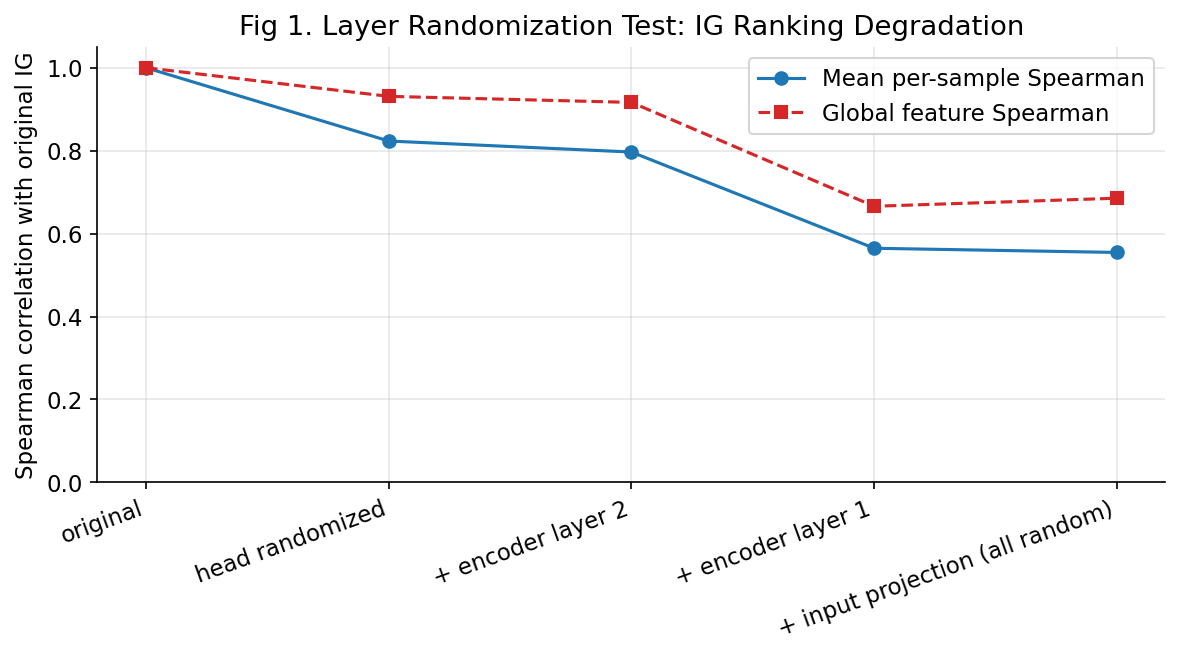

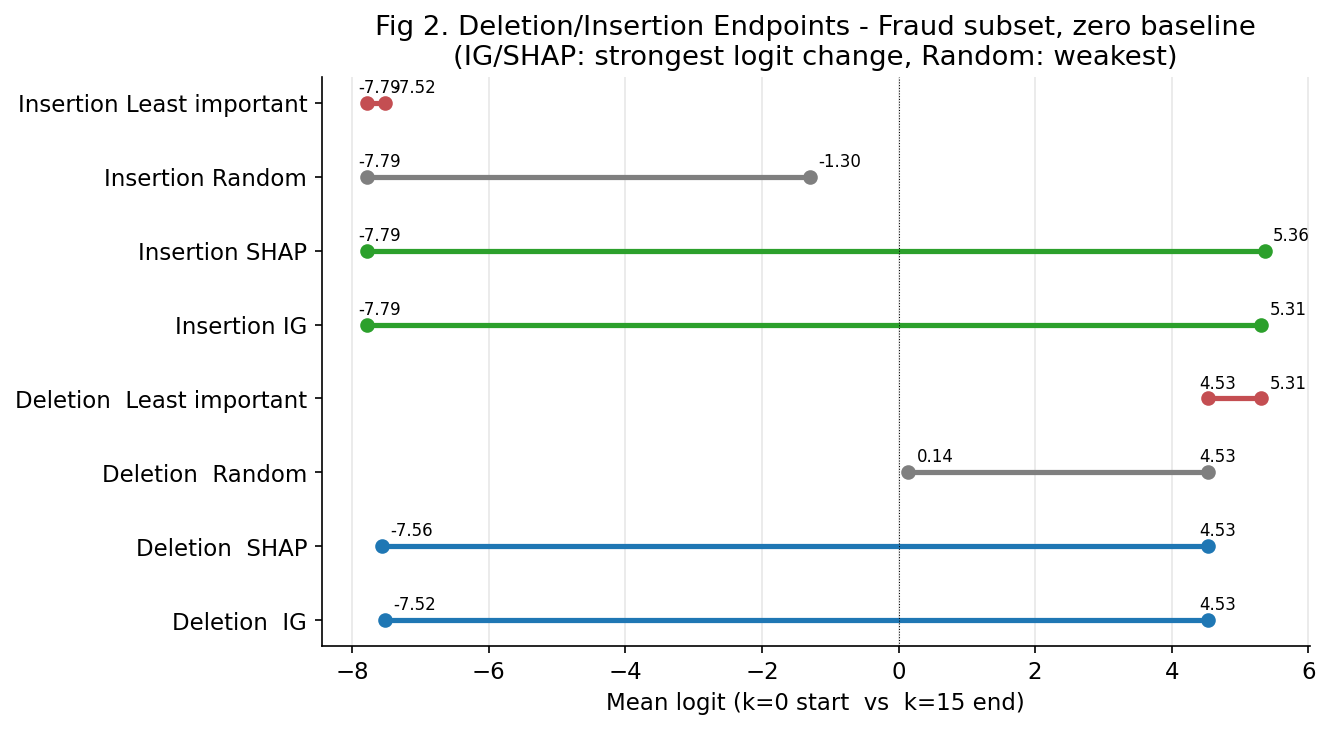

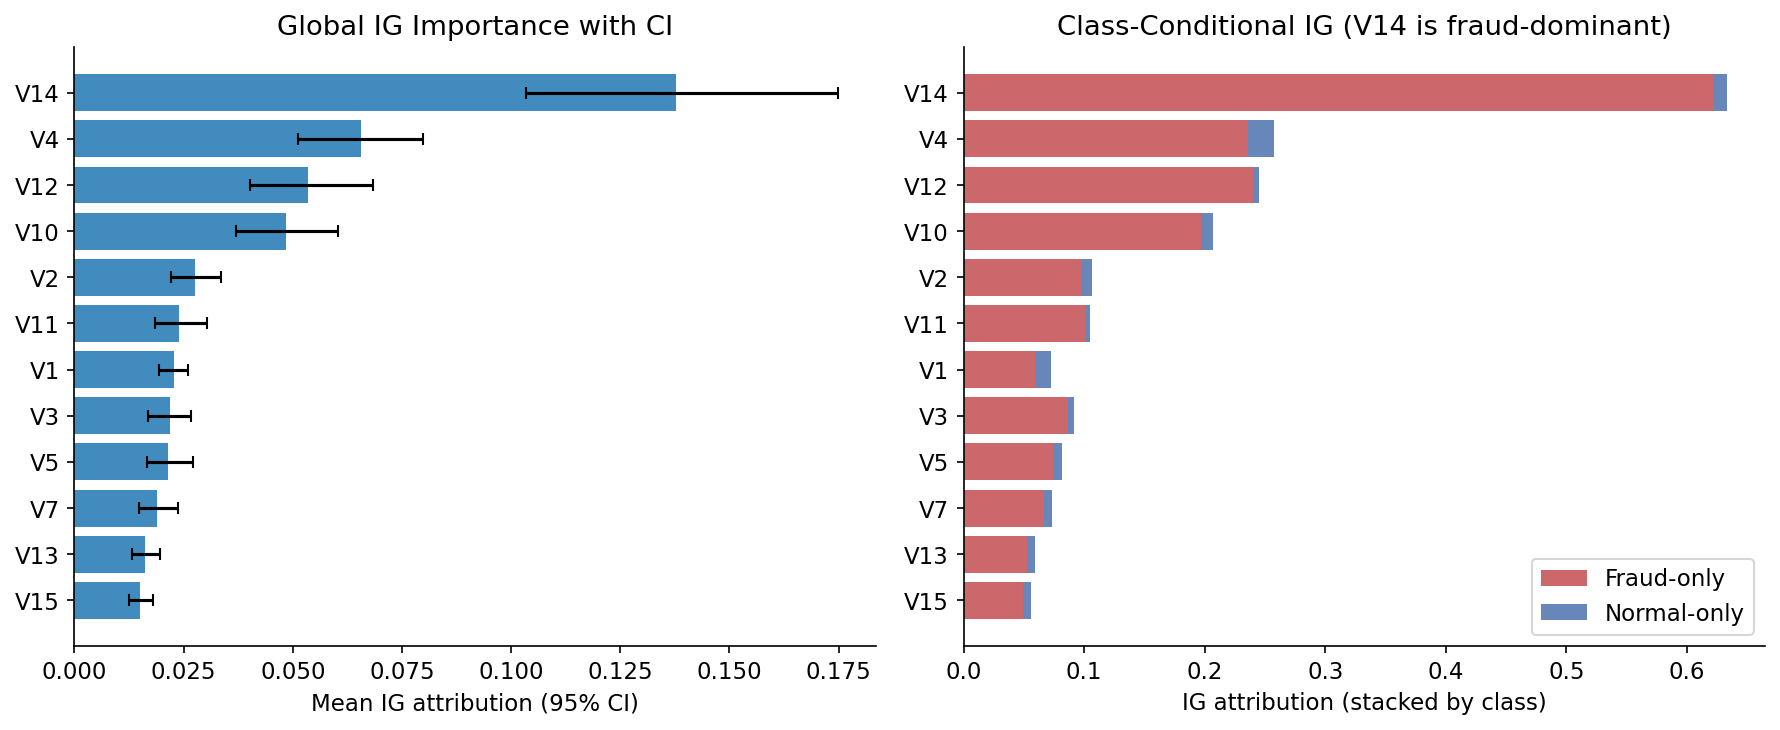

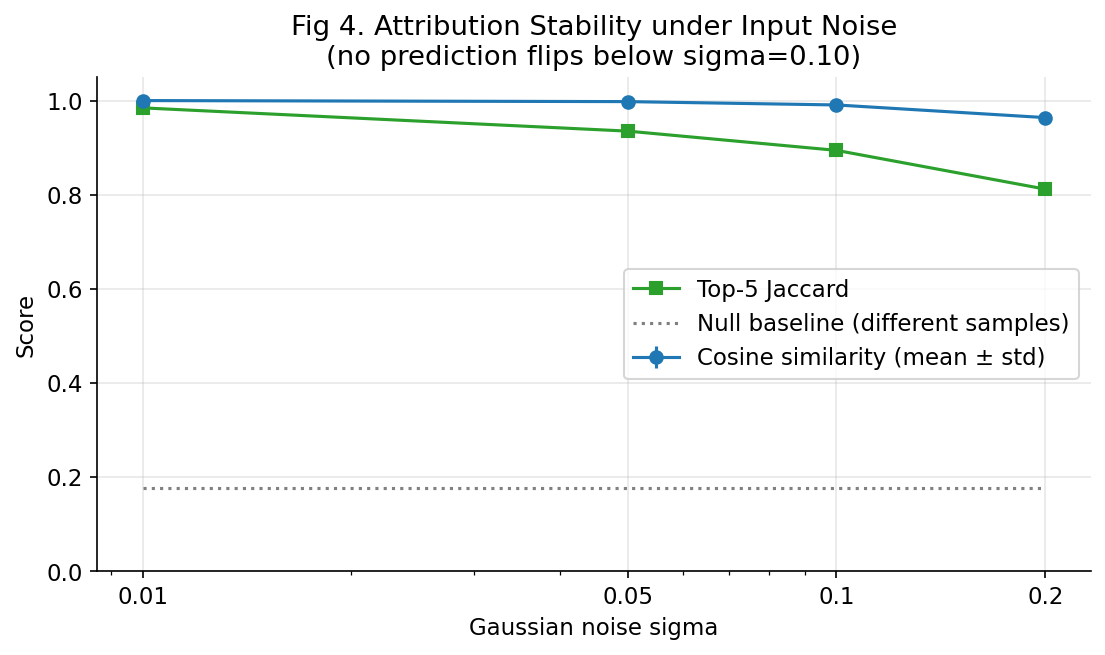

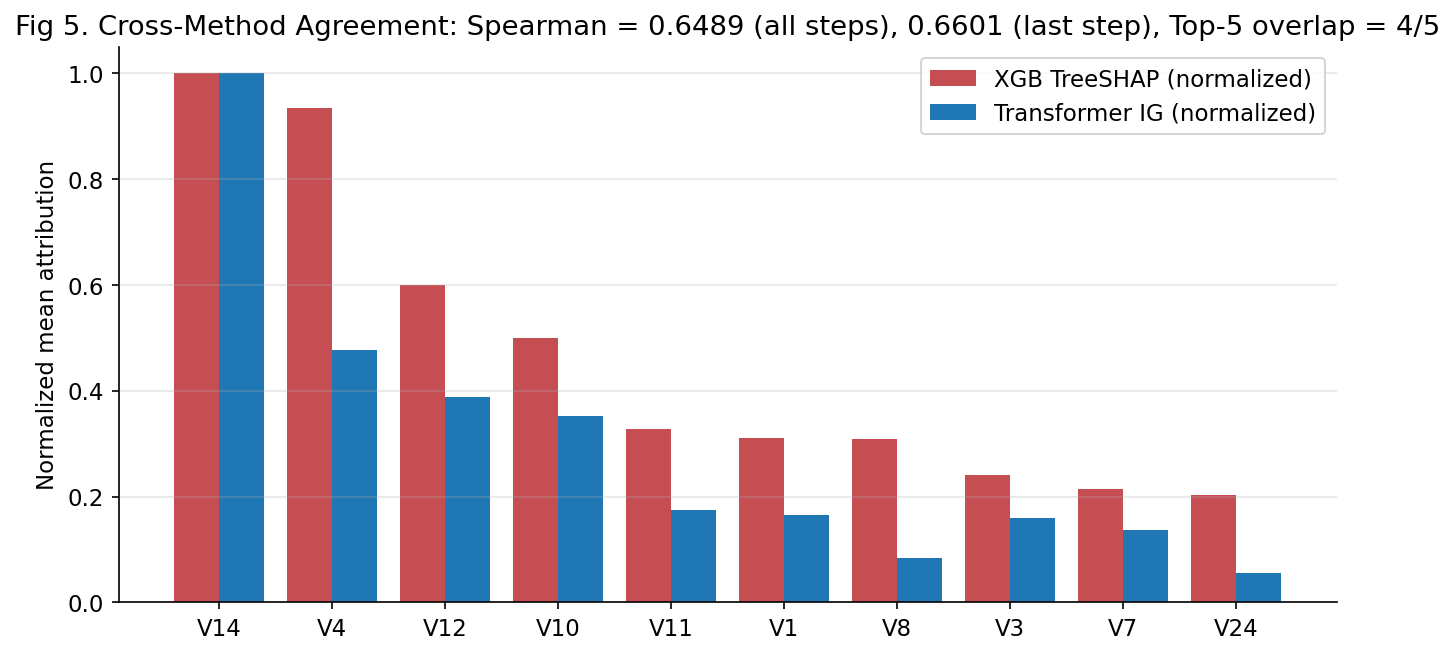

In [ ]:
# ============================================================
# XAI Evaluation Stage - Publication-Ready Plots
# Data embedded from the executed results of IniTialModel (2).ipynb
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 11, 'figure.dpi': 150,
                     'axes.spines.top': False, 'axes.spines.right': False})

# ------------------------------------------------------------
# Fig 1: Layer-wise randomization robustness (faithfulness of IG)
# ------------------------------------------------------------
stage_names = ['original', 'head randomized', '+ encoder layer 2',
               '+ encoder layer 1', '+ input projection (all random)']
sample_spr = [1.0000, 0.8233, 0.7967, 0.5647, 0.5546]
global_spr = [1.0000, 0.9310, 0.9164, 0.6659, 0.6854]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(stage_names))
ax.plot(x, sample_spr, 'o-', label='Mean per-sample Spearman', color='#1f77b4')
ax.plot(x, global_spr, 's--', label='Global feature Spearman', color='#d62728')
ax.set_xticks(x); ax.set_xticklabels(stage_names, rotation=20, ha='right')
ax.set_ylabel('Spearman correlation with original IG')
ax.set_title('Fig 1. Layer Randomization Test: IG Ranking Degradation')
ax.set_ylim(0, 1.05); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('fig1_layer_randomization.png', bbox_inches='tight'); plt.show()

# ------------------------------------------------------------
# Fig 2: Deletion/Insertion curves (Fraud subset, zero baseline)
# MeanLogitAUC endpoints (k0 -> k15) shown as bar comparison
# ------------------------------------------------------------
rows = [
    ('Deletion  IG',                 4.528, -7.521, '#1f77b4'),
    ('Deletion  SHAP',               4.528, -7.561, '#1f77b4'),
    ('Deletion  Random',             4.528,  0.145, '#7f7f7f'),
    ('Deletion  Least important',    4.528,  5.312, '#c44e52'),
    ('Insertion IG',                -7.790,  5.312, '#2ca02c'),
    ('Insertion SHAP',              -7.790,  5.361, '#2ca02c'),
    ('Insertion Random',            -7.790, -1.298, '#7f7f7f'),
    ('Insertion Least important',   -7.790, -7.521, '#c44e52'),
]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(rows))
for i, (lab, k0, k15, c) in enumerate(rows):
    ax.plot([k0, k15], [i, i], color=c, lw=2.5, marker='o', markersize=6)
    ax.annotate(f'{k0:.2f}', (k0, i), xytext=(-4, 5), textcoords='offset points', fontsize=8)
    ax.annotate(f'{k15:.2f}', (k15, i), xytext=(4, 5), textcoords='offset points', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels([r[0] for r in rows])
ax.set_xlabel('Mean logit (k=0 start  vs  k=15 end)')
ax.set_title('Fig 2. Deletion/Insertion Endpoints - Fraud subset, zero baseline\n(IG/SHAP: strongest logit change, Random: weakest)')
ax.axvline(0, color='k', lw=0.5, ls=':'); ax.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.savefig('fig2_deletion_insertion.png', bbox_inches='tight'); plt.show()

# ------------------------------------------------------------
# Fig 3: Global feature importance (IG) with 95% CI + fraud/normal split
# ------------------------------------------------------------
feat = ['V14','V4','V12','V10','V2','V11','V1','V3','V5','V7','V13','V15']
ig_mean = [0.1377,0.0657,0.0535,0.0484,0.0276,0.0240,0.0227,0.0219,0.0214,0.0189,0.0162,0.0151]
ci_low  = [0.1034,0.0512,0.0401,0.0370,0.0221,0.0185,0.0194,0.0168,0.0165,0.0147,0.0131,0.0124]
ci_high = [0.1749,0.0799,0.0684,0.0604,0.0336,0.0304,0.0261,0.0267,0.0271,0.0237,0.0195,0.0179]
fraud_only = [0.6214,0.2358,0.2398,0.1970,0.0975,0.1009,0.0595,0.0866,0.0738,0.0669,0.0527,0.0494]
normal_only= [0.0120,0.0214,0.0051,0.0098,0.0094,0.0041,0.0131,0.0051,0.0077,0.0065,0.0067,0.0062]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
y = np.arange(len(feat))[::-1]
err = [np.array(ig_mean) - np.array(ci_low), np.array(ci_high) - np.array(ig_mean)]
axes[0].barh(y, ig_mean, xerr=err, color='#1f77b4', alpha=0.85, capsize=3)
axes[0].set_yticks(y); axes[0].set_yticklabels(feat)
axes[0].set_xlabel('Mean IG attribution (95% CI)')
axes[0].set_title('Global IG Importance with CI')
axes[1].barh(y, fraud_only, color='#c44e52', alpha=0.85, label='Fraud-only')
axes[1].barh(y, normal_only, left=fraud_only, color='#4c72b0', alpha=0.85, label='Normal-only')
axes[1].set_yticks(y); axes[1].set_yticklabels(feat)
axes[1].set_xlabel('IG attribution (stacked by class)')
axes[1].set_title('Class-Conditional IG (V14 is fraud-dominant)')
axes[1].legend()
plt.tight_layout(); plt.savefig('fig3_feature_importance.png', bbox_inches='tight'); plt.show()

# ------------------------------------------------------------
# Fig 4: Noise-perturbation stability (cosine, Jaccard, flip rate)
# ------------------------------------------------------------
sigma = [0.01, 0.05, 0.10, 0.20]
cos_mean = [0.9999, 0.9977, 0.9906, 0.9637]
cos_std  = [0.0000, 0.0003, 0.0011, 0.0044]
jaccard  = [0.9844, 0.9350, 0.8941, 0.8117]
null_cos = [0.1764] * 4

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.errorbar(sigma, cos_mean, yerr=cos_std, fmt='o-', color='#1f77b4',
            label='Cosine similarity (mean ± std)')
ax.plot(sigma, jaccard, 's-', color='#2ca02c', label='Top-5 Jaccard')
ax.plot(sigma, null_cos, ':', color='gray', label='Null baseline (different samples)')
ax.set_xscale('log'); ax.set_xticks(sigma); ax.set_xticklabels(sigma)
ax.set_xlabel('Gaussian noise sigma'); ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Fig 4. Attribution Stability under Input Noise\n(no prediction flips below sigma=0.10)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('fig4_stability.png', bbox_inches='tight'); plt.show()

# ------------------------------------------------------------
# Fig 5: Cross-method agreement - XGB TreeSHAP vs Transformer IG
# Rank-aligned comparison (scales differ; normalized bars)
# ------------------------------------------------------------
feats5 = ['V14','V4','V12','V10','V11','V1','V8','V3','V7','V24']
xgb    = [2.3565,2.2012,1.4151,1.1767,0.7734,0.7337,0.7263,0.5673,0.5043,0.4778]
tig    = [0.1377,0.0657,0.0535,0.0484,0.0240,0.0227,0.0115,0.0219,0.0189,0.0076]

xgb_n = np.array(xgb) / max(xgb)
tig_n = np.array(tig) / max(tig)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(feats5))
ax.bar(x - 0.2, xgb_n, 0.4, label='XGB TreeSHAP (normalized)', color='#c44e52')
ax.bar(x + 0.2, tig_n, 0.4, label='Transformer IG (normalized)', color='#1f77b4')
ax.set_xticks(x); ax.set_xticklabels(feats5)
ax.set_ylabel('Normalized mean attribution')
ax.set_title(f"Fig 5. Cross-Method Agreement: Spearman = 0.6489 (all steps), 0.6601 (last step), Top-5 overlap = 4/5")
ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig('fig5_cross_method.png', bbox_inches='tight'); plt.show()


In [ ]:
# =====================================================================
# Final evaluation of ALL six models on the Test set (one cell).
# Paste at the END of the notebook and run once.
#
# Protocol (decided before looking at Test):
#   1. Every model is loaded from its saved checkpoint / fitted baseline.
#   2. Validation predictions are computed first and checked against the
#      Validation AP already reported in the notebook (integrity guard).
#   3. Each model's threshold = F1-optimal threshold on ITS OWN Validation
#      predictions (same rule as Stage 9.2). Nothing is tuned on Test.
#   4. Each model is evaluated on Test exactly once with that threshold.
#   5. Paired bootstrap 95% CIs on Test are reported.
#
# Needed in memory (cells 0-15, 17 and 21 of the notebook):
#   X_all, y_all, train_end, validation_end, test_end, device,
#   TemporalTransformer (Stage 5.1), log_reg and xgb (Stage 4.10).
# Do NOT run the training cells again (they would retrain and overwrite).
# =====================================================================
import os, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix)

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"
SEED = 42
N_BOOT = 1000
TOL = 6e-4  # tolerance for the Validation-AP integrity guard (reported to 4 decimals)

# ---------------------------------------------------------------- checks
needed = ["X_all", "y_all", "train_end", "validation_end", "test_end", "device"]
missing = [n for n in needed if n not in globals()]
if missing:
    raise RuntimeError(f"Missing variables {missing}. Run notebook cells 0-15 first.")
for n in ["TemporalTransformer", "log_reg"]:
    if n not in globals():
        raise RuntimeError(f"'{n}' not found. Run cell 21 (architecture) and cell 17 (baselines).")

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all, dtype=np.int64).reshape(-1)
assert X_all.shape == (284807, 30)
assert (train_end, validation_end, test_end) == (199364, 242085, 284807)


# ------------------------------------------------------- window helpers
def make_windows(start, end, w):
    """Windows [t-w+1 .. t] for every target t in [start, end); includes current row."""
    t = np.arange(start, end)
    idx = t[:, None] + np.arange(-w + 1, 1)[None, :]
    return X_all[idx], y_all[t]


@torch.no_grad()
def predict_neural(model, windows, bs=1024):
    model.eval()
    out = []
    for s in range(0, len(windows), bs):
        xb = torch.from_numpy(windows[s:s + bs]).to(device)
        out.append(torch.sigmoid(model(xb)).reshape(-1).cpu().numpy())
    return np.concatenate(out).astype(np.float64)


# ----------------------------------------- Hybrid model (explicit activation)
# The notebook redefines HybridLSTMTransformer between the window-5 and
# window-10 experiments, and the second definition drops activation="gelu"
# (PyTorch default = ReLU). The activation is not stored in a checkpoint, so it
# is made explicit here and verified through the Validation-AP guard below.
class HybridEval(nn.Module):
    def __init__(self, activation, input_dim=30, hidden=64, heads=4, layers=2, ff=128,
                 dropout=0.1, max_len=512):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden, num_layers=1, batch_first=True)
        self.positional_encoding = nn.Parameter(torch.zeros(1, max_len, hidden), requires_grad=False)
        layer = nn.TransformerEncoderLayer(d_model=hidden, nhead=heads, dim_feedforward=ff,
                                           dropout=dropout, activation=activation,
                                           batch_first=True, norm_first=True)
        self.transformer_encoder = nn.TransformerEncoder(layer, num_layers=layers,
                                                         enable_nested_tensor=False)
        self.output_norm = nn.LayerNorm(hidden)
        self.classifier = nn.Linear(hidden, 1)

    def forward(self, x):
        h, _ = self.lstm(x)
        h = h + self.positional_encoding[:, :h.size(1), :]
        h = self.transformer_encoder(h)
        return self.classifier(self.output_norm(h[:, -1, :])).squeeze(-1)


def load_state(path):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    for key in ["model_state_dict", "state_dict"]:
        if isinstance(ckpt, dict) and key in ckpt:
            return ckpt[key]
    return ckpt


def get_xgb():
    """Return the fitted XGBClassifier from Stage 4.10, even if the name `xgb` was overwritten."""
    from xgboost import XGBClassifier
    obj = globals().get("xgb")
    if hasattr(obj, "predict_proba"):
        return obj
    for k, v in list(globals().items()):
        if isinstance(v, XGBClassifier):
            print(f"[info] `xgb` is a {type(obj).__name__}; using fitted XGBClassifier found in `{k}`.")
            return v
    print(f"[info] `xgb` is a {type(obj).__name__} and no fitted XGBClassifier was found: "
          "re-fitting with the exact Stage 4.10 settings (verified by the Validation-AP guard).")
    y_tr = y_all[9:train_end]
    model = XGBClassifier(n_estimators=600, max_depth=5, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, min_child_weight=1, reg_lambda=1.0,
                          objective="binary:logistic", eval_metric="aucpr",
                          scale_pos_weight=float((y_tr == 0).sum()) / float((y_tr == 1).sum()),
                          tree_method="hist", random_state=42, n_jobs=-1)
    model.fit(X_all[9:train_end], y_tr, verbose=False)
    return model


# Registry: name -> (window, expected Validation AP from the notebook)
REGISTRY = {
    "Temporal Transformer (w=5)":       dict(w=5,  kind="tt",  file="temporal_transformer_best.pt",                  val_ap=0.8486),
    "Hybrid LSTM-Transformer (w=5)":    dict(w=5,  kind="hyb", file="hybrid_lstm_transformer_best.pt",               val_ap=0.8525, act=["gelu", "relu"]),
    "Temporal Transformer (w=10)":      dict(w=10, kind="tt",  file="temporal_transformer_window10_best.pt",         val_ap=0.8609),
    "Hybrid LSTM-Transformer (w=10)":   dict(w=10, kind="hyb", file="hybrid_lstm_transformer_window10_best.pt",      val_ap=0.8476, act=["relu", "gelu"]),
    "Logistic Regression":              dict(w=1,  kind="lr",  val_ap=0.8399),
    "XGBoost":                          dict(w=1,  kind="xgb", val_ap=0.8674),
}

val_windows = {w: make_windows(train_end, validation_end, w) for w in (5, 10)}
test_windows = {w: make_windows(validation_end, test_end, w) for w in (5, 10)}
y_val = y_all[train_end:validation_end]
y_test = y_all[validation_end:test_end]
assert len(y_val) == 42721 and len(y_test) == 42722
assert int(y_val.sum()) == 56 and int(y_test.sum()) == 52


def build_predictor(name, cfg):
    """Return (predict_fn, info). Chooses the Hybrid activation that reproduces Validation AP."""
    w, kind = cfg["w"], cfg["kind"]
    if kind == "lr":
        return (lambda split: log_reg.predict_proba(X_all[train_end:validation_end] if split == "val"
                                                    else X_all[validation_end:test_end])[:, 1]), "sklearn pipeline"
    if kind == "xgb":
        xgb_model = get_xgb()
        return (lambda split: xgb_model.predict_proba(X_all[train_end:validation_end] if split == "val"
                                                      else X_all[validation_end:test_end])[:, 1]), "xgboost"
    path = os.path.join(MODEL_DIR, cfg["file"])
    state = load_state(path)
    if kind == "tt":
        m = TemporalTransformer(input_dim=30, d_model=64, n_heads=4, num_layers=2,
                                dim_feedforward=128, dropout=0.1, max_len=50).to(device)
        m.load_state_dict(state, strict=True)
        return (lambda split: predict_neural(m, (val_windows if split == "val" else test_windows)[w][0])), "gelu"
    last_err = None
    for act in cfg["act"]:
        m = HybridEval(act).to(device)
        m.load_state_dict(state, strict=True)
        ap = average_precision_score(y_val, predict_neural(m, val_windows[w][0]))
        if abs(ap - cfg["val_ap"]) < TOL:
            return (lambda split, m=m: predict_neural(m, (val_windows if split == "val" else test_windows)[w][0])), act
        last_err = (act, ap)
    raise RuntimeError(f"{name}: no activation reproduces Validation AP {cfg['val_ap']} (last {last_err}).")


# ------------------------------------------ STAGE A: validation only + guard
print("STAGE A: Validation predictions, integrity guard and thresholds")
print("-" * 72)
predictors, val_probs, thresholds, info = {}, {}, {}, {}
for name, cfg in REGISTRY.items():
    fn, note = build_predictor(name, cfg)
    p = fn("val")
    ap = average_precision_score(y_val, p)
    assert abs(ap - cfg["val_ap"]) < TOL, f"{name}: Validation AP {ap:.4f} != notebook {cfg['val_ap']}"
    prec, rec, thr = precision_recall_curve(y_val, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    thresholds[name] = float(thr[int(np.argmax(f1))])
    predictors[name], val_probs[name], info[name] = fn, p, note
    print(f"{name:34s} val AP {ap:.4f} (expected {cfg['val_ap']:.4f}) | threshold {thresholds[name]:.6f} | {note}")
assert abs(thresholds["Temporal Transformer (w=10)"] - 0.998047) < 2e-4, "Threshold differs from Stage 9.2"
print("Integrity guard passed. Test set has not been touched yet.\n")


def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Threshold": thr,
            "AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "MCC": matthews_corrcoef(y, pred),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}


val_df = pd.DataFrame([{"Model": n, **metrics_at(y_val, val_probs[n], thresholds[n])} for n in REGISTRY])

# ----------------------------------------------------- STAGE B: Test, once
print("STAGE B: Test evaluation (each model once, validation-selected threshold)")
print("-" * 72)
test_probs = {n: predictors[n]("test") for n in REGISTRY}
test_df = pd.DataFrame([{"Model": n, **metrics_at(y_test, test_probs[n], thresholds[n])} for n in REGISTRY])

ref = test_df[test_df.Model == "Temporal Transformer (w=10)"].iloc[0]
assert abs(ref.AP - 0.755129) < 1e-4 and (ref.TN, ref.FP, ref.FN, ref.TP) == (42668, 2, 15, 37), \
    "Test result for Temporal Transformer (w=10) differs from Stage 10.1"
print("Reproduced Stage 10.1 result for Temporal Transformer (w=10): PASS\n")

# ---------------------------------------------- paired bootstrap on Test
rng = np.random.default_rng(SEED)
names = list(REGISTRY)
REF = "Temporal Transformer (w=10)"
boot = {n: {"AP": [], "F1": [], "Recall": [], "Precision": [], "MCC": []} for n in names}
d_ap = {n: [] for n in names}
n_test = len(y_test)
for _ in range(N_BOOT):
    idx = rng.integers(0, n_test, n_test)
    yb = y_test[idx]
    if yb.sum() == 0:
        continue
    ap_ref = None
    for n in names:
        pb = test_probs[n][idx]
        pred = (pb >= thresholds[n]).astype(int)
        ap = average_precision_score(yb, pb)
        boot[n]["AP"].append(ap)
        boot[n]["F1"].append(f1_score(yb, pred, zero_division=0))
        boot[n]["Recall"].append(recall_score(yb, pred, zero_division=0))
        boot[n]["Precision"].append(precision_score(yb, pred, zero_division=0))
        boot[n]["MCC"].append(matthews_corrcoef(yb, pred))
        if n == REF:
            ap_ref = ap
        d_ap[n].append(ap)
    for n in names:  # difference vs reference, same resample
        d_ap[n][-1] = d_ap[n][-1] - ap_ref


def ci(v):
    return np.percentile(v, [2.5, 97.5])


ci_rows = []
for n in names:
    row = {"Model": n}
    for m in ["AP", "Precision", "Recall", "F1", "MCC"]:
        lo, hi = ci(boot[n][m])
        row[f"{m}_CI95"] = f"[{lo:.3f}, {hi:.3f}]"
    lo, hi = ci(d_ap[n])
    row["dAP_vs_TT_w10_CI95"] = "reference" if n == REF else f"[{lo:+.3f}, {hi:+.3f}]"
    row["dAP_includes_0"] = "-" if n == REF else bool(lo <= 0 <= hi)
    ci_rows.append(row)
ci_df = pd.DataFrame(ci_rows)

# ------------------------------------------------------------- outputs
def fmt(df, cols):
    out = df.copy()
    for c in cols:
        out[c] = out[c].map(lambda v: f"{v:.4f}")
    return out


def to_md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)


num_cols = ["AP", "ROC_AUC", "Precision", "Recall", "F1", "MCC"]
test_show = fmt(test_df, num_cols + ["Threshold"])
val_show = fmt(val_df, num_cols + ["Threshold"])

pd.set_option("display.width", 220, "display.max_columns", 30)
print("=" * 72, "\nTABLE 1. TEST results (threshold chosen on Validation for each model)\n", "=" * 72)
print(test_show.to_string(index=False))
print("\n", "=" * 72, "\nTABLE 2. VALIDATION results at the same thresholds\n", "=" * 72)
print(val_show.to_string(index=False))
print("\n", "=" * 72, f"\nTABLE 3. Test 95% bootstrap CIs ({N_BOOT} resamples, paired across models)\n", "=" * 72)
print(ci_df.to_string(index=False))

best_val = val_df.sort_values("AP", ascending=False).iloc[0]
best_test = test_df.sort_values("AP", ascending=False).iloc[0]
print("\nBest model by Validation AP (selection rule):", best_val.Model, f"({best_val.AP:.4f})")
print("Best model by Test AP (reported, not used for selection):", best_test.Model, f"({best_test.AP:.4f})")

os.makedirs(MODEL_DIR, exist_ok=True)
test_df.to_csv(f"{MODEL_DIR}/final_test_all_models.csv", index=False)
val_df.to_csv(f"{MODEL_DIR}/final_validation_all_models.csv", index=False)
ci_df.to_csv(f"{MODEL_DIR}/final_test_bootstrap_ci.csv", index=False)
pd.DataFrame({"y_true": y_test, **{n: test_probs[n] for n in names}}).to_csv(
    f"{MODEL_DIR}/final_test_probabilities_all_models.csv", index=False)
with open(f"{MODEL_DIR}/final_all_models_protocol.json", "w", encoding="utf-8") as f:
    json.dump({"thresholds_from_validation": thresholds, "hybrid_activation_or_note": info,
               "bootstrap_resamples": N_BOOT, "seed": SEED,
               "selection_rule": "Validation Average Precision",
               "test_used_for_selection": False}, f, indent=2)

md = ("## Test results (all models)\n\n" + to_md(test_show[["Model", "Threshold"] + num_cols + ["TN", "FP", "FN", "TP"]])
      + "\n\n## Validation results\n\n" + to_md(val_show[["Model", "Threshold"] + num_cols + ["TN", "FP", "FN", "TP"]])
      + "\n\n## Test 95% bootstrap CIs\n\n" + to_md(ci_df) + "\n")
with open(f"{MODEL_DIR}/final_tables.md", "w", encoding="utf-8") as f:
    f.write(md)
print("\nSaved CSV/JSON/Markdown tables to:", MODEL_DIR)
print("Copy-paste Markdown version is in final_tables.md")

STAGE A: Validation predictions, integrity guard and thresholds
------------------------------------------------------------------------
Temporal Transformer (w=5)         val AP 0.8486 (expected 0.8486) | threshold 0.999496 | gelu
Hybrid LSTM-Transformer (w=5)      val AP 0.8525 (expected 0.8525) | threshold 0.998528 | gelu
Temporal Transformer (w=10)        val AP 0.8609 (expected 0.8609) | threshold 0.998047 | gelu
Hybrid LSTM-Transformer (w=10)     val AP 0.8476 (expected 0.8476) | threshold 0.998076 | relu
Logistic Regression                val AP 0.8399 (expected 0.8399) | threshold 0.999995 | sklearn pipeline
[info] `xgb` is a list and no fitted XGBClassifier was found: re-fitting with the exact Stage 4.10 settings (verified by the Validation-AP guard).
XGBoost                            val AP 0.8674 (expected 0.8674) | threshold 0.757056 | xgboost
Integrity guard passed. Test set has not been touched yet.

STAGE B: Test evaluation (each model once, validation-selected threshol

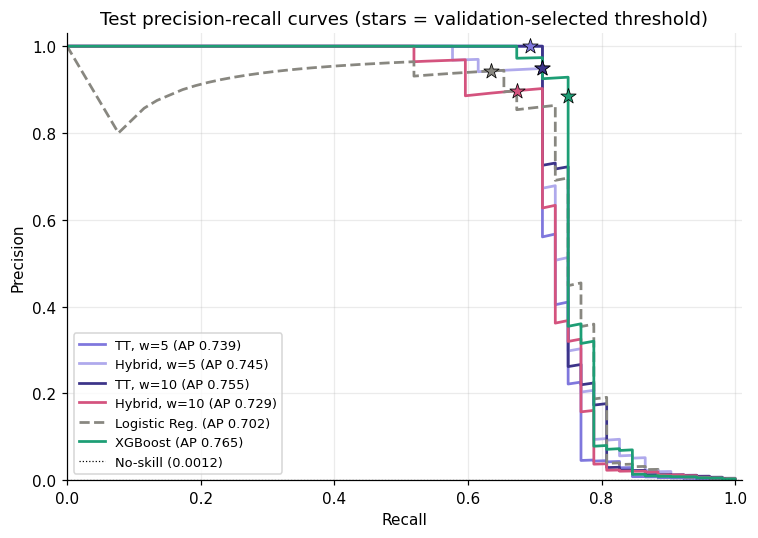

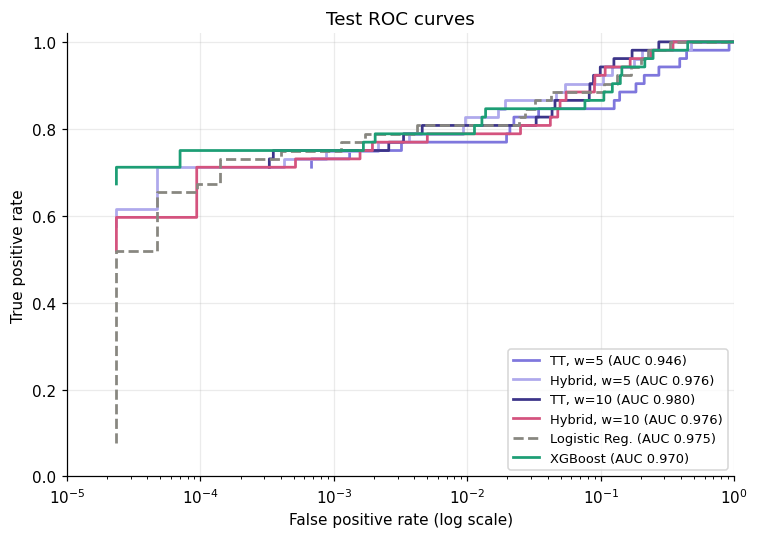

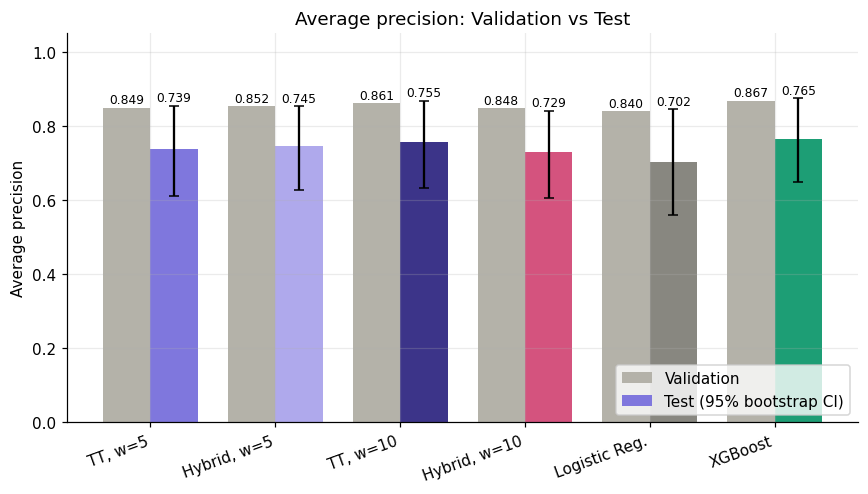

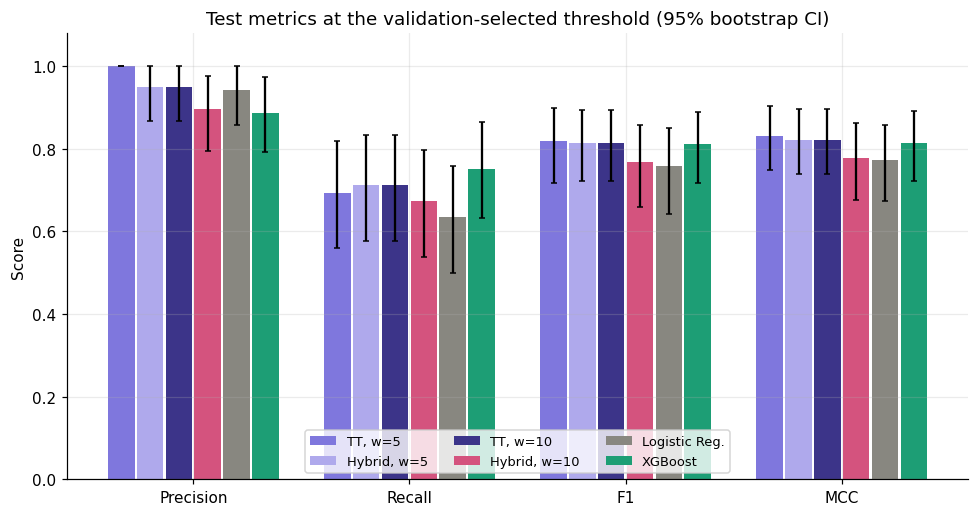

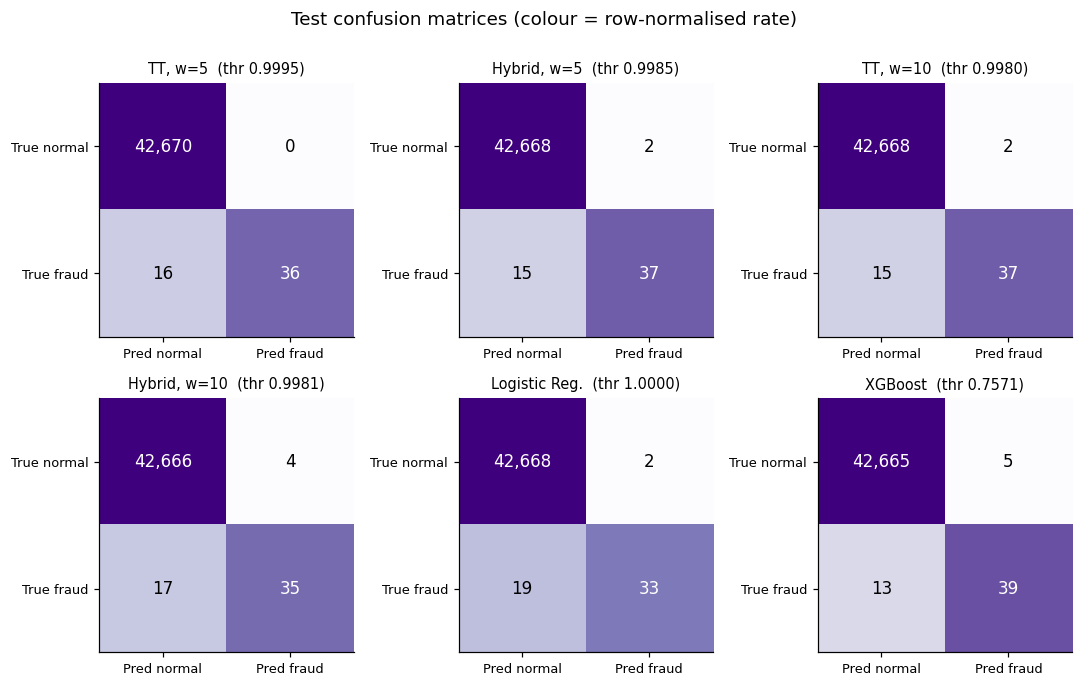

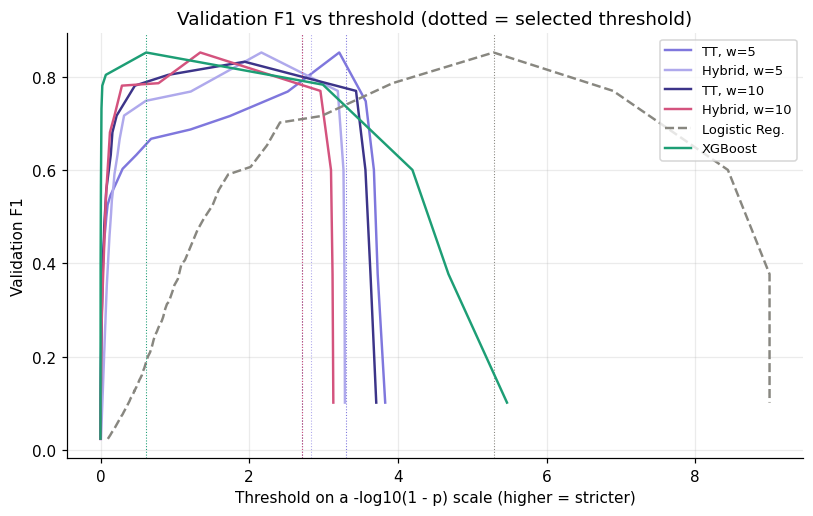

Figures saved in: /content/drive/MyDrive/fraud_detection_models/figures


In [ ]:
# =====================================================================
# Figures for the final all-model evaluation (Validation + Test).
# Run AFTER final_all_models_test_evaluation.py. It reads the CSV files that
# script saved to Drive, so it also works after a runtime restart.
# Figures are saved as PNG (300 dpi) and PDF in MODEL_DIR/figures.
# =====================================================================
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

MODEL_DIR = "/content/drive/MyDrive/fraud_detection_models"
FIG_DIR = os.path.join(MODEL_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

probs = pd.read_csv(os.path.join(MODEL_DIR, "final_test_probabilities_all_models.csv"))
test_df = pd.read_csv(os.path.join(MODEL_DIR, "final_test_all_models.csv"))
val_df = pd.read_csv(os.path.join(MODEL_DIR, "final_validation_all_models.csv"))
ci_df = pd.read_csv(os.path.join(MODEL_DIR, "final_test_bootstrap_ci.csv"))

y = probs["y_true"].to_numpy().astype(int)
models = [m for m in test_df["Model"]]
assert all(m in probs.columns for m in models)
prevalence = y.mean()

SHORT = {
    "Temporal Transformer (w=5)": "TT, w=5",
    "Hybrid LSTM-Transformer (w=5)": "Hybrid, w=5",
    "Temporal Transformer (w=10)": "TT, w=10",
    "Hybrid LSTM-Transformer (w=10)": "Hybrid, w=10",
    "Logistic Regression": "Logistic Reg.",
    "XGBoost": "XGBoost",
}
COLORS = {
    "Temporal Transformer (w=5)": "#7F77DD",
    "Hybrid LSTM-Transformer (w=5)": "#AFA9EC",
    "Temporal Transformer (w=10)": "#3C3489",
    "Hybrid LSTM-Transformer (w=10)": "#D4537E",
    "Logistic Regression": "#888780",
    "XGBoost": "#1D9E75",
}
STYLES = {"Logistic Regression": "--", "XGBoost": "-"}

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(FIG_DIR, f"{name}.pdf"), bbox_inches="tight")
    plt.show()


def parse_ci(text):
    lo, hi = json.loads(text)
    return float(lo), float(hi)


row = lambda df, m: df[df["Model"] == m].iloc[0]

# ------------------------------------------------ Fig 1: Precision-Recall
fig, ax = plt.subplots(figsize=(7, 5))
for m in models:
    p, r, _ = precision_recall_curve(y, probs[m])
    ap = row(test_df, m)["AP"]
    ax.plot(r, p, STYLES.get(m, "-"), color=COLORS[m], lw=1.8, label=f"{SHORT[m]} (AP {ap:.3f})")
    t = row(test_df, m)
    ax.scatter([t["Recall"]], [t["Precision"]], marker="*", s=110, color=COLORS[m],
               edgecolor="black", linewidth=0.5, zorder=5)
ax.axhline(prevalence, color="black", lw=0.8, ls=":", label=f"No-skill ({prevalence:.4f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.03)
ax.set_title("Test precision-recall curves (stars = validation-selected threshold)")
ax.legend(loc="lower left", fontsize=8.5)
save(fig, "fig1_pr_curves_test")

# ------------------------------------------------------ Fig 2: ROC curves
fig, ax = plt.subplots(figsize=(7, 5))
for m in models:
    fpr, tpr, _ = roc_curve(y, probs[m])
    keep = fpr > 0
    ax.plot(fpr[keep], tpr[keep], STYLES.get(m, "-"), color=COLORS[m], lw=1.8,
            label=f"{SHORT[m]} (AUC {row(test_df, m)['ROC_AUC']:.3f})")
ax.set_xscale("log")
ax.set_xlim(1e-5, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False positive rate (log scale)")
ax.set_ylabel("True positive rate")
ax.set_title("Test ROC curves")
ax.legend(loc="lower right", fontsize=8.5)
save(fig, "fig2_roc_curves_test")

# ----------------------------- Fig 3: AP, Validation vs Test with Test CIs
fig, ax = plt.subplots(figsize=(8, 4.6))
x = np.arange(len(models))
w = 0.38
val_ap = [row(val_df, m)["AP"] for m in models]
test_ap = [row(test_df, m)["AP"] for m in models]
cis = [parse_ci(row(ci_df, m)["AP_CI95"]) for m in models]
err = np.array([[max(a - lo, 0), max(hi - a, 0)] for a, (lo, hi) in zip(test_ap, cis)]).T
ax.bar(x - w / 2, val_ap, w, color="#B4B2A9", label="Validation")
ax.bar(x + w / 2, test_ap, w, color=[COLORS[m] for m in models], yerr=err, capsize=3,
       label="Test (95% bootstrap CI)")
for i, (v, t) in enumerate(zip(val_ap, test_ap)):
    ax.text(i - w / 2, v + 0.012, f"{v:.3f}", ha="center", fontsize=8)
    ax.text(i + w / 2, t + 0.012 + (err[1][i]), f"{t:.3f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([SHORT[m] for m in models], rotation=20, ha="right")
ax.set_ylabel("Average precision")
ax.set_ylim(0, 1.05)
ax.set_title("Average precision: Validation vs Test")
ax.legend(loc="lower right")
save(fig, "fig3_ap_validation_vs_test")

# ---------------------- Fig 4: threshold metrics on Test with bootstrap CIs
metrics = ["Precision", "Recall", "F1", "MCC"]
fig, ax = plt.subplots(figsize=(9, 4.8))
bw = 0.8 / len(models)
for j, m in enumerate(models):
    vals = [row(test_df, m)[k] for k in metrics]
    errs = []
    for k, v in zip(metrics, vals):
        lo, hi = parse_ci(row(ci_df, m)[f"{k}_CI95"])
        errs.append([max(v - lo, 0), max(hi - v, 0)])
    errs = np.array(errs).T
    ax.bar(np.arange(len(metrics)) + (j - (len(models) - 1) / 2) * bw, vals, bw * 0.92,
           yerr=errs, capsize=2, color=COLORS[m], label=SHORT[m])
ax.set_xticks(np.arange(len(metrics)))
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.set_title("Test metrics at the validation-selected threshold (95% bootstrap CI)")
ax.legend(ncol=3, fontsize=8.5, loc="lower center")
save(fig, "fig4_threshold_metrics_test")

# ---------------------------------------------- Fig 5: confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(10, 6.2))
for ax, m in zip(axes.ravel(), models):
    t = row(test_df, m)
    cm = np.array([[t["TN"], t["FP"]], [t["FN"], t["TP"]]], dtype=int)
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap="Purples", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=11,
                    color="white" if norm[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred normal", "Pred fraud"], fontsize=8.5)
    ax.set_yticklabels(["True normal", "True fraud"], fontsize=8.5)
    ax.set_title(f"{SHORT[m]}  (thr {t['Threshold']:.4f})", fontsize=9.5)
    ax.grid(False)
fig.suptitle("Test confusion matrices (colour = row-normalised rate)", y=1.0)
save(fig, "fig5_confusion_matrices_test")

# --------------- Fig 6 (optional, needs variables still in memory): F1 vs threshold
if "val_probs" in globals() and "thresholds" in globals() and "y_val" in globals():
    from sklearn.metrics import f1_score
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    for m in models:
        p = np.asarray(val_probs[m])
        grid = np.unique(np.quantile(p, np.linspace(0.90, 0.99995, 400)))
        f1s = [f1_score(y_val, (p >= g).astype(int), zero_division=0) for g in grid]
        ax.plot(-np.log10(1 - np.clip(grid, 0, 1 - 1e-9)), f1s, STYLES.get(m, "-"),
                color=COLORS[m], lw=1.6, label=SHORT[m])
        ax.axvline(-np.log10(1 - min(thresholds[m], 1 - 1e-9)), color=COLORS[m], lw=0.7, ls=":")
    ax.set_xlabel("Threshold on a -log10(1 - p) scale (higher = stricter)")
    ax.set_ylabel("Validation F1")
    ax.set_title("Validation F1 vs threshold (dotted = selected threshold)")
    ax.legend(fontsize=8.5)
    save(fig, "fig6_validation_f1_vs_threshold")
else:
    print("Fig 6 skipped (validation probabilities are not in memory; this is optional).")

print("Figures saved in:", FIG_DIR)